# VELOCE III: Reconstructing Radial Velocity Curves of Classical Cepheids

Giordano Viviani and Richard I. Anderson (2025)

email: giordano.viviani@proton.me

This notebook reproduce step-by-step the analysis conducted to create the framework published in *Viviani et Anderson 2025* (doi: 10.48550/arXiv.2511.10534)

In [1]:
%matplotlib inline

import itertools
import logging
import math
import os
import pickle as pkl
import warnings
from collections.abc import Callable
from multiprocessing import Pool
from pathlib import Path

import emcee
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy as sp
from astropy.io import votable
from joblib import Parallel, delayed
from matplotlib import rc
from matplotlib.axes import Axes
from matplotlib.collections import LineCollection
from matplotlib.figure import Figure
from phased_pca_model import PhaseShiftLCPC
from scipy.stats import gaussian_kde
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from tqdm.notebook import tqdm

# Import the veloce framework library
import velocefw as vf

rc("text", usetex=True)
rc("text.latex", preamble=r"\usepackage{amsmath}")
rc("font", family="serif")

logger = logging.getLogger(__name__)
logger.setLevel(logging.DEBUG)

# Okabe and Ito colorscheme
color_safe = {
    "black": "#000000",
    "light_green": "#009E73",
    "blue": "#0072B2",
    "light_blue": "#56B4E9",
    "yellow": "#F0E442",
    "orange": "#E69F00",
    "dark_orange": "#D55E00",
    "pink": "#CC79A7",
}

# Label and font sizes for plots
label_size = 11

# Set random seed for reproducibility
rng = np.random.default_rng(42)

## Prepare Data
### VELOCE DR1 data
Accessing the VELOCE DR1 (Anderson, Viviani et al, 2024) data.

The code makes use of the environment variable DATASETS, and it assumes the VELOCE DR1 fits files are in a sub-folder.
Please change the path to where you saved the VELOCE DR1 fits files. 

In [2]:
datasets_dir = Path(os.environ.get("DATASETS", "")).expanduser()
veloce_data_dir = datasets_dir / "veloce_dr1_zenodo"

Reading all the headers into a pandas.DataFrame

In [3]:
# Entries that are not needed for the analysis
entries_to_remove = ["SIMPLE", "BITPIX", "NAXIS", "EXTEND"]

header_list = []
for f in veloce_data_dir.iterdir():
    if f.suffix.lower() == ".fits":
        header = vf.get_header(f)
        for entry in entries_to_remove:
            header.pop(entry, None)
        header_list.append(header)

veloce_headers = pd.DataFrame(header_list).sort_values("NAME").reset_index(drop=True)

We are interested only in Classical Cepheids that have a modeled radial-velocity curve.
We select these using the available `BOOL_FIT_AVAILABLE` key in the header.

In [4]:
veloce_headers = veloce_headers[veloce_headers["BOOL_FIT_AVAILABLE"]]
veloce_headers = veloce_headers.reset_index(drop=True)

#### Observations
Retrieve all observations for the targets with an available pulsation model.
We are interested into retrieving also the `MASK` column. The boolean column informs us if the datapoint was used to determine the pulsational model in VELOCE-I.

In [5]:
read_columns = ["BJD", "RV", "RV_ERR", "MASK"]
veloce_data = pd.DataFrame()
for name in veloce_headers["NAME"]:
    file = veloce_data_dir / f"{name.replace(' ', '_')}.fits"
    temp = vf.get_table(file, 1, columns=read_columns)
    temp["NAME"] = name
    veloce_data = pd.concat([veloce_data, temp], ignore_index=True)

#### Models
After the observations, we get the published coefficients for the fitted models.

We load the coefficients array from VELOCE's fits files and then slice it into its components:
- `VGAMMA`: constant value added to the model
- `FS_COEFFS`: Fourier series coefficients
- `POLY_COEFFS`: possible polynomial coefficients used in the fit. None if no polynomial was used

In [6]:
read_columns = ["COEFF", "COEFF_ERR"]
veloce_fit = pd.DataFrame()
for _, header in veloce_headers.iterrows():
    name = header["NAME"]
    nharm = int(header["N_TERMS_FS"])
    # Slices for the coefficients in the order: constant, fs, poly
    constant_idx = 0
    fs_idx = slice(1, 2 * nharm + 1)
    poly_idx = slice(2 * nharm + 1, None)
    # Read the coefficients from the FITS file
    file = veloce_data_dir / f"{name.replace(' ', '_')}.fits"
    coeff_table = vf.get_table(file, 2, columns=read_columns)
    temp_coeff = coeff_table["COEFF"].to_numpy()
    temp_coeff_err = coeff_table["COEFF_ERR"].to_numpy()

    # Extract the coefficients for each component
    vgamma = temp_coeff[constant_idx]
    fs_coeffs = temp_coeff[fs_idx]
    poly_coeffs = temp_coeff[poly_idx] if header["BOOL_POLYNOMIAL"] else None

    vgamma_err = temp_coeff_err[constant_idx]
    fs_coeffs_err = temp_coeff_err[fs_idx]
    poly_coeffs_err = temp_coeff_err[poly_idx] if header["BOOL_POLYNOMIAL"] else None

    # Store the coefficients in a DataFrame
    temp = pd.DataFrame(
        {
            "NAME": name,
            "VGAMMA": [vgamma],
            "FS_COEFFS": [fs_coeffs],
            "POLY_COEFFS": [poly_coeffs],
            "VGAMMA_ERR": [vgamma_err],
            "FS_COEFFS_ERR": [fs_coeffs_err],
            "POLY_COEFFS_ERR": [poly_coeffs_err],
        },
    )
    veloce_fit = pd.concat([veloce_fit, temp], ignore_index=True)

### Gaia DR3 data 
We load the data in Gaia DR3's `vari_cepheids` table.

We are interested into retrieving **Gaia's photometric epochs** to determinate the **phase difference with VELOCE's epoch**.

This is done, since, later in the analysis, we want to test the performance of our framework when the RV curve epoch is unknown and it is only estimated via photometry.

In [7]:
gaiadr3_data_dir = datasets_dir / "gaia_dr3"

votable_file_gaiadr3 = gaiadr3_data_dir / "VOTableFiles" / "gaiadr3.vari_cepheids.vot"
df_gaiadr3 = (
    votable.parse(votable_file_gaiadr3).get_first_table().to_table().to_pandas()
)

From the entire table we select only the targets within VELOCE (remember *alf UMi* is not present in Gaia DR3)

In [8]:
df_gaiadr3_selection = df_gaiadr3[
    df_gaiadr3["source_id"].isin(veloce_headers["GAIA_DR3_SOURCE_ID"].astype(int))
]
# Delete the original DataFrame to free up memory
del df_gaiadr3

Check which targets are missing and then calculate the difference in epoch and period between the photometric Gaia data and VELOCE

The difference in phase is measured at GAIA's epoch and is measured using VELOCE's ($\Delta\phi_V$) and Gaia's ($\Delta\phi_G$) period as follows:
- $\Delta\phi_V = (\frac{E_G - E_V}{P_V} + 0.5) \% 1 - 0.5$
- $\Delta\phi_G = (\frac{E_G - E_V}{P_G} + 0.5) \% 1 - 0.5$

> **NB**: The second part of the equations is there to map the results in the $[-0.5, 0.5)$ interval.


In [9]:
epoch_offset_gaiadr3 = 2455197.5  # = J2010.0
epoch_offset_veloce = 2400000.0

gaia_veloce_delta_epoch_list = []
for _, header in veloce_headers.iterrows():
    source_id = int(header["GAIA_DR3_SOURCE_ID"])
    if source_id not in df_gaiadr3_selection["source_id"].to_numpy():
        msg = f"{header['NAME']} (id: {source_id}) is missing in vari_cepheids."
        logger.info(msg)
        print(msg)  # noqa: T201
        continue

    # Gaia Data
    gaia_data = df_gaiadr3_selection[df_gaiadr3_selection["source_id"] == source_id]
    gaia_period = gaia_data["pf"].to_numpy()[0]
    gaia_period_err = gaia_data["pf_error"].to_numpy()[0]
    if np.isnan(gaia_period):
        gaia_period = gaia_data["p1_o"].to_numpy()[0]
        gaia_period_err = gaia_data["p1_o_error"].to_numpy()[0]
    gaia_epoch_g = gaia_data["epoch_g"].to_numpy()[0] + epoch_offset_gaiadr3
    gaia_epoch_bp = gaia_data["epoch_bp"].to_numpy()[0] + epoch_offset_gaiadr3
    gaia_epoch_rp = gaia_data["epoch_rp"].to_numpy()[0] + epoch_offset_gaiadr3
    gaia_epoch_rv = gaia_data["epoch_rv"].to_numpy()[0] + epoch_offset_gaiadr3

    # VELOCE Data
    veloce_epoch = header["E"] + epoch_offset_veloce
    veloce_period = header["P"]
    veloce_period_err = header["P_ERR"]

    if np.isnan(gaia_epoch_g):
        msg = f"{header['NAME']} (id: {source_id}) has NaN epoch in vari_cepheids."
        logger.info(msg)
        print(msg)  # noqa: T201
        continue

    if np.isnan(gaia_period):
        msg = f"{header['NAME']} (id: {source_id}) has NaN period in vari_cepheids."
        logger.info(msg)
        print(msg)  # noqa: T201
        continue

    delta_phase_g_v = (gaia_epoch_g - veloce_epoch) / veloce_period % 1
    delta_phase_g_g = (gaia_epoch_g - veloce_epoch) / gaia_period % 1
    delta_phase_bp_v = (gaia_epoch_bp - veloce_epoch) / veloce_period % 1
    delta_phase_bp_g = (gaia_epoch_bp - veloce_epoch) / gaia_period % 1
    delta_phase_rp_v = (gaia_epoch_rp - veloce_epoch) / veloce_period % 1
    delta_phase_rp_g = (gaia_epoch_rp - veloce_epoch) / gaia_period % 1
    delta_phase_rv_v = (gaia_epoch_rv - veloce_epoch) / veloce_period % 1
    delta_phase_rv_g = (gaia_epoch_rv - veloce_epoch) / gaia_period % 1

    # Cycle separation and time drift calculations
    n_cycle_separation_g = np.abs(gaia_epoch_g - veloce_epoch) / veloce_period
    n_cycle_separation_bp = np.abs(gaia_epoch_bp - veloce_epoch) / veloce_period
    n_cycle_separation_rp = np.abs(gaia_epoch_rp - veloce_epoch) / veloce_period
    n_cycle_separation_rv = np.abs(gaia_epoch_rv - veloce_epoch) / veloce_period

    delta_period = gaia_period - veloce_period
    _term_error_prop = gaia_period_err**2 + veloce_period_err**2
    delta_time_drift_g = n_cycle_separation_g * delta_period
    delta_time_drift_g_err = np.sqrt(n_cycle_separation_g**2 * _term_error_prop)
    delta_time_drift_bp = n_cycle_separation_bp * delta_period
    delta_time_drift_bp_err = np.sqrt(n_cycle_separation_bp**2 * _term_error_prop)
    delta_time_drift_rp = n_cycle_separation_rp * delta_period
    delta_time_drift_rp_err = np.sqrt(n_cycle_separation_rp**2 * _term_error_prop)
    delta_time_drift_rv = n_cycle_separation_rv * delta_period
    delta_time_drift_rv_err = np.sqrt(n_cycle_separation_rv**2 * _term_error_prop)

    gaia_veloce_delta_epoch_list.append(
        {
            "NAME": header["NAME"],
            "P": veloce_period,
            "DELTA_PHASE_G_V": (delta_phase_g_v + 0.5) % 1 - 0.5,
            "DELTA_PHASE_G_G": (delta_phase_g_g + 0.5) % 1 - 0.5,
            "DELTA_PHASE_BP_V": (delta_phase_bp_v + 0.5) % 1 - 0.5,
            "DELTA_PHASE_BP_G": (delta_phase_bp_g + 0.5) % 1 - 0.5,
            "DELTA_PHASE_RP_V": (delta_phase_rp_v + 0.5) % 1 - 0.5,
            "DELTA_PHASE_RP_G": (delta_phase_rp_g + 0.5) % 1 - 0.5,
            "DELTA_PHASE_RV_V": (delta_phase_rv_v + 0.5) % 1 - 0.5,
            "DELTA_PHASE_RV_G": (delta_phase_rv_g + 0.5) % 1 - 0.5,
            "DELTA_PERIOD": delta_period,
            "N_CYCLES_SEPARATION_G": n_cycle_separation_g,
            "N_CYCLES_SEPARATION_BP": n_cycle_separation_bp,
            "N_CYCLES_SEPARATION_RP": n_cycle_separation_rp,
            "N_CYCLES_SEPARATION_RV": n_cycle_separation_rv,
            "DELTA_PHASE_DRIFT_G": delta_time_drift_g / veloce_period,
            "DELTA_PHASE_DRIFT_G_ERR": delta_time_drift_g_err / veloce_period,
            "DELTA_PHASE_DRIFT_BP": delta_time_drift_bp / veloce_period,
            "DELTA_PHASE_DRIFT_BP_ERR": delta_time_drift_bp_err / veloce_period,
            "DELTA_PHASE_DRIFT_RP": delta_time_drift_rp / veloce_period,
            "DELTA_PHASE_DRIFT_RP_ERR": delta_time_drift_rp_err / veloce_period,
            "DELTA_PHASE_DRIFT_RV": delta_time_drift_rv / veloce_period,
            "DELTA_PHASE_DRIFT_RV_ERR": delta_time_drift_rv_err / veloce_period,
        },
    )

gaia_veloce_delta = pd.DataFrame(gaia_veloce_delta_epoch_list)
print(f"Number of targets with Gaia info: {len(gaia_veloce_delta)}/{len(veloce_fit)}")

BB Gem (id: 3355398399202605696) is missing in vari_cepheids.
BB Sgr (id: 4085919765884068736) is missing in vari_cepheids.
FM Aql (id: 4312361436842603520) is missing in vari_cepheids.
RT Aur (id: 3435571660360952704) is missing in vari_cepheids.
SZ Aql (id: 4267549637851481344) is missing in vari_cepheids.
T Mon (id: 3324535073449061504) is missing in vari_cepheids.
TT Aql (id: 4267397694768545920) is missing in vari_cepheids.
TZ Mon (id: 3112475495616980992) is missing in vari_cepheids.
U Sgr (id: 4092905375639902464) is missing in vari_cepheids.
alf UMi (id: -1) is missing in vari_cepheids.
bet Dor (id: 4757601523650165120) is missing in vari_cepheids.
zet Gem (id: 3366754155291545344) is missing in vari_cepheids.
Number of targets with Gaia info: 207/219


In [10]:
gaia_veloce_delta[gaia_veloce_delta.DELTA_PERIOD == max(gaia_veloce_delta.DELTA_PERIOD)]

,NAME,P,DELTA_PHASE_G_V,DELTA_PHASE_G_G,DELTA_PHASE_BP_V,DELTA_PHASE_BP_G,DELTA_PHASE_RP_V,DELTA_PHASE_RP_G,DELTA_PHASE_RV_V,DELTA_PHASE_RV_G,...,N_CYCLES_SEPARATION_RP,N_CYCLES_SEPARATION_RV,DELTA_PHASE_DRIFT_G,DELTA_PHASE_DRIFT_G_ERR,DELTA_PHASE_DRIFT_BP,DELTA_PHASE_DRIFT_BP_ERR,DELTA_PHASE_DRIFT_RP,DELTA_PHASE_DRIFT_RP_ERR,DELTA_PHASE_DRIFT_RV,DELTA_PHASE_DRIFT_RV_ERR
112,S Vul,68.920076,0.026626,0.176119,0.004929,0.154593,0.041845,0.191218,0.119248,0.268011,...,18.958155,18.880752,0.15068,0.012762,0.150853,0.012776,0.150559,0.012752,0.149945,0.0127


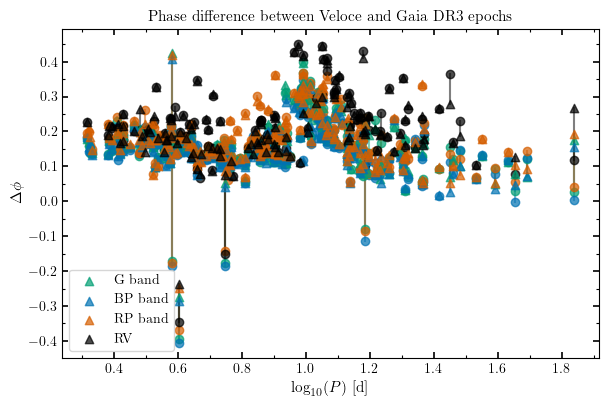

In [11]:
width = 3.46 * 2
height = width / 1.618
fig, axs = plt.subplots(figsize=(width, height))
x = np.log10(gaia_veloce_delta["P"])
y_v_names = [
    "DELTA_PHASE_G_V",
    "DELTA_PHASE_BP_V",
    "DELTA_PHASE_RP_V",
    "DELTA_PHASE_RV_V",
]
y_g_names = [
    "DELTA_PHASE_G_G",
    "DELTA_PHASE_BP_G",
    "DELTA_PHASE_RP_G",
    "DELTA_PHASE_RV_G",
]
y_colors = [
    color_safe["light_green"],
    color_safe["blue"],
    color_safe["dark_orange"],
    color_safe["black"],
]
y_labels = [
    "G band",
    "BP band",
    "RP band",
    "RV",
]
for y_v_name, y_g_name, c, label in zip(
    y_v_names,
    y_g_names,
    y_colors,
    y_labels,
    strict=True,
):
    y_v = gaia_veloce_delta[y_v_name]
    y_g = gaia_veloce_delta[y_g_name]
    axs.plot(
        [x, x],
        [y_v, y_g],
        color=c,
        alpha=0.5,
        zorder=0,
    )
    axs.scatter(
        x,
        y_v,
        color=c,
        marker="o",
        alpha=0.7,
        zorder=1,
    )
    axs.scatter(
        x,
        y_g,
        color=c,
        marker="^",
        alpha=0.7,
        zorder=2,
        label=label,
    )
xlim, ylim = axs.get_xlim(), axs.get_ylim()
x_ticks, x_ticks_minor = np.arange(0.2, 2, 0.2), np.arange(0.2, 2, 0.1)
y_ticks, y_ticks_minor = np.arange(-0.5, 0.5, 0.1), np.arange(-0.5, 0.5, 0.05)
vf.plot.format_xticks(axs, x_ticks, x_ticks_minor)
vf.plot.format_yticks(axs, y_ticks, y_ticks_minor)
axs.set_xlim(xlim)
axs.set_ylim(ylim)
axs.set_xlabel(r"$\log_{10}(P)$ [d]", fontsize=label_size)
axs.set_ylabel(r"$\Delta \phi$", fontsize=label_size)
axs.set_title(
    "Phase difference between Veloce and Gaia DR3 epochs",
    fontsize=label_size,
)
axs.legend()


I remove problematic cases in which the difference in periods and the high number of cycles between epochs cause a significant loss in phase.
We identify targets with phase drift with z-score above 3 to be outliers.

**Changed:** Now I consider the drift fraction. How the drift compares with the determined delta phase and remove the cases for which the ratio is about 0.3. Low values of phase are raised to a minimum of 0.1.

**CHANGED:** Only consider the absiolute of the drift. if bigger than 0.1 it is removed.

In [12]:
# drift_fraction = np.abs(gaia_veloce_delta["DELTA_PHASE_DRIFT_G"]) / np.maximum(
#     np.abs(gaia_veloce_delta["DELTA_PHASE_G_G"]),
#     0.1,
# )

drift_threshold = np.abs(gaia_veloce_delta["DELTA_PHASE_DRIFT_G"])

In [13]:
"""
z_score_limit = 3
outliers_gaia_veloce_delta = gaia_veloce_delta[
    np.abs(sp.stats.zscore(gaia_veloce_delta["DELTA_PHASE_DRIFT_G"])) > z_score_limit
]
gaia_veloce_delta_no_outliers = gaia_veloce_delta[
    ~gaia_veloce_delta["NAME"].isin(outliers_gaia_veloce_delta["NAME"])
]

outliers_gaia_veloce_delta
"""
outliers_gaia_veloce_delta = gaia_veloce_delta[drift_threshold > 0.1]
gaia_veloce_delta_no_outliers = gaia_veloce_delta[
    ~gaia_veloce_delta["NAME"].isin(outliers_gaia_veloce_delta["NAME"])
]

outliers_gaia_veloce_delta

,NAME,P,DELTA_PHASE_G_V,DELTA_PHASE_G_G,DELTA_PHASE_BP_V,DELTA_PHASE_BP_G,DELTA_PHASE_RP_V,DELTA_PHASE_RP_G,DELTA_PHASE_RV_V,DELTA_PHASE_RV_G,...,N_CYCLES_SEPARATION_RP,N_CYCLES_SEPARATION_RV,DELTA_PHASE_DRIFT_G,DELTA_PHASE_DRIFT_G_ERR,DELTA_PHASE_DRIFT_BP,DELTA_PHASE_DRIFT_BP_ERR,DELTA_PHASE_DRIFT_RP,DELTA_PHASE_DRIFT_RP_ERR,DELTA_PHASE_DRIFT_RV,DELTA_PHASE_DRIFT_RV_ERR
32,ASAS J190929+1232.8,4.010959,-0.395256,-0.274047,-0.406295,-0.285070,-0.368536,-0.247361,-0.347059,-0.237592,...,93.368536,84.347059,0.121367,0.016523,0.121382,0.016525,0.121333,0.016518,0.109609,0.014922
35,AV Sgr,15.329361,-0.079358,0.139233,-0.114986,0.103774,-0.086582,0.132043,0.103541,0.193182,...,46.086582,18.896459,0.219633,1.067451,0.219802,1.068277,0.219667,1.067619,0.090068,0.437746
112,S Vul,68.920076,0.026626,0.176119,0.004929,0.154593,0.041845,0.191218,0.119248,0.268011,...,18.958155,18.880752,0.150680,0.012762,0.150853,0.012776,0.150559,0.012752,0.149945,0.012700
147,V0389 Sct,3.799610,-0.170124,0.424595,-0.185970,0.408726,-0.177141,0.417567,NaN,NaN,...,278.177141,NaN,-0.404691,0.073620,-0.404714,0.073624,-0.404702,0.073622,NaN,NaN
168,V1197 Cen,5.563761,-0.176439,0.050907,-0.185388,0.041943,-0.141912,0.085488,-0.152423,0.074961,...,141.858088,141.847577,-0.226981,0.065818,-0.226967,0.065814,-0.227037,0.065834,-0.227020,0.065829


In [14]:
gaia_veloce_delta.sort_values(by="DELTA_PHASE_DRIFT_G", key=abs, ascending=False).head(
    10
)

,NAME,P,DELTA_PHASE_G_V,DELTA_PHASE_G_G,DELTA_PHASE_BP_V,DELTA_PHASE_BP_G,DELTA_PHASE_RP_V,DELTA_PHASE_RP_G,DELTA_PHASE_RV_V,DELTA_PHASE_RV_G,...,N_CYCLES_SEPARATION_RP,N_CYCLES_SEPARATION_RV,DELTA_PHASE_DRIFT_G,DELTA_PHASE_DRIFT_G_ERR,DELTA_PHASE_DRIFT_BP,DELTA_PHASE_DRIFT_BP_ERR,DELTA_PHASE_DRIFT_RP,DELTA_PHASE_DRIFT_RP_ERR,DELTA_PHASE_DRIFT_RV,DELTA_PHASE_DRIFT_RV_ERR
147,V0389 Sct,3.799610,-0.170124,0.424595,-0.185970,0.408726,-0.177141,0.417567,NaN,NaN,...,278.177141,NaN,-0.404691,0.073620,-0.404714,0.073624,-0.404702,0.073622,NaN,NaN
168,V1197 Cen,5.563761,-0.176439,0.050907,-0.185388,0.041943,-0.141912,0.085488,-0.152423,0.074961,...,141.858088,141.847577,-0.226981,0.065818,-0.226967,0.065814,-0.227037,0.065834,-0.227020,0.065829
35,AV Sgr,15.329361,-0.079358,0.139233,-0.114986,0.103774,-0.086582,0.132043,0.103541,0.193182,...,46.086582,18.896459,0.219633,1.067451,0.219802,1.068277,0.219667,1.067619,0.090068,0.437746
112,S Vul,68.920076,0.026626,0.176119,0.004929,0.154593,0.041845,0.191218,0.119248,0.268011,...,18.958155,18.880752,0.150680,0.012762,0.150853,0.012776,0.150559,0.012752,0.149945,0.012700
32,ASAS J190929+1232.8,4.010959,-0.395256,-0.274047,-0.406295,-0.285070,-0.368536,-0.247361,-0.347059,-0.237592,...,93.368536,84.347059,0.121367,0.016523,0.121382,0.016525,0.121333,0.016518,0.109609,0.014922
106,RY Vel,28.174209,0.155166,0.070092,0.111851,0.026718,0.136640,0.051540,0.363904,0.279112,...,62.863360,62.636096,-0.084960,0.020362,-0.085018,0.020376,-0.084985,0.020368,-0.084678,0.020295
0,AA Gem,11.303705,0.220522,0.301142,0.215938,0.296561,0.255870,0.336461,NaN,NaN,...,99.744130,NaN,0.080684,0.034530,0.080688,0.034532,0.080656,0.034518,NaN,NaN
196,Y Oph,17.127487,0.167267,0.103768,0.116795,0.053267,0.189899,0.126413,0.252536,0.193096,...,110.810101,103.747464,-0.063463,0.039192,-0.063492,0.039210,-0.063450,0.039184,-0.059406,0.036687
20,ASAS J101016-5811.2,3.037516,0.147863,0.208106,0.136947,0.197191,0.138947,0.199191,0.202843,0.263079,...,495.861053,495.797157,0.060250,0.009774,0.060251,0.009775,0.060251,0.009775,0.060243,0.009773
72,GS Lup,48.995676,0.121764,0.070157,0.123004,0.071399,0.144431,0.091242,NaN,NaN,...,32.855569,NaN,-0.051524,0.018716,-0.051522,0.018715,-0.053103,0.019289,NaN,NaN


In [15]:
len(gaia_veloce_delta_no_outliers)

202

Text(0.5, 0, 'Drift Thres G')

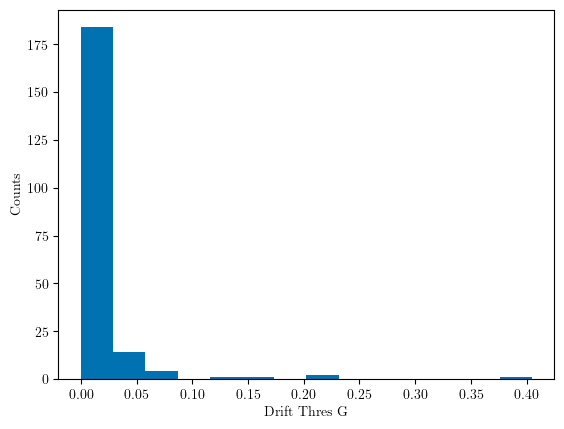

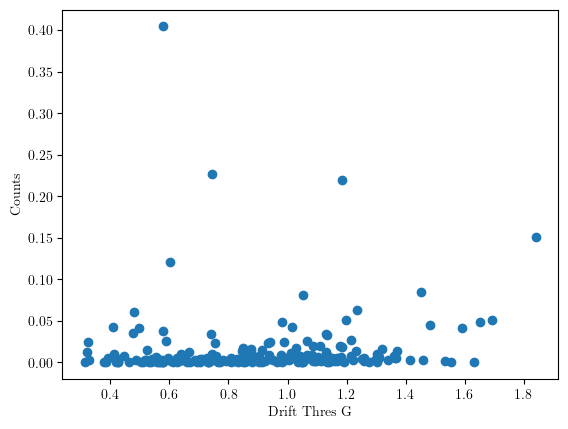

In [16]:
fig, axs = plt.subplots()
axs.hist(
    drift_threshold,
    bins=int(np.sqrt(len(drift_threshold))),
    density=False,
    color=color_safe["blue"],
    label="Data",
)

axs.set_ylabel("Counts")
axs.set_xlabel("Drift Thres G")
fig, axs = plt.subplots()
axs.scatter(
    np.log10(gaia_veloce_delta["P"]),
    drift_threshold,
    label="Data",
)

axs.set_ylabel("Counts")
axs.set_xlabel("Drift Thres G")

Moving forward we will use only $\Delta \phi_G$ as $\Delta \phi$.

Now, since later we want our prior to be independent of photometric band, we stack all photometric $\Delta \phi$ into a single column.

In [17]:
delta_phase_stacked_list = []
for _, row in gaia_veloce_delta_no_outliers.iterrows():
    delta_phase_stacked_list.extend(
        [
            {
                "NAME": row["NAME"],
                "P": row["P"],
                "log_P": np.log10(row["P"]),
                "DELTA_PHASE": row[f"DELTA_PHASE_{band}_G"],
                "BAND": band,
            }
            for band in ["G", "BP", "RP"]
        ],
    )

photometric_delta_phase = pd.DataFrame(delta_phase_stacked_list)


Distribution of $\Delta \phi$ values

Text(0.5, 1.0, 'Phase difference between Veloce and Gaia DR3 epochs')

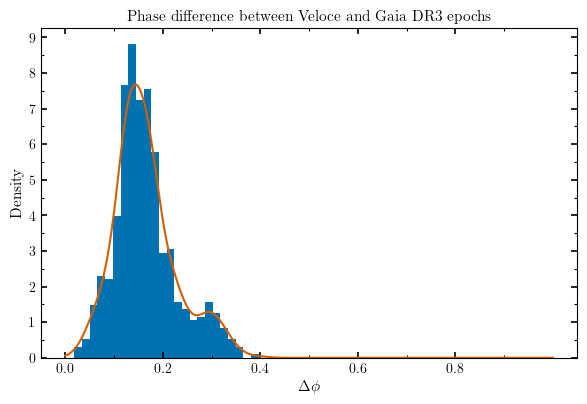

In [18]:
width = 3.46 * 2
height = width / 1.618
fig, axs = plt.subplots(figsize=(width, height))
axs.hist(
    photometric_delta_phase["DELTA_PHASE"],
    bins=int(np.sqrt(len(photometric_delta_phase))),
    density=True,
    color=color_safe["blue"],
    label="Data",
)
# KDE of the phase differences
kde_delta_phase = gaussian_kde(photometric_delta_phase["DELTA_PHASE"])
x_kde = np.linspace(0, 1, 1000)
y_kde = kde_delta_phase(x_kde)
axs.plot(x_kde, y_kde, color=color_safe["dark_orange"], label="KDE")

xlim, ylim = axs.get_xlim(), axs.get_ylim()
x_ticks, x_ticks_minor = np.arange(0, 1, 0.2), np.arange(0, 1, 0.1)
y_ticks, y_ticks_minor = np.arange(0, 10, 1), np.arange(0, 10, 0.5)
vf.plot.format_xticks(axs, x_ticks, x_ticks_minor)
vf.plot.format_yticks(axs, y_ticks, y_ticks_minor)
axs.set_xlim(xlim)
axs.set_ylim(ylim)
axs.set_xlabel(r"$\Delta \phi$", fontsize=label_size)
axs.set_ylabel(r"Density", fontsize=label_size)
axs.set_title(
    "Phase difference between Veloce and Gaia DR3 epochs",
    fontsize=label_size,
)

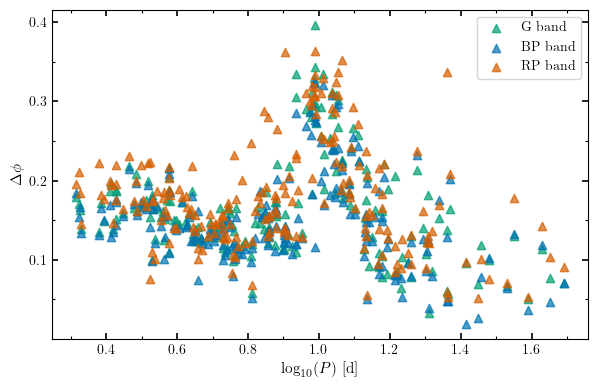

In [19]:
width = 3.46 * 2
height = width / 1.618
fig, axs = plt.subplots(figsize=(width, height))
x = np.log10(gaia_veloce_delta_no_outliers["P"])
y_g_names = [
    "DELTA_PHASE_G_G",
    "DELTA_PHASE_BP_G",
    "DELTA_PHASE_RP_G",
]
y_colors = [
    color_safe["light_green"],
    color_safe["blue"],
    color_safe["dark_orange"],
]
y_labels = [
    "G band",
    "BP band",
    "RP band",
]
for y_g_name, c, label in zip(
    y_g_names,
    y_colors,
    y_labels,
    strict=True,
):
    y_g = gaia_veloce_delta_no_outliers[y_g_name]
    axs.scatter(
        x,
        y_g,
        color=c,
        marker="^",
        alpha=0.7,
        zorder=2,
        label=label,
    )
xlim, ylim = axs.get_xlim(), axs.get_ylim()
x_ticks, x_ticks_minor = np.arange(0.2, 2, 0.2), np.arange(0.2, 2, 0.1)
y_ticks, y_ticks_minor = np.arange(-0.5, 0.5, 0.1), np.arange(-0.5, 0.5, 0.05)
vf.plot.format_xticks(axs, x_ticks, x_ticks_minor)
vf.plot.format_yticks(axs, y_ticks, y_ticks_minor)
axs.set_xlim(xlim)
axs.set_ylim(ylim)
axs.set_xlabel(r"$\log_{10}(P)$ [d]", fontsize=label_size)
axs.set_ylabel(r"$\Delta \phi$", fontsize=label_size)
axs.legend()

In [20]:
len(photometric_delta_phase.groupby("NAME"))

202

In [21]:
len(gaia_veloce_delta_no_outliers)

202

---
## Analysis

Set a folder where to save our results

In [22]:
saving_dir = Path(os.environ.get("RESULTS_DIR", "")).expanduser() / "veloce_III"
saving_dir.mkdir(exist_ok=True)

We divide the data in train and test set (15% test set)

In [23]:
percentage_test_set = 0.15
targets = veloce_headers["NAME"].to_numpy()

# Divide in training and test sample
idx_train, idx_test = train_test_split(
    np.arange(len(targets)),
    test_size=percentage_test_set,
    random_state=40,
)
veloce_headers["SET"] = "train"
veloce_headers.iloc[idx_test, veloce_headers.columns.get_loc("SET")] = "test"

# Number of training and test samples
n_train = np.sum(veloce_headers["SET"] == "train")
n_test = np.sum(veloce_headers["SET"] == "test")
print(f"Number of training samples: {n_train}")  # noqa: T201
print(f"Number of test samples: {n_test}")  # noqa: T201

Number of training samples: 186
Number of test samples: 33


### Compute sample
Define the phase grid on which to sample the pulsation: 1000 sampled points between $\phi = 0$ and $\phi = 1$

In [24]:
min_phase, max_phase = 0.0, 1.0
n_bins = 1000
phase_grid = np.linspace(min_phase, max_phase, n_bins, endpoint=False)
phase_step = phase_grid[1] - phase_grid[0]
print(f"Min and max phase: {min_phase:.3f}, {max_phase:.3f}")  # noqa: T201
print(f"Phase step: {phase_step:.3f}")  # noqa: T201

Min and max phase: 0.000, 1.000
Phase step: 0.001


In [25]:
phase_grid

array([0.   , 0.001, 0.002, 0.003, 0.004, 0.005, 0.006, 0.007, 0.008,
       0.009, 0.01 , 0.011, 0.012, 0.013, 0.014, 0.015, 0.016, 0.017,
       0.018, 0.019, 0.02 , 0.021, 0.022, 0.023, 0.024, 0.025, 0.026,
       0.027, 0.028, 0.029, 0.03 , 0.031, 0.032, 0.033, 0.034, 0.035,
       0.036, 0.037, 0.038, 0.039, 0.04 , 0.041, 0.042, 0.043, 0.044,
       0.045, 0.046, 0.047, 0.048, 0.049, 0.05 , 0.051, 0.052, 0.053,
       0.054, 0.055, 0.056, 0.057, 0.058, 0.059, 0.06 , 0.061, 0.062,
       0.063, 0.064, 0.065, 0.066, 0.067, 0.068, 0.069, 0.07 , 0.071,
       0.072, 0.073, 0.074, 0.075, 0.076, 0.077, 0.078, 0.079, 0.08 ,
       0.081, 0.082, 0.083, 0.084, 0.085, 0.086, 0.087, 0.088, 0.089,
       0.09 , 0.091, 0.092, 0.093, 0.094, 0.095, 0.096, 0.097, 0.098,
       0.099, 0.1  , 0.101, 0.102, 0.103, 0.104, 0.105, 0.106, 0.107,
       0.108, 0.109, 0.11 , 0.111, 0.112, 0.113, 0.114, 0.115, 0.116,
       0.117, 0.118, 0.119, 0.12 , 0.121, 0.122, 0.123, 0.124, 0.125,
       0.126, 0.127,

Compute each VELOCE model at each point of the phase grid to create the sample on which we will perform PCA. 
- `dataset` is a pd.DataFrame that contains both the sample and metadata for each target
- `sample` is a pd.DataFrame just containing the sample (each column correspond to a point of the phase grid defined before)

In [26]:
dataset = pd.DataFrame()
for _, header in veloce_headers.iterrows():
    name = header["NAME"]
    set_type = header["SET"]
    nharm = int(header["N_TERMS_FS"])
    fs_coeffs = veloce_fit[veloce_fit["NAME"] == name]["FS_COEFFS"].iloc[0]
    temp_sample = vf.model.FourierSeries(nharm=nharm).evaluate(fs_coeffs, phase_grid)

    temp = pd.DataFrame(
        {
            "NAME": name,
            "SET": set_type,
            "SAMPLE": [temp_sample],
        },
    )
    dataset = pd.concat([dataset, temp], ignore_index=True)
sample = pd.DataFrame(dataset["SAMPLE"].to_numpy().tolist(), index=dataset.index)

Separate train and test sample

In [27]:
training_set = dataset[dataset["SET"] == "train"]
training_sample = sample[dataset["SET"] == "train"]
test_set = dataset[dataset["SET"] == "test"]
test_sample = sample[dataset["SET"] == "test"]

### Preprocess the samples

I remove the mean to the sample.

In [28]:
mean_training_sample = training_sample.mean()
scaled_training_sample = training_sample - mean_training_sample
scaled_test_sample = test_sample - mean_training_sample

Plot the sample and the scaled sample for the training and test set

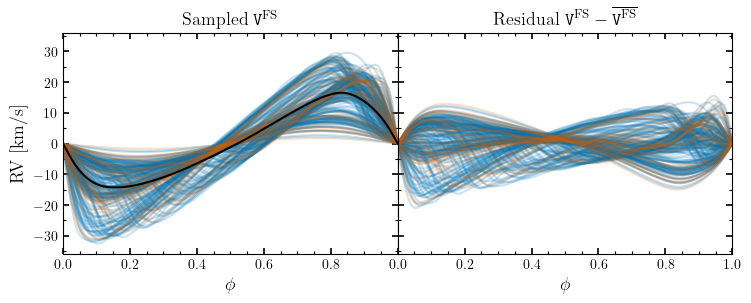

In [29]:
def rows_to_linecollection(
    df: pd.DataFrame,
    x: np.ndarray,
    **kwargs: int | str | list,
) -> LineCollection:
    """Generate LineCollection for each row a pandas.Dataframe."""
    y = df.to_numpy()  # shape (n_lines, n_points)
    x_tiled = np.tile(x, (len(y), 1))  # shape (n_lines, n_points)
    segments = np.stack([x_tiled, y], axis=-1)  # shape (n_lines, n_points, 2)
    return LineCollection(segments, **kwargs)


width = 3.46 * 2.2
height = width / 1.618 / 1.5
fig, axs = plt.subplots(1, 2, figsize=(width, height), sharey=True)

# Plot collection of lines
axs[0].add_collection(
    rows_to_linecollection(
        training_sample,
        phase_grid,
        color=color_safe["blue"],
        alpha=0.2,
    ),
)
axs[0].add_collection(
    rows_to_linecollection(
        test_sample,
        phase_grid,
        color=color_safe["dark_orange"],
        alpha=0.2,
        zorder=2,
    ),
)
axs[1].add_collection(
    rows_to_linecollection(
        scaled_training_sample,
        phase_grid,
        color=color_safe["blue"],
        alpha=0.2,
    ),
)
axs[1].add_collection(
    rows_to_linecollection(
        scaled_test_sample,
        phase_grid,
        color=color_safe["dark_orange"],
        alpha=0.2,
        zorder=2,
    ),
)

# Plot mean
axs[0].plot(
    phase_grid,
    mean_training_sample,
    color=color_safe["black"],
    lw=1.5,
    zorder=3,
)

axs[1].yaxis.set_label_position("right")
axs[1].yaxis.tick_right()
axs[0].set_xlabel(r"$\phi$", fontsize=label_size + 2)
axs[0].set_ylabel(r"$\mathrm{RV \ [km/s]}$", fontsize=label_size + 2)
axs[0].set_title(r"Sampled $ \texttt{V}^{\rm FS}$", fontsize=label_size + 2)
axs[1].set_xlabel(r"$\phi$", fontsize=label_size + 2)
axs[1].set_title(
    r"Residual $ \texttt{V}^{\rm FS} - \overline{ \texttt{V}^{\rm FS}}$",
    fontsize=label_size + 2,
)

x_ticks = np.arange(-0.4, 1.6, 0.2)
x_ticks_minor = np.arange(-0.4, 1.6, 0.05)
vf.plot.format_xticks(axs[0], x_ticks[:-3], x_ticks_minor)
vf.plot.format_xticks(axs[1], x_ticks, x_ticks_minor)
axs[0].set_xlim(0, 1)
axs[1].set_xlim(0, 1)

y_ticks = np.arange(-40, 40, 10)
y_ticks_minor = np.arange(-45, 45, 5)
vf.plot.format_yticks(axs[0], y_ticks, y_ticks_minor)
vf.plot.format_yticks(axs[1], y_ticks, y_ticks_minor)
axs[0].set_ylim(-36, 36)
axs[1].set_ylim(-36, 36)

fig.tight_layout()
fig.subplots_adjust(wspace=0, hspace=0)
fig.savefig(saving_dir / "scaled_fourier_series.pdf")

### PCA Analysis

In [30]:
pca = PCA(n_components=20, svd_solver="full")
_ = pca.fit(scaled_training_sample)

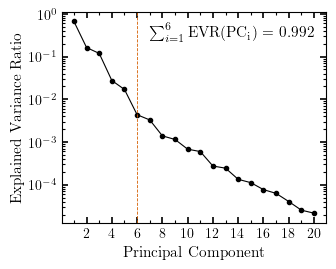

In [31]:
# Plot the explained variance ratio
width = 3.46
height = width * 1.618 / 2
fig, axs = plt.subplots(figsize=(width, height))
axs.plot(
    np.arange(1, pca.n_components_ + 1),
    pca.explained_variance_ratio_,
    "o-",
    color=color_safe["black"],
    markersize=3,
    lw=0.8,
)
axs.set_yscale("log")
x_ticks = np.arange(2, 22, 2)
x_ticks_minor = np.arange(1, 21, 1)
vf.plot.format_xticks(axs, x_ticks, x_ticks_minor)
yticks, y_ticks_minor = axs.get_yticks(), axs.get_yticks(minor=True)
vf.plot.format_yticks(axs, yticks, y_ticks_minor)
axs.axhline(0, color=color_safe["black"], lw=0.6, ls="--")
axs.axvline(6, color=color_safe["dark_orange"], lw=0.6, ls="--")
axs.text(
    20,
    0.65,
    (
        r"$\sum_{i=1}^6 \mathrm{EVR(PC_{i})=}$"
        f"{sum(pca.explained_variance_ratio_[:6]): .3f}"
    ),
    fontsize=11,
    color=color_safe["black"],
    weight="heavy",
    ha="right",
    va="top",
)
axs.set_xlabel("Principal Component", fontsize=11)
axs.set_ylabel("Explained Variance Ratio", fontsize=11)
fig.tight_layout()
plt.savefig(saving_dir / "pca_explained_variance_ratio_log.pdf", format="pdf")

Number of components retained: 6

In [32]:
pca = PCA(n_components=6, svd_solver="full")
pca.fit(scaled_training_sample)
print(f"PCA explained variance: {sum(pca.explained_variance_ratio_)}")  # noqa: T201
pca.components_[0] *= -1
# Changed sign to make a later comparison easier (Fourier ratios in VELOCE DR1)

PCA explained variance: 0.9918593608909053


PCA explained variance: 0.9918593608909052

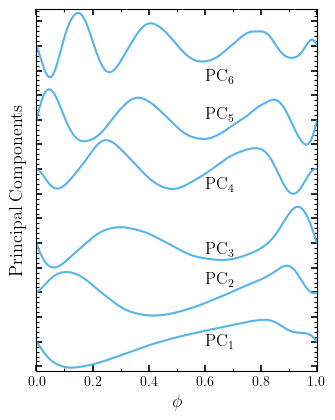

In [33]:
# Plot PCA components
width = 3.46
height = width * 1.618 / 1.3
fig, axs = plt.subplots(figsize=(width, height))
n_components = pca.n_components_
offset_plot_comp = [0.0, 0.1, 0.2, 0.35, 0.45, 0.6]
for i, component in enumerate(pca.components_):
    axs.plot(
        phase_grid,
        component + offset_plot_comp[i],
        label=f"Component {i + 1}",
        color=color_safe["light_blue"],
    )

    y = (component[600] + offset_plot_comp[i]) + 0.01
    if i == 0:
        y -= 0.04
    if i == 1:
        y += 0.03
    if i == 3:  # noqa: PLR2004
        y -= 0.04
    if i == 4:  # noqa: PLR2004
        y += 0.03
    if i == 5:  # noqa: PLR2004
        y -= 0.05

    x = 0.6

    axs.text(
        x,
        y,
        r"$\rm{PC_" + str(i + 1) + "}$",
        fontsize=12,
        color=color_safe["black"],
        weight="heavy",
    )

x_ticks = np.arange(-0.4, 1.6, 0.2)
x_ticks_minor = np.arange(-0.4, 1.6, 0.1)
vf.plot.format_xticks(axs, x_ticks, x_ticks_minor)
axs.set_xlim(0, 1)
y_ticks = np.arange(-0.1, 0.11 + np.max(offset_plot_comp) + 0.1, 0.05)
y_ticks_minor = np.arange(-0.08, 0.08 + np.max(offset_plot_comp) + 0.1, 0.01)
vf.plot.format_yticks(axs, y_ticks, y_ticks_minor)
axs.set_ylim(-0.06, 0.074 + np.max(offset_plot_comp))
axs.get_yaxis().set_ticklabels([])
axs.set_xlabel(r"$\phi$", fontsize=label_size + 2)
axs.set_ylabel("Principal Components", fontsize=label_size + 2)
fig.tight_layout()
plt.savefig(saving_dir / "pca_components.pdf", format="pdf")

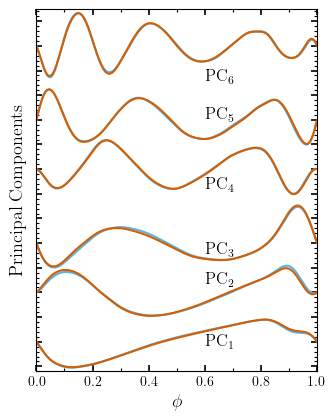

In [34]:
pca_all = PCA(n_components=6, svd_solver="full")
pca_all.fit(sample - mean_training_sample)
pca_all.components_[0] *= -1

# Plot PCA components
width = 3.46
height = width * 1.618 / 1.3
fig, axs = plt.subplots(figsize=(width, height))
n_components = pca.n_components_
offset_plot_comp = [0.0, 0.1, 0.2, 0.35, 0.45, 0.6]
for i, (component, all_component) in enumerate(
    zip(pca.components_, pca_all.components_)
):
    axs.plot(
        phase_grid,
        component + offset_plot_comp[i],
        label=f"Component {i + 1}",
        color=color_safe["light_blue"],
    )
    axs.plot(
        phase_grid,
        all_component + offset_plot_comp[i],
        label=f"ALL Component {i + 1}",
        color=color_safe["dark_orange"],
    )

    y = (component[600] + offset_plot_comp[i]) + 0.01
    if i == 0:
        y -= 0.04
    if i == 1:
        y += 0.03
    if i == 3:  # noqa: PLR2004
        y -= 0.04
    if i == 4:  # noqa: PLR2004
        y += 0.03
    if i == 5:  # noqa: PLR2004
        y -= 0.05

    x = 0.6

    axs.text(
        x,
        y,
        r"$\rm{PC_" + str(i + 1) + "}$",
        fontsize=12,
        color=color_safe["black"],
        weight="heavy",
    )

x_ticks = np.arange(-0.4, 1.6, 0.2)
x_ticks_minor = np.arange(-0.4, 1.6, 0.1)
vf.plot.format_xticks(axs, x_ticks, x_ticks_minor)
axs.set_xlim(0, 1)
y_ticks = np.arange(-0.1, 0.11 + np.max(offset_plot_comp) + 0.1, 0.05)
y_ticks_minor = np.arange(-0.08, 0.08 + np.max(offset_plot_comp) + 0.1, 0.01)
vf.plot.format_yticks(axs, y_ticks, y_ticks_minor)
axs.set_ylim(-0.06, 0.074 + np.max(offset_plot_comp))
axs.get_yaxis().set_ticklabels([])
axs.set_xlabel(r"$\phi$", fontsize=label_size + 2)
axs.set_ylabel("Principal Components", fontsize=label_size + 2)
fig.tight_layout()
# plt.savefig(saving_dir / "pca_components.pdf", format="pdf")

In [35]:
for i, _ in enumerate(pca.components_):
    # 3. Extract the first principal component (PC1) for both
    v1 = pca.components_[i]  # Shape: (n_features,)
    v2 = pca_all.components_[i]  # Shape: (n_features,)
    # 4. Calculate Absolute Cosine Similarity
    # (Sklearn components are already normalized, but norm division ensures safety)
    dot_product = np.dot(v1, v2)
    cosine_sim = np.abs(dot_product / (np.linalg.norm(v1) * np.linalg.norm(v2)))

    # 5. Convert to Angle (Radians and Degrees)
    # np.clip prevents tiny floating-point errors from breaking arccos
    angle_rad = np.arccos(np.clip(cosine_sim, -1.0, 1.0))
    angle_deg = np.degrees(angle_rad)

    print(f"Absolute Cosine Similarity: {cosine_sim:.4f}")
    print(f"Angle between PC{i + 1} vectors: {angle_deg:.2f}°")

Absolute Cosine Similarity: 0.9993
Angle between PC1 vectors: 2.20°
Absolute Cosine Similarity: 0.9965
Angle between PC2 vectors: 4.77°
Absolute Cosine Similarity: 0.9965
Angle between PC3 vectors: 4.78°
Absolute Cosine Similarity: 0.9993
Angle between PC4 vectors: 2.12°
Absolute Cosine Similarity: 0.9989
Angle between PC5 vectors: 2.73°
Absolute Cosine Similarity: 0.9990
Angle between PC6 vectors: 2.62°


### Fit VELOCE observations and RV curves (sampled over phase grid) using PCs

First, we define a model of the linear combination of the components

In [36]:
class LinearCombinationPC(vf.model.BaseModel):
    """Linear combination of the PCA components."""

    def __init__(
        self,
        pca: PCA,
        mean_training_sample: np.ndarray,
        phase_grid: np.ndarray = phase_grid,
        name: str = "lcc",
    ) -> None:
        """Initialize the model with the PCA components and the mean training sample."""
        super().__init__(name=name)
        self.pca = pca
        self.phase_grid = phase_grid
        self.components = pca.components_
        self.removed_mean = mean_training_sample

    @property
    def n_params(self) -> int:
        """Number of parameters is equal to the number of PCA components."""
        return self.components.shape[0]

    @property
    def param_names(self) -> list[str]:
        """Parameter names."""
        # pc1, pc2, ..., pcN
        return [f"pc{i}" for i in range(1, self.n_params + 1)]

    def evaluate(
        self,
        theta: list | np.ndarray,
        x: float | list | np.ndarray,
        **kwargs: object,  # noqa: ARG002
    ) -> np.ndarray:
        """Evaluate the model."""
        # Reshape theta to be a 1-dimensional array
        theta = np.array(theta).reshape(-1)
        # Evaluate the linear combination
        # interpolated_curve = sp.interpolate.interp1d(
        #     self.phase_grid,
        #     self.removed_mean + np.dot(self.components.T, theta),
        # )
        return np.interp(
            x,
            self.phase_grid,
            self.removed_mean + np.dot(self.components.T, theta),
        )
        # return interpolated_curve(x)

Then, we complete the model by adding a constant model to account for $v_\gamma$

In [37]:
pca_puls_model = LinearCombinationPC(
    pca=pca,
    mean_training_sample=mean_training_sample.to_numpy(),
    name="pca_puls",
)

vgamma_model = vf.model.Constant(name="v_gamma")

pca_model = vgamma_model + pca_puls_model

We fit this model to both VELOCE data and the initial sampled model. Any difference in resulting coefficients would then be caused by the phase coverage of the observations, while any discrepancy between the new pca-component-based model and the original model is sympton of the lost information due to the reduction in dimensionality.

In [38]:
fit_rv = []
for _, header in tqdm(veloce_headers.iterrows(), total=len(veloce_headers)):
    name = header["NAME"]
    set_type = header["SET"]

    # Fit the PCs to the VELOCE data

    # 1. Get the observed data for the current target
    # To allow for a more direct comparison between VELOCE Fourier series and
    # the new PCA model, we fit only the observations that were used to compute
    # the VELOCE models. Thus, we filter the observations with the provided MASK
    # field.
    target_data = veloce_data[(veloce_data["NAME"] == name) & (veloce_data["MASK"])]
    bjd, rv, rv_err = (
        target_data["BJD"].to_numpy().copy(),
        target_data["RV"].to_numpy().copy(),
        target_data["RV_ERR"].to_numpy().copy(),
    )
    phase = vf.model.calculate_phase(bjd, header["P"], header["E"])

    # 2. Variable vgamma
    # For certain targets in VELOCE a polynomial model was used to account for a
    # varying vgamma. Here, we are not interested in dealing with this problem
    # and, instead, we want to focus only on the pulsation signal. So, using the
    # published polynomials, we determine and remove these additional signals
    # from the datapoints, before fitting them with the PCA model.
    target_veloce_fit = veloce_fit[veloce_fit["NAME"] == name].iloc[0]
    if isinstance(target_veloce_fit["POLY_COEFFS"], np.ndarray):
        trend_model = vf.model.PolynomialBasis(int(header["POLYDEG"]))
        trend = trend_model.evaluate(
            target_veloce_fit["POLY_COEFFS"],
            bjd - header["E"],
        )
        rv -= trend

    # 3. Fit the PCA model
    # Only pulsation signal and unique vgamma.
    fit_result = vf.fit.fit_least_squares(
        compiled_model=pca_model,
        x=phase,
        y=rv,
        yerr=rv_err,
        theta_free_init=np.zeros(pca_model.n_params),
    )
    if isinstance(fit_result, vf.fit.FailedFitResult):
        msg = f"Fit failed for {name} in {set_type} set. Reason: {fit_result.message}"
        logger.warning(msg)
        raise vf.fit.FailedFitError(msg)

    # To estimate the uncertainty on the peak-to-peak, we measure the
    # distribution of peak-to-peak values obtained by varying the parameters
    # within their uncertainties.
    rv_fit = pca_model.evaluate(theta=fit_result.theta_free, x=phase_grid)
    p2p_fit = np.ptp(rv_fit)
    n_samples = 200
    p2p_values = np.zeros(n_samples)
    for i in range(n_samples):
        # Sample parameters from the covariance matrix
        sampled_theta = rng.multivariate_normal(
            mean=fit_result.theta_free,
            cov=fit_result.extra["covariance_matrix"],
        )
        rv_sampled = pca_model.evaluate(theta=sampled_theta, x=phase_grid)
        p2p_values[i] = np.ptp(rv_sampled)

    p2p_err = np.std(p2p_values)

    # Furthermore, we can also compute the RMSE of the fit compared with the
    # VELOCE Fourier series fit.
    veloce_fs_coeffs = target_veloce_fit["FS_COEFFS"]
    nharm = int(len(veloce_fs_coeffs) / 2)
    veloce_model = (
        vf.model.FourierSeries(nharm=nharm).evaluate(veloce_fs_coeffs, phase_grid)
        + target_veloce_fit["VGAMMA"]
    )
    rmse_fit_veloce = np.sqrt(np.mean((rv_fit - veloce_model) ** 2))

    # Save the results
    fit_rv.append(
        {
            "NAME": name,
            "SET": set_type,
            "LS_RESULT": fit_result,
            "CHI2": fit_result.stats.chi2,
            "NORM_CHI2": fit_result.stats.reduced_chi2,
            "RMSE": fit_result.stats.rmse,
            "VGAMMA": fit_result.theta_free[0],
            "VGAMMA_ERR": fit_result.extra["theta_err"][0],
            "P2P": p2p_fit,
            "P2P_ERR": p2p_err,
            "RMSE_VELOCE": rmse_fit_veloce,
        },
    )


fit_rv_df = pd.DataFrame(fit_rv)

  0%|          | 0/219 [00:00<?, ?it/s]

#### Compare fit over VELOCE data with VELOCE's fit results

In [39]:
# Target by target comparison of the PCA fit with the VELOCE Fourier series fit,
# in terms of peak-to-peak and vgamma. Few keys are added to facilitate the
# analysis later on.
for idx, row in fit_rv_df.iterrows():
    name = row["NAME"]
    veloce_headers_row = veloce_headers[veloce_headers["NAME"] == name].iloc[0]
    veloce_fit_row = veloce_fit[veloce_fit["NAME"] == name].iloc[0]

    # Peak-to-peak comparison
    fit_rv_df.loc[idx, "P2P_DELTA"] = row["P2P"] - veloce_headers_row["PEAK2PEAK"]
    fit_rv_df.loc[idx, "P2P_DELTA_ERR"] = row["P2P_ERR"]  # We assume VELOCE to be exact
    fit_rv_df.loc[idx, "P2P_DELTA_RATIO"] = (
        row["P2P"] - veloce_headers_row["PEAK2PEAK"]
    ) / veloce_headers_row["PEAK2PEAK"]
    fit_rv_df.loc[idx, "P2P_DELTA_RATIO_ERR"] = (
        row["P2P_ERR"] / veloce_headers_row["PEAK2PEAK"]
    )

    # Vgamma comparison
    fit_rv_df.loc[idx, "VGAMMA_DELTA"] = row["VGAMMA"] - veloce_fit_row["VGAMMA"]
    fit_rv_df.loc[idx, "VGAMMA_DELTA_ERR"] = row["VGAMMA_ERR"]  # Same as above
    fit_rv_df.loc[idx, "VGAMMA_DELTA_RATIO"] = (
        row["VGAMMA"] - veloce_fit_row["VGAMMA"]
    ) / veloce_headers_row["PEAK2PEAK"]
    fit_rv_df.loc[idx, "VGAMMA_DELTA_RATIO_ERR"] = (
        row["VGAMMA_ERR"] / veloce_headers_row["PEAK2PEAK"]
    )

    # Add period to the dataframe for later analysis
    fit_rv_df.loc[idx, "P"] = veloce_headers_row["P"]

    # Add scaled RMSE
    fit_rv_df.loc[idx, "RMSE_SCALED"] = row["RMSE"] / veloce_headers_row["PEAK2PEAK"]
    fit_rv_df.loc[idx, "RMSE_VELOCE_SCALED"] = (
        row["RMSE_VELOCE"] / veloce_headers_row["PEAK2PEAK"]
    )

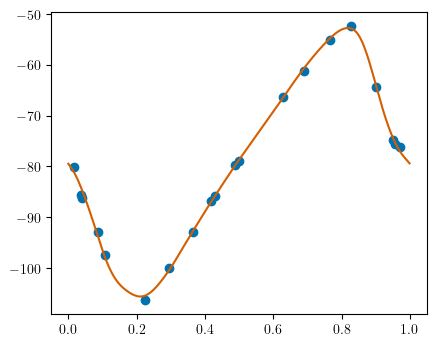

In [40]:
# Plot fit for one of the targets
target_name = "CY Cas"
target_fit = fit_rv_df[fit_rv_df["NAME"] == target_name]["LS_RESULT"].iloc[0]
width = 3.46 * 1.4
height = width * 1.618 / 2
fig, ax = plt.subplots(figsize=(width, height))
ax.plot(target_fit.x, target_fit.y, "o", label="Data", color=color_safe["blue"])
ax.plot(
    phase_grid,
    pca_model.evaluate(theta=target_fit.theta_free, x=phase_grid),
    label="PCA Fit",
    color=color_safe["dark_orange"],
)

In [41]:
fit_rv_train_df = fit_rv_df[fit_rv_df["SET"] == "train"]
fit_rv_test_df = fit_rv_df[fit_rv_df["SET"] == "test"]

##### Handle Outliers

Determine and remove outliers based on z-score (as before) on the $v_\gamma$ and $P2P$ difference distrubutions

In [42]:
fit_rv_df["OUTLIER"] = False
fit_rv_df["OUTLIER"] = fit_rv_df["OUTLIER"].astype(bool)

# Absolute Z-score for vgamma below 3
z_score_limit = 3
zscore_vgamma_rv = sp.stats.zscore(fit_rv_df["VGAMMA_DELTA"])
fit_rv_df["OUTLIER"] = fit_rv_df["OUTLIER"] | (np.abs(zscore_vgamma_rv) > z_score_limit)
# Only outlier: AV Sgr
# it is caused by the fact that we don't have many observations and the phase
# sampling is not good enough. No points between phase 0.85-0.25.

# Absolute Z-score for the delta p2p below 3
zscore_p2p_rv = sp.stats.zscore(fit_rv_df["P2P_DELTA"])
fit_rv_df["OUTLIER"] = fit_rv_df["OUTLIER"] | (np.abs(zscore_p2p_rv) > z_score_limit)
# No outliers found from the delta p2p

# Show outliers
fit_rv_df[fit_rv_df["OUTLIER"]]

,NAME,SET,LS_RESULT,CHI2,NORM_CHI2,RMSE,VGAMMA,VGAMMA_ERR,P2P,P2P_ERR,...,P2P_DELTA_RATIO,P2P_DELTA_RATIO_ERR,VGAMMA_DELTA,VGAMMA_DELTA_ERR,VGAMMA_DELTA_RATIO,VGAMMA_DELTA_RATIO_ERR,P,RMSE_SCALED,RMSE_VELOCE_SCALED,OUTLIER
35,AV Sgr,test,"SuccessfulFitResult(method='least_squares', mo...",1.387705,0.693853,0.029682,19.449851,1.380979,66.734054,9.448656,...,0.412309,0.199964,-4.113996,1.380979,-0.087065,0.029226,15.329361,0.000628,0.198851,True


In [43]:
# Add outliers based on visual inspection
fit_rv_df.loc[fit_rv_df["NAME"].isin(["BB Gem", "IR Cep"]), "OUTLIER"] = True

In [44]:
fit_rv_df[fit_rv_df["OUTLIER"]]

,NAME,SET,LS_RESULT,CHI2,NORM_CHI2,RMSE,VGAMMA,VGAMMA_ERR,P2P,P2P_ERR,...,P2P_DELTA_RATIO,P2P_DELTA_RATIO_ERR,VGAMMA_DELTA,VGAMMA_DELTA_ERR,VGAMMA_DELTA_RATIO,VGAMMA_DELTA_RATIO_ERR,P,RMSE_SCALED,RMSE_VELOCE_SCALED,OUTLIER
35,AV Sgr,test,"SuccessfulFitResult(method='least_squares', mo...",1.387705,0.693853,0.029682,19.449851,1.380979,66.734054,9.448656,...,0.412309,0.199964,-4.113996,1.380979,-0.087065,0.029226,15.329361,0.000628,0.198851,True
38,BB Gem,train,"SuccessfulFitResult(method='least_squares', mo...",34.836185,5.806031,0.118548,65.190664,0.051898,39.090592,0.192481,...,-0.049320,0.004681,-0.366315,0.051898,-0.008909,0.001262,2.308207,0.002883,0.025148,True
81,IR Cep,train,"SuccessfulFitResult(method='least_squares', mo...",683.195838,52.553526,0.332520,-4.961448,0.018360,20.785701,0.069929,...,0.039939,0.003499,0.316018,0.018360,0.015811,0.000919,2.113946,0.016636,0.042094,True


In [45]:
# Get only the non-outliers
fit_rv_no_outliers = fit_rv_df[~fit_rv_df["OUTLIER"]]

##### Plot the results of fitting VELOCE observations

#### Plot fit results

In [46]:
highlight_particular_cases = {
    "BB Gem": 1,
    "IR Cep": 2,
    "alf UMi": 3,
    "V0440 Per": 4,
    "ASAS J064540+0330.4": 5,
    "AV Sgr": 6,
}

ASAS J064540+0330.4
AV Sgr
BB Gem
IR Cep
V0440 Per
alf UMi


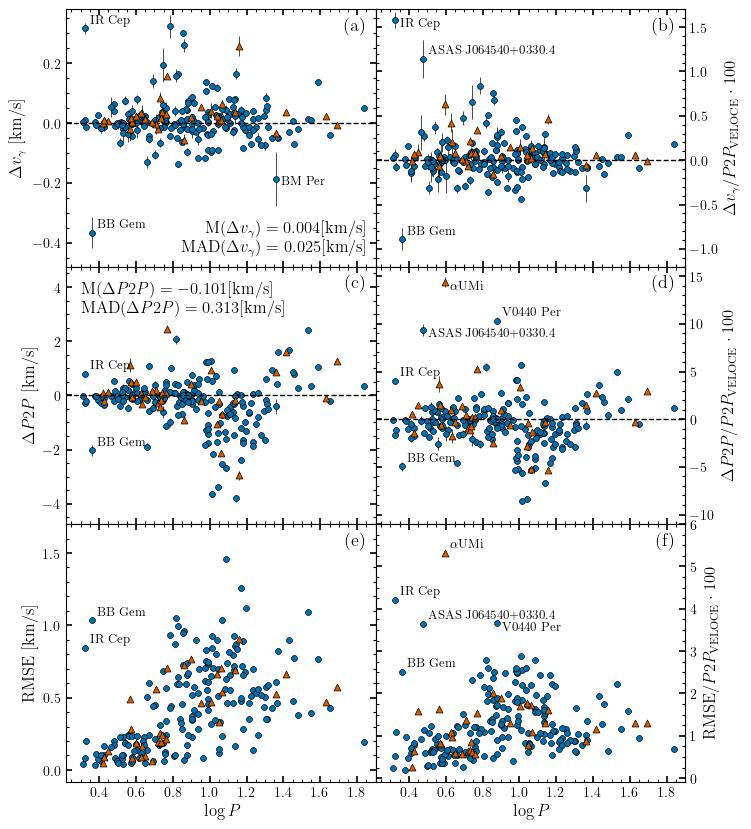

In [ ]:
width = 3.46 * 2.2
height = width * 1.618 / 2 * 3 / 2.2  # / 2
fig, axs_grid = plt.subplots(
    3,
    2,
    figsize=(width, height),
    sharex=True,
    gridspec_kw={"hspace": 0, "wspace": 0},
)
x_ticks = np.arange(0.2, 2, 0.2)
x_ticks_minor = np.arange(0.2, 2, 0.05)
xlims = [0.22, 1.9]
for i, axs in enumerate(axs_grid.flat):
    panels = ["a", "b", "c", "d", "e", "f"]
    axs.text(
        0.97,
        0.97,
        f"({panels[i]})",
        transform=axs.transAxes,
        fontsize=label_size + 2,
        ha="right",
        va="top",
    )
    if i % 2 == 1:
        axs.yaxis.set_label_position("right")
        axs.yaxis.tick_right()
    if i == 0:
        train_delta_vgamma = fit_rv_train_df["VGAMMA_DELTA"]
        train_delta_vgamma_err = fit_rv_train_df["VGAMMA_DELTA_ERR"]
        test_delta_vgamma = fit_rv_test_df["VGAMMA_DELTA"]
        test_delta_vgamma_err = fit_rv_test_df["VGAMMA_DELTA_ERR"]

        # Training set
        axs.errorbar(
            np.log10(fit_rv_train_df["P"]),
            train_delta_vgamma,
            yerr=train_delta_vgamma_err,
            fmt=",",
            lw=0.5,
            color=color_safe["black"],
            zorder=1,
        )
        sc = axs.scatter(
            np.log10(fit_rv_train_df["P"]),
            train_delta_vgamma,
            c=color_safe["blue"],
            s=18,
            alpha=1,
            marker="o",
            edgecolors="k",
            linewidths=0.5,
            zorder=2,
        )
        # Test set
        axs.errorbar(
            np.log10(fit_rv_test_df["P"]),
            test_delta_vgamma,
            yerr=test_delta_vgamma_err,
            fmt=",",
            lw=0.5,
            color=color_safe["black"],
            zorder=3,
        )
        sc = axs.scatter(
            np.log10(fit_rv_test_df["P"]),
            test_delta_vgamma,
            c=color_safe["dark_orange"],
            s=25,
            alpha=1,
            marker="^",
            edgecolors="k",
            linewidths=0.5,
            zorder=4,
        )

        # Only annotate targets in the outliers list
        for _, row in fit_rv_df.iterrows():
            if row["NAME"] in ["IR Cep", "BB Gem"]:
                axs.annotate(
                    row["NAME"],
                    (np.log10(row["P"]), row["VGAMMA_DELTA"]),
                    xycoords="data",
                    textcoords="offset fontsize",
                    xytext=(0.4, 0.4),
                    ha="left",
                    fontsize=9,
                    color="black",  # Optional: highlight outliers
                    zorder=10,
                )
            if row["NAME"] == "BM Per":
                axs.annotate(
                    row["NAME"],
                    (np.log10(row["P"]), row["VGAMMA_DELTA"]),
                    xycoords="data",
                    textcoords="offset fontsize",
                    xytext=(0.4, -0.4),
                    ha="left",
                    fontsize=9,
                    color="black",  # Optional: highlight outliers
                    zorder=10,
                )

        y_ticks = np.arange(-0.6, 0.6, 0.2)
        y_ticks_minor = np.arange(-0.8, 0.6, 0.05)
        vf.plot.format_yticks(axs, y_ticks, y_ticks_minor)
        axs.set_ylim(-0.48, 0.38)
        text = (
            r"$\mathrm{M}(\Delta v_\gamma) = "
            f"{np.median(fit_rv_no_outliers['VGAMMA_DELTA']):.3f}"
            "$"
        )
        text += "[km/s]\n"
        text += (
            r"$\mathrm{MAD}(\Delta v_\gamma) = "
            f"{sp.stats.median_abs_deviation(fit_rv_no_outliers['VGAMMA_DELTA']):.3f}"
            "$"
        )
        text += "[km/s]"
        axs.text(
            1.85,
            -0.45,
            s=text,
            fontsize=12,
            verticalalignment="bottom",
            horizontalalignment="right",
        )
        axs.axhline(0, color=color_safe["black"], lw=1, ls="--")

        axs.set_ylabel(r"$\Delta v_\gamma \ \mathrm{[km/s]}$", fontsize=12)

    elif i == 1:
        train_delta_vgamma_ratio = fit_rv_train_df["VGAMMA_DELTA_RATIO"]
        train_delta_vgamma_ratio_err = fit_rv_train_df["VGAMMA_DELTA_RATIO_ERR"]
        test_delta_vgamma_ratio = fit_rv_test_df["VGAMMA_DELTA_RATIO"]
        test_delta_vgamma_ratio_err = fit_rv_test_df["VGAMMA_DELTA_RATIO_ERR"]
        # Training set
        axs.errorbar(
            np.log10(fit_rv_train_df["P"]),
            train_delta_vgamma_ratio * 100,
            yerr=train_delta_vgamma_ratio_err * 100,
            fmt=",",
            lw=0.5,
            color=color_safe["black"],
            zorder=1,
        )
        sc = axs.scatter(
            np.log10(fit_rv_train_df["P"]),
            train_delta_vgamma_ratio * 100,
            c=color_safe["blue"],
            s=18,
            alpha=1,
            marker="o",
            edgecolors="k",
            linewidths=0.5,
            zorder=2,
        )
        # Test set
        axs.errorbar(
            np.log10(fit_rv_test_df["P"]),
            test_delta_vgamma_ratio * 100,
            yerr=test_delta_vgamma_ratio_err * 100,
            fmt=",",
            lw=0.5,
            color=color_safe["black"],
            zorder=3,
        )
        sc = axs.scatter(
            np.log10(fit_rv_test_df["P"]),
            test_delta_vgamma_ratio * 100,
            c=color_safe["dark_orange"],
            s=25,
            alpha=1,
            marker="^",
            edgecolors="k",
            linewidths=0.5,
            zorder=4,
        )
        # Annotate targets
        for _, row in fit_rv_df.iterrows():
            if row["NAME"] in highlight_particular_cases and row["NAME"] not in [
                "alf UMi",
                "V0440 Per",
            ]:
                yyy = 0.4 if row["NAME"] not in ["IR Cep"] else -0.6  # noqa: FURB171
                axs.annotate(
                    row["NAME"],
                    (np.log10(row["P"]), row["VGAMMA_DELTA_RATIO"] * 100),
                    xycoords="data",
                    textcoords="offset fontsize",
                    xytext=(0.4, yyy),
                    ha="left",
                    fontsize=9,
                    color="black",
                    zorder=10,
                )

        y_ticks = np.arange(-1.0, 2, 0.5)
        y_ticks_minor = np.arange(-1.3, 3, 0.1)
        vf.plot.format_yticks(axs, y_ticks, y_ticks_minor)
        axs.set_ylim(-1.2, 1.7)
        axs.axhline(0, color=color_safe["black"], lw=1, ls="--")
        axs.set_ylabel(
            r"$\Delta v_\gamma / P2P_{\mathrm{VELOCE}} \cdot 100$",
            fontsize=12,
        )

    elif i == 2:  # noqa: PLR2004
        axs.errorbar(
            np.log10(fit_rv_train_df["P"]),
            fit_rv_train_df["P2P_DELTA"],
            yerr=fit_rv_train_df["P2P_DELTA_ERR"],
            fmt=",",
            lw=0.5,
            color=color_safe["black"],
            zorder=1,
        )
        axs.scatter(
            np.log10(fit_rv_train_df["P"]),
            fit_rv_train_df["P2P_DELTA"],
            c=color_safe["blue"],
            s=18,
            alpha=1,
            marker="o",
            edgecolors="k",
            linewidths=0.5,
            zorder=2,
        )
        axs.errorbar(
            np.log10(fit_rv_test_df["P"]),
            fit_rv_test_df["P2P_DELTA"],
            yerr=fit_rv_test_df["P2P_DELTA_ERR"],
            fmt=",",
            lw=0.5,
            color=color_safe["black"],
            zorder=1,
        )
        axs.scatter(
            np.log10(fit_rv_test_df["P"]),
            fit_rv_test_df["P2P_DELTA"],
            c=color_safe["dark_orange"],
            s=25,
            alpha=1,
            marker="^",
            edgecolors="k",
            linewidths=0.5,
            zorder=2,
        )

        # Only annotate targets in the outliers list
        for _, row in fit_rv_df.iterrows():
            if row["NAME"] in ["IR Cep", "BB Gem"]:
                axs.annotate(
                    row["NAME"],
                    (np.log10(row["P"]), row["P2P_DELTA"]),
                    xycoords="data",
                    textcoords="offset fontsize",
                    xytext=(0.4, 0.4),
                    ha="left",
                    fontsize=9,
                    color="black",  # Optional: highlight outliers
                    zorder=10,
                )

        y_ticks = np.arange(-8, 6, 2)
        y_ticks_minor = np.arange(-8, 6, 0.5)
        vf.plot.format_yticks(axs, y_ticks, y_ticks_minor)
        axs.set_ylim(-4.75, 4.75)

        text = (
            r"$\mathrm{M}(\Delta  P2P) = "
            f"{np.median(fit_rv_no_outliers['P2P_DELTA']):.3f}"
            "$"
        )
        text += "[km/s]\n"
        text += (
            r"$\mathrm{MAD}(\Delta  P2P) = "
            f"{sp.stats.median_abs_deviation(fit_rv_no_outliers['P2P_DELTA']):.3f}"
            "$"
        )
        text += "[km/s]"
        axs.text(
            0.3,
            4.25,
            s=text,
            fontsize=12,
            verticalalignment="top",
            horizontalalignment="left",
        )
        axs.axhline(0, color=color_safe["black"], lw=1, ls="--")
        axs.set_ylabel(r"$\Delta  P2P \ \mathrm{[km/s]}$", fontsize=12)

    elif i == 3:  # noqa: PLR2004
        axs.errorbar(
            np.log10(fit_rv_train_df["P"]),
            fit_rv_train_df["P2P_DELTA_RATIO"] * 100,
            yerr=fit_rv_train_df["P2P_DELTA_RATIO_ERR"] * 100,
            fmt=",",
            lw=0.5,
            color=color_safe["black"],
            zorder=1,
        )
        axs.scatter(
            np.log10(fit_rv_train_df["P"]),
            fit_rv_train_df["P2P_DELTA_RATIO"] * 100,
            c=color_safe["blue"],
            s=18,
            alpha=1,
            marker="o",
            edgecolors="k",
            linewidths=0.5,
            zorder=2,
        )
        axs.errorbar(
            np.log10(fit_rv_test_df["P"]),
            fit_rv_test_df["P2P_DELTA_RATIO"] * 100,
            yerr=fit_rv_test_df["P2P_DELTA_RATIO_ERR"] * 100,
            fmt=",",
            lw=0.5,
            color=color_safe["black"],
            zorder=1,
        )
        axs.scatter(
            np.log10(fit_rv_test_df["P"]),
            fit_rv_test_df["P2P_DELTA_RATIO"] * 100,
            c=color_safe["dark_orange"],
            s=25,
            alpha=1,
            marker="^",
            edgecolors="k",
            linewidths=0.5,
            zorder=2,
        )

        # Only annotate targets with particular results.
        for _, row in fit_rv_df.iterrows():
            if row["NAME"] in highlight_particular_cases:
                yyy = (
                    0.4
                    if row["NAME"] not in ["ASAS J064540+0330.4", "alf UMi"]
                    else -0.6
                )
                text_note = row["NAME"] if row["NAME"] != "alf UMi" else r"$\alpha$UMi"
                axs.annotate(
                    text_note,
                    (np.log10(row["P"]), row["P2P_DELTA_RATIO"] * 100),
                    xycoords="data",
                    textcoords="offset fontsize",
                    xytext=(0.4, yyy),
                    ha="left",
                    fontsize=9,
                    color="black",  # Optional: highlight outliers
                    zorder=10,
                )

        y_ticks = 100 * np.arange(-0.15, 0.2, 0.05)
        y_ticks_minor = 100 * np.arange(-0.2, 0.2, 0.01)
        vf.plot.format_yticks(axs, y_ticks, y_ticks_minor)
        axs.set_ylim(-0.11 * 100, 0.16 * 100)
        axs.axhline(0, color=color_safe["black"], lw=1, ls="--")

        axs.set_ylabel(
            r"$\Delta  P2P / P2P_{\mathrm{VELOCE}} \cdot 100$",
            fontsize=12,
        )

    elif i == 4:  # noqa: PLR2004
        axs.scatter(
            np.log10(fit_rv_train_df["P"]),
            fit_rv_train_df["RMSE_VELOCE"],
            c=color_safe["blue"],
            s=18,
            alpha=1,
            marker="o",
            edgecolors="k",
            linewidths=0.5,
            zorder=2,
        )

        axs.scatter(
            np.log10(fit_rv_test_df["P"]),
            fit_rv_test_df["RMSE_VELOCE"],
            c=color_safe["dark_orange"],
            s=25,
            alpha=1,
            marker="^",
            edgecolors="k",
            linewidths=0.5,
            zorder=2,
        )
        # Annotate targets
        for _, row in fit_rv_df.iterrows():
            if row["NAME"] in ["IR Cep", "BB Gem"]:
                axs.annotate(
                    row["NAME"],
                    (np.log10(row["P"]), row["RMSE_VELOCE"]),
                    xycoords="data",
                    textcoords="offset fontsize",
                    xytext=(0.4, 0.4),
                    ha="left",
                    fontsize=9,
                    color="black",  # Optional: highlight outliers
                    zorder=10,
                )

        y_ticks = np.arange(0, 3, 0.5)
        y_ticks_minor = np.arange(0, 3, 0.1)
        vf.plot.format_yticks(axs, y_ticks, y_ticks_minor)
        axs.set_ylim(-0.08, 1.7)

        axs.set_ylabel(r"$\mathrm{RMSE}\ \mathrm{[km/s]}$", fontsize=12)

    elif i == 5:  # noqa: PLR2004
        veloce_headers_target = veloce_headers[veloce_headers["NAME"] == name].iloc[0]
        axs.scatter(
            np.log10(fit_rv_train_df["P"]),
            fit_rv_train_df["RMSE_VELOCE_SCALED"] * 100,
            c=color_safe["blue"],
            s=18,
            alpha=1,
            marker="o",
            edgecolors="k",
            linewidths=0.5,
            zorder=2,
        )

        axs.scatter(
            np.log10(fit_rv_test_df["P"]),
            fit_rv_test_df["RMSE_VELOCE_SCALED"] * 100,
            c=color_safe["dark_orange"],
            s=25,
            alpha=1,
            marker="^",
            edgecolors="k",
            linewidths=0.5,
            zorder=2,
        )

        # Annotate targets
        for _, row in fit_rv_df.iterrows():
            if row["NAME"] in highlight_particular_cases:
                print(row.NAME)
                yyy = 0.4 if row["NAME"] != "V0440 Per" else -0.6
                text_note = row["NAME"] if row["NAME"] != "alf UMi" else r"$\alpha$UMi"
                axs.annotate(
                    text_note,
                    (np.log10(row["P"]), row["RMSE_VELOCE_SCALED"] * 100),
                    xycoords="data",
                    textcoords="offset fontsize",
                    xytext=(0.4, yyy),
                    ha="left",
                    fontsize=9,
                    color="black",  # Optional: highlight outliers
                    zorder=10,
                )

        y_ticks = np.arange(0, 7, 1)
        y_ticks_minor = np.arange(0, 7, 0.25)
        vf.plot.format_yticks(axs, y_ticks, y_ticks_minor)
        axs.set_ylim(-0.08, 6)

        axs.set_ylabel(
            r"$\mathrm{RMSE}  / P2P_{\mathrm{VELOCE}} \cdot 100 $",
            fontsize=12,
        )
    else:
        continue
    vf.plot.format_xticks(axs, x_ticks, x_ticks_minor)
    axs.set_xlim(*xlims)
axs_grid[-1, -1].set_xlabel(r"$\log P$", fontsize=12)
axs_grid[2, 0].set_xlabel(r"$\log P$", fontsize=12)
fig.tight_layout()
plt.savefig(saving_dir / "results_fit_rv_stats.pdf", format="pdf")

In [48]:
fit_rv_train_df = fit_rv_no_outliers[fit_rv_no_outliers["SET"] == "train"]
fit_rv_test_df = fit_rv_no_outliers[fit_rv_no_outliers["SET"] == "test"]

In [49]:
len(fit_rv_train_df) + len(fit_rv_test_df)

216

In [50]:
np.std(fit_rv_no_outliers["VGAMMA_DELTA"])

np.float64(0.06579360091129123)

In [50]:
np.mean(fit_rv_train_df["VGAMMA_DELTA"]), np.mean(fit_rv_test_df["VGAMMA_DELTA"])

(np.float64(0.008543706899507373), np.float64(0.02832629616633984))

In [51]:
np.std(fit_rv_train_df["VGAMMA_DELTA"]), np.std(fit_rv_test_df["VGAMMA_DELTA"])

(np.float64(0.06702228846446627), np.float64(0.054971429377097786))

In [76]:
np.mean(np.abs(fit_rv_no_outliers["VGAMMA_DELTA"]) < 0.026)

np.float64(0.5046296296296297)

In [77]:
sp.stats.median_abs_deviation(fit_rv_no_outliers["VGAMMA_DELTA"])

np.float64(0.025742237810984836)

In [52]:
np.quantile(np.abs(fit_rv_no_outliers["VGAMMA_DELTA_RATIO"]), 0.9)

np.float64(0.0031411260552881466)

In [59]:
np.quantile(np.abs(fit_rv_no_outliers["P2P_DELTA"]), 0.9)

np.float64(1.625161379928926)

In [69]:
np.quantile(np.abs(fit_rv_no_outliers["P2P_DELTA_RATIO"]), 0.75)

np.float64(0.023058675180143286)

In [ ]:
temp_1_13 = fit_rv_no_outliers[
    (np.log10(fit_rv_no_outliers.P.to_numpy()) < 1.3)
    & (np.log10(fit_rv_no_outliers.P.to_numpy()) > 1)
]
(
    np.median(temp_1_13["P2P_DELTA_RATIO"]),
    np.percentile(temp_1_13["P2P_DELTA_RATIO"], 10),
    np.percentile(np.abs(temp_1_13["P2P_DELTA_RATIO"]), 90),
)

(np.float64(-0.015089295506180328),
 np.float64(-0.05234380832141121),
 np.float64(0.05298017481743796))

In [66]:
np.std(fit_rv_no_outliers["P2P_DELTA_RATIO"])

np.float64(0.026010828769683393)

In [67]:
sp.stats.median_abs_deviation(fit_rv_no_outliers["P2P_DELTA_RATIO"])

np.float64(0.011209098252480534)

In [73]:
np.std(fit_rv_df["P2P_DELTA_RATIO"])

np.float64(0.03837635647088351)

In [54]:
np.quantile(np.abs(fit_rv_no_outliers[fit_rv_no_outliers.P < 9.7]["P2P_DELTA"]), 0.9)

np.float64(0.7356414761006449)

In [84]:
np.mean(np.abs(fit_rv_no_outliers["P2P_DELTA_RATIO"]) < 0.0115)

np.float64(0.5)

In [82]:
np.median(fit_rv_no_outliers["P2P_DELTA_RATIO"])

np.float64(-0.004359539792824703)

In [55]:
np.quantile(np.abs(fit_rv_no_outliers["RMSE_VELOCE_SCALED"]), 0.9)

np.float64(0.022271754692841046)

In [51]:
np.median(fit_rv_no_outliers["RMSE_VELOCE"])

np.float64(0.42030800545920854)

In [ ]:
np.float64(0.4200988597428935)

#### Fit VELOCE's RV curves using the Principal Components

In [52]:
fit_curve = []
for _, row in tqdm(fit_rv_no_outliers.iterrows(), total=len(fit_rv_no_outliers)):
    name = row["NAME"]
    set_type = row["SET"]

    # Reconstruct the VELOCE fit curve for the current target.
    target_dataset = dataset[dataset["NAME"] == name].iloc[0]
    veloce_pulsation = target_dataset["SAMPLE"]
    veloce_vgamma = veloce_fit[veloce_fit["NAME"] == name]["VGAMMA"].iloc[0]
    veloce_rv_curve = veloce_pulsation + veloce_vgamma

    fit_result = vf.fit.fit_least_squares(
        compiled_model=pca_model,
        x=phase_grid,
        y=veloce_rv_curve,
        yerr=None,  # We don't have uncertainties on the VELOCE curve => None
        theta_free_init=np.zeros(pca_model.n_params),
    )

    if isinstance(fit_result, vf.fit.FailedFitResult):
        msg = f"Fit failed for {name} in {set_type} set. Reason: {fit_result.message}"
        logger.warning(msg)
        raise vf.fit.FailedFitError(msg)

    # To estimate the uncertainty on the peak-to-peak, we measure the
    # distribution of peak-to-peak values obtained by varying the parameters
    # within their uncertainties.
    rv_fit = pca_model.evaluate(theta=fit_result.theta_free, x=phase_grid)
    p2p_fit = np.ptp(rv_fit)
    n_samples = 200
    p2p_values = np.zeros(n_samples)
    for i in range(n_samples):
        # Sample parameters from the covariance matrix
        sampled_theta = rng.multivariate_normal(
            mean=fit_result.theta_free,
            cov=fit_result.extra["covariance_matrix"],
        )
        rv_sampled = pca_model.evaluate(theta=sampled_theta, x=phase_grid)
        p2p_values[i] = np.ptp(rv_sampled)

    p2p_err = np.std(p2p_values)

    # Save the results
    fit_curve.append(
        {
            "NAME": name,
            "SET": set_type,
            "LS_RESULT": fit_result,
            "CHI2": fit_result.stats.chi2,
            "NORM_CHI2": fit_result.stats.reduced_chi2,
            "RMSE": fit_result.stats.rmse,
            "VGAMMA": fit_result.theta_free[0],
            "VGAMMA_ERR": fit_result.extra["theta_err"][0],
            "VGAMMA_ERR_RESCALED": fit_result.extra["theta_err_rescaled"][0],
            "P2P": p2p_fit,
            "P2P_ERR": p2p_err,
        },
    )

fit_curve_df = pd.DataFrame(fit_curve)

  0%|          | 0/216 [00:00<?, ?it/s]

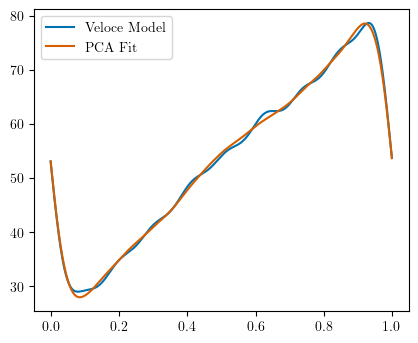

In [53]:
# Plot fit for one of the targets
target_name = "WW Mon"
target_fit = fit_curve_df[fit_curve_df["NAME"] == target_name]["LS_RESULT"].iloc[0]
width = 3.46 * 1.4
height = width * 1.618 / 2
fig, ax = plt.subplots(figsize=(width, height))
ax.plot(target_fit.x, target_fit.y, "-", label="Veloce Model", color=color_safe["blue"])
ax.plot(
    phase_grid,
    target_fit.evaluate(phase_grid),
    label="PCA Fit",
    color=color_safe["dark_orange"],
)
ax.legend()

In [54]:
fit_curve_train_df = fit_curve_df[fit_curve_df["SET"] == "train"]
fit_curve_test_df = fit_curve_df[fit_curve_df["SET"] == "test"]

In [55]:
def plot_six_targets_rv_panel(
    names: list[str],
) -> Figure:
    """Create a 3x2 panel showing RV curves for six targets."""
    if len(names) != 6:
        msg = f"Exactly 6 target names required, got {len(names)}"
        raise ValueError(msg)

    width = 3.46 * 2.0
    height = width / 1.618 * 1.5
    fig, axs_grid = plt.subplots(
        3,
        2,
        figsize=(width, height),
        sharex=True,
        gridspec_kw={"hspace": 0, "wspace": 0.05},
    )

    for i, (ax, name) in enumerate(zip(axs_grid.flat, names)):
        row, col = divmod(i, 2)

        header_row = veloce_headers[veloce_headers["NAME"] == name].iloc[0]
        fit_row = veloce_fit[veloce_fit["NAME"] == name].iloc[0]
        period = header_row["P"]
        epoch = header_row["E"]
        set_type = header_row["SET"]
        log_p = np.log10(period)

        # ── VELOCE Fourier series (sampled) ───────────────────────────────────
        dataset_row = dataset[dataset["NAME"] == name].iloc[0]
        veloce_sampled = dataset_row["SAMPLE"] + fit_row["VGAMMA"]
        ax.plot(
            phase_grid,
            veloce_sampled,
            "-",
            color=color_safe["pink"],
            lw=1.8,
            label=r"$\texttt{V}^{FS}$",
            zorder=2,
        )

        # ── PCA fit to sampled VELOCE curve (fit_curve) ───────────────────────
        # fit_curve_rows = fit_curve_df[fit_curve_df["NAME"] == name]
        # if len(fit_curve_rows) > 0:
        #     ax.plot(
        #         phase_grid,
        #         fit_curve_rows["LS_RESULT"].iloc[0].evaluate(phase_grid),
        #         "--",
        #         color=color_safe["dark_orange"],
        #         lw=1.8,
        #         label=r"$\mathcal{M}$",
        #         zorder=3,
        #     )

        # ── PCA fit to RV observations (fit_rv) ───────────────────────────────
        fit_rv_rows = fit_rv_df[fit_rv_df["NAME"] == name]
        if len(fit_rv_rows) > 0:
            ax.plot(
                phase_grid,
                fit_rv_rows["LS_RESULT"].iloc[0].evaluate(phase_grid),
                "-.",
                color=color_safe["light_green"],
                lw=1.8,
                label=r"$\mathcal{M}_\mathrm{RV}$",
                zorder=4,
            )
        # fit_curve_rows = fit_curve_df[fit_curve_df["NAME"] == name]
        # if len(fit_curve_rows) > 0:
        #     ax.plot(
        #         phase_grid,
        #         fit_curve_rows["LS_RESULT"].iloc[0].evaluate(phase_grid),
        #         "-.",
        #         color=color_safe["light_blue"],
        #         lw=1.8,
        #         label=r"$\mathcal{M}_\mathrm{RV}$",
        #         zorder=4,
        #     )
        # ── RV observations ────────────────────────────────────────────────────
        target_data = veloce_data[(veloce_data["NAME"] == name) & (veloce_data["MASK"])]
        bjd = target_data["BJD"].to_numpy()
        rv = target_data["RV"].to_numpy().copy()
        rv_err = target_data["RV_ERR"].to_numpy()

        if isinstance(fit_row["POLY_COEFFS"], np.ndarray):
            trend_model = vf.model.PolynomialBasis(int(header_row["POLYDEG"]))
            rv -= trend_model.evaluate(fit_row["POLY_COEFFS"], bjd - epoch)

        phase = vf.model.calculate_phase(bjd, period, epoch)
        ax.errorbar(
            phase,
            rv,
            yerr=rv_err,
            fmt=".",
            markersize=2,
            color=color_safe["black"],
            elinewidth=0.5,
            capsize=0,
            zorder=0,
            label="RV meas.",
        )
        ax.scatter(
            phase,
            rv,
            s=10,
            color=color_safe["black"],
            zorder=1,
        )

        # ── X-axis: shared, ticks set once, labels only on bottom row ─────────
        if i == 0:
            x_ticks = [0, 0.25, 0.5, 0.75, 1]
            x_ticks_minor = np.arange(0, 1.05, 0.05)
        vf.plot.format_xticks(ax, x_ticks, x_ticks_minor)
        ax.set_xlim(0, 1)
        if row == 2:

            def fmt(x: float, pos) -> str:
                return f"{x:g}" if x == int(x) else f"{x:.2f}"

            ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(fmt))
            ax.set_xlabel(r"$\phi$", fontsize=label_size)
        else:
            ax.tick_params(labelbottom=False)

        # ── Y-axis: right side for right column ───────────────────────────────
        if col == 1:
            ax.yaxis.set_label_position("right")
            ax.yaxis.tick_right()
        ylims = ax.get_ylim()
        diff_ylim = ylims[1] - ylims[0]
        if diff_ylim < 6:
            y_ticks = np.arange(-200, 200, 1)
            y_ticks_minor = np.arange(-200, 200, 0.5)
        if diff_ylim >= 6:
            y_ticks = np.arange(-200, 200, 2)
            y_ticks_minor = np.arange(-200, 200, 0.5)
        if diff_ylim >= 15:
            y_ticks = np.arange(-200, 200, 5)
            y_ticks_minor = np.arange(-200, 200, 1)
        if diff_ylim >= 20:
            y_ticks = np.arange(-200, 200, 10)
            y_ticks_minor = np.arange(-200, 200, 2)

        vf.plot.format_yticks(ax, y_ticks, y_ticks_minor)
        ax.set_ylim(*ylims)
        ax.set_ylabel(r"RV [km\,s$^{-1}$]", fontsize=label_size)

        # ── Upper-left annotation ──────────────────────────────────────────────
        set_str = "Training" if set_type == "train" else "Test"
        annotation = (
            f"{name}\n"
            f"$P = {period:.3f}$ d\n"  # ($\\log P = {log_p:.3f}$)\n"
            f"{set_str} Set"
        )
        ax.text(
            0.05,
            0.95,
            annotation,
            transform=ax.transAxes,
            fontsize=label_size - 1,
            ha="left",
            va="top",
            linespacing=1.5,
        )

        if i == 0:
            ax.legend(fontsize=label_size - 2, loc="lower right")

    fig.tight_layout()
    return fig

/var/folders/hm/6rf5cwbj6x74z7zlmzpbdwx80000gn/T/ipykernel_18209/3040733343.py:169: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


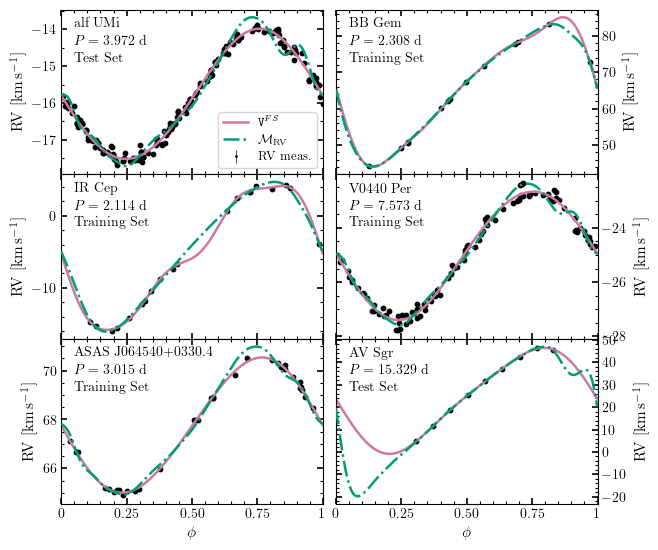

In [56]:
_ = plot_six_targets_rv_panel(
    ["alf UMi", "BB Gem", "IR Cep", "V0440 Per", "ASAS J064540+0330.4", "AV Sgr"]
)

/var/folders/hm/6rf5cwbj6x74z7zlmzpbdwx80000gn/T/ipykernel_42578/3040733343.py:169: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()
/var/folders/hm/6rf5cwbj6x74z7zlmzpbdwx80000gn/T/ipykernel_42578/3789842608.py:4: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  ff.tight_layout()


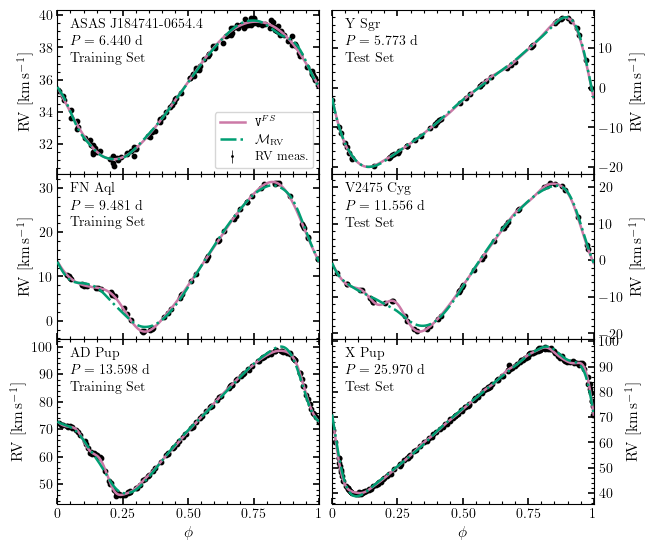

In [63]:
ff = plot_six_targets_rv_panel(
    ["ASAS J184741-0654.4", "Y Sgr", "FN Aql", "V2475 Cyg", "AD Pup", "X Pup"]
)
ff.tight_layout()
ff.savefig(saving_dir / "examples_M_RV.pdf", format="pdf")

In [64]:
veloce_headers.sort_values(by="PEAK2PEAK")[["NAME", "PEAK2PEAK", "N_RV"]].head(15)

,NAME,PEAK2PEAK,N_RV
213,alf UMi,3.525673,186
163,V0440 Per,4.730894,103
11,ASAS J064540+0330.4,5.540233,46
179,V1726 Cyg,8.194257,27
23,ASAS J155847-5341.8,8.258219,57
31,ASAS J184741-0654.4,8.578761,122
178,V1334 Cyg,8.613204,68
91,MY Pup,8.925775,82
26,ASAS J174108-2328.5,10.346666,17
40,BG Cru,10.630597,127


### KDE and Prior definition 

In [65]:
# pc_names = pca_puls_model.param_names
# components_df = pd.DataFrame(
#     {
#         "NAME": fit_rv_no_outliers["NAME"].to_numpy(),
#         "SET": fit_rv_no_outliers["SET"].to_numpy(),
#         "log_P": np.log10(fit_rv_no_outliers["P"].to_numpy()),
#         "v_gamma": fit_rv_no_outliers["VGAMMA"].to_numpy(),
#         **{
#             pc: [r.theta_free[i + 1] for r in fit_rv_no_outliers["LS_RESULT"]]
#             for i, pc in enumerate(pc_names)
#         },
#     },
# )

In [57]:
if "P" not in fit_curve_df.columns:
    fit_curve_df = fit_curve_df.merge(fit_rv_df[["NAME", "P"]], on="NAME", how="left")
pc_names = pca_puls_model.param_names
components_df = pd.DataFrame(
    {
        "NAME": fit_curve_df["NAME"].to_numpy(),
        "SET": fit_curve_df["SET"].to_numpy(),
        "log_P": np.log10(fit_curve_df["P"].to_numpy()),
        "v_gamma": fit_curve_df["VGAMMA"].to_numpy(),
        **{
            pc: [r.theta_free[i + 1] for r in fit_curve_df["LS_RESULT"]]
            for i, pc in enumerate(pc_names)
        },
    },
)

In [58]:
components_train_df = components_df[components_df["SET"] == "train"]
components_test_df = components_df[components_df["SET"] == "test"]

In [59]:
kde_comps = vf.prior.KDEDensity(["log_P", *pc_names], bw="cv_ml").fit(
    components_train_df
)

/Users/odysseus/projects/veloce-framework/.venv/lib/python3.14/site-packages/statsmodels/nonparametric/kernel_density.py:158: RuntimeWarning: divide by zero encountered in log
  L += func(f_i)


In [60]:
kde_comps._kde.bw

array([ 0.05363828, 24.60914579, 12.48429651, 15.0173422 ,  7.88722543,
        8.32725062,  5.31419774])

In [ ]:
array(
    [
        0.05363828,
        24.59683814,
        12.4780528,
        15.00983165,
        7.88328083,
        8.32308595,
        5.31153999,
    ]
)

In [70]:
kde_comps._kde.bw

array([ 0.05363828, 24.59683814, 12.4780528 , 15.00983165,  7.88328083,
        8.32308595,  5.31153999])

In [61]:
components_train_df

,NAME,SET,log_P,v_gamma,pc1,pc2,pc3,pc4,pc5,pc6
0,AA Gem,train,1.053221,19.608128,0.642438,115.643134,-92.634911,-18.724983,-20.579065,25.232500
1,AB Cam,train,0.762497,-43.980467,83.025120,0.854489,119.348575,-40.406935,-29.143693,-10.895199
2,AC Mon,train,0.903903,60.494239,12.911265,40.511442,101.344261,4.790774,39.879349,12.254140
3,AD Pup,train,1.133462,72.908471,119.393769,161.370467,-85.354746,-74.071852,11.419948,11.215111
4,AH Vel,train,0.626049,26.814592,-140.365155,-39.224598,-32.805303,0.481616,-9.653605,0.046782
...,...,...,...,...,...,...,...,...,...,...
211,bet Dor,train,0.993116,8.368772,-64.764551,116.888717,4.264266,57.749061,-12.501687,-19.319549
212,del Cep,train,0.729672,-16.966065,46.112344,-10.273971,71.769340,-25.615106,-19.461497,-9.021743
213,eta Aql,train,0.855933,-14.786917,37.691848,39.492518,96.508483,-24.395162,20.025822,5.592031
214,l Car,train,1.550966,3.423271,49.814464,-37.931466,30.479030,-19.844284,-26.861909,-7.533831


In [62]:
def kde_2d_conditional(
    kde_joint: vf.prior.KDEDensity,
    fixed_vals: dict[str, float],
    free_vars: list[str],
    n_grid: int = 80,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Create the grid for a 2D conditional.

    Evaluate the 2D marginal conditional of a product-kernel KDE.
    fixed_vals : dict {var_name: value} — variables to condition on
    free_vars  : list of 2 var names   — variables to keep free
    Returns (x_grid, y_grid, density_grid).
    """
    data = kde_joint._kde.data  # (n_train, n_vars)  # noqa: SLF001
    bw = kde_joint._kde.bw  # (n_vars,) # noqa: SLF001
    names = kde_joint.var_names

    # Kernel weights for fixed variables
    w = np.ones(data.shape[0])
    for name, val in fixed_vals.items():
        j = names.index(name)
        w *= sp.stats.norm.pdf((val - data[:, j]) / bw[j])
    w /= w.sum()

    # Grid over free variables
    ix, iy = names.index(free_vars[0]), names.index(free_vars[1])
    lo_x, hi_x = kde_joint.domain[free_vars[0]]
    lo_y, hi_y = kde_joint.domain[free_vars[1]]
    gx = np.linspace(lo_x, hi_x, n_grid)
    gy = np.linspace(lo_y, hi_y, n_grid)
    gx_mesh, gy_mesh = np.meshgrid(gx, gy)

    # Weighted KDE on the 2D grid
    dx = (gx_mesh[..., None] - data[:, ix]) / bw[ix]  # (n_grid, n_grid, n_train)
    dy = (gy_mesh[..., None] - data[:, iy]) / bw[iy]
    density = ((sp.stats.norm.pdf(dx) * sp.stats.norm.pdf(dy)) * w).sum(axis=-1)

    return gx, gy, density


def kde_1d_marginal_conditional(
    kde_joint: vf.prior.KDEDensity,
    fixed_vals: dict[str, float],
    free_var: str,
    n_grid: int = 500,
) -> tuple[np.ndarray, np.ndarray]:
    """1-D marginal conditional p(free_var | fixed_vals).

    Conditions on fixed_vals by re-weighting kernel contributions,
    then marginalises over all remaining variables — consistent with
    how kde_2d_conditional treats the off-diagonal panels.
    """
    data = kde_joint._kde.data  # (n_train, n_vars)  # noqa: SLF001
    bw = kde_joint._kde.bw  # (n_vars,)           # noqa: SLF001
    names = kde_joint.var_names

    w = np.ones(data.shape[0])
    for name, val in fixed_vals.items():
        j = names.index(name)
        w *= sp.stats.norm.pdf((val - data[:, j]) / bw[j])
    w /= w.sum()

    ix = names.index(free_var)
    lo, hi = kde_joint.domain[free_var]
    g = np.linspace(lo, hi, n_grid)

    dx = (g[:, None] - data[:, ix]) / bw[ix]  # (n_grid, n_train)
    density = (sp.stats.norm.pdf(dx) * w).sum(axis=-1)

    return g, density


def plot_corner_kde(
    kde_joint: vf.prior.KDEDensity,
    data_df: pd.DataFrame,
    log_p_values: list[float],
    pc_names: list[str],
) -> None:
    """Corner plot: 1D diagonal + 2D off-diagonal at each log_P."""
    n = len(pc_names)
    colors = [color_safe["blue"], color_safe["dark_orange"], color_safe["light_green"]]

    fig, axs = plt.subplots(n, n, figsize=(2.5 * n, 2.5 * n))
    for ax in axs.flat:
        ax.set_visible(False)

    for row in range(n):
        for col in range(row + 1):
            ax = axs[row, col]
            ax.set_visible(True)
            pc_x, pc_y = pc_names[col], pc_names[row]

            if row == col:
                # 1D diagonal: conditional density at each log_P
                lo, hi = kde_joint.domain[pc_x]
                g = np.linspace(lo, hi, 500)
                for log_p, c in zip(log_p_values, colors):
                    conditions = {v: 0.0 for v in kde_joint.var_names if v != pc_x}
                    conditions["log_P"] = log_p
                    cond = kde_joint.conditional(**conditions)
                    fast = vf.prior.SplineDensity(cond)
                    ax.plot(
                        g,
                        [np.exp(fast.log_pdf({pc_x: v})) for v in g],
                        color=c,
                        label=f"logP={log_p:.1f}",
                    )
            else:
                # Training data scatter
                ax.scatter(
                    data_df[pc_x],
                    data_df[pc_y],
                    s=4,
                    c="k",
                    alpha=0.3,
                    zorder=1,
                )
                # 2D off-diagonal: contours at each log_P
                for log_p, c in zip(log_p_values, colors, strict=True):
                    gx, gy, dens = kde_2d_conditional(
                        kde_joint,
                        {"log_P": log_p},
                        [pc_x, pc_y],
                    )
                    ax.contour(gx, gy, dens, levels=5, colors=[c], alpha=0.8)

            if col == 0:
                ax.set_ylabel(pc_y)
            if row == n - 1:
                ax.set_xlabel(pc_x)

    fig.tight_layout()


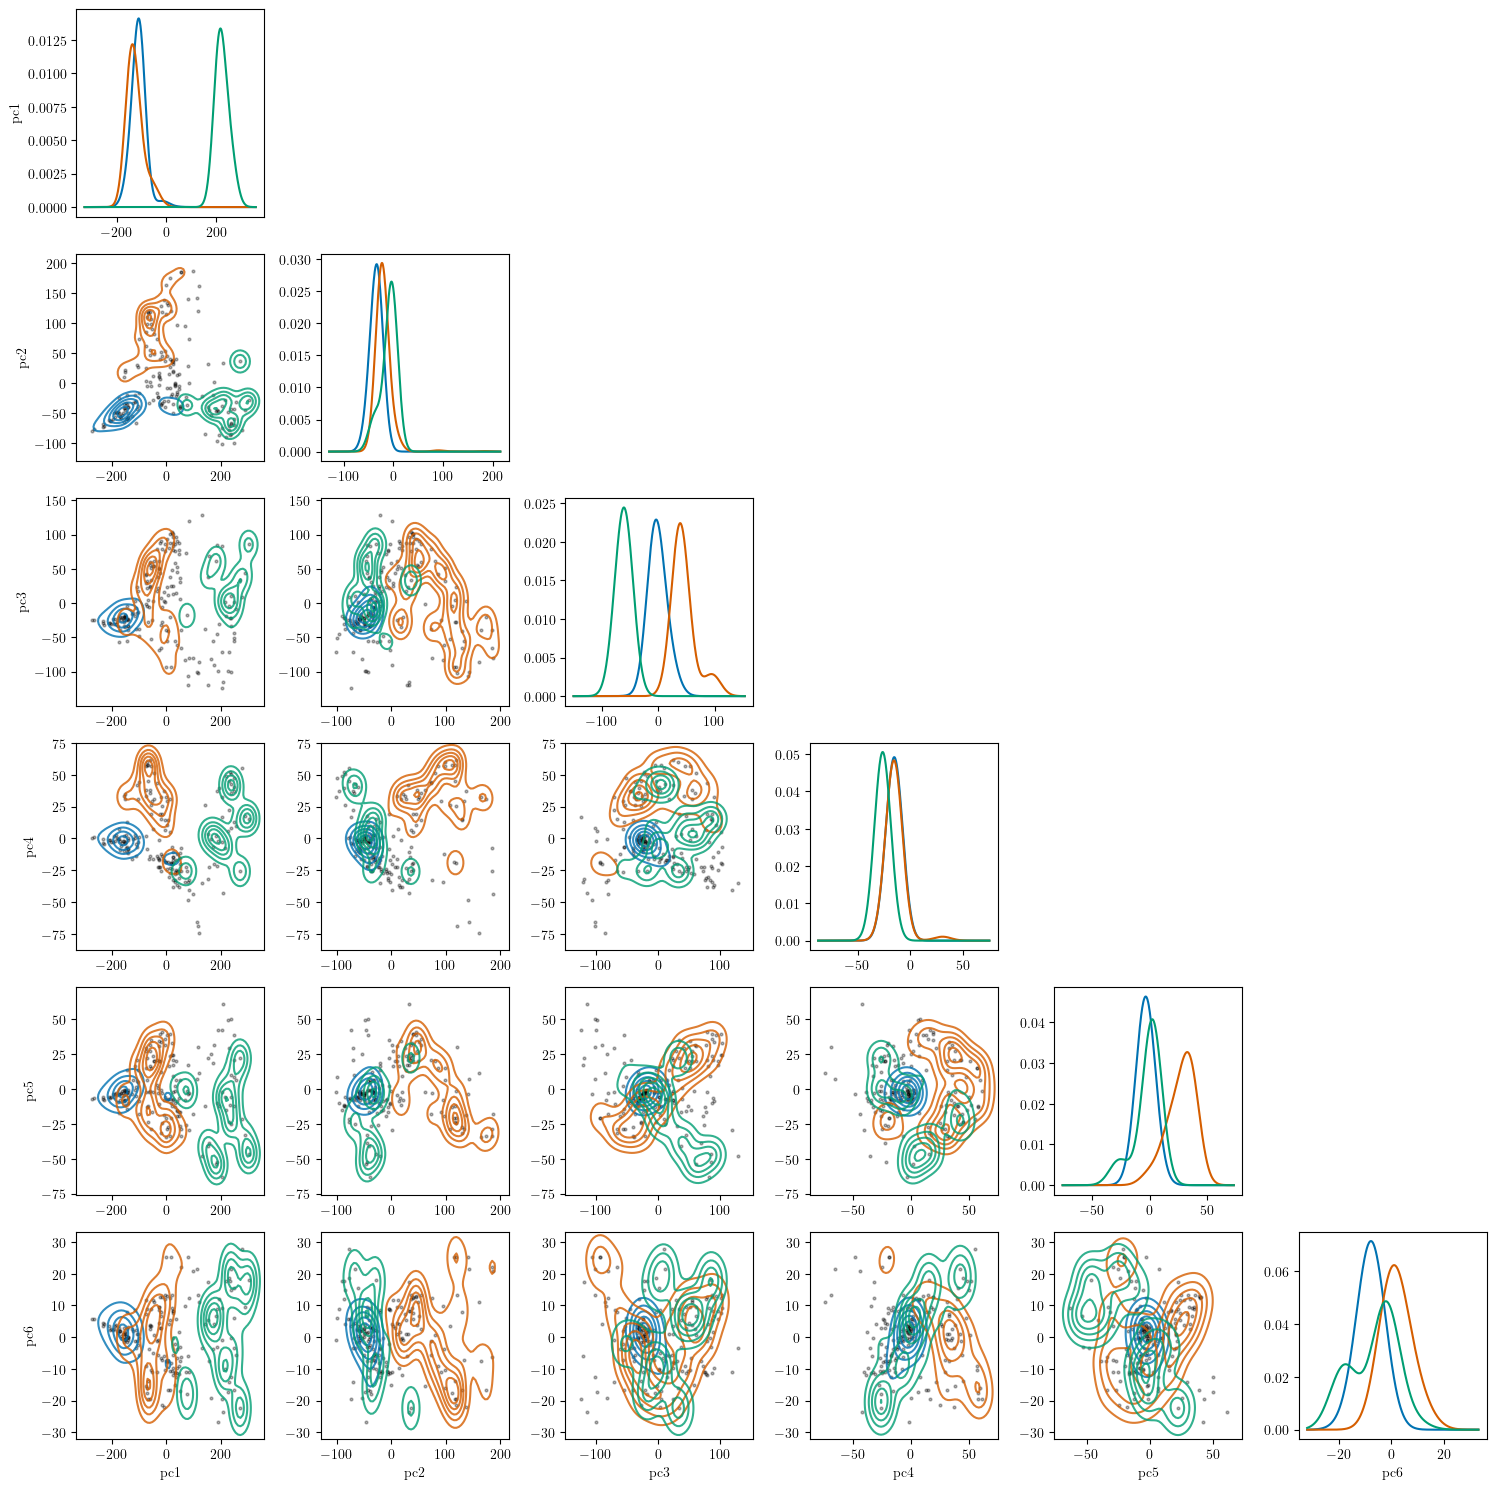

In [63]:
log_p_vals = [0.5, 1, 1.4]  # short, medium, long period
fig = plot_corner_kde(
    kde_comps,
    components_train_df,
    log_p_vals,
    ["pc1", "pc2", "pc3", "pc4", "pc5", "pc6"],
)

In [64]:
def _get_pc_ticks(pc_idx: int) -> tuple[np.ndarray, np.ndarray]:
    """Major and minor tick values for each PC (index 0–5)."""
    if pc_idx == 0:
        return np.arange(-450, 500, 150), np.arange(-500, 500, 25)
    if pc_idx == 1:
        return np.arange(-200, 400, 50), np.arange(-200, 400, 10)
    if pc_idx == 2:
        return np.arange(-200, 150, 50), np.arange(-200, 400, 10)
    if pc_idx == 3:
        return np.arange(-200, 200, 40), np.arange(-200, 200, 10)
    if pc_idx == 4:
        return np.arange(-200, 200, 20), np.arange(-200, 200, 5)
    return np.arange(-100, 100, 10), np.arange(-100, 100, 2)

In [65]:
def plot_corner_kde(
    kde_joint: vf.prior.KDEDensity,
    data_df: pd.DataFrame,
    log_p_values: list[float],
    pc_names: list[str],
    test_df: pd.DataFrame | None = None,
    pc_labels: dict[str, str] | None = None,
) -> Figure:
    """Corner plot: 1-D diagonal + 2-D off-diagonal, coloured by log P.

    Diagonal: marginal conditional density of each coefficient at each log_P.
    Off-diagonal: 2-D conditional iso-density contours at each log_P,
    overlaid with training data (circles) and optional test data (triangles),
    all coloured by log_P via viridis.
    """
    n = len(pc_names)
    labels = pc_labels or {name: name for name in pc_names}

    # ── Colormap ──────────────────────────────────────────────────────────────
    cmap = plt.cm.gnuplot2
    all_logp = data_df["log_P"].to_numpy()
    if test_df is not None:
        all_logp = np.concatenate([all_logp, test_df["log_P"].to_numpy()])
    norm = mpl.colors.Normalize(vmin=all_logp.min(), vmax=all_logp.max())
    # norm = mpl.colors.Normalize(vmin=0.2, vmax=1.6)

    # ── Figure ────────────────────────────────────────────────────────────────
    fig, axs = plt.subplots(
        n,
        n,
        figsize=(2.5 * n, 2.5 * n),
        gridspec_kw={"hspace": 0, "wspace": 0},
    )
    for ax in axs.flat:
        ax.set_visible(False)

    for row in range(n):
        for col in range(row + 1):
            ax = axs[row, col]
            ax.set_visible(True)
            pc_x, pc_y = pc_names[col], pc_names[row]
            is_bottom = row == n - 1
            is_left = col == 0

            if row == col:
                for log_p in log_p_values:
                    g, density = kde_1d_marginal_conditional(
                        kde_joint,
                        {"log_P": log_p},
                        pc_x,
                    )
                    ax.plot(
                        g,
                        density,
                        color=cmap(norm(log_p)),
                        lw=1.0,
                        label=f"$\\log P = {log_p:.1f}$",
                    )
                ax.tick_params(left=False, labelleft=False)
                if row == 0:
                    ax.legend(
                        fontsize=label_size + 5,
                        frameon=False,
                        bbox_to_anchor=(1.1, 0.5),
                        loc="upper left",
                    )
            else:
                # ── Off-diagonal: scatter + 2-D contours ──────────────────────
                ax.scatter(
                    data_df[pc_x],
                    data_df[pc_y],
                    c=data_df["log_P"],
                    cmap=cmap,
                    norm=norm,
                    s=20,
                    marker="o",
                    alpha=0.7,
                    edgecolors="k",
                    linewidths=0.5,
                    zorder=1,
                )
                if test_df is not None:
                    ax.scatter(
                        test_df[pc_x],
                        test_df[pc_y],
                        c=test_df["log_P"],
                        cmap=cmap,
                        norm=norm,
                        s=30,
                        marker="^",
                        alpha=0.9,
                        edgecolors="k",
                        linewidths=0.7,
                        zorder=2,
                    )
                for log_p in log_p_values:
                    gx, gy, dens = kde_2d_conditional(
                        kde_joint,
                        {"log_P": log_p},
                        [pc_x, pc_y],
                    )
                    ax.contour(
                        gx,
                        gy,
                        dens,
                        levels=5,
                        colors=[cmap(norm(log_p))],
                        alpha=0.85,
                        linewidths=0.8,
                    )
                # Y-axis ticks; label only on leftmost column
                major_y, minor_y = _get_pc_ticks(row)
                vf.plot.format_yticks(ax, major_y, minor_y, label_size=13)
                ax.set_ylim(*kde_joint.domain[pc_y])
                if not is_left:
                    ax.tick_params(labelleft=False)
                else:
                    ax.set_ylabel(labels.get(pc_y, pc_y), fontsize=label_size + 5)

            # X-axis ticks; label only on bottom row (shared across row/col)
            major_x, minor_x = _get_pc_ticks(col)
            vf.plot.format_xticks(ax, major_x, minor_x, label_size=13)
            ax.set_xlim(*kde_joint.domain[pc_x])
            if not is_bottom:
                ax.tick_params(labelbottom=False)
            else:
                ax.set_xlabel(labels.get(pc_x, pc_x), fontsize=label_size + 5)

    # ── Colorbar — placed inside the top-right unused area ────────────────────
    pos = axs[1, 2].get_position()
    cbar_ax = fig.add_axes(
        [
            pos.x0 + pos.width * 0.15,
            pos.y0 + pos.height * 0.60,
            pos.width * 0.15,
            pos.height * 1.80,
        ]
    )
    sm = mpl.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, cax=cbar_ax)
    cbar.set_ticks(np.arange(0.4, 2, 0.2))
    cbar.set_ticklabels([f"{lp:.1f}" for lp in np.arange(0.4, 2, 0.2)])
    cbar.set_label(r"$\log P$", fontsize=label_size + 4)

    return fig

[ 3.98107171 10.         25.11886432]


/var/folders/hm/6rf5cwbj6x74z7zlmzpbdwx80000gn/T/ipykernel_18209/3597346689.py:18: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


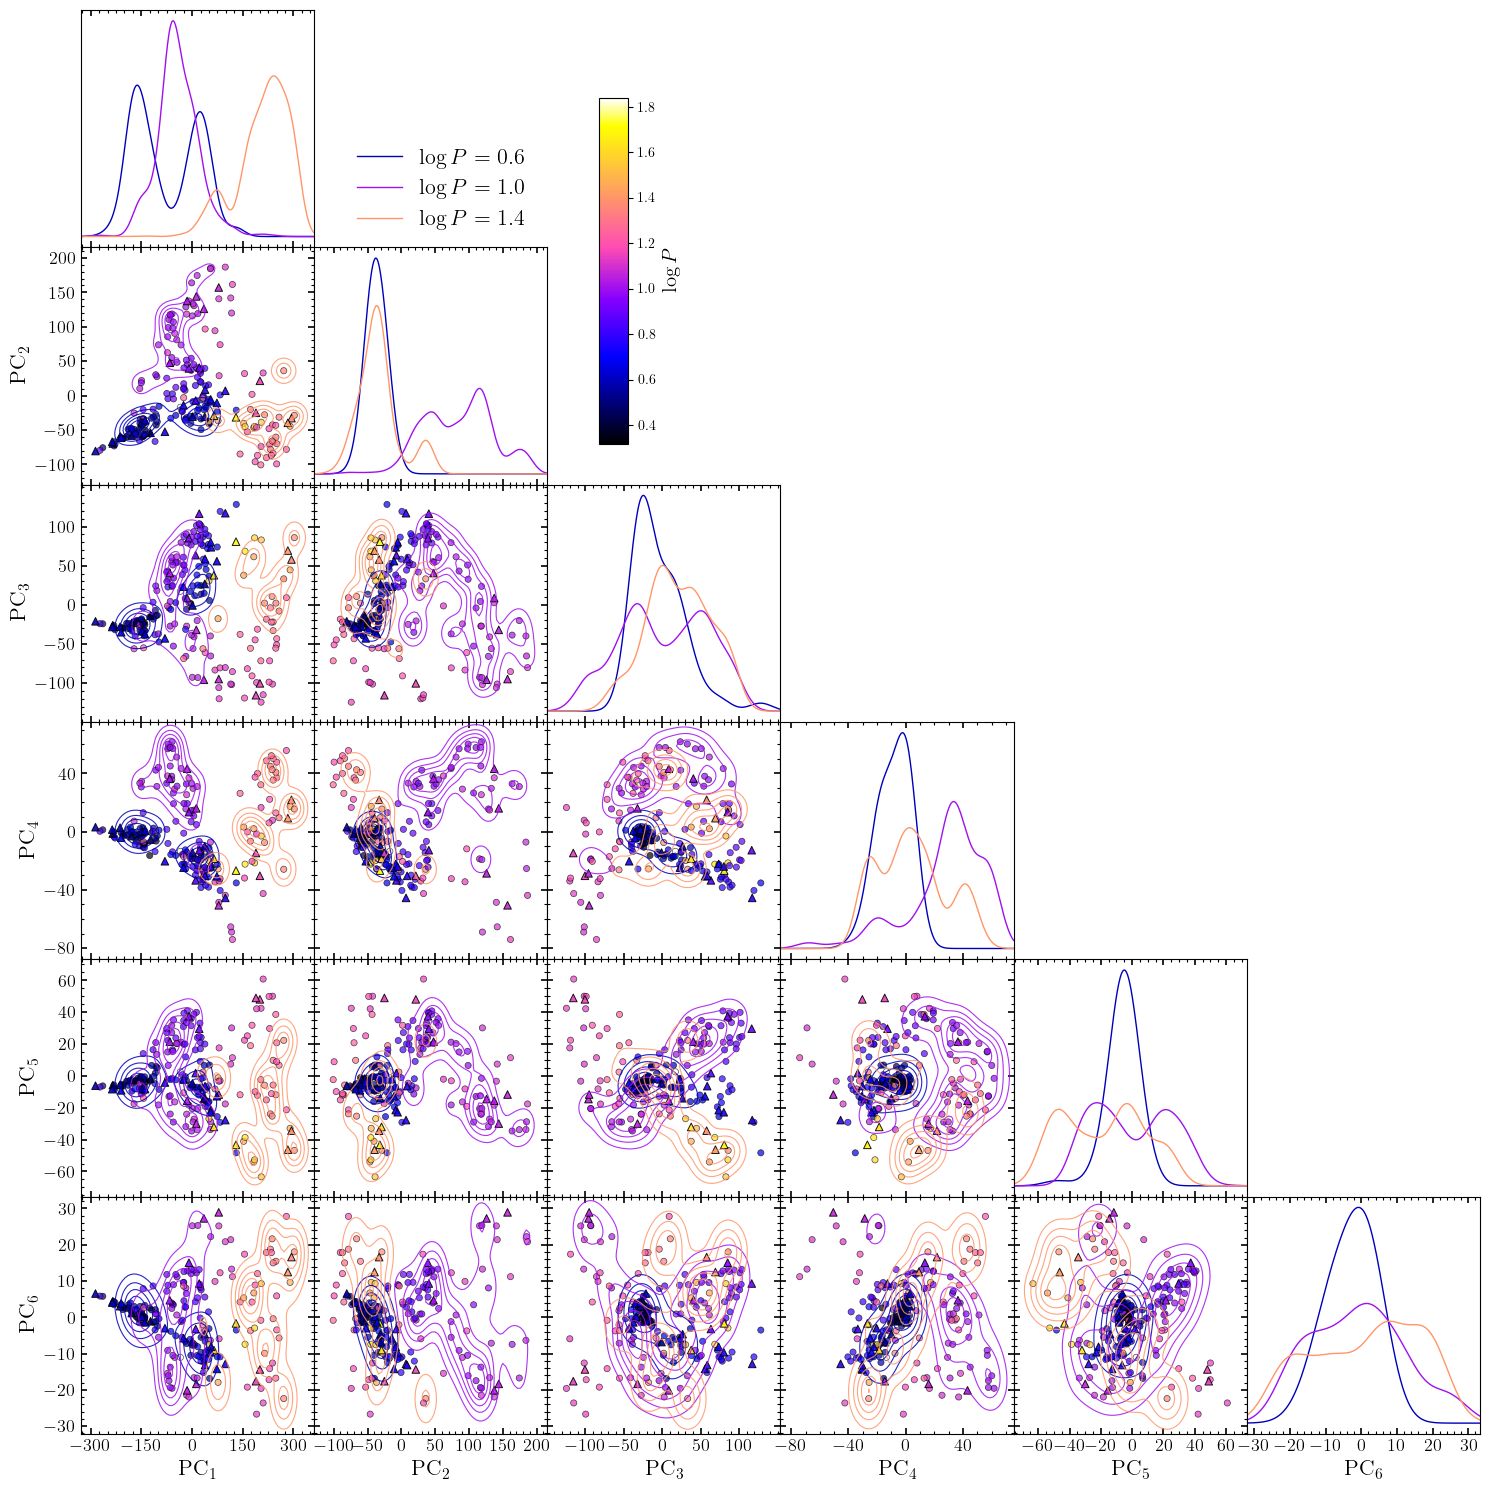

In [66]:
log_p_vals = [0.6, 1, 1.4]
print(np.pow(10, log_p_vals))
fig = plot_corner_kde(
    kde_comps,
    components_train_df,
    log_p_vals,
    ["pc1", "pc2", "pc3", "pc4", "pc5", "pc6"],
    test_df=components_test_df,
    pc_labels={
        "pc1": r"$\rm PC_1$",
        "pc2": r"$\rm PC_2$",
        "pc3": r"$\rm PC_3$",
        "pc4": r"$\rm PC_4$",
        "pc5": r"$\rm PC_5$",
        "pc6": r"$\rm PC_6$",
    },
)
fig.tight_layout()
fig.savefig(saving_dir / "joint_probability_kde.pdf", format="pdf")

In [67]:
components_train_df

,NAME,SET,log_P,v_gamma,pc1,pc2,pc3,pc4,pc5,pc6
0,AA Gem,train,1.053221,19.608128,0.642438,115.643134,-92.634911,-18.724983,-20.579065,25.232500
1,AB Cam,train,0.762497,-43.980467,83.025120,0.854489,119.348575,-40.406935,-29.143693,-10.895199
2,AC Mon,train,0.903903,60.494239,12.911265,40.511442,101.344261,4.790774,39.879349,12.254140
3,AD Pup,train,1.133462,72.908471,119.393769,161.370467,-85.354746,-74.071852,11.419948,11.215111
4,AH Vel,train,0.626049,26.814592,-140.365155,-39.224598,-32.805303,0.481616,-9.653605,0.046782
...,...,...,...,...,...,...,...,...,...,...
211,bet Dor,train,0.993116,8.368772,-64.764551,116.888717,4.264266,57.749061,-12.501687,-19.319549
212,del Cep,train,0.729672,-16.966065,46.112344,-10.273971,71.769340,-25.615106,-19.461497,-9.021743
213,eta Aql,train,0.855933,-14.786917,37.691848,39.492518,96.508483,-24.395162,20.025822,5.592031
214,l Car,train,1.550966,3.423271,49.814464,-37.931466,30.479030,-19.844284,-26.861909,-7.533831


In [68]:
# Photometric delta phase: 1D KDE over all bands and all training stars
train_names = set(components_train_df["NAME"])
phot_phase_train = photometric_delta_phase[
    photometric_delta_phase["NAME"].isin(train_names)
]
kde_phot_phase = vf.prior.KDEDensity(["log_P", "DELTA_PHASE"], bw="cv_ml").fit(
    phot_phase_train[phot_phase_train["BAND"] == "G"],
)

/Users/odysseus/projects/veloce-framework/.venv/lib/python3.14/site-packages/statsmodels/nonparametric/kernel_density.py:158: RuntimeWarning: invalid value encountered in log
  L += func(f_i)


In [69]:
def plot_2d_kde(  # noqa: PLR0913
    kde: vf.prior.KDEDensity,
    data: pd.DataFrame,
    ax: Axes | None = None,
    n_grid: int = 80,
    cmap: str = "Greys",
    scatter_kw: dict | None = None,
    test_data: pd.DataFrame | None = None,
    test_scatter_kw: dict | None = None,
) -> Axes:
    """Plot 2-D KDE density.

    Parameters
    ----------
    kde :
        A fitted 2-D ``KDEDensity``.
    data :
        Training data (must contain the KDE's variable columns).
    ax :
        Existing axes to draw on. A new figure is created if ``None``.
    n_grid :
        Grid resolution for the contour plot.
    cmap :
        Matplotlib colormap for the density contours.
    scatter_kw :
        Extra keyword arguments forwarded to the training-data scatter call.
    test_data :
        Optional held-out data to overlay with a different marker.
    test_scatter_kw :
        Extra keyword arguments for the test-data scatter call.

    Returns
    -------
    Axes

    Raises
    ------
    ValueError
        If the KDE does not have exactly 2 variables.

    """
    if len(kde.var_names) != 2:  # noqa: PLR2004
        msg = f"plot_2d_kde requires a 2-D kde, got {len(kde.var_names)} variables"
        logger.error(msg)
        raise ValueError(msg)

    x_var, y_var = kde.var_names

    if ax is None:
        _, ax = plt.subplots()

    _scatter_kw = {"s": 18, "marker": "o", "edgecolors": "k", "lw": 0.8, "zorder": 1}
    if scatter_kw:
        _scatter_kw.update(scatter_kw)
    x_train = data[x_var].to_numpy(dtype=float)
    y_train = data[y_var].to_numpy(dtype=float)
    valid = ~(np.isnan(x_train) | np.isnan(y_train))
    ax.scatter(x_train[valid], y_train[valid], **_scatter_kw)

    # ── Density contour ───────────────────────────────────────────────────────
    x_grid = np.linspace(*kde.domain[x_var], n_grid)
    y_grid = np.linspace(*kde.domain[y_var], n_grid)
    xg, yg = np.meshgrid(x_grid, y_grid, indexing="ij")
    rows = np.column_stack([xg.ravel(), yg.ravel()])
    pdf = kde._pdf_batch(rows).reshape(xg.shape)  # noqa: SLF001
    # pdf_norm = np.array([p / np.max(p) for p in pdf])  # noqa: ERA001
    pdf_norm = np.array([p / sp.integrate.simpson(p, y_grid) for p in pdf])
    pdf_norm = np.array([p - min(p) for p in pdf_norm])
    ax.contourf(
        xg,
        yg,
        pdf_norm,
        levels=25,
        cmap=cmap,
        zorder=0,
        alpha=1,
        vmin=0,
        norm=mpl.colors.PowerNorm(gamma=0.6),
    )
    # ── Test scatter (optional) ───────────────────────────────────────────────
    if test_data is not None:
        _test_kw = {"s": 25, "marker": "^", "edgecolors": "k", "lw": 0.8, "zorder": 3}
        if test_scatter_kw:
            _test_kw.update(test_scatter_kw)
        x_test = test_data[x_var].to_numpy(dtype=float)
        y_test = test_data[y_var].to_numpy(dtype=float)
        valid_test = ~(np.isnan(x_test) | np.isnan(y_test))
        ax.scatter(x_test[valid_test], y_test[valid_test], **_test_kw)

    return ax

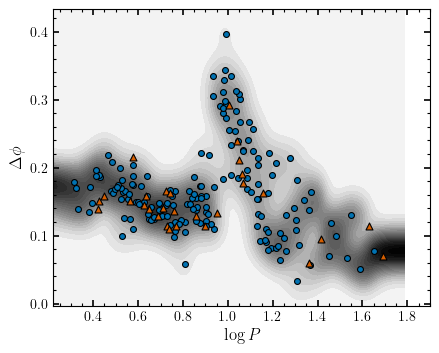

In [70]:
fig, axs = plt.subplots()
width = 3.46 * 1.3
height = width * 1.618 / 2
fig.set_size_inches(width, height)


axs = plot_2d_kde(
    kde_phot_phase,
    phot_phase_train[phot_phase_train["BAND"] == "G"],
    ax=axs,
    n_grid=300,
    cmap="Greys",
    scatter_kw={"c": color_safe["blue"]},
    test_data=photometric_delta_phase[
        (photometric_delta_phase["NAME"].isin(set(components_test_df["NAME"])))
        & (photometric_delta_phase["BAND"] == "G")
    ],
    test_scatter_kw={"c": color_safe["dark_orange"]},
)

# Set x-axis ticks and label
x_ticks = np.arange(0.2, 2, 0.2)
x_ticks_minor = np.arange(0.2, 2, 0.05)
xlims = [0.22, 1.9]
vf.plots_utils.format_xticks(axs, x_ticks, x_ticks_minor)
axs.set_xlim(*xlims)
axs.set_xlabel(r"$\log P$", fontsize=12)

# Set y-axis ticks and labels
y_ticks = np.arange(0, 0.5, 0.1)
y_ticks_minor = np.arange(0, 0.45, 0.02)
ylims = axs.get_ylim()
vf.plots_utils.format_yticks(axs, y_ticks, y_ticks_minor)
axs.set_ylim(*kde_phot_phase.domain["DELTA_PHASE"])
axs.set_ylabel(r"$\Delta\phi$", fontsize=12)

fig.tight_layout()
fig.savefig(saving_dir / "delta_phase_prior.pdf", format="pdf")

In [71]:
kde_comps.domain

{'log_P': (0.1622223686372001, 1.9907206025129691),
 'pc1': (-330.1383596324145, 359.95404128278653),
 'pc2': (-129.52515490938777, 215.3538870260668),
 'pc3': (-149.69645560435922, 153.55437654247757),
 'pc4': (-87.64606351192342, 75.24447863256),
 'pc5': (-75.76786832031887, 73.20095634197087),
 'pc6': (-32.11609725138067, 33.27458688139959)}

In [ ]:
{
    "log_P": (0.1622223686372001, 1.9907206025129691),
    "pc1": (-329.97324919786377, 359.774019235304),
    "pc2": (-129.46037609676557, 215.2461831354692),
    "pc3": (-149.62158867717898, 153.47758023726095),
    "pc4": (-87.602228931231, 75.20684691378963),
    "pc5": (-75.72997509640034, 73.16434668077065),
    "pc6": (-32.10003532902044, 33.257946311032796),
}

In [72]:
kde_phot_phase.domain

{'log_P': (0.1808972949621273, 1.78529641293877),
 'DELTA_PHASE': (-0.002799820504393667, 0.43292409108118146)}

In [ ]:
{
    "log_P": (0.1808972949621273, 1.78529641293877),
    "DELTA_PHASE": (-0.002799820504393667, 0.43292409108118146),
}

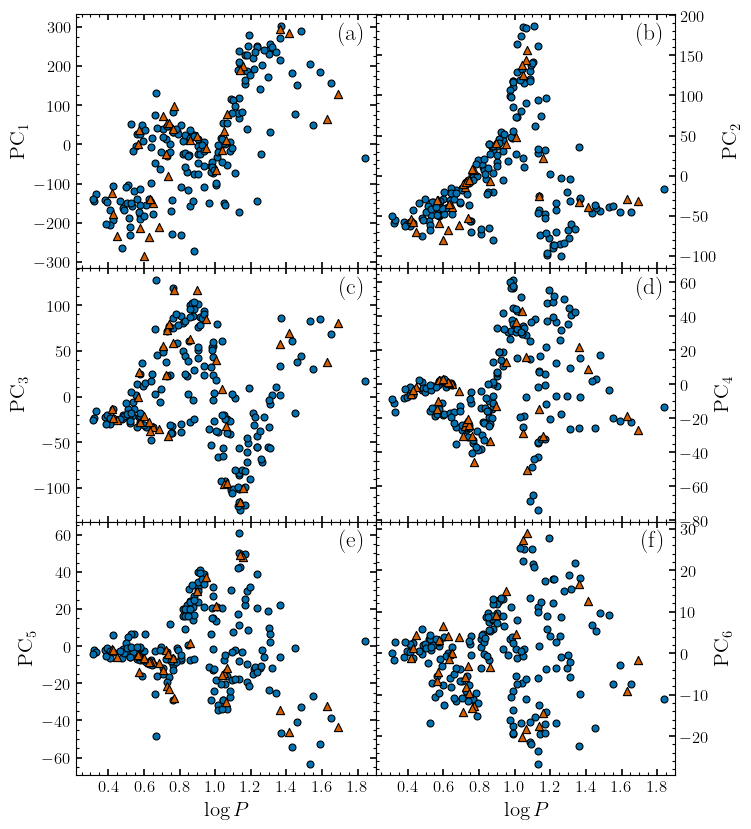

In [73]:
# Set the number of figures
n_rows = len(pc_names) // 2
n_rows += 1 if len(pc_names) % 2 == 1 else 0
fig, axs = plt.subplots(
    n_rows,
    2,
    sharex=True,
    gridspec_kw={"hspace": 0, "wspace": 0},
)
width = 3.46 * 2.2
height = width * 1.618 / 2 * n_rows / 2.2  # / 2
fig.set_size_inches(width, height)
x_ticks = np.arange(0.2, 2, 0.2)
x_ticks_minor = np.arange(0.2, 2, 0.05)
xlims = [0.22, 1.9]

# Color
panels = ["a", "b", "c", "d", "e", "f"]
# kde_names = [f"pc{i}" for i in range(1, len(pc_names) + 1)]
scatter_kw = {"c": color_safe["blue"]}
test_scatter_kw = {"c": color_safe["dark_orange"]}

for i, pc_name in enumerate(pc_names):
    ax = axs.flat[i]
    ax.text(
        0.97,
        0.97,
        f"({panels[i]})",
        transform=ax.transAxes,
        fontsize=label_size + 6,
        ha="right",
        va="top",
    )

    x_var, y_var = ("log_P", pc_name)

    _scatter_kw = {"s": 25, "marker": "o", "edgecolors": "k", "lw": 0.8, "zorder": 1}
    if scatter_kw:
        _scatter_kw.update(scatter_kw)
    x_train = components_train_df[x_var].to_numpy(dtype=float)
    y_train = components_train_df[y_var].to_numpy(dtype=float)
    valid = ~(np.isnan(x_train) | np.isnan(y_train))
    ax.scatter(x_train[valid], y_train[valid], **_scatter_kw)
    # x_train_fs = components_train_df_fs[x_var].to_numpy(dtype=float)
    # y_train_fs = components_train_df_fs[y_var].to_numpy(dtype=float)
    # valid_fs = ~(np.isnan(x_train_fs) | np.isnan(y_train_fs))
    # ax.scatter(x_train_fs[valid_fs], y_train_fs[valid_fs], c=color_safe["light_green"])
    if components_test_df is not None:
        _test_kw = {"s": 35, "marker": "^", "edgecolors": "k", "lw": 0.8, "zorder": 3}
        if test_scatter_kw:
            _test_kw.update(test_scatter_kw)
        x_test = components_test_df[x_var].to_numpy(dtype=float)
        y_test = components_test_df[y_var].to_numpy(dtype=float)
        valid_test = ~(np.isnan(x_test) | np.isnan(y_test))

        ax.scatter(x_test[valid_test], y_test[valid_test], **_test_kw)
    # ax = plot_2d_kde(
    #     kde,
    #     components_train_df,
    #     ax=ax,
    #     n_grid=300,
    #     cmap="Greys",
    #     scatter_kw=scatter_kw,
    #     test_data=components_test_df,
    #     test_scatter_kw=test_scatter_kw,
    # )

    # Set x-axis ticks and label
    vf.plots_utils.format_xticks(ax, x_ticks, x_ticks_minor, label_size=12)
    ax.set_xlim(*xlims)

    # Set y-axis ticks and labels
    if i % 2 == 1:
        ax.yaxis.set_label_position("right")
        ax.yaxis.tick_right()

    ylims = ax.get_ylim()
    if i == 0:
        y_ticks = np.arange(-500, 500, 100)
        y_ticks_minor = np.arange(-500, 500, 25)
    elif i in {1, 2}:
        y_ticks = np.arange(-200, 400, 50)
        y_ticks_minor = np.arange(-200, 400, 10)
    elif i in {3, 4}:
        y_ticks = np.arange(-200, 200, 20)
        y_ticks_minor = np.arange(-200, 200, 5)
    elif i == 5:  # noqa: PLR2004
        y_ticks = np.arange(-100, 100, 10)
        y_ticks_minor = np.arange(-100, 100, 2)
        ylim = (ylim[0], ylim[1] + 3)
    else:
        pass

    vf.plots_utils.format_yticks(ax, y_ticks, y_ticks_minor, label_size=12)
    ax.set_ylim(*ylims)
    ax.set_ylabel(r"$\rm{PC_" + str(i + 1) + "}$", fontsize=15)

if len(pc_names) % 2 == 1:
    fig.delaxes(axs[-1, -1])

axs[-1, -1].set_xlabel(r"$\log P$", fontsize=15)
axs[2, 0].set_xlabel(r"$\log P$", fontsize=15)
fig.tight_layout()
fig.savefig(saving_dir / "pc_FS_distribution.pdf", format="pdf")

### SAVE PCA and KDE

In [74]:
components_df

,NAME,SET,log_P,v_gamma,pc1,pc2,pc3,pc4,pc5,pc6
0,AA Gem,train,1.053221,19.608128,0.642438,115.643134,-92.634911,-18.724983,-20.579065,25.232500
1,AB Cam,train,0.762497,-43.980467,83.025120,0.854489,119.348575,-40.406935,-29.143693,-10.895199
2,AC Mon,train,0.903903,60.494239,12.911265,40.511442,101.344261,4.790774,39.879349,12.254140
3,AD Pup,train,1.133462,72.908471,119.393769,161.370467,-85.354746,-74.071852,11.419948,11.215111
4,AH Vel,train,0.626049,26.814592,-140.365155,-39.224598,-32.805303,0.481616,-9.653605,0.046782
...,...,...,...,...,...,...,...,...,...,...
211,bet Dor,train,0.993116,8.368772,-64.764551,116.888717,4.264266,57.749061,-12.501687,-19.319549
212,del Cep,train,0.729672,-16.966065,46.112344,-10.273971,71.769340,-25.615106,-19.461497,-9.021743
213,eta Aql,train,0.855933,-14.786917,37.691848,39.492518,96.508483,-24.395162,20.025822,5.592031
214,l Car,train,1.550966,3.423271,49.814464,-37.931466,30.479030,-19.844284,-26.861909,-7.533831


In [76]:
phot_phase_train[phot_phase_train["BAND"] == "G"]

,NAME,P,log_P,DELTA_PHASE,BAND
0,AA Gem,11.303705,1.053221,0.301142,G
3,AB Cam,5.787585,0.762497,0.106349,G
6,AC Mon,8.014995,0.903903,0.158230,G
9,AD Pup,13.597599,1.133462,0.175992,G
12,AH Vel,4.227158,0.626049,0.149169,G
...,...,...,...,...,...
591,Z Lac,10.885884,1.036864,0.283743,G
594,Z Sct,12.901854,1.110652,0.257111,G
597,del Cep,5.366267,0.729672,0.129340,G
600,eta Aql,7.176834,0.855933,0.120807,G


In [77]:
from astropy.io import fits

# ── HDU 0: primary header (metadata) ────────────────────────────────────────
phdr = fits.Header()
phdr["CONTENT"] = "VELOCE III - RV PCA based Framework"
phdr["AUTHOR"] = "Viviani et al. 2025"
phdr["VERSION"] = "1.0"
phdr["NCOMP"] = int(pca.n_components_)
phdr["NGRID"] = len(phase_grid)
phdr["NTRAIN"] = len(components_train_df)
primary_hdu = fits.PrimaryHDU(header=phdr)

# ── HDU 1: PCA — row 0 = mean curve, rows 1..N = eigenvectors ───────────────
pca_matrix = np.vstack([mean_training_sample.to_numpy(), pca.components_])
pca_hdr = fits.Header()
pca_hdr["EXTNAME"] = "PCA"
pca_hdr["BUNIT"] = "km/s"
pca_hdr["COMMENT"] = "Row 0: mean training curve. Other Rows: PCA eigenvectors."
for i, ev in enumerate(pca.explained_variance_ratio_):
    pca_hdr[f"EVAR{i + 1:02d}"] = float(ev)
pca_hdu = fits.ImageHDU(data=pca_matrix, header=pca_hdr)

# ── HDU 2: phase grid ────────────────────────────────────────────────────────
phase_hdu = fits.ImageHDU(data=phase_grid.astype(np.float64), name="PHASE_GRID")

# ── HDU 3: PC table (NAME, SET, LOG_P, PC1..PC6) ────────────────────────────
# Extract G-band delta_phase as a NAME → value mapping
delta_phase_g = photometric_delta_phase[
    photometric_delta_phase["BAND"] == "G"
].set_index("NAME")["DELTA_PHASE"]

# Build the DataFrame for FITS HDU 3
components_fits_df = components_df.copy()
components_fits_df["DELTA_PHASE"] = components_fits_df["NAME"].map(delta_phase_g)

# Verify NaN count
n_nan = components_fits_df["DELTA_PHASE"].isna().sum()
print(f"NaN in DELTA_PHASE: {n_nan}")
assert n_nan == 15, f"Expected 15, got {n_nan}"

set_vals = components_fits_df["SET"].to_numpy()
set_width = max(len(s) for s in set_vals)
comps_cols = fits.ColDefs(
    [
        fits.Column(
            name="NAME",
            format="20A",
            array=components_fits_df["NAME"].values,
        ),
        fits.Column(
            name="SET",
            format=f"{set_width}A",
            array=set_vals,
        ),
        fits.Column(
            name="LOG_P",
            format="D",
            array=components_fits_df["log_P"].values,
        ),
    ]
    + [
        fits.Column(name=pc.upper(), format="D", array=components_fits_df[pc].values)
        for pc in pc_names
    ]
    + [
        fits.Column(
            name="DELTA_PHASE",
            format="D",
            array=components_fits_df["DELTA_PHASE"].values,
        )
    ]
)
comps_hdu = fits.BinTableHDU.from_columns(comps_cols, name="DATA")

# ── HDU 4: KDE metadata (bandwidths + domain per variable) ───────────────────
var_names = kde_comps.var_names
var_names_upper = [var.upper() for var in var_names]
name_width = max(len(v) for v in var_names)
kde_cols = fits.ColDefs(
    [
        fits.Column(
            name="VAR_NAME", format=f"{name_width}A", array=np.array(var_names_upper)
        ),
        fits.Column(name="BANDWIDTH", format="D", array=kde_comps._kde.bw),
        fits.Column(
            name="DOMAIN_LO",
            format="D",
            array=np.array([kde_comps.domain[v][0] for v in var_names]),
        ),
        fits.Column(
            name="DOMAIN_HI",
            format="D",
            array=np.array([kde_comps.domain[v][1] for v in var_names]),
        ),
    ]
)
kde_pca_hdu = fits.BinTableHDU.from_columns(kde_cols, name="KDE_PC")

# ── HDU 5: KDE PHASE (bandwidths + domain per variable) ───────────────────
var_names = kde_phot_phase.var_names
var_names_upper = [var.upper() for var in var_names]
name_width = max(len(v) for v in var_names)
kde_cols = fits.ColDefs(
    [
        fits.Column(
            name="VAR_NAME", format=f"{name_width}A", array=np.array(var_names_upper)
        ),
        fits.Column(name="BANDWIDTH", format="D", array=kde_phot_phase._kde.bw),
        fits.Column(
            name="DOMAIN_LO",
            format="D",
            array=np.array([kde_phot_phase.domain[v][0] for v in var_names]),
        ),
        fits.Column(
            name="DOMAIN_HI",
            format="D",
            array=np.array([kde_phot_phase.domain[v][1] for v in var_names]),
        ),
    ]
)
kde_phot_phase_hdu = fits.BinTableHDU.from_columns(kde_cols, name="KDE_PHASE")


# ── write ────────────────────────────────────────────────────────────────────
hdul = fits.HDUList(
    [primary_hdu, pca_hdu, phase_hdu, comps_hdu, kde_pca_hdu, kde_phot_phase_hdu]
)
out = saving_dir / "veloce_III_framework.fits"
hdul.writeto(out, overwrite=True)
hdul.info()
print(f"Written → {out}")

NaN in DELTA_PHASE: 15
Filename: (No file associated with this HDUList)
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      10   ()      
  1  PCA           1 ImageHDU        16   (1000, 7)   float64   
  2  PHASE_GRID    1 ImageHDU         7   (1000,)   float64   
  3  DATA          1 BinTableHDU     29   216R x 10C   ['20A', '5A', 'D', 'D', 'D', 'D', 'D', 'D', 'D', 'D']   
  4  KDE_PC        1 BinTableHDU     17   7R x 4C   ['5A', 'D', 'D', 'D']   
  5  KDE_PHASE     1 BinTableHDU     17   2R x 4C   ['11A', 'D', 'D', 'D']   
Written → /Users/odysseus/projects/results/veloce_III/veloce_III_framework.fits


### Fit Subsample

In [86]:
subsampling_dir = saving_dir / "subsampling_combined_cv_ml_sigma_eff_fit_curve"
subsampling_dir.mkdir(exist_ok=True)
subsampling_plots_dir = subsampling_dir / "plots"
subsampling_plots_dir.mkdir(exist_ok=True)
subsampling_results_dir = subsampling_dir / "results"
subsampling_results_dir.mkdir(exist_ok=True)

Define a model of the PCA components that allows also for a shift in phase of the input values.

In [87]:
phased_model = PhaseShiftLCPC(
    pca=pca,
    mean_training_sample=mean_training_sample.to_numpy(),
    name="shifted_puls",
)
phased_pca_model = vgamma_model + phased_model

In [88]:
# def _fit_one(  # noqa: PLR0913
#     combination: list[int],
#     phase: np.ndarray,
#     rv: np.ndarray,
#     rv_err: np.ndarray,
#     pc_delta_starts_ro: np.ndarray,
#     lprior_starts: np.ndarray,
#     K: int,  # noqa: N803
#     model: vf.model.BaseModel,
#     log_prior_target: vf.prior.CombinedLogPrior,
#     kwargs_map: dict,
# ) -> vf.fit.SuccessfulFitResult:
#     """Fit subsample using MAP."""
#     temp_phase = phase[combination]
#     temp_rv = rv[combination]
#     temp_rv_err = rv_err[combination]

#     starts = pc_delta_starts_ro.copy()  # local copy — safe to mutate
#     starts[:, 0] = 0.0

#     y_pred_pulsation = np.array([model.evaluate(pc, x=temp_phase) for pc in starts])
#     w = 1.0 / temp_rv_err**2
#     c_opts = np.array(
#         [float(np.dot(w, temp_rv - yp) / w.sum()) for yp in y_pred_pulsation],
#     )
#     starts[:, 0] = c_opts

#     y_pred_full = y_pred_pulsation + c_opts[:, np.newaxis]
#     llike = -0.5 * np.sum(((temp_rv - y_pred_full) / temp_rv_err) ** 2, axis=1)
#     lp_vals = lprior_starts + llike
#     top_starts = starts[np.argsort(lp_vals)[-K:]]

#     with warnings.catch_warnings():
#         warnings.filterwarnings("ignore", category=RuntimeWarning, module="scipy")
#         map_results = [
#             vf.fit.fit_map(
#                 model,
#                 x=temp_phase,
#                 y=temp_rv,
#                 yerr=temp_rv_err,
#                 theta_free_init=s,
#                 logprior=log_prior_target,
#                 **kwargs_map,
#             )
#             for s in top_starts
#         ]

#     successful = [r for r in map_results if r.success]
#     if not successful:
#         return None
#     return max(successful, key=lambda r: r.extra["logposterior"])

In [89]:
# def phase_voronoi_weights(phases: np.ndarray) -> np.ndarray:
#     """
#     Voronoi arc weights for non-uniform phase coverage.
#     Each weight = arc length owned by that observation (periodic [0,1]).
#     Weights sum to n_obs, so total "sample size" is preserved.
#     """
#     n = len(phases)
#     if n == 1:
#         return np.ones(1)
#     # Sort phases and compute arc widths
#     order = np.argsort(phases % 1.0)
#     phi_sorted = (phases % 1.0)[order]
#     # Periodic midpoints
#     phi_ext = np.concatenate(
#         [[phi_sorted[-1] - 1.0], phi_sorted, [phi_sorted[0] + 1.0]]
#     )
#     widths = (phi_ext[2:] - phi_ext[:-2]) / 2.0  # arc owned by each sorted point
#     # Map back to original order
#     w = np.empty(n)
#     w[order] = widths
#     return w * n / w.sum()  # normalise so sum = n

# def select_best_solution(successful, model, phase_grid, gap_threshold=3.0, phi_idx=-1):
#     lp = np.array([r.extra["logposterior"] for r in successful])
#     delta_phis = np.array([r.theta_full[phi_idx] for r in successful])
#     print(lp)
#     print(delta_phis)
#     gap = lp.max() - np.median(lp)

#     if gap > gap_threshold:
#         # One solution clearly dominates — trust it
#         print("BEST")
#         return successful[np.argmax(lp)]

#     # No clear winner: find consensus phi then pick best posterior near it

#     # Circular mean of delta_phi (posterior-weighted)
#     lp_shifted = lp - lp.max()
#     w = np.exp(lp_shifted)
#     w /= w.sum()
#     mean_complex = np.sum(w * np.exp(2j * np.pi * delta_phis))
#     consensus_phi = np.angle(mean_complex) / (2 * np.pi) % 1.0

#     from scipy.stats import gaussian_kde

#     # Wrap for circularity: replicate at ±1 so the KDE is periodic at 0/1
#     phi_wrapped = np.concatenate([delta_phis - 1, delta_phis, delta_phis + 1])
#     kde = gaussian_kde(phi_wrapped, bw_method="silverman")
#     phi_grid = np.linspace(0, 1, 500)
#     mode_phi = phi_grid[np.argmax(kde(phi_grid))]

#     # Circular distance of each solution to consensus phi
#     circ_dist = np.abs(
#         np.angle(np.exp(2j * np.pi * (delta_phis - mode_phi)))
#     ) / (2 * np.pi)   # in [0, 0.5]

#     # Combined score: reward high posterior, penalise distance from consensus phi
#     lp_norm  = (lp - lp.min()) / (lp.max() - lp.min() + 1e-10)
#     phi_norm = circ_dist / (circ_dist.max() + 1e-10)
#     score = lp_norm - phi_norm


#     print("PHI CORR", successful[np.argmax(lp)].theta_free[phi_idx], '->', successful[np.argmax(score)].theta_free[phi_idx])

#     return successful[np.argmax(score)]

In [90]:
def effective_yerr(
    rv_err: np.ndarray,
    sigma_model: float,
) -> np.ndarray:
    """
    Combined effective error.
    """
    return np.sqrt(rv_err**2 + sigma_model**2)

In [91]:
def _fit_one_with_mean(  # noqa: PLR0913
    combination: list[int],
    phase: np.ndarray,
    rv: np.ndarray,
    rv_err: np.ndarray,
    pc_delta_starts_ro: np.ndarray,
    lprior_starts: np.ndarray,
    K: int,  # noqa: N803
    model: vf.model.BaseModel,
    log_prior_target: vf.prior.CombinedLogPrior,
    kwargs_map: dict,
) -> vf.fit.SuccessfulFitResult:
    """Fit subsample using MAP."""
    temp_phase = phase[combination]
    temp_rv = rv[combination]
    temp_rv_err = rv_err[combination]
    sigma_model = 0.4
    temp_rv_err_eff = effective_yerr(temp_rv_err, sigma_model)

    starts = pc_delta_starts_ro.copy()  # local copy — safe to mutate
    starts[:, 0] = 0.0

    y_pred_pulsation = np.array([model.evaluate(pc, x=temp_phase) for pc in starts])
    w = 1.0 / temp_rv_err**2
    c_opts = np.array(
        [float(np.dot(w, temp_rv - yp) / w.sum()) for yp in y_pred_pulsation],
    )
    # c_opts = np.array(
    #     [np.mean(temp_rv) for yp in y_pred_pulsation],
    # )
    starts[:, 0] = c_opts

    y_pred_full = y_pred_pulsation + c_opts[:, np.newaxis]
    llike = -0.5 * np.sum(((temp_rv - y_pred_full) / temp_rv_err_eff) ** 2, axis=1)
    lp_vals = lprior_starts + llike
    top_starts = starts[np.argsort(lp_vals)[-K:]]

    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", category=RuntimeWarning, module="scipy")
        map_results = [
            vf.fit.fit_map(
                model,
                x=temp_phase,
                y=temp_rv,
                yerr=temp_rv_err_eff,
                theta_free_init=s,
                logprior=log_prior_target,
                **kwargs_map,
            )
            for s in top_starts
        ]

    successful = [r for r in map_results if r.success]
    if not successful:
        return None
    return max(successful, key=lambda r: r.extra["logposterior"])

In [92]:
def plot_resampling_result(  # noqa: PLR0913
    name: str,
    real_delta_phase: float,
    result_map_list: list[vf.fit.SuccessfulFitResult],
    phase: np.ndarray,
    rv: np.ndarray,
    rv_err: np.ndarray,
    combinations: list[list[int]],
    indices: list[int],
    prefix: str,
) -> None:
    """Plot fit results for specific combinations of data."""
    temp_fit_rv = fit_rv_df[fit_rv_df["NAME"] == name]["LS_RESULT"].iloc[0]
    temp_fit_curve = fit_curve_df[fit_curve_df["NAME"] == name]["LS_RESULT"].iloc[0]
    width = 3.46 * 1.4
    height = width * 1.618 / 2

    fig, axs = plt.subplots(figsize=(width, height))
    shift_idx = np.argsort((temp_fit_curve.x - real_delta_phase) % 1)
    shift_idx_grid = np.argsort((phase_grid - real_delta_phase) % 1)

    axs.plot(
        temp_fit_curve.x,
        temp_fit_curve.y[shift_idx],
        "-",
        label="Veloce Model",
        color=color_safe["blue"],
    )
    axs.plot(
        phase_grid,
        temp_fit_rv.evaluate(phase_grid)[shift_idx_grid],
        label="PCA Fit All measures",
        color=color_safe["dark_orange"],
    )

    for idx in indices:
        result_map = result_map_list[idx]
        temp_phase = phase[combinations[idx]]
        temp_rv = rv[combinations[idx]]
        (plot_fit,) = axs.plot(
            phase_grid,
            result_map.evaluate(phase_grid),
            c=color_safe["light_green"],
            zorder=6,
            label="MAP fit",
        )
        errorbar_data = axs.errorbar(
            phase,
            rv,
            yerr=rv_err,
            fmt="o",
            markersize=2,
            c="k",
            zorder=5,
        )
        scatter_data = axs.scatter(
            temp_phase,
            temp_rv,
            edgecolors="k",
            s=25,
            c=color_safe["light_green"],
            zorder=7,
            label="Subsample",
        )
        axs.legend()
        axs.set_xlabel("Phase")
        axs.set_ylabel("RV [km/s]")
        axs.set_title(
            f"{name}: Resample {idx}/{len(combinations)} (n_rv = {len(temp_rv)})",
        )
        fig.tight_layout()
        name_file = subsampling_plots_dir / f"n_rv{len(temp_rv):.0f}"
        name_file.mkdir(exist_ok=True)
        name_file /= (
            prefix
            + name.replace(" ", "_")
            + f"_n_rv{len(temp_rv):.0f}_subsample{idx:.0f}.pdf"
        )
        fig.savefig(name_file, format="pdf")
        plot_fit.remove()
        errorbar_data.remove()
        scatter_data.remove()
    plt.close(fig)

In [93]:
def _prep(phases: np.ndarray) -> np.ndarray:
    """Wrap to [0, 1), sort, and return as float array."""
    phi = np.mod(np.asarray(phases, dtype=float), 1.0)
    return np.sort(phi)


def arc_gaps(phases: np.ndarray) -> np.ndarray:
    """Calculate gaps between phases.

    Sorted arc gaps between consecutive phases on the circle (wrapping).
    Returns an array of N gaps that sum to 1. For N uniform points each
    gap is 1/N.
    """
    phi = _prep(phases)
    n = phi.size
    if n == 0:
        return np.array([])
    if n == 1:
        return np.array([1.0])
    gaps = np.diff(phi)
    wrap = (phi[0] + 1.0) - phi[-1]  # gap across phi = 1 / phi = 0 boundary
    return np.concatenate([gaps, [wrap]])


def max_gap(phases: np.ndarray) -> float:
    """Largest unsampled arc, in units of the full cycle (0 to 1).

    Directly measures the worst hole in phase coverage. A sample confined
    to e.g. the ascending branch yields max_gap close to 1. Small max_gap
    guarantees no part of the curve is left unconstrained.
    """
    g = arc_gaps(phases)
    return float(np.max(g)) if g.size else 1.0


def min_gap(phases: np.ndarray) -> float:
    """Smallest unsampled arc, in units of the full cycle (0 to 1).

    Useful to check if the data is spread by at least a definitve amount.
    """
    g = arc_gaps(phases)
    return float(np.max(g)) if g.size else 1.0

In [94]:
rng_init = np.random.default_rng(54)
mapping_variables_model = phased_pca_model.layout.name_to_index
n_subsample = [3, 4, 5, 6, 7, 10, 15, 20]
n_resamples_default = 100
n_points_to_map = {
    3: 30,
    4: 20,
    5: 10,
    6: 10,
    7: 5,
    10: 5,
}
kwargs_map = {
    "method": "Powell",
    "tol": 1e-3,
    "options": {"maxiter": 5000},
}
read_from_saved_subsampling = True

specific_combinations = {}
break_cases = []
if (subsampling_dir / "specific_combinations.pkl").exists():
    with Path.open(subsampling_dir / "specific_combinations.pkl", "rb") as f:
        specific_combinations.update(pkl.load(f))  # noqa: S301
if (subsampling_dir / "break_cases.pkl").exists():
    with Path.open(subsampling_dir / "break_cases.pkl", "rb") as f:
        break_cases = pkl.load(f)  # noqa: S301


for i, row in fit_rv_no_outliers.iterrows():
    header = veloce_headers[veloce_headers.NAME == row.NAME].iloc[0]
    # ----------------------------------------------------------------------------------
    # Get header info and photometric epoch
    # Using Gaia period is much more complicated since the
    name = header.NAME
    save_name = name.replace(" ", "_")
    print(f"{i}/ {len(veloce_headers)} - {name}")

    source_id = int(header.GAIA_DR3_SOURCE_ID)
    period = header.P
    log_p = np.log10(period)
    group = header.SET
    prefix = group + "_"
    has_gaia_epoch = True
    if source_id in df_gaiadr3_selection["source_id"].to_numpy():
        gaia_data = df_gaiadr3_selection[df_gaiadr3_selection["source_id"] == source_id]
        epoch_g = gaia_data["epoch_g"].to_numpy()[0] + epoch_offset_gaiadr3
    else:
        has_gaia_epoch = False
        epoch_g = epoch_offset_gaiadr3
        prefix += "NoGaia_"

    real_delta_phase = (
        (epoch_g - (header.E + epoch_offset_veloce)) / period + 0.5
    ) % 1 - 0.5

    # ----------------------------------------------------------------------------------
    # Get VELOCE observations and model
    target_data = veloce_data[(veloce_data["NAME"] == name) & (veloce_data["MASK"])]
    bjd, rv, rv_err = (
        target_data["BJD"].to_numpy().copy(),
        target_data["RV"].to_numpy().copy(),
        target_data["RV_ERR"].to_numpy().copy(),
    )
    # Remove trend
    target_veloce_fit = veloce_fit[veloce_fit["NAME"] == name].iloc[0]
    if isinstance(target_veloce_fit["POLY_COEFFS"], np.ndarray):
        trend_model = vf.model.PolynomialBasis(int(header["POLYDEG"]))
        trend = trend_model.evaluate(
            target_veloce_fit["POLY_COEFFS"],
            bjd - header["E"],
        )
        rv -= trend

    # Calculate phase use Gaia period and epoch (photometric data)
    phase = vf.model.calculate_phase(bjd, period, epoch_g - epoch_offset_veloce)

    # ----------------------------------------------------------------------------------
    # Create Priors
    priors = []
    kde_comps_for_target = kde_comps.conditional(log_P=log_p)
    priors.append(
        vf.prior.ParameterPrior(kde_comps_for_target, mapping_variables_model)
    )
    # One conditional prior on the phase
    has_phase_prior = True
    if (
        log_p < kde_phot_phase.domain["log_P"][1]
        and has_gaia_epoch
        and (name not in outliers_gaia_veloce_delta.NAME.to_numpy())
    ):
        cond_phase = kde_phot_phase.conditional(log_P=log_p)
        fast_phase = vf.prior.SplineDensity(cond_phase)
    else:
        has_phase_prior = False
        fast_phase = vf.prior.UniformDensity("DELTA_PHASE", 0.0, 1.0)
        print(f"{name}: No Phase prior")  # noqa: T201
        prefix += "NoPhiPrior_"

    idx = mapping_variables_model["delta_phi"]
    priors.append(vf.prior.ParameterPrior(fast_phase, {"DELTA_PHASE": idx}))
    log_prior_target = vf.prior.CombinedLogPrior(priors)

    # Determine bounds
    bounds = []
    for param_name in phased_pca_model.param_names:
        if param_name in kde_comps.var_names:
            bounds += [[*kde_comps.domain[param_name]]]
    if has_phase_prior:
        bounds += [[*kde_phot_phase.domain["DELTA_PHASE"]]]
    else:
        bounds += [[0, 1]]

    # ----------------------------------------------------------------------------------
    # Create starting grid
    n_draws_grid = 300
    lhs = sp.stats.qmc.LatinHypercube(d=7, seed=42)
    sample_lhs = lhs.random(n_draws_grid)

    # Scale for bounds
    l_bounds = [bound[0] for bound in bounds]
    u_bounds = [bound[1] for bound in bounds]
    scaled_sample_lhs = sp.stats.qmc.scale(sample_lhs, l_bounds, u_bounds)

    pc_delta_starts = np.column_stack((np.zeros(n_draws_grid), scaled_sample_lhs))
    lprior_starts = np.array([log_prior_target(theta) for theta in pc_delta_starts])
    # ----------------------------------------------------------------------------------
    # Subsample
    for n_rv in n_subsample:
        K = n_points_to_map.get(n_rv, 5)
        if len(rv) <= n_rv + 2:
            msg = f"{name}: Not enough data points to subsample {n_rv} points."
            msg += f" Only {len(rv)} points available. Skipping."
            logger.info(msg)
            continue

        print(f"\t - n_rv = {n_rv} (K = {K}) ->", end="")
        n_combinations = math.comb(len(rv), n_rv)
        if n_combinations < 10000:  # noqa: PLR2004
            # Get all combinations
            _combinations = np.array(list(itertools.combinations(range(len(rv)), n_rv)))
            if len(_combinations) > 3 * n_resamples_default:
                # Get random combinations but sure they are unique
                _combinations = _combinations[
                    rng_init.choice(
                        len(_combinations), 3 * n_resamples_default, replace=False
                    )
                ]
            else:
                # Randomize order
                _combinations = _combinations[
                    rng_init.choice(
                        len(_combinations),
                        len(_combinations),
                        replace=False,
                    )
                ]

        else:
            # Get random combinations
            _combinations = np.array(
                [
                    rng_init.choice(len(rv), n_rv, replace=False)
                    for _ in range(3 * n_resamples_default)
                ],
            )

        valid_combinations = []
        for comb in _combinations:
            temp_phase = phase[comb]
            temp_max_gap = max_gap(temp_phase)
            temp_min_gap = min_gap(temp_phase)
            # if temp_max_gap > 0.75:
            #     continue
            # if (n_rv < 10) and (temp_min_gap < 0.01):
            #     continue
            valid_combinations.append(comb)
            if len(valid_combinations) == n_resamples_default:
                break

        if len(valid_combinations) < n_resamples_default:
            # Save the combinations
            msg = f"{name}: {n_combinations} combinations for {n_rv} points."
            logger.info(msg)
            print(msg)
            if name in specific_combinations:
                specific_combinations[name].update({f"nrv_{n_rv}": n_combinations})
            else:
                specific_combinations[name] = {}
                specific_combinations[name][f"nrv_{n_rv}"] = n_combinations

        n_resamples = len(valid_combinations)

        # Check if already exists
        subsampling_nrv_dir = subsampling_results_dir / f"n_rv{n_rv:.0f}"
        subsampling_nrv_dir.mkdir(exist_ok=True)
        name_file = prefix + save_name
        name_file += f"_n_rv{n_rv:.0f}_times{n_resamples:.0f}"

        if read_from_saved_subsampling:
            pickle_file = subsampling_nrv_dir / (name_file + ".pkl")
            if pickle_file.exists():
                with Path.open(pickle_file, "rb") as f:
                    subsample_results = pkl.load(f)  # noqa: S301
                if len(subsample_results["combinations"]) == n_resamples:
                    print(" loaded from file-ok")
                    msg = f"Subsample {n_rv} loaded for {name}."
                    logger.debug(msg)
                    continue
                else:
                    print(" different number of resamples - recalculating ->", end="")

        # ***************** PARALLEL MAGIC *********************************************
        pc_delta_starts_ro = pc_delta_starts.copy()

        result_map_list = Parallel(n_jobs=-1, backend="loky")(
            delayed(_fit_one_with_mean)(
                comb,
                phase,
                rv,
                rv_err,
                pc_delta_starts_ro,
                lprior_starts,
                K,
                phased_pca_model,
                log_prior_target,
                kwargs_map,
            )
            for comb in valid_combinations
        )
        print(f" calculations({len(valid_combinations)})-ok", end="")
        plot_resampling_result(
            name,
            real_delta_phase=real_delta_phase,
            result_map_list=result_map_list,
            phase=phase,
            rv=rv,
            rv_err=rv_err,
            combinations=valid_combinations,
            indices=np.arange(len(valid_combinations))[::10],
            prefix=prefix,
        )
        print(" plots-ok")

        subsample_results = {
            "target": name,
            "P": period,
            "log_P": log_p,
            "epoch_g": epoch_g,
            "n_rv": n_rv,
            "n_resamples": n_resamples,
            "combinations": valid_combinations,
            "rv": rv,
            "rv_err": rv_err,
            "bjd": bjd,
            "phase": phase,
            "real_delta_phi": real_delta_phase,
            "result_map": result_map_list,
        }
        subsampling_nrv_dir = subsampling_results_dir / f"n_rv{n_rv:.0f}"
        subsampling_nrv_dir.mkdir(exist_ok=True)
        name_file = prefix + save_name
        name_file += f"_n_rv{n_rv:.0f}_times{n_resamples:.0f}"

        pickle_file = subsampling_nrv_dir / (name_file + ".pkl")
        # Save the results
        with Path.open(pickle_file, "wb") as f:
            pkl.dump(subsample_results, f)

with Path.open(subsampling_dir / "specific_combinations.pkl", "wb") as f:
    pkl.dump(specific_combinations, f)
with Path.open(subsampling_dir / "break_cases.pkl", "wb") as f:
    pkl.dump(break_cases, f)


0/ 219 - AA Gem
	 - n_rv = 3 (K = 30) -> loaded from file-ok
	 - n_rv = 4 (K = 20) -> loaded from file-ok
	 - n_rv = 5 (K = 10) -> loaded from file-ok
	 - n_rv = 6 (K = 10) -> loaded from file-ok
	 - n_rv = 7 (K = 5) -> loaded from file-ok
	 - n_rv = 10 (K = 5) -> loaded from file-ok
	 - n_rv = 15 (K = 5) -> loaded from file-ok
	 - n_rv = 20 (K = 5) -> loaded from file-ok
1/ 219 - AB Cam
	 - n_rv = 3 (K = 30) -> loaded from file-ok
	 - n_rv = 4 (K = 20) -> loaded from file-ok
	 - n_rv = 5 (K = 10) -> loaded from file-ok
	 - n_rv = 6 (K = 10) -> loaded from file-ok
	 - n_rv = 7 (K = 5) -> loaded from file-ok
	 - n_rv = 10 (K = 5) -> loaded from file-ok
	 - n_rv = 15 (K = 5) -> loaded from file-ok
	 - n_rv = 20 (K = 5) -> loaded from file-ok
2/ 219 - AC Mon
	 - n_rv = 3 (K = 30) -> loaded from file-ok
	 - n_rv = 4 (K = 20) -> loaded from file-ok
	 - n_rv = 5 (K = 10) -> loaded from file-ok
	 - n_rv = 6 (K = 10) -> loaded from file-ok
	 - n_rv = 7 (K = 5) -> loaded from file-ok
	 - n_rv =

In [95]:
break_cases

[]

In [96]:
specific_combinations

{'V1197 Cen': {'nrv_3': 84, 'nrv_6': 84}}

#### Check quality of results

Possibility to refit a model and check differences.

In [97]:
def refit_target_combinations(name, nrv):
    n_rv_dir = subsampling_results_dir / f"n_rv{nrv:.0f}"
    filename = next(iter(n_rv_dir.glob(f"*{name.replace(' ', '_')}*.pkl")))
    with Path.open(filename, "rb") as f:
        data = pkl.load(f)  # noqa: S301

    phase = data["phase"]
    rv = data["rv"]
    rv_err = data["rv_err"]

    header_row = veloce_headers[veloce_headers["NAME"] == name].iloc[0]
    fit_row = veloce_fit[veloce_fit["NAME"] == name].iloc[0]
    veloce_vgamma = float(fit_row["VGAMMA"])
    veloce_p2p = float(header_row["PEAK2PEAK"])
    veloce_pulsation = dataset[dataset["NAME"] == name].iloc[0]["SAMPLE"]

    # Create Priors
    source_id = int(header_row.GAIA_DR3_SOURCE_ID)
    has_gaia_epoch = True
    if source_id in df_gaiadr3_selection["source_id"].to_numpy():
        gaia_data = df_gaiadr3_selection[df_gaiadr3_selection["source_id"] == source_id]
        epoch_g = gaia_data["epoch_g"].to_numpy()[0] + epoch_offset_gaiadr3
    else:
        has_gaia_epoch = False
    log_p = data["log_P"]
    priors = []
    kde_comps_for_target = kde_comps.conditional(log_P=log_p)
    priors.append(
        vf.prior.ParameterPrior(kde_comps_for_target, mapping_variables_model)
    )
    # One conditional prior on the phase
    has_phase_prior = True
    if (
        log_p < kde_phot_phase.domain["log_P"][1]
        and has_gaia_epoch
        and (name not in outliers_gaia_veloce_delta.NAME.to_numpy())
    ):
        cond_phase = kde_phot_phase.conditional(log_P=log_p)
        fast_phase = vf.prior.SplineDensity(cond_phase)
    else:
        has_phase_prior = False
        fast_phase = vf.prior.UniformDensity("DELTA_PHASE", 0.0, 1.0)

    idx = mapping_variables_model["delta_phi"]
    priors.append(vf.prior.ParameterPrior(fast_phase, {"DELTA_PHASE": idx}))
    log_prior_target = vf.prior.CombinedLogPrior(priors)

    # Determine bounds
    bounds = []
    for param_name in phased_pca_model.param_names:
        if param_name in kde_comps.var_names:
            bounds += [[*kde_comps.domain[param_name]]]
    if has_phase_prior:
        bounds += [[*kde_phot_phase.domain["DELTA_PHASE"]]]
    else:
        bounds += [[0, 1]]

    # ----------------------------------------------------------------------------------
    # Create starting grid
    n_draws_grid = 300
    lhs = sp.stats.qmc.LatinHypercube(d=7, seed=42)
    sample_lhs = lhs.random(n_draws_grid)

    # Scale for bounds
    l_bounds = [bound[0] for bound in bounds]
    u_bounds = [bound[1] for bound in bounds]
    scaled_sample_lhs = sp.stats.qmc.scale(sample_lhs, l_bounds, u_bounds)

    pc_delta_starts = np.column_stack((np.zeros(n_draws_grid), scaled_sample_lhs))
    lprior_starts = np.array([log_prior_target(theta) for theta in pc_delta_starts])
    # ----------------------------------------------------------------------------------
    K = n_points_to_map.get(nrv, 5)
    pc_delta_starts_ro = pc_delta_starts.copy()
    valid_combinations = data["combinations"]

    result_map_list = Parallel(n_jobs=-1, backend="loky")(
        delayed(_fit_one_with_mean)(
            comb,
            phase,
            rv,
            rv_err,
            pc_delta_starts_ro,
            lprior_starts,
            K,
            phased_pca_model,
            log_prior_target,
            kwargs_map,
        )
        for comb in valid_combinations
    )

    delta_vgamma_list = []
    delta_vgamma_new_list = []
    delta_p2p_list = []
    delta_p2p_new_list = []
    delta_phi_list = []
    delta_phi_new_list = []
    for i_resample, (result, new_result) in enumerate(
        zip(data["result_map"], result_map_list)
    ):
        # pulsation in VELOCE phase convention (no phase shift) — fastest formula
        map_pulsation = (
            phased_model.removed_mean
            + np.dot(
                phased_model._components_T,  # noqa: SLF001
                result.theta_free[1:-1],
            )
        )
        new_map_pulsation = (
            phased_model.removed_mean
            + np.dot(
                phased_model._components_T,  # noqa: SLF001
                new_result.theta_free[1:-1],
            )
        )
        delta_vgamma_list.append(float(result.theta_free[0]) - veloce_vgamma)
        delta_vgamma_new_list.append(float(new_result.theta_free[0]) - veloce_vgamma)
        delta_p2p_list.append(np.ptp(map_pulsation) - veloce_p2p)
        delta_p2p_new_list.append(np.ptp(new_map_pulsation) - veloce_p2p)

        # Fix real delta phi (between 0 and 1)
        real_delta_phi = (data["real_delta_phi"] + 1) % 1

        delta_phi_list.append(result.theta_free[-1] - real_delta_phi)
        delta_phi_new_list.append(new_result.theta_free[-1] - real_delta_phi)
    return (
        delta_vgamma_list,
        delta_vgamma_new_list,
        delta_p2p_list,
        delta_p2p_new_list,
        delta_phi_list,
        delta_phi_new_list,
        data,
        result_map_list,
    )

In [98]:
def plot_resample_result_fit_comp(data, new_fit_list, i_resample):
    name = data["target"]

    header_row = veloce_headers[veloce_headers["NAME"] == name].iloc[0]
    fit_row = veloce_fit[veloce_fit["NAME"] == name].iloc[0]
    veloce_vgamma = float(fit_row["VGAMMA"])
    veloce_p2p = float(header_row["PEAK2PEAK"])
    veloce_pulsation = dataset[dataset["NAME"] == name].iloc[0]["SAMPLE"]

    comb = data["combinations"][i_resample]
    rv_sub = data["rv"][comb]
    rv_err_sub = data["rv_err"][comb]
    phase_sub = data["phase"][comb]
    real_delta_phase = data["real_delta_phi"]

    fit_res = data["result_map"][i_resample]
    new_fit = new_fit_list[i_resample]
    print("logP: ", data["log_P"])
    print(fit_res.theta_free)
    print(new_fit.theta_free)
    temp_fit_curve = fit_curve_df[fit_curve_df["NAME"] == name]["LS_RESULT"].iloc[0]
    shift_idx = np.argsort((temp_fit_curve.x - real_delta_phase) % 1)
    shift_idx_grid = np.argsort((phase_grid - real_delta_phase) % 1)

    map_pulsation = (
        phased_model.removed_mean
        + np.dot(
            phased_model._components_T,  # noqa: SLF001
            fit_res.theta_free[1:-1],
        )
    )
    print(np.ptp(map_pulsation) - veloce_p2p)
    print("gap", max_gap(phase_sub))

    log_p = data["log_P"]
    priors = []
    kde_comps_for_target = kde_comps.conditional(log_P=log_p)
    priors.append(
        vf.prior.ParameterPrior(kde_comps_for_target, mapping_variables_model)
    )
    log_prior_target = vf.prior.CombinedLogPrior(priors)
    print(log_prior_target(fit_res.theta_free))
    print(log_prior_target(new_fit.theta_free))

    fig, axs = plt.subplots()
    axs.scatter(
        data["phase"],
        data["rv"],
        c="k",
        s=8,
    )
    axs.scatter(
        phase_sub,
        rv_sub,
        c="red",
        s=20,
    )
    axs.plot(
        temp_fit_curve.x,
        temp_fit_curve.y[shift_idx],
        "-",
        label="Veloce Model",
        color=color_safe["blue"],
    )
    axs.plot(
        phase_grid,
        fit_res.evaluate(phase_grid),
        label="MAP fit",
        color=color_safe["light_green"],
    )
    axs.plot(
        phase_grid,
        new_fit.evaluate(phase_grid),
        label="New MAP fit",
        color=color_safe["pink"],
    )

    axs.legend()

In [99]:
values_res = refit_target_combinations("XX Car", 3)

logP:  1.196043715778761
[-1.48883583e+01  1.88537849e+02 -9.60995520e+01 -3.93666741e+01
  3.92892704e+01 -9.41283182e+00  1.05919982e+01  1.31076703e-01]
[-1.48883583e+01  1.88537849e+02 -9.60995520e+01 -3.93666741e+01
  3.92892704e+01 -9.41283182e+00  1.05919982e+01  1.31076703e-01]
-0.7797492074964225
gap 0.5841471014047599
-22.665341348063528
-22.665341348063528
vgamma_mean 0.01663398709672581 0.01663398709672581
vgamma_std 3.746518123182128 3.746518123182128
p2p_mean 1.202804665508752 1.202804665508752
p2p_std 4.709674863654042 4.709674863654042
phi_std 0.03016486451200631 0.03016486451200631


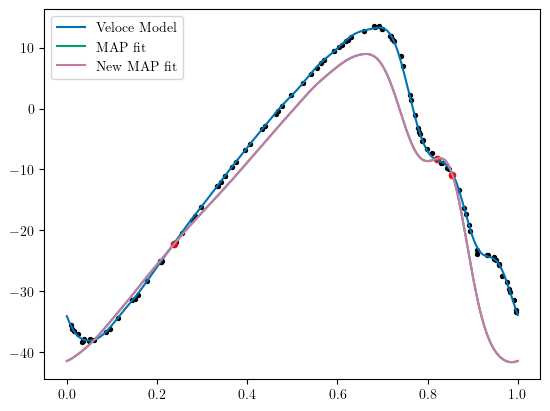

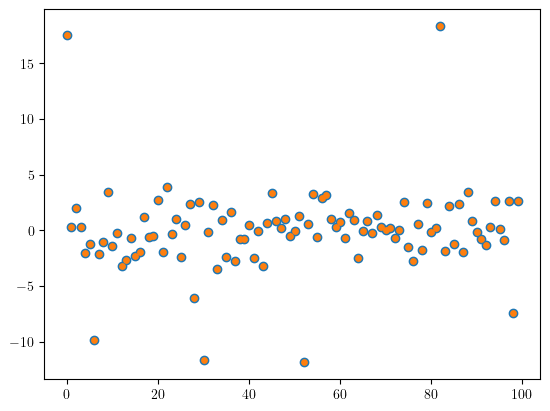

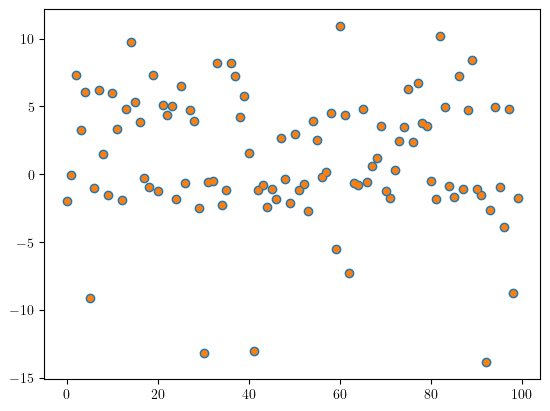

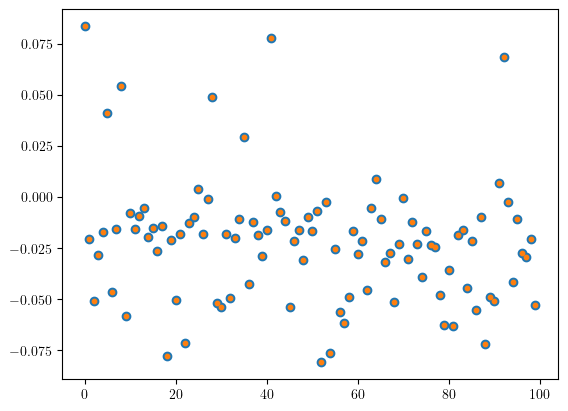

In [100]:
plot_resample_result_fit_comp(values_res[-2], values_res[-1], 43)
fig, axs = plt.subplots()
axs.scatter(np.arange(100), values_res[0])
axs.scatter(np.arange(100), values_res[1], s=15)
print("vgamma_mean", np.mean(values_res[0]), np.mean(values_res[1]))
print("vgamma_std", np.std(values_res[0]), np.std(values_res[1]))

fig, axs = plt.subplots()
axs.scatter(np.arange(100), values_res[2])
axs.scatter(np.arange(100), values_res[3], s=15)
print("p2p_mean", np.mean(values_res[2]), np.mean(values_res[3]))
print("p2p_std", np.std(values_res[2]), np.std(values_res[3]))
fig, axs = plt.subplots()
axs.scatter(np.arange(100), values_res[4])
axs.scatter(np.arange(100), values_res[5], s=10)
print("phi_std", np.std(values_res[4]), np.std(values_res[5]))

Retrieve all results and store them in a pandas.DataFrame

In [101]:
# Pre-compute per-target branch boundaries once, in VELOCE phase convention
# branch_info = {}
# for name in fit_rv_no_outliers["NAME"]:
#     veloce_pulsation = dataset[dataset["NAME"] == name].iloc[0]["SAMPLE"]
#     # phase_grid is [0, 1], veloce_pulsation has vgamma removed
#     phi_min = phase_grid[np.argmin(veloce_pulsation)]
#     phi_max = phase_grid[np.argmax(veloce_pulsation)]
#     branch_info[name] = (phi_min, phi_max)

In [102]:
# del branch_info

In [103]:
def classify_branches(
    phi_obs: np.ndarray,
    phi_min: float,
    phi_max: float,
) -> tuple[int, int]:
    """Count observations on ascending (min→max) and descending (max→min) branches."""
    # Shift so that phi_min = 0, then ascending branch is [0, phi_max - phi_min] mod 1
    phi_rel = (phi_obs - phi_min) % 1
    asc_length = (phi_max - phi_min) % 1
    on_ascending = phi_rel <= asc_length
    return int(on_ascending.sum()), int((~on_ascending).sum())

In [104]:
records = []
for n_rv in n_subsample:
    n_rv_dir = subsampling_results_dir / f"n_rv{n_rv:.0f}"
    if not n_rv_dir.exists():
        continue
    for filepath in sorted(n_rv_dir.glob("*.pkl")):
        with Path.open(filepath, "rb") as f:
            data = pkl.load(f)  # noqa: S301

        name = data["target"]
        header_row = veloce_headers[veloce_headers["NAME"] == name].iloc[0]
        fit_row = veloce_fit[veloce_fit["NAME"] == name].iloc[0]
        veloce_vgamma = float(fit_row["VGAMMA"])
        veloce_p2p = float(header_row["PEAK2PEAK"])
        veloce_pulsation = dataset[dataset["NAME"] == name].iloc[0]["SAMPLE"]

        # Create Priors
        source_id = int(header_row.GAIA_DR3_SOURCE_ID)
        has_gaia_epoch = True
        if source_id in df_gaiadr3_selection["source_id"].to_numpy():
            gaia_data = df_gaiadr3_selection[
                df_gaiadr3_selection["source_id"] == source_id
            ]
            epoch_g = gaia_data["epoch_g"].to_numpy()[0] + epoch_offset_gaiadr3
        else:
            has_gaia_epoch = False
        log_p = data["log_P"]
        priors = []
        kde_comps_for_target = kde_comps.conditional(log_P=log_p)
        priors.append(
            vf.prior.ParameterPrior(kde_comps_for_target, mapping_variables_model)
        )
        # One conditional prior on the phase
        has_phase_prior = True
        if (
            log_p < kde_phot_phase.domain["log_P"][1]
            and has_gaia_epoch
            and (name not in outliers_gaia_veloce_delta.NAME.to_numpy())
        ):
            cond_phase = kde_phot_phase.conditional(log_P=log_p)
            fast_phase = vf.prior.SplineDensity(cond_phase)
        else:
            has_phase_prior = False
            fast_phase = vf.prior.UniformDensity("DELTA_PHASE", 0.0, 1.0)

        idx = mapping_variables_model["delta_phi"]
        priors.append(vf.prior.ParameterPrior(fast_phase, {"DELTA_PHASE": idx}))
        log_prior_target = vf.prior.CombinedLogPrior(priors)

        if name == "V1197 Cen":
            print(n_rv, name, len(data["result_map"]))
        for i_resample, result in enumerate(data["result_map"]):
            # pulsation in VELOCE phase convention (no phase shift) — fastest formula
            map_pulsation = (
                phased_model.removed_mean
                + np.dot(
                    phased_model._components_T,  # noqa: SLF001
                    result.theta_free[1:-1],
                )
            )
            delta_vgamma = float(result.theta_free[0]) - veloce_vgamma
            delta_p2p = np.ptp(map_pulsation) - veloce_p2p
            rmse = float(np.sqrt(np.mean((map_pulsation - veloce_pulsation) ** 2)))
            resample_rv = data["rv"][data["combinations"][i_resample]]
            naive_vgamma = np.mean(resample_rv)
            naive_p2p = np.ptp(resample_rv)
            delta_vgammafromnaive = float(result.theta_free[0]) - np.mean(resample_rv)
            delta_p2pfromnaive = np.ptp(map_pulsation) - np.ptp(resample_rv)

            # Calculate the phase coverage
            phases = data["phase"][data["combinations"][i_resample]]
            arc_gaps_val = arc_gaps(phases)
            max_gap_val = max_gap(phases)

            # Fix real delta phi (between 0 and 1)
            real_delta_phi = (data["real_delta_phi"] + 1) % 1

            if ~np.isfinite(log_prior_target(result.theta_free)):
                print("Wrong Prior", name, n_rv, i_resample)
                continue

            fitted_curve = result.evaluate(phase_grid)
            phi_min_fit = phase_grid[np.argmin(fitted_curve)]
            phi_max_fit = phase_grid[np.argmax(fitted_curve)]
            phi_obs = phases
            rv_obs = data["rv"][data["combinations"][i_resample]]
            # phi_min, phi_max = branch_info[name]
            # delta_phi = result.theta_free[-1]  # MAP phase shift

            # # Transform to VELOCE phase convention
            # phi_veloce = (phases + delta_phi) % 1

            n_asc, n_desc = classify_branches(phi_obs, phi_min_fit, phi_max_fit)
            fitted_amplitude = fitted_curve.max() - fitted_curve.min()

            # rv_obs must be polynomial-detrended (same as what was fed to the fitter)
            # rv_obs = rv[comb]  # assuming rv is already detrended at this point
            rv_coverage = (naive_p2p) / np.ptp(map_pulsation)

            # Phase centroid (circular mean)
            angles = 2 * np.pi * phi_obs
            phi_centroid_obs = (
                np.arctan2(np.sin(angles).mean(), np.cos(angles).mean()) / (2 * np.pi)
            ) % 1
            phi_centroid_curve = 0.5  # uniform phase_grid → always 0.5
            d_phi = min(
                abs(phi_centroid_obs - phi_centroid_curve),
                1 - abs(phi_centroid_obs - phi_centroid_curve),
            )

            # RV centroid (linear, no wrapping)
            # rv_at_obs = np.interp(phi_obs, phase_grid, fitted_curve)
            d_rv = (rv_obs.mean() - fitted_curve.mean()) / fitted_amplitude

            centroid_offset = np.sqrt(d_phi**2 + d_rv**2)

            # Normalize both dimensions to [-1, 1]
            rv_norm_curve = (fitted_curve - fitted_curve.min()) / fitted_amplitude
            rv_norm_obs = (rv_obs - fitted_curve.min()) / fitted_amplitude

            # Arc-length-weighted centroid of the curve as a geometric object
            # Embed: (cos(2π·phi), sin(2π·phi), rv_norm) → 3D Euclidean, no wrapping
            phi_cos = np.cos(2 * np.pi * phase_grid)
            phi_sin = np.sin(2 * np.pi * phase_grid)

            # Arc-length-weighted centroid of the curve (now in 3D)
            d_cos = np.diff(phi_cos)
            d_sin = np.diff(phi_sin)
            d_rv = np.diff(rv_norm_curve)
            ds = np.sqrt(d_cos**2 + d_sin**2 + d_rv**2)

            curve_c = np.array(
                [
                    np.average(0.5 * (phi_cos[:-1] + phi_cos[1:]), weights=ds),
                    np.average(0.5 * (phi_sin[:-1] + phi_sin[1:]), weights=ds),
                    np.average(
                        0.5 * (rv_norm_curve[:-1] + rv_norm_curve[1:]), weights=ds
                    ),
                ]
            )

            # Observation centroid
            obs_c = np.array(
                [
                    np.cos(2 * np.pi * phi_obs).mean(),
                    np.sin(2 * np.pi * phi_obs).mean(),
                    rv_norm_obs.mean(),
                ]
            )

            centroid_offset = float(np.linalg.norm(obs_c - curve_c))

            records.append(
                {
                    "NAME": name,
                    "SET": header_row["SET"],
                    "log_P": np.log10(float(header_row["P"])),
                    "n_rv": n_rv,
                    "i_resample": i_resample,
                    "has_phase_prior": has_phase_prior,
                    "veloce_p2p": veloce_p2p,
                    "delta_vgamma": delta_vgamma,
                    "delta_vgamma_fromnaive": delta_vgammafromnaive,
                    "delta_p2p": delta_p2p,
                    "delta_p2p_fromnaive": delta_p2pfromnaive,
                    "rmse": rmse,
                    "delta_vgamma_norm": delta_vgamma / veloce_p2p,
                    "delta_p2p_norm": delta_p2p / veloce_p2p,
                    "rmse_norm": rmse / veloce_p2p,
                    "veloce_p2p": veloce_p2p,
                    "delta_phi": result.theta_free[-1],
                    "real_delta_phi": real_delta_phi,
                    "diff_delta_phi": (result.theta_free[-1] - real_delta_phi + 0.5) % 1
                    - 0.5,
                    "arc_gaps": arc_gaps_val,
                    "max_gap": max_gap_val,
                    "naive_dvgamma": naive_vgamma - veloce_vgamma,
                    "naive_dp2p": naive_p2p - veloce_p2p,
                    "delta_vgamma_naive": naive_vgamma - veloce_vgamma,
                    "delta_p2p_naive": naive_p2p - veloce_p2p,
                    "delta_vgamma_naive_norm": (naive_vgamma - veloce_vgamma)
                    / veloce_p2p,
                    "delta_p2p_naive_norm": (naive_p2p - veloce_p2p) / veloce_p2p,
                    "n_ascending": n_asc,
                    "n_descending": n_desc,
                    "frac_ascending": n_asc / len(data["combinations"][i_resample]),
                    "single_branch": (n_asc == 0) or (n_desc == 0),
                    "rv_coverage": rv_coverage,
                    "centroid_offset": centroid_offset,
                },
            )

comparison_df = pd.DataFrame(records)
del records

3 V1197 Cen 84
4 V1197 Cen 100
5 V1197 Cen 100
6 V1197 Cen 84


In [105]:
len(comparison_df)

168768

In [95]:
comparison_df[comparison_df.n_rv == 3]

,NAME,SET,log_P,n_rv,i_resample,has_phase_prior,veloce_p2p,delta_vgamma,delta_vgamma_fromnaive,delta_p2p,...,delta_vgamma_naive,delta_p2p_naive,delta_vgamma_naive_norm,delta_p2p_naive_norm,n_ascending,n_descending,frac_ascending,single_branch,rv_coverage,centroid_offset
0,AK Cep,test,0.859295,3,0,True,36.077361,-1.833710,-6.505572,-0.421922,...,4.671863,-1.301545,0.129496,-0.036077,0,3,0.000000,True,0.975330,0.832408
1,AK Cep,test,0.859295,3,1,True,36.077361,-1.135030,-6.476498,3.660005,...,5.341468,-10.399176,0.148056,-0.288247,2,1,0.666667,False,0.646197,0.342569
2,AK Cep,test,0.859295,3,2,True,36.077361,-0.504067,3.450948,4.026763,...,-3.955015,-22.095545,-0.109626,-0.612449,3,0,1.000000,True,0.348638,0.708669
3,AK Cep,test,0.859295,3,3,True,36.077361,0.567940,4.736621,4.279190,...,-4.168681,-18.688729,-0.115548,-0.518018,3,0,1.000000,True,0.430875,0.664761
4,AK Cep,test,0.859295,3,4,True,36.077361,0.239311,-2.796674,-4.142890,...,3.035985,-13.891992,0.084152,-0.385061,2,1,0.666667,False,0.694715,0.197355
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21579,l Car,train,1.550966,3,95,True,34.074459,0.024582,-3.150371,-0.683001,...,3.174953,-2.264599,0.093177,-0.066460,0,3,0.000000,True,0.952635,0.835069
21580,l Car,train,1.550966,3,96,True,34.074459,0.182590,2.039440,-0.337381,...,-1.856851,-7.917539,-0.054494,-0.232360,2,1,0.666667,False,0.775317,0.131719
21581,l Car,train,1.550966,3,97,True,34.074459,-6.492636,-20.918235,17.236882,...,14.425599,-31.931349,0.423355,-0.937105,0,3,0.000000,True,0.041767,1.040536
21582,l Car,train,1.550966,3,98,True,34.074459,-1.504486,-5.608828,1.441358,...,4.104343,-1.429719,0.120452,-0.041959,1,2,0.333333,False,0.919161,0.785468


/var/folders/hm/6rf5cwbj6x74z7zlmzpbdwx80000gn/T/ipykernel_4005/3062773558.py:158: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


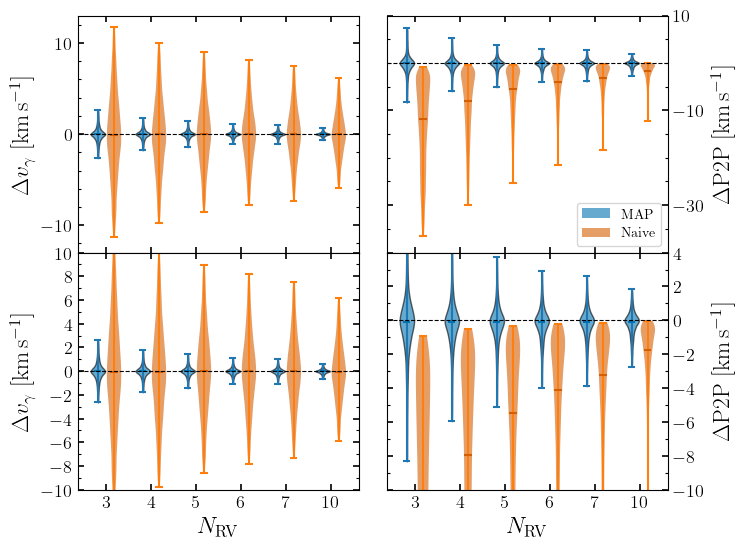

In [ ]:
n_rv_vals = [3, 4, 5, 6, 7, 10]  # sorted(comparison_df["n_rv"].unique())
width = 3.46 * 2.2
height = width * 1.618 / 2
fig, axs = plt.subplots(
    2,
    2,
    figsize=(width, height),
    sharey=False,
    sharex=True,
    gridspec_kw={"hspace": 0, "wspace": 0.1},
)

quantities = [
    (
        "delta_vgamma",
        "delta_vgamma_naive",
        r"$\Delta v_\gamma $ [km\,s$^{-1}$]",  # \;/\; \mathrm{A2P}$",
    ),
    (
        "delta_p2p",
        "delta_p2p_naive",
        r"$\Delta \mathrm{P2P}$ [km\,s$^{-1}$]",
    ),
    (
        "delta_vgamma",
        "delta_vgamma_naive",
        r"$\Delta v_\gamma $ [km\,s$^{-1}$]",  # \;/\; \mathrm{A2P}$",
    ),
    (
        "delta_p2p",
        "delta_p2p_naive",
        r"$\Delta \mathrm{P2P}$ [km\,s$^{-1}$]",
    ),
]

for i, (ax, (map_col, naive_col, ylabel)) in enumerate(zip(axs.flatten(), quantities)):
    positions_map = np.arange(len(n_rv_vals)) - 0.18
    positions_naive = np.arange(len(n_rv_vals)) + 0.18

    data_map_all = [
        comparison_df.loc[comparison_df["n_rv"] == n, map_col].dropna().to_numpy()
        for n in n_rv_vals
    ]
    data_map = []
    for dat in data_map_all:
        q05, q95 = np.quantile(dat, [0.05, 0.95])
        data_map.append(dat[(dat < q95) & (dat > q05)])

    data_naive_all = [
        comparison_df.loc[comparison_df["n_rv"] == n, naive_col].dropna().to_numpy()
        for n in n_rv_vals
    ]
    data_naive = []
    for dat in data_naive_all:
        q05, q95 = np.quantile(dat, [0.05, 0.95])
        data_naive.append(dat[(dat < q95) & (dat > q05)])

    if map_col == "delta_p2p_norm":
        print(data_map)
        data_map = [d * 100 for d in data_map]
        data_naive = [d * 100 for d in data_naive]

    vp_map = ax.violinplot(
        data_map,
        positions=positions_map,
        widths=0.32,
        showmedians=True,
        # quantiles=[[0.05, 0.95] for _ in n_rv_vals],
        showextrema=True,
        # linecolor="k",
    )
    vp_naive = ax.violinplot(
        data_naive,
        positions=positions_naive,
        widths=0.32,
        showmedians=True,
        # quantiles=[[0.05, 0.95] for _ in n_rv_vals],
        showextrema=True,
        # linecolor="k",
    )

    for body in vp_map["bodies"]:
        body.set_edgecolor("k")
        body.set_linewidth(1)
        body.set_facecolor(color_safe["blue"])
        body.set_alpha(0.6)
        # body.set_linecolor("k")
    vp_map["cmedians"].set_color(color_safe["blue"])

    for body in vp_naive["bodies"]:
        # body.set_edgecolor("k")
        # body.set_linewidth(1)
        body.set_facecolor(color_safe["dark_orange"])
        body.set_alpha(0.6)
    vp_naive["cmedians"].set_color(color_safe["dark_orange"])

    ax.axhline(0, color="k", lw=0.8, ls="--")
    # ax.set_xticks(range(len(n_rv_vals)))
    # ax.set_xticklabels(n_rv_vals)
    vf.plots_utils.format_xticks(
        ax, range(len(n_rv_vals)), range(len(n_rv_vals)), label_size=13
    )
    ax.set_xticklabels(n_rv_vals)
    ax.set_xlabel(r"$N_\mathrm{RV}$", fontsize=label_size + 6)
    ax.set_ylabel(ylabel, fontsize=label_size + 6)

    if i == 0:
        vf.plots_utils.format_yticks(
            ax,
            np.arange(-50, 60, 10),
            np.arange(-50, 45, 2),
            label_size=13,
        )
        ax.set_ylim((-13, 13))
    if i == 1:
        ax.yaxis.set_label_position("right")
        ax.yaxis.tick_right()
        vf.plots_utils.format_yticks(
            ax,
            np.arange(-70, 60, 20),
            np.arange(-70, 65, 5),
            label_size=13,
        )
        ax.set_ylim((-40, 10))
    if i == 2:
        vf.plots_utils.format_yticks(
            ax,
            np.arange(-20, 20, 2),
            np.arange(-40, 45, 1),
            label_size=13,
        )
        ax.set_ylim((-10, 10))
    if i == 3:
        ax.yaxis.set_label_position("right")
        ax.yaxis.tick_right()
        vf.plots_utils.format_yticks(
            ax,
            np.arange(-60, 60, 2),
            np.arange(-60, 45, 1),
            label_size=13,
        )
        ax.set_ylim((-10, 4))

# legend
from matplotlib.patches import Patch

axs[0, 1].legend(
    handles=[
        Patch(facecolor=color_safe["blue"], alpha=0.6, label="MAP"),
        Patch(facecolor=color_safe["dark_orange"], alpha=0.6, label="Naive"),
    ],
    fontsize=label_size - 1,
)
# ylims = [(-6, 6), (-100, 25)]
# for ax, yl in zip(axs, ylims):
#     ax.set_ylim(yl)

fig.tight_layout()
fig.savefig(subsampling_dir / "naive_comparison.pdf", format="pdf")

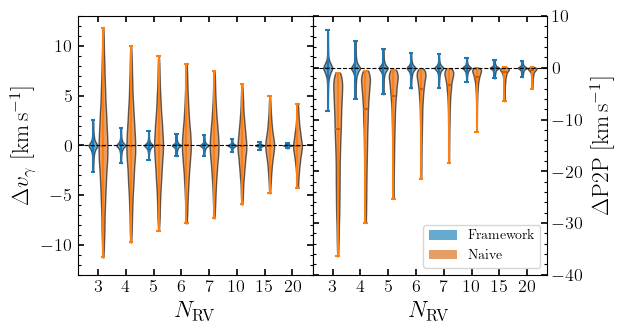

In [ ]:
n_rv_vals = [3, 4, 5, 6, 7, 10, 15, 20]  # sorted(comparison_df["n_rv"].unique())
width = 3.46 * 2.2 / 1.2
height = width * 1.618 / 2.5 / 1.2
fig, axs = plt.subplots(
    1,
    2,
    figsize=(width, height),
    sharey=False,
    sharex=True,
    gridspec_kw={"hspace": 0, "wspace": 0.0},
)

quantities = [
    (
        "delta_vgamma",
        "delta_vgamma_naive",
        r"$\Delta v_\gamma $ [km\,s$^{-1}$]",  # \;/\; \mathrm{A2P}$",
    ),
    (
        "delta_p2p",
        "delta_p2p_naive",
        r"$\Delta \mathrm{P2P}$ [km\,s$^{-1}$]",
    ),
]

for i, (ax, (map_col, naive_col, ylabel)) in enumerate(zip(axs.flatten(), quantities)):
    positions_map = np.arange(len(n_rv_vals)) - 0.18
    positions_naive = np.arange(len(n_rv_vals)) + 0.18

    data_map_all = [
        comparison_df.loc[comparison_df["n_rv"] == n, map_col].dropna().to_numpy()
        for n in n_rv_vals
    ]
    data_map = []
    for dat in data_map_all:
        q05, q95 = np.quantile(dat, [0.05, 0.95])
        data_map.append(dat[(dat < q95) & (dat > q05)])

    data_naive_all = [
        comparison_df.loc[comparison_df["n_rv"] == n, naive_col].dropna().to_numpy()
        for n in n_rv_vals
    ]
    data_naive = []
    for dat in data_naive_all:
        q05, q95 = np.quantile(dat, [0.05, 0.95])
        data_naive.append(dat[(dat < q95) & (dat > q05)])

    if map_col == "delta_p2p_norm":
        print(data_map)
        data_map = [d * 100 for d in data_map]
        data_naive = [d * 100 for d in data_naive]

    vp_map = ax.violinplot(
        data_map,
        positions=positions_map,
        widths=0.32,
        showmedians=True,
        # quantiles=[[0.05, 0.95] for _ in n_rv_vals],
        showextrema=True,
    )
    vp_naive = ax.violinplot(
        data_naive,
        positions=positions_naive,
        widths=0.32,
        showmedians=True,
        showextrema=True,
    )

    for body in vp_map["bodies"]:
        body.set_edgecolor("k")
        body.set_linewidth(1)
        body.set_facecolor(color_safe["blue"])
        body.set_alpha(0.6)
        # body.set_linecolor("k")
    vp_map["cmedians"].set_color(color_safe["blue"])

    for body in vp_naive["bodies"]:
        body.set_edgecolor("k")
        body.set_linewidth(1)
        body.set_facecolor(color_safe["dark_orange"])
        body.set_alpha(0.6)
    vp_naive["cmedians"].set_color(color_safe["dark_orange"])

    ax.axhline(0, color="k", lw=0.8, ls="--")
    # ax.set_xticks(range(len(n_rv_vals)))
    # ax.set_xticklabels(n_rv_vals)
    vf.plots_utils.format_xticks(
        ax, range(len(n_rv_vals)), range(len(n_rv_vals)), label_size=13
    )
    ax.set_xticklabels(n_rv_vals)
    ax.set_xlabel(r"$N_\mathrm{RV}$", fontsize=label_size + 6)
    ax.set_ylabel(ylabel, fontsize=label_size + 6)

    if i == 0:
        vf.plots_utils.format_yticks(
            ax,
            np.arange(-50, 60, 5),
            np.arange(-50, 45, 1),
            label_size=13,
        )
        ax.set_ylim((-13, 13))
    if i == 1:
        ax.yaxis.set_label_position("right")
        ax.yaxis.tick_right()
        vf.plots_utils.format_yticks(
            ax,
            np.arange(-70, 60, 10),
            np.arange(-70, 65, 2),
            label_size=13,
        )
        ax.set_ylim((-40, 10))

# legend
from matplotlib.patches import Patch

axs[1].legend(
    handles=[
        Patch(facecolor=color_safe["blue"], alpha=0.6, label="Framework"),
        Patch(facecolor=color_safe["dark_orange"], alpha=0.6, label="Naive"),
    ],
    fontsize=label_size - 1,
)
# ylims = [(-6, 6), (-100, 25)]
# for ax, yl in zip(axs, ylims):
#     ax.set_ylim(yl)

fig.tight_layout()
fig.savefig(subsampling_dir / "naive_comparison.pdf", format="pdf")

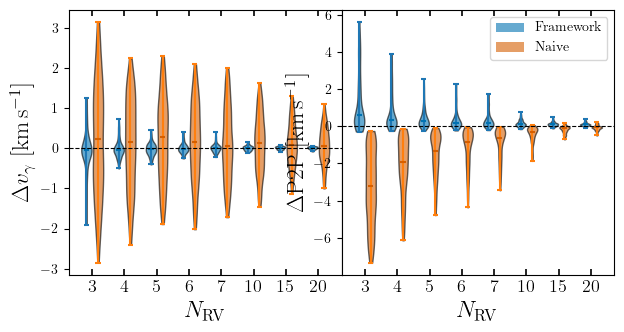

In [ ]:
n_rv_vals = [3, 4, 5, 6, 7, 10, 15, 20]  # sorted(comparison_df["n_rv"].unique())
width = 3.46 * 2.2 / 1.2
height = width * 1.618 / 2.5 / 1.2
fig, axs = plt.subplots(
    1,
    2,
    figsize=(width, height),
    sharey=False,
    sharex=True,
    gridspec_kw={"hspace": 0, "wspace": 0.0},
)

quantities = [
    (
        "delta_vgamma",
        "delta_vgamma_naive",
        r"$\Delta v_\gamma $ [km\,s$^{-1}$]",  # \;/\; \mathrm{A2P}$",
    ),
    (
        "delta_p2p",
        "delta_p2p_naive",
        r"$\Delta \mathrm{P2P}$ [km\,s$^{-1}$]",
    ),
]

low_comp_df = comparison_df[
    (comparison_df.veloce_p2p > 8) & (comparison_df.veloce_p2p < 10)
]

for i, (ax, (map_col, naive_col, ylabel)) in enumerate(zip(axs.flatten(), quantities)):
    positions_map = np.arange(len(n_rv_vals)) - 0.18
    positions_naive = np.arange(len(n_rv_vals)) + 0.18

    data_map_all = [
        low_comp_df.loc[low_comp_df["n_rv"] == n, map_col].dropna().to_numpy()
        for n in n_rv_vals
    ]
    data_map = []
    for dat in data_map_all:
        q05, q95 = np.quantile(dat, [0.05, 0.95])
        data_map.append(dat[(dat < q95) & (dat > q05)])

    data_naive_all = [
        low_comp_df.loc[low_comp_df["n_rv"] == n, naive_col].dropna().to_numpy()
        for n in n_rv_vals
    ]
    data_naive = []
    for dat in data_naive_all:
        q05, q95 = np.quantile(dat, [0.05, 0.95])
        data_naive.append(dat[(dat < q95) & (dat > q05)])

    if map_col == "delta_p2p_norm":
        print(data_map)
        data_map = [d * 100 for d in data_map]
        data_naive = [d * 100 for d in data_naive]

    vp_map = ax.violinplot(
        data_map,
        positions=positions_map,
        widths=0.32,
        showmedians=True,
        # quantiles=[[0.05, 0.95] for _ in n_rv_vals],
        showextrema=True,
    )
    vp_naive = ax.violinplot(
        data_naive,
        positions=positions_naive,
        widths=0.32,
        showmedians=True,
        showextrema=True,
    )

    for body in vp_map["bodies"]:
        body.set_edgecolor("k")
        body.set_linewidth(1)
        body.set_facecolor(color_safe["blue"])
        body.set_alpha(0.6)
        # body.set_linecolor("k")
    vp_map["cmedians"].set_color(color_safe["blue"])

    for body in vp_naive["bodies"]:
        body.set_edgecolor("k")
        body.set_linewidth(1)
        body.set_facecolor(color_safe["dark_orange"])
        body.set_alpha(0.6)
    vp_naive["cmedians"].set_color(color_safe["dark_orange"])

    ax.axhline(0, color="k", lw=0.8, ls="--")
    # ax.set_xticks(range(len(n_rv_vals)))
    # ax.set_xticklabels(n_rv_vals)
    vf.plots_utils.format_xticks(
        ax, range(len(n_rv_vals)), range(len(n_rv_vals)), label_size=13
    )
    ax.set_xticklabels(n_rv_vals)
    ax.set_xlabel(r"$N_\mathrm{RV}$", fontsize=label_size + 6)
    ax.set_ylabel(ylabel, fontsize=label_size + 6)

    # if i == 0:
    #     vf.plots_utils.format_yticks(
    #         ax,
    #         np.arange(-50, 60, 5),
    #         np.arange(-50, 45, 1),
    #         label_size=13,
    #     )
    #     ax.set_ylim((-13, 13))
    # if i == 1:
    #     ax.yaxis.set_label_position("right")
    #     ax.yaxis.tick_right()
    #     vf.plots_utils.format_yticks(
    #         ax,
    #         np.arange(-70, 60, 10),
    #         np.arange(-70, 65, 2),
    #         label_size=13,
    #     )
    #     ax.set_ylim((-40, 10))

# legend
from matplotlib.patches import Patch

axs[1].legend(
    handles=[
        Patch(facecolor=color_safe["blue"], alpha=0.6, label="Framework"),
        Patch(facecolor=color_safe["dark_orange"], alpha=0.6, label="Naive"),
    ],
    fontsize=label_size - 1,
)
# ylims = [(-6, 6), (-100, 25)]
# for ax, yl in zip(axs, ylims):
#     ax.set_ylim(yl)

fig.tight_layout()

In [ ]:
def plot_resample_result(name, nrv, i_resample):
    n_rv_dir = subsampling_results_dir / f"n_rv{nrv:.0f}"
    filename = name.replace(" ", "_")

    filepath = next(iter(n_rv_dir.glob(f"*{filename}*.pkl")))
    with Path.open(filepath, "rb") as f:
        data = pkl.load(f)  # noqa: S301

    header_row = veloce_headers[veloce_headers["NAME"] == name].iloc[0]
    fit_row = veloce_fit[veloce_fit["NAME"] == name].iloc[0]
    veloce_vgamma = float(fit_row["VGAMMA"])
    veloce_p2p = float(header_row["PEAK2PEAK"])
    veloce_pulsation = dataset[dataset["NAME"] == name].iloc[0]["SAMPLE"]

    period = header_row["P"]
    epoch = header_row["E"]
    set_type = header_row["SET"]
    log_p = np.log10(period)

    comb = data["combinations"][i_resample]
    rv_sub = data["rv"][comb]
    rv_err_sub = data["rv_err"][comb]
    phase_sub = data["phase"][comb]
    real_delta_phase = data["real_delta_phi"]

    fit_res = data["result_map"][i_resample]
    print(fit_res.theta_free)
    temp_fit_curve = fit_curve_df[fit_curve_df["NAME"] == name]["LS_RESULT"].iloc[0]
    shift_idx = np.argsort((temp_fit_curve.x - real_delta_phase) % 1)
    shift_idx_grid = np.argsort((phase_grid - real_delta_phase) % 1)

    map_pulsation = (
        phased_model.removed_mean
        + np.dot(
            phased_model._components_T,  # noqa: SLF001
            fit_res.theta_free[1:-1],
        )
    )
    print(np.ptp(map_pulsation) - veloce_p2p)
    print("gap", max_gap(phase_sub))

    log_p = data["log_P"]
    priors = []
    kde_comps_for_target = kde_comps.conditional(log_P=log_p)
    priors.append(
        vf.prior.ParameterPrior(kde_comps_for_target, mapping_variables_model)
    )
    log_prior_target = vf.prior.CombinedLogPrior(priors)
    print(log_prior_target(fit_res.theta_free))

    width = 3.46 * 1.5
    height = width / 1.618
    fig, axs = plt.subplots(figsize=(width, height))

    axs.errorbar(
        data["phase"],
        data["rv"],
        fmt=".",
        markersize=7,
        color=color_safe["black"],
        elinewidth=0.5,
        capsize=0,
        zorder=0,
        label="All RV meas.",
    )
    # axs.scatter(
    #     data["phase"],
    #     data["rv"],
    #     c="k",
    #     s=8,
    # )
    # axs.errorbar(
    #     phase_sub,
    #     rv_sub,
    #     fmt=".",
    #     markersize=6,
    #     color=color_safe["light_green"],
    #     elinewidth=0.5,
    #     capsize=0,
    #     zorder=0,
    #     label=f"RV meas. subsample \#{i_resample+1}",
    # )
    axs.scatter(
        phase_sub,
        rv_sub,
        c=color_safe["light_green"],
        s=28,
        edgecolors="k",
        zorder=5,
        label=f"Subsample \#{i_resample + 1}",
    )
    axs.plot(
        temp_fit_curve.x,
        temp_fit_curve.y[shift_idx],
        "-",
        label=r"$\texttt{V}^{FS}$",
        color=color_safe["pink"],
    )
    axs.plot(
        phase_grid,
        fit_res.evaluate(phase_grid),
        ls="-.",
        label=r"$\mathcal{M}_{\rm RV} (N_{\rm RV} = $" + f"{nrv}) ",
        color=color_safe["light_green"],
    )

    x_ticks = [0, 0.25, 0.5, 0.75, 1]
    x_ticks_minor = np.arange(0, 1.05, 0.05)
    vf.plot.format_xticks(axs, x_ticks, x_ticks_minor)
    axs.set_xlim(0, 1)

    def fmt(x: float, pos) -> str:
        return f"{x:g}" if x == int(x) else f"{x:.2f}"

    axs.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(fmt))
    axs.set_xlabel(r"$\phi$", fontsize=label_size + 2)

    # if col == 1:
    #     ax.yaxis.set_label_position("right")
    #     ax.yaxis.tick_right()
    ylims = axs.get_ylim()
    diff_ylim = ylims[1] - ylims[0]
    if diff_ylim < 6:
        y_ticks = np.arange(-200, 200, 1)
        y_ticks_minor = np.arange(-200, 200, 0.5)
    if diff_ylim >= 6:
        y_ticks = np.arange(-200, 200, 2)
        y_ticks_minor = np.arange(-200, 200, 0.5)
    if diff_ylim >= 15:
        y_ticks = np.arange(-200, 200, 5)
        y_ticks_minor = np.arange(-200, 200, 1)
    if diff_ylim >= 20:
        y_ticks = np.arange(-200, 200, 10)
        y_ticks_minor = np.arange(-200, 200, 2)

    vf.plot.format_yticks(axs, y_ticks, y_ticks_minor)
    axs.set_ylim(*ylims)
    axs.set_ylabel(r"RV [km\,s$^{-1}$]", fontsize=label_size + 2)

    # ── Upper-left annotation ──────────────────────────────────────────────
    set_str = "Training" if set_type == "train" else "Test"
    annotation = (
        f"{name}\n"
        f"$P = {period:.3f}$ d\n"  # ($\\log P = {log_p:.3f}$)\n"
        f"{set_str} Set"
    )
    axs.text(
        0.05,
        0.95,
        annotation,
        transform=axs.transAxes,
        fontsize=label_size,
        ha="left",
        va="top",
        linespacing=1.5,
    )
    axs.legend(fontsize=label_size, loc="lower center")
    fig.tight_layout()

<>:92: SyntaxWarning: "\#" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\#"? A raw string is also an option.
<>:92: SyntaxWarning: "\#" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\#"? A raw string is also an option.
/var/folders/hm/6rf5cwbj6x74z7zlmzpbdwx80000gn/T/ipykernel_4005/50778687.py:92: SyntaxWarning: "\#" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\#"? A raw string is also an option.
  label=f"Subsample \#{i_resample+1}",


[   5.23045536 -164.29660541  -50.13086781  -21.28544744   -2.34205912
   -2.36996411    1.49618536    0.16622663]
0.5342695604645851
gap 0.5735716356242051
-21.2341926419669


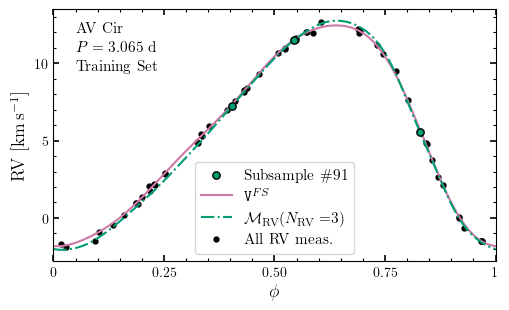

In [329]:
plot_resample_result("AV Cir", 3, 90)

In [ ]:
def plot_resample_paper(
    names: list[str],
    nrv: int,
    i_resamples: list[int],
) -> Figure:
    """Create a 3x2 panel showing RV curves for six targets."""
    if len(names) != 6:
        msg = f"Exactly 6 target names required, got {len(names)}"
        raise ValueError(msg)

    width = 3.46 * 2.0
    height = width / 1.618 * 1.5
    fig, axs_grid = plt.subplots(
        3,
        2,
        figsize=(width, height),
        sharex=True,
        gridspec_kw={"hspace": 0, "wspace": 0.05},
    )

    for i, (axs, name, i_resample) in enumerate(zip(axs_grid.flat, names, i_resamples)):
        row, col = divmod(i, 2)

        n_rv_dir = subsampling_results_dir / f"n_rv{nrv:.0f}"
        filename = name.replace(" ", "_")

        filepath = next(iter(n_rv_dir.glob(f"*{filename}*.pkl")))
        with Path.open(filepath, "rb") as f:
            data = pkl.load(f)  # noqa: S301

        header_row = veloce_headers[veloce_headers["NAME"] == name].iloc[0]
        fit_row = veloce_fit[veloce_fit["NAME"] == name].iloc[0]
        veloce_vgamma = float(fit_row["VGAMMA"])
        veloce_p2p = float(header_row["PEAK2PEAK"])
        veloce_pulsation = dataset[dataset["NAME"] == name].iloc[0]["SAMPLE"]

        period = header_row["P"]
        epoch = header_row["E"]
        set_type = header_row["SET"]
        log_p = np.log10(period)

        comb = data["combinations"][i_resample]
        rv_sub = data["rv"][comb]
        rv_err_sub = data["rv_err"][comb]
        phase_sub = data["phase"][comb]
        real_delta_phase = data["real_delta_phi"]

        fit_res = data["result_map"][i_resample]
        print(fit_res.theta_free)
        temp_fit_curve = fit_curve_df[fit_curve_df["NAME"] == name]["LS_RESULT"].iloc[0]
        shift_idx = np.argsort((temp_fit_curve.x - real_delta_phase) % 1)
        shift_idx_grid = np.argsort((phase_grid - real_delta_phase) % 1)

        map_pulsation = (
            phased_model.removed_mean
            + np.dot(
                phased_model._components_T,  # noqa: SLF001
                fit_res.theta_free[1:-1],
            )
        )
        print(np.ptp(map_pulsation) - veloce_p2p)
        print("gap", max_gap(phase_sub))

        log_p = data["log_P"]
        priors = []
        kde_comps_for_target = kde_comps.conditional(log_P=log_p)
        priors.append(
            vf.prior.ParameterPrior(kde_comps_for_target, mapping_variables_model)
        )
        log_prior_target = vf.prior.CombinedLogPrior(priors)
        print(log_prior_target(fit_res.theta_free))

        # width = 3.46 *1.5
        # height = width / 1.618
        # fig, axs = plt.subplots(figsize=(width, height))

        axs.errorbar(
            data["phase"],
            data["rv"],
            fmt=".",
            markersize=7,
            color=color_safe["black"],
            elinewidth=0.5,
            capsize=0,
            zorder=0,
            label="All RV meas.",
        )
        # axs.scatter(
        #     data["phase"],
        #     data["rv"],
        #     c="k",
        #     s=8,
        # )
        # axs.errorbar(
        #     phase_sub,
        #     rv_sub,
        #     fmt=".",
        #     markersize=6,
        #     color=color_safe["light_green"],
        #     elinewidth=0.5,
        #     capsize=0,
        #     zorder=0,
        #     label=f"RV meas. subsample \#{i_resample+1}",
        # )
        axs.scatter(
            phase_sub,
            rv_sub,
            c=color_safe["light_green"],
            s=28,
            edgecolors="k",
            zorder=5,
            label=f"Available RV",
        )
        axs.plot(
            temp_fit_curve.x,
            temp_fit_curve.y[shift_idx],
            "-",
            label=r"$\texttt{V}^{FS}$",
            color=color_safe["pink"],
        )
        axs.plot(
            phase_grid,
            fit_res.evaluate(phase_grid),
            ls="-.",
            label=r"$\mathcal{M}_{\rm RV} (N_{\rm RV} = $" + f"{nrv}) ",
            color=color_safe["light_green"],
        )

        x_ticks = [0, 0.25, 0.5, 0.75, 1]
        x_ticks_minor = np.arange(0, 1.05, 0.05)
        vf.plot.format_xticks(axs, x_ticks, x_ticks_minor)
        axs.set_xlim(0, 1)
        if row == 2:

            def fmt(x: float, pos) -> str:
                return f"{x:g}" if x == int(x) else f"{x:.2f}"

            axs.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(fmt))
            axs.set_xlabel(r"$\phi$", fontsize=label_size)
        else:
            axs.tick_params(labelbottom=False)

        if col == 1:
            axs.yaxis.set_label_position("right")
            axs.yaxis.tick_right()
        ylims = axs.get_ylim()
        diff_ylim = ylims[1] - ylims[0]
        if diff_ylim < 6:
            y_ticks = np.arange(-200, 200, 1)
            y_ticks_minor = np.arange(-200, 200, 0.5)
        if diff_ylim >= 6:
            y_ticks = np.arange(-200, 200, 2)
            y_ticks_minor = np.arange(-200, 200, 0.5)
        if diff_ylim >= 15:
            y_ticks = np.arange(-200, 200, 5)
            y_ticks_minor = np.arange(-200, 200, 1)
        if diff_ylim >= 20:
            y_ticks = np.arange(-200, 200, 10)
            y_ticks_minor = np.arange(-200, 200, 2)

        vf.plot.format_yticks(axs, y_ticks, y_ticks_minor)
        axs.set_ylim(*ylims)
        axs.set_ylabel(r"RV [km\,s$^{-1}$]", fontsize=label_size + 2)

        # ── Upper-left annotation ──────────────────────────────────────────────
        set_str = "Training" if set_type == "train" else "Test"
        annotation = (
            f"{name}\n"
            f"$P = {period:.3f}$ d\n"  # ($\\log P = {log_p:.3f}$)\n"
            f"{set_str} Set\n"
            f"\#{i_resample + 1}/100"
        )
        axs.text(
            0.05,
            0.95,
            annotation,
            transform=axs.transAxes,
            fontsize=label_size - 2,
            ha="left",
            va="top",
            linespacing=1.5,
        )
        if i == 0:
            axs.legend(
                fontsize=label_size - 3, loc="lower center", bbox_to_anchor=(0.58, 0.02)
            )

    fig.tight_layout()
    return fig

<>:174: SyntaxWarning: "\#" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\#"? A raw string is also an option.
<>:174: SyntaxWarning: "\#" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\#"? A raw string is also an option.
/var/folders/hm/6rf5cwbj6x74z7zlmzpbdwx80000gn/T/ipykernel_4005/3929199751.py:174: SyntaxWarning: "\#" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\#"? A raw string is also an option.
  f"\#{i_resample+1}/100"


In [ ]:
comparison_df[
    (comparison_df.NAME == "ASAS J184741-0654.4") & (comparison_df.n_rv == 3)
].sort_values(by="delta_p2p")

,NAME,SET,log_P,n_rv,i_resample,has_phase_prior,veloce_p2p,delta_vgamma,delta_vgamma_fromnaive,delta_p2p,...,delta_vgamma_naive,delta_p2p_naive,delta_vgamma_naive_norm,delta_p2p_naive_norm,n_ascending,n_descending,frac_ascending,single_branch,rv_coverage,centroid_offset
5834,ASAS J184741-0654.4,train,0.80888,3,34,True,8.578761,0.270141,-0.803549,-1.203917,...,1.073691,-4.376561,0.125157,-0.510162,1,2,0.333333,False,0.569802,0.656869
5838,ASAS J184741-0654.4,train,0.80888,3,38,True,8.578761,0.483415,-2.307338,-1.053461,...,2.790754,-5.146311,0.325310,-0.599890,1,2,0.333333,False,0.456121,0.764835
5851,ASAS J184741-0654.4,train,0.80888,3,51,True,8.578761,-0.407423,3.137399,-0.707268,...,-3.544822,-6.448241,-0.413209,-0.751652,2,1,0.666667,False,0.270663,0.879176
5873,ASAS J184741-0654.4,train,0.80888,3,73,True,8.578761,0.163192,-0.405389,-0.707056,...,0.568581,-2.291441,0.066278,-0.267106,1,2,0.333333,False,0.798724,0.581486
5894,ASAS J184741-0654.4,train,0.80888,3,94,True,8.578761,-0.047574,-0.992931,-0.599067,...,0.945358,-2.808231,0.110197,-0.327347,2,1,0.666667,False,0.723152,0.363757
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5800,ASAS J184741-0654.4,train,0.80888,3,0,True,8.578761,-2.140282,-4.241229,6.694645,...,2.100947,-5.615761,0.244901,-0.654612,2,1,0.666667,False,0.193997,0.727395
5803,ASAS J184741-0654.4,train,0.80888,3,3,True,8.578761,0.903905,1.414138,7.190439,...,-0.510233,-5.874251,-0.059476,-0.684744,1,2,0.333333,False,0.171506,0.436674
5891,ASAS J184741-0654.4,train,0.80888,3,91,True,8.578761,-3.334837,-7.108024,7.258148,...,3.773187,-8.395168,0.439829,-0.978599,1,2,0.333333,False,0.011593,1.072047
5808,ASAS J184741-0654.4,train,0.80888,3,8,True,8.578761,-3.305626,-6.567423,7.920485,...,3.261797,-7.622630,0.380218,-0.888547,3,0,1.000000,True,0.057950,1.083246


[ 3.56295721e+01 -2.35718334e+02 -7.14652492e+01 -2.80590545e+01
 -4.05907516e+00 -9.43012595e+00  3.41941429e+00  1.14985454e-01]
-0.3922101378439731
gap 0.4284439134800948
-22.563774904679317
[ 36.81119926 -67.89989253  -1.60454425  25.39340718  -9.88824839
  20.45377262   7.10188504   0.14084392]
17.964596852728935
gap 0.4407345612101494
-22.7440283586367
[ -1.01754402  16.79331893 127.51317927 -39.80254894  15.81116528
 -26.32955552 -17.43891801   0.19063201]
-2.8980376769426854
gap 0.5055546685035779
-23.15735410449502
[   9.38505908 -151.03640042   14.5216532   -23.25991941   33.95380379
   -5.10200462    0.2251089     0.16318376]
-21.915494245646634
gap 0.9168692292347203
-22.462381525662476
[ 72.75118037 113.75117065 160.01062077 -81.2905971  -72.91158825
  12.15039536  10.67052747   0.18313454]
-0.10931735119812913
gap 0.5069813891324912
-23.087944503774768
[ 6.89873441e+01  1.86711700e+02 -9.36464966e+01 -4.16858956e+01
  3.79108579e+01 -1.05091357e+01  9.64344442e+00  1.3370

/var/folders/hm/6rf5cwbj6x74z7zlmzpbdwx80000gn/T/ipykernel_4005/3929199751.py:189: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


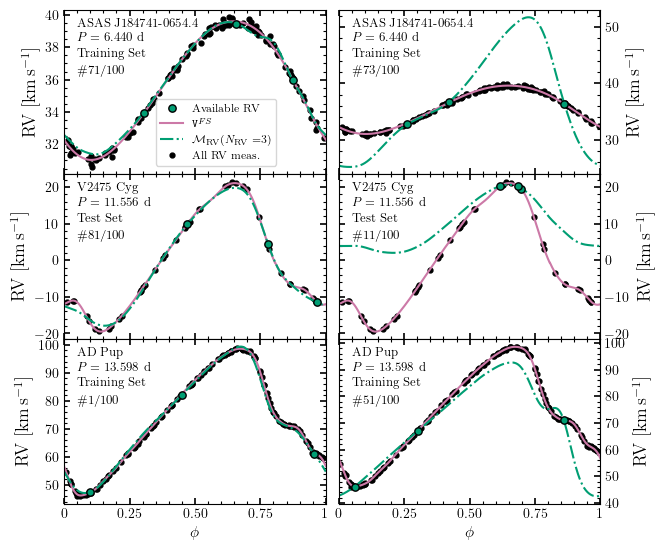

In [ ]:
# ff = plot_resample_paper(["AV Cir", "AV Cir", "V2475 Cyg", "V2475 Cyg", "AD Pup", "AD Pup"], 3, [40, 20, 80, 10, 0, 50])
ff = plot_resample_paper(
    [
        "ASAS J184741-0654.4",
        "ASAS J184741-0654.4",
        "V2475 Cyg",
        "V2475 Cyg",
        "AD Pup",
        "AD Pup",
    ],
    3,
    [70, 72, 80, 10, 0, 50],
)
ff.savefig(subsampling_plots_dir / "examples_fit_nrv.pdf", format="pdf")

In [397]:
np.log10(6.44)

np.float64(0.8088858673598122)

Plot $\Delta v_\gamma$, $\Delta P2P$ and $RMSE$

In [99]:
# comparison_df[(comparison_df.n_rv == 3) & (comparison_df.max_gap < 1.1)].sort_values(
#     "delta_vgamma"
# )

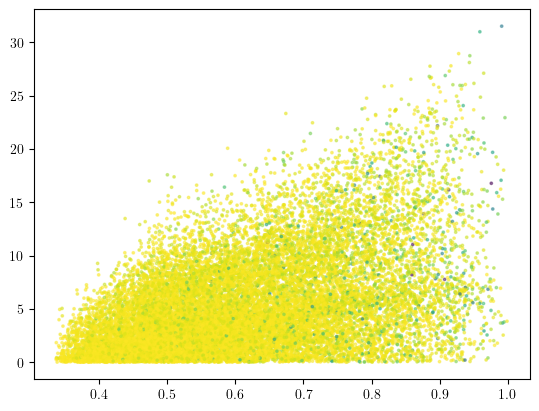

In [103]:
val = comparison_df[(comparison_df.n_rv == 3)]  # & (comparison_df.has_phase_prior)]
fig, axs = plt.subplots()
axs.scatter(
    val.max_gap,
    np.abs(val.delta_vgamma_fromnaive),
    alpha=0.5,
    c=np.abs(val.delta_vgamma),
    s=3,
    cmap="viridis_r",
)

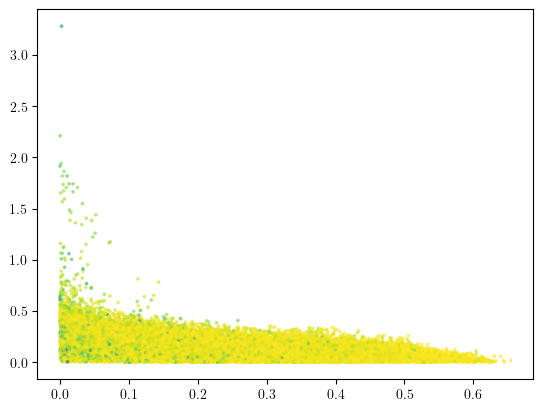

In [104]:
val = comparison_df[(comparison_df.n_rv == 3)]  # & (comparison_df.has_phase_prior)]
fig, axs = plt.subplots()
axs.scatter(
    val.rv_coverage * (1 - val.max_gap),
    np.abs(val.delta_vgamma_fromnaive) / val.veloce_p2p,
    alpha=0.5,
    c=np.abs(val.delta_vgamma),
    s=3,
    cmap="viridis_r",
)
# from matplotlib.patches import Arc
# radius = 1
# arc = Arc((0, 0), radius*2, radius*2, color='b', theta1=0, theta2=90)
# axs.add_patch(arc)
# axs.set_aspect(1)

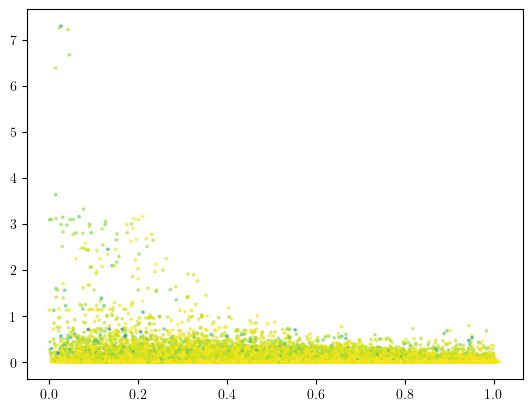

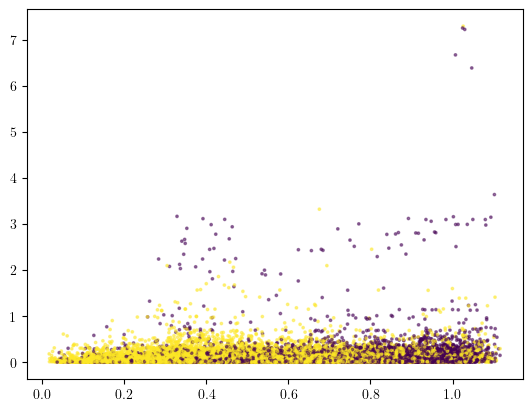

In [105]:
val = comparison_df[
    (comparison_df.n_rv == 3)
    # & (comparison_df.has_phase_prior)
    # # & (~comparison_df.single_branch)
    # & ((comparison_df.max_gap < 0.75) & (comparison_df.rv_coverage > 0.25))
]
fig, axs = plt.subplots()
axs.scatter(
    val.rv_coverage,
    np.abs(val.delta_p2p) / val.veloce_p2p,
    alpha=0.5,
    c=(np.abs(val.delta_vgamma)),
    s=3,
    cmap="viridis_r",
)
fig, axs = plt.subplots()
axs.scatter(
    val.centroid_offset,
    np.abs(val.delta_p2p_norm),
    alpha=0.5,
    c=(~val.has_phase_prior | val.single_branch),
    s=3,
    cmap="viridis_r",
)

In [117]:
val.sort_values("delta_vgamma")

,NAME,SET,log_P,n_rv,i_resample,has_phase_prior,veloce_p2p,delta_vgamma,delta_vgamma_fromnaive,delta_p2p,...,delta_vgamma_naive,delta_p2p_naive,delta_vgamma_naive_norm,delta_p2p_naive_norm,n_ascending,n_descending,frac_ascending,single_branch,rv_coverage,centroid_offset
1337,TT Aql,test,1.138448,3,37,False,53.246588,-19.522668,-4.595721,-1.593174,...,-14.926946,-19.030803,-0.280336,-0.357409,1,2,0.333333,False,0.662411,0.725671
13814,SV Mon,train,1.182840,3,38,True,59.186042,-19.065930,-4.840611,-8.182298,...,-14.225319,-29.042656,-0.240349,-0.490701,1,2,0.333333,False,0.591003,0.714567
11004,FM Aql,train,0.786368,3,4,False,38.503012,-16.141412,-8.857257,-0.135069,...,-7.284155,-20.701012,-0.189184,-0.537647,3,0,1.000000,True,0.463981,0.663643
11011,FM Aql,train,0.786368,3,11,False,38.503012,-16.063723,-7.785060,-0.101412,...,-8.278663,-17.801827,-0.215013,-0.462349,2,1,0.666667,False,0.539071,0.559590
11031,FM Aql,train,0.786368,3,31,False,38.503012,-15.870179,-4.679086,0.974483,...,-11.191094,-26.265827,-0.290655,-0.682176,3,0,1.000000,True,0.309979,0.844345
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11854,S Vul,train,1.838346,3,54,False,28.423531,16.217294,9.988395,0.798681,...,6.228899,-16.828868,0.219146,-0.592075,1,2,0.333333,False,0.396776,0.650701
10958,BB Sgr,train,0.821980,3,58,False,32.302002,16.315283,10.472860,7.344701,...,5.842423,-17.492682,0.180869,-0.541536,2,1,0.666667,False,0.373532,0.578027
11623,zet Gem,train,1.006446,3,23,False,27.583670,16.354974,8.210055,12.826137,...,8.144918,-8.846729,0.295280,-0.320723,0,3,0.000000,True,0.463673,0.819534
11396,T Mon,train,1.431934,3,96,False,46.475511,18.895766,16.237538,1.396911,...,2.658228,-18.339607,0.057196,-0.394608,3,0,1.000000,True,0.587727,0.586887


In [118]:
len(comparison_df[comparison_df.n_rv == 3])

21576

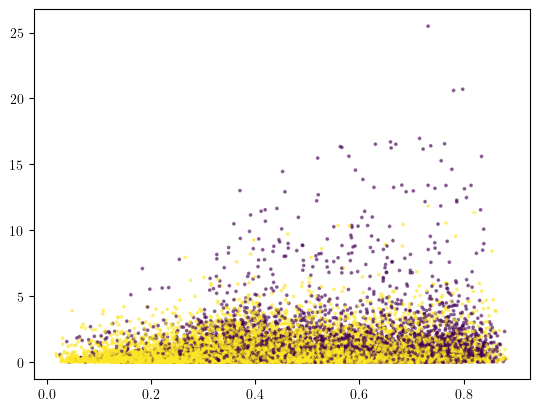

In [ ]:
val = comparison_df[
    (comparison_df.n_rv == 3)
    & (comparison_df.rv_coverage > 0.2)
    & (comparison_df.max_gap < 0.75)
]
fig, axs = plt.subplots()
axs.scatter(
    val.centroid_offset,
    np.abs(val.delta_vgamma),
    alpha=0.5,
    c=(~val.has_phase_prior | val.single_branch),
    s=3,
    cmap="viridis_r",
)

In [1061]:
val[val.has_phase_prior].sort_values("delta_vgamma", key=abs)

,NAME,SET,log_P,n_rv,i_resample,has_phase_prior,veloce_p2p,delta_vgamma,delta_p2p,rmse,...,delta_vgamma_naive,delta_p2p_naive,delta_vgamma_naive_norm,delta_p2p_naive_norm,n_ascending,n_descending,frac_ascending,single_branch,rv_coverage,centroid_offset
5265,ASAS J104300-6131.2,train,0.427236,3,65,True,12.137423,-0.000007,-0.564086,0.167501,...,1.225742,-1.168133,0.100989,-0.096242,3,0,1.000000,True,0.947807,0.355275
3757,AN Aur,train,1.012353,3,57,True,33.242859,0.000111,-2.772557,1.691526,...,0.049817,-3.094044,0.001499,-0.093074,2,1,0.666667,False,0.989449,0.630246
4509,ASAS J084412-3528.4,train,0.858302,3,9,True,15.034067,-0.000116,-0.492125,0.319499,...,1.663491,-4.995767,0.110648,-0.332296,2,1,0.666667,False,0.690300,0.216104
10360,MN Cam,train,0.912739,3,60,True,34.231275,0.000137,-0.368597,0.597854,...,8.074313,-4.695460,0.235875,-0.137169,2,1,0.666667,False,0.872223,0.535790
16694,V0371 Gem,train,0.329902,3,10,True,18.064928,0.000154,0.012210,0.288479,...,-2.057332,-6.055858,-0.113885,-0.335227,1,2,0.333333,False,0.664324,0.416444
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20596,X Cyg,train,1.214488,3,12,True,54.300030,13.187391,-5.515986,1.660185,...,8.011374,-28.432625,0.147539,-0.523621,3,0,1.000000,True,0.530243,0.745171
19649,VY Car,train,1.276056,3,65,True,57.343470,13.253647,-1.195369,0.536205,...,-1.775753,-26.860900,-0.030967,-0.468421,3,0,1.000000,True,0.542896,0.665930
14019,SV Mon,train,1.182840,3,35,True,59.186042,13.406380,-7.374653,1.823934,...,10.505023,-35.570582,0.177492,-0.600996,3,0,1.000000,True,0.455797,0.814455
14070,SV Mon,train,1.182840,3,86,True,59.186042,13.428912,-5.333325,1.469897,...,7.594883,-27.962792,0.128322,-0.472456,3,0,1.000000,True,0.579790,0.681592


In [ ]:
comparison_df[
    (comparison_df.n_rv == 3) & (comparison_df.centroid_offset < 0.45)
].sort_values("delta_vgamma_norm")

,NAME,SET,log_P,n_rv,i_resample,has_phase_prior,delta_vgamma,delta_p2p,rmse,delta_vgamma_norm,...,delta_vgamma_naive,delta_p2p_naive,delta_vgamma_naive_norm,delta_p2p_naive_norm,n_ascending,n_descending,frac_ascending,single_branch,rv_coverage,centroid_offset
1404,alf UMi,test,0.599011,3,4,False,-2.331092,10.959329,3.867903,-0.661176,...,-0.616611,-2.798310,-0.174892,-0.793695,1,2,0.333333,False,0.050215,0.443708
12031,S Vul,train,1.838346,3,31,False,-9.349289,-1.633589,1.133081,-0.328928,...,-3.122414,-10.549442,-0.109853,-0.371152,2,1,0.666667,False,0.667194,0.406909
21155,Y Oph,train,1.233694,3,71,True,-5.207629,36.685195,11.859136,-0.294821,...,2.179482,-13.615146,0.123388,-0.770799,1,2,0.333333,False,0.074492,0.447832
11419,TZ Mon,train,0.870884,3,19,False,-11.446666,-1.411597,0.804308,-0.286254,...,-3.481250,-18.135845,-0.087058,-0.453534,2,1,0.666667,False,0.566463,0.411582
11209,FM Aql,train,0.786368,3,9,False,-10.494282,0.371554,1.180337,-0.272557,...,-0.799278,-12.756565,-0.020759,-0.331313,2,1,0.666667,False,0.662295,0.359292
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1454,alf UMi,test,0.599011,3,54,False,1.509433,10.965277,3.907944,0.428126,...,-0.443653,-2.854822,-0.125835,-0.809724,2,1,0.666667,False,0.046294,0.438996
1483,alf UMi,test,0.599011,3,83,False,1.576578,6.166261,1.991205,0.447171,...,-0.101590,-0.241816,-0.028814,-0.068587,2,1,0.666667,False,0.338824,0.440800
1433,alf UMi,test,0.599011,3,33,False,1.616894,9.905411,3.448953,0.458606,...,-0.212890,-1.602863,-0.060383,-0.454626,2,1,0.666667,False,0.143161,0.442948
1413,alf UMi,test,0.599011,3,13,False,2.019071,9.005294,3.088802,0.572677,...,0.830484,-1.124331,0.235553,-0.318898,1,2,0.333333,False,0.191633,0.441380


In [ ]:
comparison_df[comparison_df["i_resample"] > 100]

,NAME,SET,log_P,n_rv,i_resample,has_phase_prior,delta_vgamma,delta_p2p,rmse,delta_vgamma_norm,...,delta_vgamma_naive,delta_p2p_naive,delta_vgamma_naive_norm,delta_p2p_naive_norm,n_ascending,n_descending,frac_ascending,single_branch,rv_coverage,centroid_offset


In [88]:
len(comparison_df[comparison_df["n_rv"] == 3])

21584

In [90]:
xx = val.groupby("NAME").count()
xx[xx.n_rv != 100]

,SET,log_P,n_rv,i_resample,has_phase_prior,veloce_p2p,delta_vgamma,delta_vgamma_fromnaive,delta_p2p,delta_p2p_fromnaive,...,delta_vgamma_naive,delta_p2p_naive,delta_vgamma_naive_norm,delta_p2p_naive_norm,n_ascending,n_descending,frac_ascending,single_branch,rv_coverage,centroid_offset
NAME,,,,,,,,,,,,,,,,,,,,,
V1197 Cen,84,84,84,84,84,84,84,84,84,84,...,84,84,84,84,84,84,84,84,84,84


In [110]:
def percentile_err(arr):
    q16, q50, q84 = np.quantile(arr, [0.16, 0.50, 0.84])
    return np.array([q50 - q16, q84 - q50])


def plot_results_stats_subsampling(df, nrv, report_delta_phase=True):

    df_nrv_name = df[df["n_rv"] == nrv].groupby("NAME")

    summary_nrv = df_nrv_name.agg(
        log_P=("log_P", "first"),
        SET=("SET", "first"),
        has_phase_prior=("has_phase_prior", "first"),
        vgamma_mean=("delta_vgamma", "mean"),
        vgamma_std=("delta_vgamma", "std"),
        p2p_mean=("delta_p2p", "mean"),
        p2p_std=("delta_p2p", "std"),
        rmse_mean=("rmse", "mean"),
        rmse_std=("rmse", "std"),
        delta_phi=("diff_delta_phi", "mean"),
        delta_phi_std=("diff_delta_phi", "std"),
    ).reset_index()

    pe = df_nrv_name["diff_delta_phi"].apply(percentile_err)
    summary_nrv["percentile_err_dphi"] = summary_nrv["NAME"].map(pe)
    pe = df_nrv_name["delta_vgamma"].apply(percentile_err)
    summary_nrv["percentile_err_dvgamma"] = summary_nrv["NAME"].map(pe)
    pe = df_nrv_name["delta_p2p"].apply(percentile_err)
    summary_nrv["percentile_err_dp2p"] = summary_nrv["NAME"].map(pe)
    pe = df_nrv_name["rmse"].apply(percentile_err)
    print(pe["AD Pup"])
    summary_nrv["percentile_err_rmse"] = summary_nrv["NAME"].map(pe)
    # Plot the results
    width = 3.46 * 1.5
    height = width * 2 / 1.618
    height = height * 4 / 3 if report_delta_phase else height  # / 2
    fig, axs = plt.subplots(
        (4 if report_delta_phase else 3),
        1,
        figsize=(width, height),
        sharex=True,
        gridspec_kw={"hspace": 0},
    )
    axs[0].set_title(
        (
            r"Subsampling analysis for $N_{\rm RV} = "
            f"{nrv}$ ({len(summary_nrv)} targets)"
        ),
        fontsize=12,
        fontweight="bold",
    )

    mean_names = ["delta_phi", "vgamma_mean", "p2p_mean", "rmse_mean"]
    std_names = ["delta_phi_std", "vgamma_std", "p2p_std", "rmse_std"]
    # perc_names = ["percentile_err_dphi", "percentile_err_dvgamma", "percentile_err_dp2p", "percentile_err_rmse"]
    quantity_labels = [
        r"$\Delta \phi$",
        r"$\Delta v_\gamma$",
        r"$\Delta P2P$",
        r"$\mathrm{RMSE}$",
    ]
    quantity_labels_nomath = [
        r"\Delta \phi",
        r"\Delta v_\gamma",
        r"\Delta P2P",
        r"\mathrm{RMSE}",
    ]
    unit = ["", "km/s", "km/s", "km/s"]
    pos_text_x = [0.63, 0.03, 0.03, 0.03]
    pos_text_y = [0.05, 0.05, 0.05, 0.95]
    verticalalignment_text = ["bottom", "bottom", "bottom", "top"]
    summary_nrv["SET_color"] = summary_nrv["SET"].apply(
        lambda x: color_safe["blue"] if x == "train" else color_safe["dark_orange"]
    )
    summary_nrv_no_phase = summary_nrv[~summary_nrv.has_phase_prior]

    for j, ax in enumerate(axs):
        i = j
        if not report_delta_phase:
            i += 1
        mean_val = summary_nrv[mean_names[i]]
        std_val = summary_nrv[std_names[i]]
        # perc_val = np.stack(summary_nrv[perc_names[i]].to_numpy()).T
        # perc_val_no_phase = np.stack(summary_nrv_no_phase[perc_names[i]].to_numpy()).T
        ax.errorbar(
            summary_nrv["log_P"],
            mean_val,
            yerr=std_val,
            fmt=",",
            lw=0.5,
            color=color_safe["black"],
            zorder=3,
        )
        ax.errorbar(
            summary_nrv_no_phase["log_P"],
            summary_nrv_no_phase[mean_names[i]],
            yerr=summary_nrv_no_phase[std_names[i]],
            fmt=",",
            lw=0.8,
            color=color_safe["light_green"],
            zorder=4,
            capsize=1,
        )

        ax.scatter(
            summary_nrv["log_P"],
            mean_val,
            c=summary_nrv["SET_color"],
            s=25,
            alpha=1,
            marker="o",
            edgecolors="k",
            linewidths=0.5,
            zorder=5,
        )
        ax.axhline(0, color="black", lw=0.5, ls="--", zorder=6)

        ylabel = quantity_labels[i] + (f" [{unit[i]}]" if unit[i] else "")
        ax.set_ylabel(ylabel, fontsize=13)

        x_ticks = np.arange(0.2, 2, 0.2)
        x_ticks_minor = np.arange(0.2, 2, 0.05)
        vf.plots_utils.format_xticks(ax, x_ticks, x_ticks_minor)
        ax.set_xlim(0.22, 1.9)

        # Get the y-axis limits
        ylim = ax.get_ylim()
        y_steps = [1, 0.5]
        if nrv == 20:
            y_steps = [0.5, 0.25]
        if (ylim[1] - ylim[0]) > 10:
            y_steps = [2, 1]
        if (ylim[1] - ylim[0]) > 20:
            y_steps = [5, 1]

        if i == 0:
            y_steps = [0.1, 0.02]

        y_ticks = np.arange(-30, 30, y_steps[0])
        y_ticks_minor = np.arange(-30, 30, y_steps[1])
        vf.plots_utils.format_yticks(ax, y_ticks, y_ticks_minor)
        ax.set_ylim(*ylim)
        # Add text with the mean and std
        text = (
            r"$\overline{"
            + quantity_labels_nomath[i]
            + "} "
            + (
                f"= {np.mean(mean_val.to_numpy()):.3f}"
                if unit[i]
                else f"= {np.mean(mean_val.to_numpy()):.4f}"
            )
            + (f"$ [{unit[i]}]\n" if unit[i] else f"$\n")
        )
        if quantity_labels[i] != r"$\mathrm{RMSE}$":
            text += (
                r"$\sigma("
                + quantity_labels_nomath[i]
                + (
                    f") = {np.std(mean_val.to_numpy()):.3f}"
                    if unit[i]
                    else f") = {np.std(mean_val.to_numpy()):.4f}"
                )
                + (f"$ [{unit[i]}]" if unit[i] else f"$")
            )

        ax.text(
            pos_text_x[i],
            pos_text_y[i],
            s=text,
            fontsize=10,
            verticalalignment=verticalalignment_text[i],
            horizontalalignment="left",
            transform=ax.transAxes,
        )

    axs[-1].set_xlabel(r"$\log P$ [days]", fontsize=13)

    fig.tight_layout()

    return summary_nrv

[3.99618048 3.38109183]


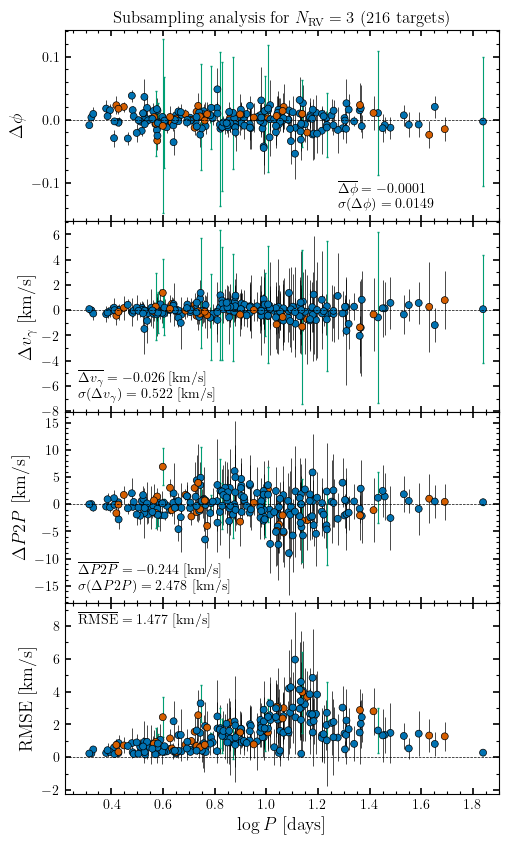

In [111]:
summ_nrv = plot_results_stats_subsampling(comparison_df, 3, report_delta_phase=True)

In [ ]:
def percentile_err(arr):
    q16, q50, q84 = np.quantile(arr, [0.16, 0.50, 0.84])
    return np.array([q50 - q16, q84 - q50])


def plot_results_stats_subsampling_median(df, nrv, report_delta_phase=True):

    df_nrv_name = df[df["n_rv"] == nrv].groupby("NAME")

    summary_nrv = df_nrv_name.agg(
        log_P=("log_P", "first"),
        SET=("SET", "first"),
        has_phase_prior=("has_phase_prior", "first"),
        vgamma_median=("delta_vgamma", "median"),
        p2p_median=("delta_p2p", "median"),
        rmse_median=("rmse_norm", "median"),
        delta_phi=("diff_delta_phi", "median"),
    ).reset_index()

    pe = df_nrv_name["diff_delta_phi"].apply(percentile_err)
    summary_nrv["percentile_err_dphi"] = summary_nrv["NAME"].map(pe)
    pe = df_nrv_name["delta_vgamma"].apply(percentile_err)
    summary_nrv["percentile_err_dvgamma"] = summary_nrv["NAME"].map(pe)
    pe = df_nrv_name["delta_p2p"].apply(percentile_err)
    summary_nrv["percentile_err_dp2p"] = summary_nrv["NAME"].map(pe)
    pe = df_nrv_name["rmse_norm"].apply(percentile_err)
    summary_nrv["percentile_err_rmse"] = summary_nrv["NAME"].map(pe)

    summary_nrv["rmse_median"] = summary_nrv["rmse_median"] * 100
    summary_nrv["percentile_err_rmse"] = summary_nrv["percentile_err_rmse"] * 100
    summary_nrv_copy = summary_nrv.copy()

    # Plot the results
    width = 3.46 * 1.5
    height = width * 2 / 1.618
    height = height * 4 / 3 if report_delta_phase else height  # / 2
    fig, axs = plt.subplots(
        (4 if report_delta_phase else 3),
        1,
        figsize=(width, height),
        sharex=True,
        gridspec_kw={"hspace": 0},
    )
    axs[0].set_title(
        (
            r"Subsampling analysis for $N_{\rm RV} = "
            f"{nrv}$ ({len(summary_nrv)} targets)"
        ),
        fontsize=12,
        fontweight="bold",
    )

    median_names = ["delta_phi", "vgamma_median", "p2p_median", "rmse_median"]
    perc_names = [
        "percentile_err_dphi",
        "percentile_err_dvgamma",
        "percentile_err_dp2p",
        "percentile_err_rmse",
    ]
    quantity_labels = [
        r"$\Delta \phi - \Delta \phi_{E_G}$",
        r"$\Delta v_\gamma$",
        r"$\Delta P2P$",
        r"$\mathrm{RMSE}/P2P \cdot 100$",
    ]
    quantity_labels_nomath = [
        r"\Delta \phi - \Delta \phi_{E_G}",
        r"\Delta v_\gamma",
        r"\Delta P2P",
        r"\mathrm{RMSE}/ P2P \cdot 100",
    ]
    unit = ["", "km\,s$^{-1}$", "km\,s$^{-1}$", "\%"]
    pos_text_x = [0.53, 0.03, 0.03, 0.43]
    pos_text_y = [0.95, 0.05, 0.05, 0.95]
    verticalalignment_text = ["top", "bottom", "bottom", "top"]
    summary_nrv["SET_color"] = summary_nrv["SET"].apply(
        lambda x: color_safe["blue"] if x == "train" else color_safe["dark_orange"]
    )
    summary_nrv_no_phase = summary_nrv[~summary_nrv.has_phase_prior]
    summary_nrv_no_phase_copy = summary_nrv_no_phase.copy()

    for j, ax in enumerate(axs):
        i = j
        if not report_delta_phase:
            i += 1

        if i == 3:
            print("removed_alf UMI from RMSE")
            print("rmse", summary_nrv[summary_nrv.NAME == "alf UMi"]["rmse_median"])
            print(
                "rmse-spread",
                summary_nrv[summary_nrv.NAME == "alf UMi"]["percentile_err_rmse"],
            )
            summary_nrv = summary_nrv[summary_nrv.NAME != "alf UMi"]
            summary_nrv_no_phase = summary_nrv_no_phase[
                summary_nrv_no_phase.NAME != "alf UMi"
            ]

        median_val = summary_nrv[median_names[i]]
        perc_val = np.stack(summary_nrv[perc_names[i]].to_numpy()).T
        perc_val_no_phase = np.stack(summary_nrv_no_phase[perc_names[i]].to_numpy()).T
        ax.errorbar(
            summary_nrv["log_P"],
            median_val,
            yerr=perc_val,
            fmt=",",
            lw=0.5,
            color=color_safe["black"],
            zorder=3,
        )
        ax.errorbar(
            summary_nrv_no_phase["log_P"],
            summary_nrv_no_phase[median_names[i]],
            yerr=perc_val_no_phase,
            fmt=",",
            lw=0.8,
            color=color_safe["light_green"],
            zorder=4,
            capsize=1.8,
        )

        ax.scatter(
            summary_nrv["log_P"],
            median_val,
            c=summary_nrv["SET_color"],
            s=25,
            alpha=1,
            marker="o",
            edgecolors="k",
            linewidths=0.5,
            zorder=5,
        )
        ax.axhline(0, color="black", lw=0.5, ls="--", zorder=6)

        ylabel = quantity_labels[i] + (f" [{unit[i]}]" if unit[i] else "")
        ax.set_ylabel(ylabel, fontsize=13)

        x_ticks = np.arange(0.2, 2, 0.2)
        x_ticks_minor = np.arange(0.2, 2, 0.05)
        vf.plots_utils.format_xticks(ax, x_ticks, x_ticks_minor)
        ax.set_xlim(0.22, 1.9)

        # Get the y-axis limits
        ylim = ax.get_ylim()
        y_steps = [1, 0.5]
        if nrv == 20:
            y_steps = [0.5, 0.25]
        if (ylim[1] - ylim[0]) > 10:
            y_steps = [2, 1]
        if (ylim[1] - ylim[0]) > 20:
            y_steps = [5, 1]

        if i == 0:
            y_steps = [0.1, 0.02] if nrv == 3 else [0.02, 0.01]
        if i == 3:
            y_steps = [5, 1]

        y_ticks = np.arange(-30, 50, y_steps[0])
        y_ticks_minor = np.arange(-30, 50, y_steps[1])
        vf.plots_utils.format_yticks(ax, y_ticks, y_ticks_minor)
        ax.set_ylim(*ylim)
        # Add text with the mean and std

        if i != 3:
            text = (
                r"$M("
                + quantity_labels_nomath[i]
                + ") "
                + (
                    f"= {np.median(median_val.to_numpy()):.3f}"
                    if i != 0
                    else f"= {np.median(median_val.to_numpy()):.4f}"
                )
                + (f"$ [{unit[i]}]\n" if unit[i] else f"$\n")
            )
            text += (
                r"$\mathrm{MAD}("
                + quantity_labels_nomath[i]
                + (
                    # f") = {np.sum(percentile_err(median_val.to_numpy()) *0.5):.3f}"
                    # if unit[i]
                    # else f") = {np.sum(percentile_err(median_val.to_numpy()) *0.5):.4f}"
                    f") = {sp.stats.median_abs_deviation((median_val.to_numpy())):.3f}"
                    if i != 0
                    else f") = {sp.stats.median_abs_deviation(median_val.to_numpy()):.4f}"
                )
                + (f"$ [{unit[i]}]" if unit[i] else f"$")
            )
        else:
            text = (
                r"$M("
                + quantity_labels_nomath[i]
                + ") "
                + (f"= {np.median(median_val.to_numpy()):.2f}")
                + (f"$ [{unit[i]}]\n" if unit[i] else f"$\n")
            )
            text += (
                r"$Q_{90}("
                + quantity_labels_nomath[i]
                + (
                    # f") = {np.sum(percentile_err(median_val.to_numpy()) *0.5):.3f}"
                    # if unit[i]
                    # else f") = {np.sum(percentile_err(median_val.to_numpy()) *0.5):.4f}"
                    f") = {np.quantile(median_val.to_numpy(), 0.9):.2f}"
                )
                + (f"$ [{unit[i]}]" if unit[i] else f"$")
            )

        ax.text(
            pos_text_x[i],
            pos_text_y[i],
            s=text,
            fontsize=10,
            verticalalignment=verticalalignment_text[i],
            horizontalalignment="left",
            transform=ax.transAxes,
        )

    axs[-1].set_xlabel(r"$\log P$ [days]", fontsize=13)

    fig.tight_layout()
    fig.savefig(subsampling_dir / f"subsampling_{nrv}_dist.pdf", format="pdf")

    return summary_nrv_copy

<>:72: SyntaxWarning: "\," is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\,"? A raw string is also an option.
<>:72: SyntaxWarning: "\," is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\,"? A raw string is also an option.
<>:72: SyntaxWarning: "\%" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\%"? A raw string is also an option.
<>:72: SyntaxWarning: "\," is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\,"? A raw string is also an option.
<>:72: SyntaxWarning: "\," is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\,"? A raw string is also an option.
<>:72: SyntaxWarning: "\%" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\%"? A raw string is also an option.
/var/folders/hm/6rf5cwbj6x74z7zlmzpbdwx80000gn/T/ipykernel_4005/1135499884.p

removed_alf UMI from RMSE
rmse 210    76.439497
Name: rmse_median, dtype: float64
rmse-spread 210    [50.72791187339358, 29.427116181648483]
Name: percentile_err_rmse, dtype: object


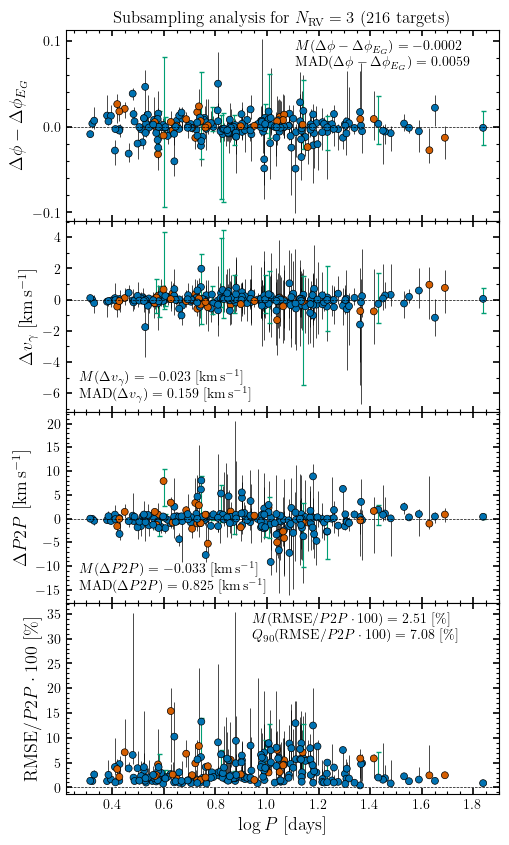

In [270]:
summ_nrv_medi = plot_results_stats_subsampling_median(
    comparison_df,
    3,
    report_delta_phase=True,
)

In [271]:
summ_nrv_medi.columns

Index(['NAME', 'log_P', 'SET', 'has_phase_prior', 'vgamma_median',
       'p2p_median', 'rmse_median', 'delta_phi', 'percentile_err_dphi',
       'percentile_err_dvgamma', 'percentile_err_dp2p', 'percentile_err_rmse'],
      dtype='str')

In [272]:
summ_nrv_medi[(summ_nrv_medi.log_P < 0.6) & (summ_nrv_medi.NAME != "alf UMi")][
    "rmse_median"
].describe()

count    42.000000
mean      2.557997
std       1.448478
min       0.749848
25%       1.353944
50%       2.200503
75%       3.389320
max       7.084110
Name: rmse_median, dtype: float64

In [ ]:
summ_nrv_medi["max_rmse"] = summ_nrv_medi.rmse_median + np.array(
    [rr[1] for rr in summ_nrv_medi.percentile_err_rmse]
)

In [274]:
summ_nrv_medi.sort_values(by="max_rmse", ascending=False).head(10)

,NAME,log_P,SET,has_phase_prior,vgamma_median,p2p_median,rmse_median,delta_phi,percentile_err_dphi,percentile_err_dvgamma,percentile_err_dp2p,percentile_err_rmse,max_rmse
210,alf UMi,0.599011,test,False,0.646390,7.889970,76.439497,-0.010402,"[0.08377969868747995, 0.09087504869993718]","[1.2269129541148205, 3.6716169595638233]","[5.34164193772081, 2.6316102349990107]","[50.72791187339358, 29.427116181648483]",105.866613
79,IT Car,0.876967,train,True,0.078700,0.401079,1.313620,-0.004100,"[0.00811311225530409, 0.00479690633453745]","[0.204619292781432, 1.5452998978218986]","[0.4432709473029808, 20.12947799967052]","[0.48960010265129245, 34.04925399314621]",35.362874
11,ASAS J064540+0330.4,0.479244,train,True,-0.056270,0.606656,6.550150,0.038377,"[0.007895618432355863, 0.006429059981524023]","[0.6536603658664666, 0.7531367557029278]","[0.6695624177944262, 4.717248057670805]","[1.840309278738402, 28.523881585884347]",35.074032
150,V0378 Cen,0.810232,train,True,-0.333426,0.162128,9.091302,0.049926,"[0.04399048016992252, 0.03674620205765945]","[1.9960855020273014, 2.4601227233296994]","[3.0760154312515047, 13.369397143155279]","[7.267677490823591, 15.848191064732331]",24.939493
195,X Lac,0.736028,test,True,0.068446,2.800834,8.343655,0.023544,"[0.02253200099474409, 0.02048908673051203]","[1.7384457223288403, 1.3155053303826008]","[6.7437222674867465, 12.634640535922571]","[2.172037611659446, 15.7427442812433]",24.086400
77,HW Car,0.963752,train,True,-0.001923,-0.072169,0.841511,0.002796,"[0.003252331484769735, 0.004909025281461009]","[0.20058469879300408, 0.42385855484014023]","[0.2550954190440733, 10.463209332758954]","[0.17505162913543354, 21.266926259865713]",22.108438
176,V1726 Cyg,0.627061,test,True,0.027783,3.345005,15.395367,0.005432,"[0.017713689269644825, 0.012684385117852734]","[0.7931655923538059, 1.1914162053526238]","[2.6136934050622593, 1.2133583413285525]","[10.350039678523665, 4.598712359205254]",19.994080
46,CH Cas,1.178747,train,True,-1.013276,8.876062,12.485336,-0.021887,"[0.043950907987380924, 0.03599135964231391]","[2.042162064625622, 2.7016171982622414]","[11.364366320164898, 2.6039312269339803]","[9.94862833711418, 7.477539551228883]",19.962875
183,VX Per,1.036724,train,True,-0.089403,0.952876,4.328157,-0.012872,"[0.033047703530873634, 0.01605753698296632]","[0.7550982410632763, 1.2024796418281245]","[1.6816937227054163, 8.259197942607141]","[1.7536032561539947, 15.083225236012051]",19.411382
48,CR Car,0.989360,train,True,-0.274188,2.126462,7.044306,-0.038125,"[0.030192735061600112, 0.022982544484227044]","[2.3155674618648225, 2.7620946439602765]","[2.1313631618085354, 7.466392219267663]","[3.4035770205161784, 12.351009884497902]",19.395316


In [ ]:
summ_nrv_medi[
    (summ_nrv_medi.log_P > 0.8)
    & (summ_nrv_medi.log_P < 1)
    & (summ_nrv_medi.rmse_median > 0)
]

,NAME,log_P,SET,has_phase_prior,vgamma_median,p2p_median,rmse_median,delta_phi,percentile_err_dphi,percentile_err_dvgamma,percentile_err_dp2p,percentile_err_rmse,max_rmse
2,AC Mon,0.903903,train,True,0.238257,-1.403794,2.629298,-0.002915,"[0.011899351754913969, 0.007899780690512337]","[0.6387997176851474, 0.8255231997721257]","[1.864330529116073, 1.7626752543372124]","[0.5826250495326295, 0.31573498748364986]",2.945033
5,AK Cep,0.859295,test,True,-0.328732,1.473755,5.562593,0.001084,"[0.01188291589747887, 0.019380526514787284]","[1.240418614523936, 1.450933331813746]","[5.624350595673383, 1.9775593592965368]","[1.3822605560152703, 0.8505257973383161]",6.413119
8,AQ Car,0.989876,train,True,-0.089977,-0.826687,1.489451,-0.000047,"[0.008884464587259203, 0.007962635977889817]","[0.8770513582341914, 0.5626010297453512]","[1.552556498249415, 0.5333200626444574]","[0.12769097338906546, 4.532580920620555]",6.022032
15,ASAS J084412-3528.4,0.858302,train,True,0.086409,0.357287,1.585251,-0.007839,"[0.010052161052555866, 0.006348368184529118]","[0.2795024620291703, 1.1000807346089663]","[0.6167996108101204, 1.3011704914765336]","[0.6968911908204629, 11.697029842233961]",13.282281
31,ASAS J184741-0654.4,0.808880,train,True,-0.070043,0.187617,2.479465,0.018905,"[0.008994029867582909, 0.008755416503556285]","[0.2152578849364703, 0.3347258839003696]","[0.5020041975556294, 0.35725721325832704]","[0.7006722989853155, 1.2787657892442794]",3.758231
35,AW Per,0.810490,train,True,-0.690538,-1.603781,3.032171,0.006243,"[0.007108643646030404, 0.016215927216490966]","[0.9421760563495227, 0.6872691043548178]","[1.2410246428750842, 0.8945959108106545]","[0.8572577664107489, 1.2837194117189568]",4.315891
37,BB Sgr,0.821980,train,False,0.417307,5.270548,6.674692,-0.003689,"[0.08071184652579413, 0.017067132494881752]","[0.8706860992446898, 3.5240675844327067]","[5.989889790124513, 1.8448101605243759]","[4.869222375016379, 0.9178674823786481]",7.592559
39,BG Vel,0.840348,train,True,0.279175,0.296060,1.680852,-0.005882,"[0.01714094801769831, 0.0066803280986646105]","[0.49254066596533236, 1.3478247800120882]","[0.49910506851256337, 11.405126565355092]","[0.30488986596181983, 12.560914274573806]",14.241766
40,BK Aur,0.903236,train,True,0.094175,1.089636,1.937553,0.001117,"[0.007553948749792558, 0.009056219566688416]","[0.7933559737417055, 0.7964629964463988]","[1.0154155868843366, 2.278127435034583]","[0.27974742291923194, 1.871178796942866]",3.808732
48,CR Car,0.989360,train,True,-0.274188,2.126462,7.044306,-0.038125,"[0.030192735061600112, 0.022982544484227044]","[2.3155674618648225, 2.7620946439602765]","[2.1313631618085354, 7.466392219267663]","[3.4035770205161784, 12.351009884497902]",19.395316


In [228]:
summ_nrv_medi[summ_nrv_medi.NAME == "alf UMi"]["rmse_median"]

210    76.439497
Name: rmse_median, dtype: float64

In [ ]:
summ_nrv_medi[(summ_nrv_medi.log_P < 1.3) & (summ_nrv_medi.log_P > 1)][
    "rmse_median"
].quantile(0.9)

np.float64(4.070937885233068)

In [ ]:
summ_nrv_medi[summ_nrv_medi.log_P > 1.3]["rmse_median"].quantile(0.9)

np.float64(2.913059467405467)

In [137]:
summ_nrv_medi["delta_phi"].describe()

count    216.000000
mean      -0.000324
std        0.013167
min       -0.048943
25%       -0.005559
50%       -0.000187
75%        0.006224
max        0.049926
Name: delta_phi, dtype: float64

In [268]:
def compatible_with_zero(df, nrv):

    df_nrv_name = df[df["n_rv"] == nrv].groupby("NAME")

    summary_nrv = df_nrv_name.agg(
        log_P=("log_P", "first"),
        SET=("SET", "first"),
        has_phase_prior=("has_phase_prior", "first"),
        vgamma_median=("delta_vgamma", "median"),
        p2p_median=("delta_p2p", "median"),
        rmse_median=("rmse_norm", "median"),
        delta_phi=("diff_delta_phi", "median"),
    ).reset_index()
    print(len(summary_nrv))

    pe = df_nrv_name["diff_delta_phi"].apply(percentile_err)
    summary_nrv["percentile_err_dphi"] = summary_nrv["NAME"].map(pe)
    pe = df_nrv_name["delta_vgamma"].apply(percentile_err)
    summary_nrv["percentile_err_dvgamma"] = summary_nrv["NAME"].map(pe)
    pe = df_nrv_name["delta_p2p"].apply(percentile_err)
    summary_nrv["percentile_err_dp2p"] = summary_nrv["NAME"].map(pe)
    pe = df_nrv_name["rmse_norm"].apply(percentile_err)
    summary_nrv["percentile_err_rmse"] = summary_nrv["NAME"].map(pe)

    summary_nrv["rmse_median"] = summary_nrv["rmse_median"] * 100
    summary_nrv["percentile_err_rmse"] = summary_nrv["percentile_err_rmse"] * 100

    # 16th and 84th percentiles per target for each metric
    q16 = df_nrv_name[["delta_vgamma", "delta_p2p", "diff_delta_phi"]].quantile(0.05)
    q84 = df_nrv_name[["delta_vgamma", "delta_p2p", "diff_delta_phi"]].quantile(0.95)

    # Compatible with 0: interval [p16, p84] straddles zero
    compatible = (q16 <= 0) & (q84 >= 0)

    frac_compatible_dvgamma = compatible["delta_vgamma"].mean()
    frac_compatible_dp2p = compatible["delta_p2p"].mean()
    frac_compatible_dphi = compatible["diff_delta_phi"].mean()

    # Fraction of targets with |median delta_vgamma| within 1 km/s of 0
    frac_vgamma_within_1 = (summary_nrv["vgamma_median"].abs() <= 1.0).mean()

    return {
        "frac_compatible_dvgamma": frac_compatible_dvgamma,
        "frac_compatible_dp2p": frac_compatible_dp2p,
        "frac_compatible_dphi": frac_compatible_dphi,
        "frac_vgamma_within_1km": frac_vgamma_within_1,
    }

In [269]:
compatible_with_zero(comparison_df, 3)

216


{'frac_compatible_dvgamma': np.float64(0.9953703703703703),
 'frac_compatible_dp2p': np.float64(0.8703703703703703),
 'frac_compatible_dphi': np.float64(0.8518518518518519),
 'frac_vgamma_within_1km': np.float64(0.9629629629629629)}

In [178]:
0.6481481481481481 * 216

140.0

In [708]:
summ_nrv_medi.sort_values(by="log_P")

,NAME,log_P,SET,has_phase_prior,vgamma_median,p2p_median,rmse_median,delta_phi,percentile_err_dphi,percentile_err_dvgamma,percentile_err_dp2p,percentile_err_rmse
137,V0397 Car,0.314597,train,True,-0.004987,0.000505,0.566127,-0.000642,"[0.0028597593098606076, 0.0023205458132746215]","[0.043330319702198, 0.03523919583670483]","[0.08672765580544813, 0.07073693608968741]","[0.1742028294015102, 0.40729405448781464]"
52,EU Tau,0.322684,train,True,-0.008252,-0.109246,1.220539,-0.000122,"[0.0035597029427694837, 0.006631210688929484]","[0.06978992795777009, 0.07594937010968238]","[0.2129183408931326, 0.2786119956401153]","[0.2574017506207763, 0.6957678292474311]"
133,V0371 Gem,0.329902,train,True,-0.075270,-0.193632,1.580454,0.002741,"[0.002692897646776542, 0.15408438598011404]","[0.8749878249306352, 0.07545139798140808]","[0.5961020514098881, 0.21355273295187746]","[0.39897608458513634, 31.828868449316587]"
35,BP Cir,0.379872,train,True,-0.011946,-0.055666,0.756136,0.000943,"[0.0019768279096151666, 0.006488069808183684]","[0.06279214395403308, 0.051097990540763256]","[0.18382405300444604, 0.12744380082324977]","[0.27949726745091036, 0.9472547080369976]"
72,LR TrA,0.385300,train,True,-0.014934,-0.059393,1.314584,0.003166,"[0.00344129428332701, 0.0038989644035225396]","[0.030293055746863473, 0.04114326797302098]","[0.10299931663948081, 0.1026321979934586]","[0.3345537490825978, 0.45251567627015293]"
...,...,...,...,...,...,...,...,...,...,...,...,...
121,U Car,1.589301,train,True,-0.029547,1.299294,1.906280,0.000495,"[0.0026405864016042415, 0.004129242531221005]","[0.3219163148768432, 0.32660002424356754]","[1.0337564399789856, 1.3484578093267081]","[0.31855484798979583, 0.6301816886981569]"
23,ASAS J180342-2211.0,1.629913,test,True,0.014267,-0.201041,1.568003,-0.002206,"[0.005042844202797926, 0.0016713768679682982]","[0.15886990514083027, 0.25379633703804566]","[0.5982787754152216, 0.5837313585146603]","[0.1772104365115202, 0.49623609541208125]"
104,SV Vul,1.651596,train,True,0.059478,-0.784201,1.931663,-0.000634,"[0.0077765595057245705, 0.012977479525656678]","[0.4459571242193372, 0.6682900806196596]","[2.357664512787307, 1.5175962582953566]","[0.6163540471875929, 5.180574398677814]"
62,GS Lup,1.690158,test,True,0.028594,0.945600,1.736096,-0.001118,"[0.005297416534469324, 0.0036920055276968484]","[0.2792276932931119, 0.25280261836900275]","[0.8102433181146905, 0.8330680358013574]","[0.229989287199185, 0.3327958585674473]"


In [241]:
summ_nrv_medi[summ_nrv_medi.NAME == "V0440 Per"]

,NAME,log_P,SET,has_phase_prior,vgamma_median,p2p_median,rmse_median,delta_phi,percentile_err_dphi,percentile_err_dvgamma,percentile_err_dp2p,percentile_err_rmse
160,V0440 Per,0.879256,train,True,0.044389,0.615419,4.877082,-0.011644,"[0.004191861068142358, 0.005357863689201833]","[0.2026382992833004, 0.1970787186945797]","[0.5268998691990819, 0.4481189152571512]","[0.7196509721154203, 1.8269960214616008]"


In [846]:
np.max(summ_nrv_medi["delta_phi"])

np.float64(0.0343431108820384)

In [586]:
comparison_df.columns

Index(['NAME', 'SET', 'log_P', 'n_rv', 'i_resample', 'has_phase_prior',
       'delta_vgamma', 'delta_p2p', 'rmse', 'delta_vgamma_norm',
       'delta_p2p_norm', 'rmse_norm', 'veloce_p2p', 'delta_phi',
       'real_delta_phi', 'diff_delta_phi', 'arc_gaps', 'max_gap',
       'naive_dvgamma', 'naive_dp2p', 'delta_vgamma_naive', 'delta_p2p_naive',
       'delta_vgamma_naive_norm', 'delta_p2p_naive_norm'],
      dtype='str')

In [ ]:
# ---------------------------------------------------------------------------
# Robust summary helpers
# ---------------------------------------------------------------------------
def mad(x):
    """Median absolute deviation (not scaled to sigma; raw MAD as in the paper)."""
    x = np.asarray(x, dtype=float)
    return np.median(np.abs(x - np.median(x)))


def robust_halfwidth(x):
    """Half of the 16-84 interpercentile range; symmetric-free spread estimate."""
    lo, hi = np.percentile(x, [16, 84])
    return 0.5 * (hi - lo)


# ---------------------------------------------------------------------------
# Per-target collapse, then bootstrap OVER TARGETS
# ---------------------------------------------------------------------------
def bootstrap_population_summary(df, n_rv, value_col, n_boot=10000, rng=None):
    """
    For a fixed n_rv, returns the population central value and dispersion of
    `value_col`, each with a bootstrap-over-targets uncertainty.

    Assumes df has multiple rows per (NAME, n_rv) -- one per subsample fit.
    If there is only one row per (NAME, n_rv), the per-target median/MAD just
    collapse to that single value (per-target MAD = 0) and the bootstrap still
    works, but the dispersion then reflects only target-to-target variation.
    """
    if rng is None:
        rng = np.random.default_rng(0)

    sub = df[df["n_rv"] == n_rv]

    # ---- Step 1: collapse each target's subsample fits to per-target stats ----
    # per-target median = that star's typical recovery
    # per-target MAD    = that star's own subsample scatter (phase-sampling luck)
    g = sub.groupby("NAME")[value_col]
    per_target_median = g.median()
    per_target_mad = g.apply(mad)

    targets = per_target_median.index.to_numpy()
    med_arr = per_target_median.to_numpy()
    mad_arr = per_target_mad.to_numpy()

    # also keep the raw pooled values for a population-level spread (Q3b style)
    # built equal-weighted per target so rich targets don't dominate:
    # (optional; see note below)
    n_targets = len(targets)

    # ---- Step 2: point estimates of the population summaries ----
    central = np.median(med_arr)  # typical-star central value
    dispersion_mad = np.median(mad_arr)  # median per-target scatter
    dispersion_pop = robust_halfwidth(med_arr)  # spread of typical recoveries
    # across the population

    # ---- Step 3: bootstrap OVER TARGETS for the uncertainty on those ----
    boot_central, boot_disp_mad, boot_disp_pop = (
        np.empty(n_boot),
        np.empty(n_boot),
        np.empty(n_boot),
    )
    idx_all = np.arange(n_targets)
    for b in range(n_boot):
        idx = rng.choice(idx_all, size=n_targets, replace=True)
        boot_central[b] = np.median(med_arr[idx])
        boot_disp_mad[b] = np.median(mad_arr[idx])
        boot_disp_pop[b] = robust_halfwidth(med_arr[idx])

    def ci(arr):
        lo, hi = np.percentile(arr, [16, 84])
        return float(np.median(arr)), float(0.5 * (hi - lo))

    central_val, central_err = ci(boot_central)
    dispmad_val, dispmad_err = ci(boot_disp_mad)
    disppop_val, disppop_err = ci(boot_disp_pop)

    return {
        "n_rv": n_rv,
        "n_targets": n_targets,
        # central value (bias) of the methodology, with bootstrap error:
        "central": central_val,
        "central_err": central_err,
        # achieved precision = typical per-target scatter (phase-sampling), w/ err:
        "dispersion_within": dispmad_val,
        "dispersion_within_err": dispmad_err,
        # achieved precision = star-to-star spread of typical recoveries, w/ err:
        "dispersion_across": disppop_val,
        "dispersion_across_err": disppop_err,
    }


# ---------------------------------------------------------------------------
# Run across all n_rv, for both quantities
# ---------------------------------------------------------------------------
def build_summary_table(df, value_col, n_rv_list=None, n_boot=10000, seed=0):
    if n_rv_list is None:
        n_rv_list = sorted(df["n_rv"].unique())
    rng = np.random.default_rng(seed)
    rows = [
        bootstrap_population_summary(df, n_rv, value_col, n_boot=n_boot, rng=rng)
        for n_rv in n_rv_list
    ]
    return pd.DataFrame(rows)


# usage
summary_vgamma = build_summary_table(comparison_df, "delta_vgamma")
summary_p2p = build_summary_table(comparison_df, "delta_p2p_norm")
print(summary_vgamma.to_string(index=False))
print(summary_p2p.to_string(index=False))

 n_rv  n_targets   central  central_err  dispersion_within  dispersion_within_err  dispersion_across  dispersion_across_err
    3        218 -0.016975     0.013448           0.512005               0.037540           0.272035               0.029753
    4        218 -0.005294     0.004923           0.373499               0.015778           0.143968               0.018060
    5        218 -0.008492     0.008585           0.302458               0.019455           0.127507               0.011602
    6        218 -0.000819     0.003963           0.236789               0.021686           0.100300               0.007660
    7        217 -0.004271     0.006004           0.203480               0.012541           0.083218               0.007504
   10        215 -0.004996     0.005228           0.155739               0.015051           0.066453               0.006659
   15        206 -0.005956     0.003214           0.096158               0.010695           0.051539               0.006907
   20   

In [ ]:
def robust_halfwidth(x):
    lo, hi = np.percentile(x, [16, 84])
    return 0.5 * (hi - lo)


def pooled_population_spread(
    df,
    n_rv,
    value_col,
    n_per_target=200,  # values drawn per target to build the balanced pool
    n_boot=10000,
    seed=0,
):
    """
    Single combined dispersion for a given n_rv that folds in BOTH
    within-target (phase-sampling) and across-target (star-to-star) scatter.

    Builds an equal-weighted pool: every target contributes the same number of
    values (n_per_target), drawn with replacement from its own subsample fits.
    The 16-84 half-width of that pool is the headline spread; the median is the
    central value. Uncertainty on both comes from a bootstrap OVER TARGETS.
    """
    rng = np.random.default_rng(seed)
    sub = df[df["n_rv"] == n_rv]

    # per-target arrays of raw subsample values
    groups = {name: g[value_col].to_numpy() for name, g in sub.groupby("NAME")}
    targets = np.array(list(groups.keys()))
    n_targets = len(targets)

    def build_pool(target_subset, rng):
        # draw n_per_target values (with replacement) from each target's fits,
        # so every target contributes equally to the pool
        chunks = [
            rng.choice(groups[t], size=n_per_target, replace=True)
            for t in target_subset
        ]
        return np.concatenate(chunks)

    # ---- point estimates: balanced pool over ALL targets ----
    pool = build_pool(targets, rng)
    central_val = float(np.median(pool))
    spread_val = float(robust_halfwidth(pool))

    # ---- bootstrap over targets for the uncertainty ----
    boot_central = np.empty(n_boot)
    boot_spread = np.empty(n_boot)
    idx_all = np.arange(n_targets)
    for b in range(n_boot):
        tsub = targets[rng.choice(idx_all, size=n_targets, replace=True)]
        bp = build_pool(tsub, rng)
        boot_central[b] = np.median(bp)
        boot_spread[b] = robust_halfwidth(bp)

    def err(arr):
        lo, hi = np.percentile(arr, [16, 84])
        return 0.5 * (hi - lo)

    return {
        "n_rv": n_rv,
        "n_targets": n_targets,
        "central": central_val,
        "central_err": float(err(boot_central)),
        "spread": spread_val,  # <-- headline precision (both contributions)
        "spread_err": float(err(boot_spread)),
    }


def build_pooled_table(
    df, value_col, n_rv_list=None, n_per_target=200, n_boot=10000, seed=0
):
    if n_rv_list is None:
        n_rv_list = sorted(df["n_rv"].unique())
    rows = [
        pooled_population_spread(
            df, nrv, value_col, n_per_target=n_per_target, n_boot=n_boot, seed=seed + i
        )
        for i, nrv in enumerate(n_rv_list)
    ]
    return pd.DataFrame(rows)


# usage
pooled_vgamma = build_pooled_table(comparison_df, "delta_vgamma")
pooled_p2p = build_pooled_table(comparison_df, "delta_p2p_norm")
print(pooled_vgamma.to_string(index=False))
print(pooled_p2p.to_string(index=False))

 n_rv  n_targets   central  central_err   spread  spread_err
    3        218 -0.014550     0.013793 0.953715    0.051945
    4        218 -0.004999     0.007271 0.618519    0.031105
    5        218 -0.013526     0.006969 0.478526    0.023605
    6        218 -0.000922     0.005487 0.397451    0.020058
    7        217 -0.003758     0.005074 0.366312    0.019150
   10        215 -0.002869     0.004291 0.265046    0.015073
   15        206 -0.002570     0.003574 0.168717    0.009289
   20        191 -0.003976     0.002791 0.125713    0.006629
 n_rv  n_targets   central  central_err   spread  spread_err
    3        218 -0.002659     0.002613 0.077190    0.006376
    4        218 -0.003913     0.001829 0.051548    0.002897
    5        218 -0.003811     0.001459 0.042526    0.001898
    6        218 -0.004100     0.001288 0.036769    0.001588
    7        217 -0.003714     0.001248 0.035573    0.001415
   10        215 -0.003103     0.000990 0.027719    0.001283
   15        206 -0.0019

In [ ]:
pooled_vgamma = build_pooled_table(comparison_df, "delta_vgamma", n_per_target=500)
pooled_p2p = build_pooled_table(comparison_df, "delta_p2p_norm", n_per_target=500)
print(pooled_vgamma.to_string(index=False))
print(pooled_p2p.to_string(index=False))

 n_rv  n_targets   central  central_err   spread  spread_err
    3        218 -0.016171     0.013738 0.947877    0.050780
    4        218 -0.008936     0.007122 0.620381    0.030612
    5        218 -0.014036     0.006765 0.479470    0.023671
    6        218 -0.000956     0.005440 0.398868    0.019743
    7        217 -0.003661     0.005039 0.362752    0.018740
   10        215 -0.001983     0.004255 0.268658    0.015291
   15        206 -0.002589     0.003468 0.169490    0.009249
   20        191 -0.003974     0.002800 0.125778    0.006473
 n_rv  n_targets   central  central_err   spread  spread_err
    3        218 -0.002599     0.002576 0.077847    0.006474
    4        218 -0.003904     0.001804 0.051276    0.002940
    5        218 -0.004096     0.001457 0.043143    0.001880
    6        218 -0.004259     0.001278 0.037019    0.001568
    7        217 -0.003881     0.001207 0.035328    0.001431
   10        215 -0.003132     0.000990 0.027784    0.001279
   15        206 -0.0019

In [ ]:
pooled_p2p_kms = build_pooled_table(comparison_df, "delta_p2p", n_per_target=500)
print(pooled_p2p_kms.to_string(index=False))

 n_rv  n_targets   central  central_err   spread  spread_err
    3        218 -0.069946     0.070160 2.393555    0.198531
    4        218 -0.105676     0.051171 1.655753    0.101119
    5        218 -0.109504     0.040192 1.420888    0.083747
    6        218 -0.113387     0.033676 1.208721    0.072355
    7        217 -0.101780     0.032575 1.158816    0.070119
   10        215 -0.080143     0.025178 0.906462    0.056321
   15        206 -0.052055     0.023984 0.753079    0.048375
   20        191 -0.050235     0.028052 0.703898    0.049338


In [230]:
def weighted_percentile(values, weights, q):
    """
    Weighted percentile(s). q in [0,100], scalar or array.
    Uses the standard 'lower' CDF convention with linear interpolation
    on the cumulative weight, normalized so the weights sum to 1.
    """
    values = np.asarray(values, dtype=float)
    weights = np.asarray(weights, dtype=float)

    order = np.argsort(values)
    v = values[order]
    w = weights[order]

    cw = np.cumsum(w)
    cw /= cw[-1]
    # midpoint convention: each point sits at the middle of its weight mass,
    # which removes the small bias of using the raw cumulative edge
    cw_mid = cw - 0.5 * (w / w.sum())

    return np.interp(np.asarray(q, dtype=float) / 100.0, cw_mid, v)


def weighted_median(values, weights):
    return weighted_percentile(values, weights, 50.0)


def weighted_halfwidth(values, weights):
    lo, hi = weighted_percentile(values, weights, [16.0, 84.0])
    return 0.5 * (hi - lo)


def weighted_mad(values, weights):
    """Weighted median absolute deviation (raw, unscaled), matching the paper."""
    med = weighted_median(values, weights)
    return weighted_median(np.abs(values - med), weights)


def pooled_population_spread_weighted(
    df,
    n_rv,
    value_col,
    n_boot=10000,
    seed=0,
):
    """
    Equal-weighted population summary for a given n_rv, via weighted percentiles
    (no per-target oversampling). Every target sums to weight 1, so each
    contributes equally regardless of how many subsample fits it has.

    Returns central value + a spread (both MAD and 16-84 half-width), each with
    a bootstrap-OVER-TARGETS uncertainty.
    """
    rng = np.random.default_rng(seed)
    sub = df[df["n_rv"] == n_rv]

    # per-target raw value arrays
    groups = {name: g[value_col].to_numpy() for name, g in sub.groupby("NAME")}
    targets = np.array(list(groups.keys()))
    n_targets = len(targets)

    def stack(target_subset):
        # concatenate values and assign each a weight of 1/n_target so every
        # target sums to 1 (equal weighting). With replacement in the bootstrap,
        # a target drawn k times naturally gets total weight k -> correct.
        vals, wts = [], []
        for t in target_subset:
            x = groups[t]
            vals.append(x)
            wts.append(np.full(x.size, 1.0 / x.size))
        return np.concatenate(vals), np.concatenate(wts)

    # ---- point estimates over ALL targets ----
    v, w = stack(targets)
    central_val = float(weighted_median(v, w))
    mad_val = float(weighted_mad(v, w))
    halfwidth_val = float(weighted_halfwidth(v, w))
    q_90 = float(weighted_percentile(v, w, 90))

    # ---- bootstrap over targets ----
    boot_c = np.empty(n_boot)
    boot_mad = np.empty(n_boot)
    boot_hw = np.empty(n_boot)
    boot_90 = np.empty(n_boot)
    idx_all = np.arange(n_targets)
    for b in range(n_boot):
        tsub = targets[rng.choice(idx_all, size=n_targets, replace=True)]
        vb, wb = stack(tsub)
        boot_c[b] = weighted_median(vb, wb)
        boot_mad[b] = weighted_mad(vb, wb)
        boot_hw[b] = weighted_halfwidth(vb, wb)
        boot_90[b] = weighted_percentile(vb, wb, 90)

    def err(arr):
        lo, hi = np.percentile(arr, [16, 84])
        return float(0.5 * (hi - lo))

    return {
        "n_rv": n_rv,
        "n_targets": n_targets,
        "central": central_val,
        "central_err": err(boot_c),
        "mad": mad_val,
        "mad_err": err(boot_mad),
        "halfwidth": halfwidth_val,
        "halfwidth_err": err(boot_hw),
        "q90": q_90,
        "q90_err": err(boot_90),
    }


def build_pooled_table_weighted(df, value_col, n_rv_list=None, n_boot=10000, seed=0):
    if n_rv_list is None:
        n_rv_list = sorted(df["n_rv"].unique())
    rows = [
        pooled_population_spread_weighted(
            df, nrv, value_col, n_boot=n_boot, seed=seed + i
        )
        for i, nrv in enumerate(n_rv_list)
    ]
    return pd.DataFrame(rows)


In [145]:
# usage
pooled_vgamma = build_pooled_table_weighted(comparison_df, "delta_vgamma")
pooled_p2p = build_pooled_table_weighted(comparison_df, "delta_p2p")
print(pooled_vgamma.to_string(index=False))
print(pooled_p2p.to_string(index=False))

 n_rv  n_targets   central  central_err      mad  mad_err  halfwidth  halfwidth_err       q90  q90_err
    3        216 -0.021551     0.011971 0.495753 0.027100   0.964572       0.053373 -6.806882 0.121005
    4        216 -0.003642     0.008498 0.331554 0.019124   0.630587       0.031986 -4.427311 0.067044
    5        216 -0.004259     0.006540 0.262676 0.014806   0.493257       0.025493 -3.561798 0.055042
    6        216 -0.004173     0.005053 0.206857 0.012047   0.380710       0.019092 -2.633019 0.035042
    7        215 -0.003677     0.004641 0.192453 0.011034   0.361353       0.019869 -2.507349 0.032215
   10        213 -0.001395     0.003858 0.137361 0.008227   0.247764       0.013773 -1.535433 0.024919
   15        205 -0.001081     0.003012 0.091669 0.005075   0.161870       0.008593 -0.961093 0.014937
   20        191 -0.003006     0.002663 0.070454 0.004121   0.123554       0.006369 -0.704058 0.010492
 n_rv  n_targets   central  central_err      mad  mad_err  halfwidth  hal

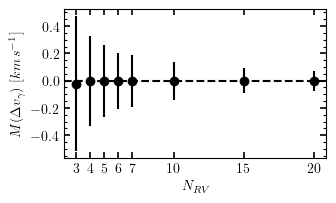

In [177]:
width = 3.46
height = width / 1.618
fig, axs = plt.subplots(figsize=(width, height))
df = pooled_vgamma.copy()
axs.errorbar(df.n_rv, df["central"], yerr=df["mad"], fmt=".", c="k")
axs.scatter(df.n_rv, df["central"], c="k", zorder=2)
axs.set_ylabel(r"$M(\Delta v_\gamma)~[km\,s^{-1}]$")
axs.set_xlabel(r"$N_{RV}$")
ylim = axs.get_ylim()
y_steps = [0.2, 0.05]
y_ticks = np.arange(-5, 5, y_steps[0])
y_ticks_minor = np.arange(-3, 5, y_steps[1])
vf.plots_utils.format_yticks(axs, y_ticks, y_ticks_minor)
axs.set_ylim(*ylim)
x_ticks = [3, 4, 5, 6, 7, 10, 15, 20]
vf.plots_utils.format_xticks(axs, x_ticks, x_ticks)
axs.axhline(0, ls="--", c="k")
fig.tight_layout()
fig.savefig(subsampling_dir / "delta_vgamma_vs_n_rv.pdf", format="pdf")

In [173]:
pooled_vgamma_norm = build_pooled_table_weighted(comparison_df, "delta_vgamma_norm")
pooled_p2p_norm = build_pooled_table_weighted(comparison_df, "delta_p2p_norm")

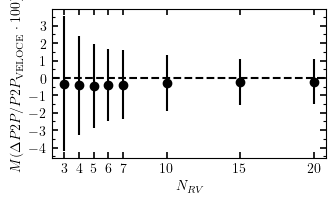

In [ ]:
width = 3.46
height = width / 1.618
fig, axs = plt.subplots(figsize=(width, height))
df = pooled_p2p_norm.copy()
axs.errorbar(df.n_rv, df["central"] * 100, yerr=df["mad"] * 100, fmt=".", c="k")
axs.scatter(df.n_rv, df["central"] * 100, c="k", zorder=2)
axs.set_ylabel(r"$M(\Delta P2P/P2P_{\rm VELOCE} \cdot 100)$")
axs.set_xlabel(r"$N_{RV}$")
ylim = axs.get_ylim()
y_steps = [1, 0.5]
y_ticks = np.arange(-10, 10, y_steps[0])
y_ticks_minor = np.arange(-10, 10, y_steps[1])
vf.plots_utils.format_yticks(axs, y_ticks, y_ticks_minor)
axs.set_ylim(*ylim)
x_ticks = [3, 4, 5, 6, 7, 10, 15, 20]
vf.plots_utils.format_xticks(axs, x_ticks, x_ticks)
axs.axhline(0, ls="--", c="k")
fig.tight_layout()
fig.savefig(subsampling_dir / "delta_p2p_vs_n_rv.pdf", format="pdf")

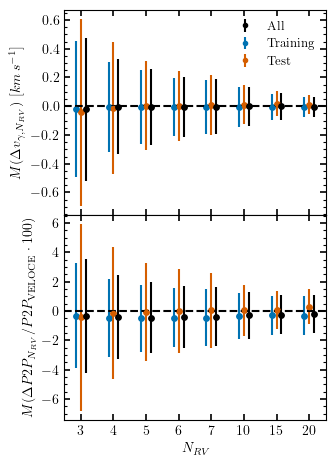

In [ ]:
def pooled_population_point_estimate(df, n_rv, value_col):
    """Central value + MAD only — no bootstrap, for when *_err isn't plotted."""
    sub = df[df["n_rv"] == n_rv]
    groups = {name: g[value_col].to_numpy() for name, g in sub.groupby("NAME")}
    targets = np.array(list(groups.keys()))

    vals, wts = [], []
    for t in targets:
        x = groups[t]
        vals.append(x)
        wts.append(np.full(x.size, 1.0 / x.size))
    v, w = np.concatenate(vals), np.concatenate(wts)

    return {
        "n_rv": n_rv,
        "n_targets": len(targets),
        "central": float(weighted_median(v, w)),
        "mad": float(weighted_mad(v, w)),
    }


def build_pooled_table_point(df, value_col, n_rv_list=None):
    if n_rv_list is None:
        n_rv_list = sorted(df["n_rv"].unique())
    rows = [pooled_population_point_estimate(df, nrv, value_col) for nrv in n_rv_list]
    return pd.DataFrame(rows)


def build_split_tables(df, value_col, n_rv_list=x_ticks):
    return {
        "all": build_pooled_table_point(df, value_col, n_rv_list=n_rv_list),
        "train": build_pooled_table_point(
            df[df["SET"] == "train"], value_col, n_rv_list=n_rv_list
        ),
        "test": build_pooled_table_point(
            df[df["SET"] == "test"], value_col, n_rv_list=n_rv_list
        ),
    }


x_ticks = [3, 4, 5, 6, 7, 10, 15, 20]
x_pos = np.arange(len(x_ticks))

pooled_vgamma_split = build_split_tables(comparison_df, "delta_vgamma")
pooled_p2p_norm_split = build_split_tables(comparison_df, "delta_p2p_norm")


offsets = {"train": -0.15, "test": 0.0, "all": 0.15}
colors = {
    "train": color_safe["blue"],
    "test": color_safe["dark_orange"],
    "all": color_safe["black"],
}
labels = {"train": "Training", "test": "Test", "all": "All"}

width = 3.46
height = width / 1.618 / 1.8 * 4
fig, axs = plt.subplots(
    2,
    1,
    figsize=(width, height),
    sharex=True,
    gridspec_kw={"hspace": 0},
)

panels = [
    (
        axs[0],
        pooled_vgamma_split,
        1.0,
        r"$M(\Delta v_{\gamma, N_{RV}})~[km\,s^{-1}]$",
        np.arange(-5, 5, 0.2),
        np.arange(-3, 5, 0.05),
    ),
    (
        axs[1],
        pooled_p2p_norm_split,
        100.0,
        r"$M(\Delta P2P_{N_{RV}}/P2P_{\rm VELOCE}\cdot 100)$",
        np.arange(-10, 10, 2),
        np.arange(-10, 10, 0.5),
    ),
]

for ax, split, scale, ylabel, y_ticks, y_ticks_minor in panels:
    for key in ("all", "train", "test"):
        z_order = 3 if key == "all" else 2
        df = split[key]
        pos = x_pos + offsets[key]
        ax.errorbar(
            pos,
            df["central"] * scale,
            yerr=df["mad"] * scale,
            fmt=".",
            c=colors[key],
            label=labels[key],
        )
        ax.scatter(pos, df["central"] * scale, c=colors[key], zorder=z_order, s=15)

    ax.set_xlabel(r"$N_{RV}$")
    ax.set_ylabel(ylabel)
    ylim = ax.get_ylim()
    vf.plots_utils.format_yticks(ax, y_ticks, y_ticks_minor)
    ax.set_ylim(*ylim)
    vf.plots_utils.format_xticks(ax, x_pos, x_pos)
    ax.set_xticklabels(x_ticks)
    ax.axhline(0, ls="--", c="k")

axs[0].legend(fontsize=label_size - 2, frameon=False)
fig.tight_layout()
fig.savefig(subsampling_dir / "delta_vgamma_p2p_vs_n_rv.pdf", format="pdf")

In [ ]:
def weighted_point_estimates(df, n_rv, value_col):
    """Per-target weighted median, MAD, and 16-84 half-width. No bootstrap."""
    sub = df[df["n_rv"] == n_rv]
    groups = {name: g[value_col].to_numpy() for name, g in sub.groupby("NAME")}
    targets = np.array(list(groups.keys()))

    vals, wts = [], []
    for t in targets:
        x = groups[t]
        vals.append(x)
        wts.append(np.full(x.size, 1.0 / x.size))
    v, w = np.concatenate(vals), np.concatenate(wts)

    return {
        "n_rv": n_rv,
        "n_targets": len(targets),
        "central": float(weighted_median(v, w)),
        "mad": float(weighted_mad(v, w)),
        "halfwidth": float(weighted_halfwidth(v, w)),
    }


def build_point_table(df, value_col, n_rv_list):
    rows = [weighted_point_estimates(df, nrv, value_col) for nrv in n_rv_list]
    return pd.DataFrame(rows)


x_ticks = [3, 4, 5, 6, 7, 10, 15, 20]
x_pos = np.arange(len(x_ticks))

vgamma_map = build_point_table(comparison_df, "delta_vgamma", x_ticks)
vgamma_naive = build_point_table(comparison_df, "delta_vgamma_naive", x_ticks)

improvement = pd.DataFrame(
    {
        "n_rv": x_ticks,
        "mad_map": vgamma_map["mad"],
        "mad_naive": vgamma_naive["mad"],
        "improvement_mad": vgamma_naive["mad"] / vgamma_map["mad"],
        "halfwidth_map": vgamma_map["halfwidth"],
        "halfwidth_naive": vgamma_naive["halfwidth"],
        "improvement_halfwidth": vgamma_naive["halfwidth"] / vgamma_map["halfwidth"],
    }
)
print(improvement.to_string(index=False))

 n_rv  mad_map  mad_naive  improvement_mad  halfwidth_map  halfwidth_naive  improvement_halfwidth
    3 0.495753   3.927049         7.921375       0.964572         6.224595               6.453218
    4 0.331554   3.349860        10.103520       0.630587         5.311126               8.422505
    5 0.262676   2.934800        11.172713       0.493257         4.642905               9.412749
    6 0.206857   2.600346        12.570759       0.380710         4.172489              10.959756
    7 0.192453   2.446077        12.709967       0.361353         3.892574              10.772215
   10 0.137361   1.996953        14.537996       0.247764         3.159190              12.750794
   15 0.091669   1.547185        16.877975       0.161870         2.504812              15.474199
   20 0.070454   1.365099        19.375647       0.123554         2.173647              17.592699


(<Figure size 346x213.844 with 1 Axes>,
 <Axes: xlabel='$N_{RV}$', ylabel='$\\sigma_{16\\text{-}84}(\\Delta v_\\gamma)~[\\mathrm{km\\,s^{-1}}]$'>)

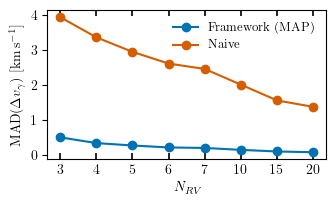

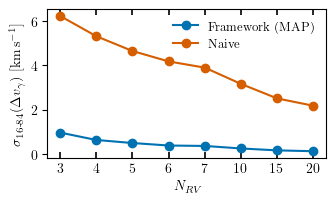

In [ ]:
def plot_spread_comparison(spread_col, ylabel, savename):
    width = 3.46
    height = width / 1.618
    fig, ax = plt.subplots(figsize=(width, height))

    ax.plot(
        x_pos,
        vgamma_map[spread_col],
        marker="o",
        c=color_safe["blue"],
        label="Framework (MAP)",
    )
    ax.plot(
        x_pos,
        vgamma_naive[spread_col],
        marker="o",
        c=color_safe["dark_orange"],
        label="Naive",
    )

    ax.set_xlabel(r"$N_{RV}$")
    ax.set_ylabel(ylabel)
    vf.plots_utils.format_xticks(ax, x_pos, x_pos)
    ax.set_xticklabels(x_ticks)
    ax.legend(fontsize=label_size - 2, frameon=False)
    fig.tight_layout()
    fig.savefig(subsampling_dir / savename, format="pdf")
    return fig, ax


plot_spread_comparison(
    "mad",
    r"$\mathrm{MAD}(\Delta v_\gamma)~[\mathrm{km\,s^{-1}}]$",
    "delta_vgamma_mad_comparison.pdf",
)

plot_spread_comparison(
    "halfwidth",
    r"$\sigma_{16\text{-}84}(\Delta v_\gamma)~[\mathrm{km\,s^{-1}}]$",
    "delta_vgamma_halfwidth_comparison.pdf",
)

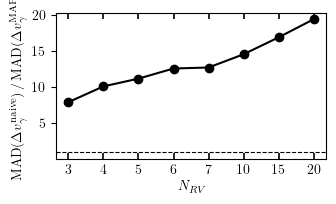

In [ ]:
width = 3.46
height = width / 1.618
fig, ax = plt.subplots(figsize=(width, height))

improvement_mad = vgamma_naive["mad"].to_numpy() / vgamma_map["mad"].to_numpy()

ax.plot(x_pos, improvement_mad, marker="o", c=color_safe["black"])
ax.axhline(1, ls="--", c="k", lw=0.8)

ax.set_xlabel(r"$N_{RV}$")
ax.set_ylabel(
    r"$\mathrm{MAD}(\Delta v_\gamma^{\rm naive}) \,/\, \mathrm{MAD}(\Delta v_\gamma^{\rm MAP})$"
)
vf.plots_utils.format_xticks(ax, x_pos, x_pos)
ax.set_xticklabels(x_ticks)
fig.tight_layout()
fig.savefig(subsampling_dir / "delta_vgamma_improvement_factor.pdf", format="pdf")

In [ ]:
x_ticks = [3, 4, 5, 6, 7, 10, 15, 20]
x_pos = np.arange(len(x_ticks))

p2p_map = build_point_table(comparison_df, "delta_p2p_norm", x_ticks)
p2p_naive = build_point_table(comparison_df, "delta_p2p_naive_norm", x_ticks)

improvement_p2p = pd.DataFrame(
    {
        "n_rv": x_ticks,
        "mad_map": p2p_map["mad"],
        "mad_naive": p2p_naive["mad"],
        "improvement_mad": p2p_naive["mad"] / p2p_map["mad"],
        "halfwidth_map": p2p_map["halfwidth"],
        "halfwidth_naive": p2p_naive["halfwidth"],
        "improvement_halfwidth": p2p_naive["halfwidth"] / p2p_map["halfwidth"],
    }
)
print(improvement_p2p.to_string(index=False))

 n_rv  mad_map  mad_naive  improvement_mad  halfwidth_map  halfwidth_naive  improvement_halfwidth
    3 0.038850   0.214560         5.522726       0.077086         0.298539               3.872779
    4 0.028610   0.167562         5.856675       0.051666         0.243497               4.712933
    5 0.024116   0.124448         5.160334       0.042500         0.195754               4.605959
    6 0.020931   0.097501         4.658142       0.035508         0.158374               4.460272
    7 0.020012   0.077115         3.853503       0.033937         0.132152               3.894047
   10 0.015957   0.043604         2.732604       0.026510         0.081696               3.081724
   15 0.013363   0.023571         1.763887       0.022014         0.040311               1.831161
   20 0.012823   0.015024         1.171643       0.020653         0.027732               1.342746


(<Figure size 346x213.844 with 1 Axes>,
 <Axes: xlabel='$N_{RV}$', ylabel='$\\sigma_{16\\text{-}84}(\\Delta P2P)~[\\mathrm{km\\,s^{-1}}]$'>)

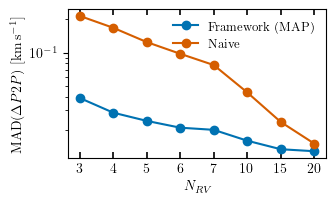

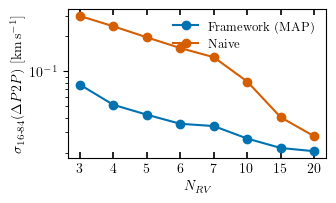

In [ ]:
def plot_spread_comparison_p2p(spread_col, ylabel, savename):
    width = 3.46
    height = width / 1.618
    fig, ax = plt.subplots(figsize=(width, height))

    ax.plot(
        x_pos,
        p2p_map[spread_col],
        marker="o",
        c=color_safe["blue"],
        label="Framework (MAP)",
    )
    ax.plot(
        x_pos,
        p2p_naive[spread_col],
        marker="o",
        c=color_safe["dark_orange"],
        label="Naive",
    )

    ax.set_xlabel(r"$N_{RV}$")
    ax.set_ylabel(ylabel)
    vf.plots_utils.format_xticks(ax, x_pos, x_pos)
    ax.set_xticklabels(x_ticks)
    ax.legend(fontsize=label_size - 2, frameon=False)
    ax.set_yscale("log")
    fig.tight_layout()
    fig.savefig(subsampling_dir / savename, format="pdf")
    return fig, ax


plot_spread_comparison_p2p(
    "mad",
    r"$\mathrm{MAD}(\Delta P2P)~[\mathrm{km\,s^{-1}}]$",
    "delta_p2p_mad_comparison.pdf",
)

plot_spread_comparison_p2p(
    "halfwidth",
    r"$\sigma_{16\text{-}84}(\Delta P2P)~[\mathrm{km\,s^{-1}}]$",
    "delta_p2p_halfwidth_comparison.pdf",
)

In [ ]:
# Total real epochs available per star (same selection used in the subsampling loop)
epoch_counts = (
    veloce_data[veloce_data["MASK"]].groupby("NAME").size().rename("n_epochs")
)

for n_rv in [3, 4, 5, 6, 7, 10, 15, 20]:
    frac_guaranteed_overlap = (epoch_counts < 2 * n_rv).mean()
    median_floor = np.maximum(0, 2 * n_rv - epoch_counts).median()
    print(
        f"n_rv={n_rv:2d}: {frac_guaranteed_overlap:.0%} of targets have "
        f"M < {2 * n_rv} (guaranteed overlap), median overlap floor = {median_floor:.0f} pts"
    )

n_rv= 3: 0% of targets have M < 6 (guaranteed overlap), median overlap floor = 0 pts
n_rv= 4: 0% of targets have M < 8 (guaranteed overlap), median overlap floor = 0 pts
n_rv= 5: 1% of targets have M < 10 (guaranteed overlap), median overlap floor = 0 pts
n_rv= 6: 1% of targets have M < 12 (guaranteed overlap), median overlap floor = 0 pts
n_rv= 7: 2% of targets have M < 14 (guaranteed overlap), median overlap floor = 0 pts
n_rv=10: 9% of targets have M < 20 (guaranteed overlap), median overlap floor = 0 pts
n_rv=15: 21% of targets have M < 30 (guaranteed overlap), median overlap floor = 0 pts
n_rv=20: 34% of targets have M < 40 (guaranteed overlap), median overlap floor = 0 pts


In [ ]:
n_rv  n_targets   central  central_err      mad  mad_err  halfwidth  halfwidth_err
    3        218 -0.016458     0.013202 0.491437 0.025638   0.946145       0.050779
    4        218 -0.008402     0.007145 0.330754 0.016592   0.623074       0.030435
    5        218 -0.012598     0.006765 0.263355 0.013505   0.483673       0.023339
    6        218 -0.001497     0.005450 0.218200 0.012544   0.398815       0.019863
    7        217 -0.004393     0.005086 0.196423 0.010688   0.365288       0.018765
   10        215 -0.001296     0.004178 0.147329 0.008531   0.266809       0.015371
   15        206 -0.002273     0.003518 0.097178 0.005224   0.169864       0.009212
   20        191 -0.003928     0.002778 0.071291 0.004190   0.125833       0.006436
 n_rv  n_targets   central  central_err      mad  mad_err  halfwidth  halfwidth_err
    3        218 -0.073105     0.070787 1.192139 0.079806   2.372630       0.202343
    4        218 -0.109101     0.052270 0.914942 0.051986   1.656487       0.102388
    5        218 -0.107376     0.040028 0.746143 0.043619   1.418401       0.081982
    6        218 -0.114269     0.033900 0.648564 0.037889   1.212937       0.072081
    7        217 -0.103812     0.032702 0.619037 0.037606   1.165270       0.070439
   10        215 -0.079804     0.025394 0.487096 0.030743   0.906456       0.055679
   15        206 -0.052448     0.024066 0.397324 0.029648   0.752937       0.049274
   20        191 -0.051755     0.027562 0.378530 0.030952   0.703217       0.049607

In [103]:
print(pooled_vgamma_norm.to_string(index=False))
print(pooled_p2p_norm.to_string(index=False))

 n_rv  n_targets   central  central_err      mad  mad_err  halfwidth  halfwidth_err
    3        216 -0.000799     0.000458 0.016485 0.000740   0.030508       0.001366
    4        216 -0.000139     0.000306 0.011140 0.000446   0.020079       0.000815
    5        216 -0.000157     0.000252 0.008906 0.000305   0.015624       0.000611
    6        216 -0.000150     0.000187 0.006972 0.000237   0.011919       0.000444
    7        215 -0.000135     0.000176 0.006506 0.000236   0.011220       0.000417
   10        213 -0.000053     0.000154 0.004641 0.000173   0.007641       0.000282
   15        205 -0.000041     0.000115 0.003123 0.000117   0.005001       0.000184
   20        191 -0.000105     0.000099 0.002363 0.000093   0.003825       0.000143
 n_rv  n_targets   central  central_err      mad  mad_err  halfwidth  halfwidth_err
    3        216 -0.003219     0.002431 0.038850 0.002203   0.077086       0.005493
    4        216 -0.004284     0.001634 0.028610 0.001276   0.051666       0

In [154]:
pooled_rmse = build_pooled_table_weighted(comparison_df, "rmse")
print(pooled_rmse.to_string(index=False))

 n_rv  n_targets  central  central_err      mad  mad_err  halfwidth  halfwidth_err      q90  q90_err
    3        216 0.778360     0.047290 0.495874 0.039404   1.279243       0.081276 0.119287 0.004885
    4        216 0.675270     0.035814 0.401508 0.027338   0.915041       0.058906 0.114330 0.004949
    5        216 0.635896     0.041404 0.376040 0.028918   0.815059       0.058812 0.110922 0.006297
    6        216 0.591506     0.036906 0.339402 0.024770   0.646950       0.046095 0.101768 0.006863
    7        215 0.613819     0.039589 0.364031 0.027151   0.695540       0.048870 0.094601 0.009069
   10        213 0.568804     0.040904 0.324694 0.024057   0.531344       0.026906 0.081234 0.008776
   15        205 0.530227     0.038203 0.291840 0.018372   0.429136       0.025708 0.064502 0.011034
   20        191 0.510073     0.036384 0.269435 0.016323   0.370776       0.020133 0.071681 0.006253


In [231]:
pooled_rmse_norm = build_pooled_table_weighted(comparison_df, "rmse_norm")
print(pooled_rmse_norm.to_string(index=False))

 n_rv  n_targets  central  central_err      mad  mad_err  halfwidth  halfwidth_err      q90  q90_err
    3        216 0.025098     0.001352 0.013750 0.001161   0.032903       0.002287 0.104393 0.006487
    4        216 0.021254     0.000865 0.010127 0.000691   0.023849       0.001246 0.077693 0.004354
    5        216 0.020041     0.000848 0.009075 0.000561   0.020417       0.001226 0.066847 0.003156
    6        216 0.018685     0.000782 0.008057 0.000477   0.016071       0.001078 0.055877 0.002503
    7        215 0.018848     0.000777 0.008314 0.000502   0.016860       0.001101 0.058588 0.002643
   10        213 0.017018     0.000783 0.006932 0.000427   0.012326       0.000773 0.044671 0.002819
   15        205 0.015141     0.000663 0.005905 0.000360   0.009578       0.000526 0.034989 0.002501
   20        191 0.014037     0.000636 0.005222 0.000343   0.008427       0.000510 0.029975 0.002054


In [ ]:
def rmse_q90(df, value_col="rmse"):
    res = []
    n_rv_list = sorted(df["n_rv"].unique())
    for n_rv in n_rv_list:
        sub = df[df["n_rv"] == n_rv]
        groups = {name: g[value_col].to_numpy() for name, g in sub.groupby("NAME")}
        targets = np.array(list(groups.keys()))
        n_targets = len(targets)

        def stack(target_subset):
            # concatenate values and assign each a weight of 1/n_target so every
            # target sums to 1 (equal weighting). With replacement in the bootstrap,
            # a target drawn k times naturally gets total weight k -> correct.
            vals, wts = [], []
            for t in target_subset:
                x = groups[t]
                vals.append(x)
                wts.append(np.full(x.size, 1.0 / x.size))
            return np.concatenate(vals), np.concatenate(wts)

        # ---- point estimates over ALL targets ----
        v, w = stack(targets)
        central_val = float(weighted_percentile(v, w, 90))

        res.append(
            {
                "n_rv": n_rv,
                "n_targets": n_targets,
                "q90": central_val,
            }
        )
    return pd.DataFrame(res)

In [157]:
ss = rmse_q90(comparison_df)
print(ss.to_string(index=False))

 n_rv  n_targets      q90
    3        216 3.726674
    4        216 2.919344
    5        216 2.664798
    6        216 2.129069
    7        215 2.319157
   10        213 1.668526
   15        205 1.298639
   20        191 1.120880


In [234]:
ss = rmse_q90(comparison_df, value_col="rmse_norm")
print(ss.to_string(index=False))

NameError: name 'rmse_q90' is not defined

In [233]:
pooled_rmse_norm

,n_rv,n_targets,central,central_err,mad,mad_err,halfwidth,halfwidth_err,q90,q90_err
0,3,216,0.025098,0.001352,0.013750,0.001161,0.032903,0.002287,0.104393,0.006487
1,4,216,0.021254,0.000865,0.010127,0.000691,0.023849,0.001246,0.077693,0.004354
2,5,216,0.020041,0.000848,0.009075,0.000561,0.020417,0.001226,0.066847,0.003156
3,6,216,0.018685,0.000782,0.008057,0.000477,0.016071,0.001078,0.055877,0.002503
4,7,215,0.018848,0.000777,0.008314,0.000502,0.016860,0.001101,0.058588,0.002643
5,10,213,0.017018,0.000783,0.006932,0.000427,0.012326,0.000773,0.044671,0.002819
6,15,205,0.015141,0.000663,0.005905,0.000360,0.009578,0.000526,0.034989,0.002501
7,20,191,0.014037,0.000636,0.005222,0.000343,0.008427,0.000510,0.029975,0.002054


In [232]:
ss


NameError: name 'ss' is not defined

In [143]:
comparison_df.columns

Index(['NAME', 'SET', 'log_P', 'n_rv', 'i_resample', 'has_phase_prior',
       'veloce_p2p', 'delta_vgamma', 'delta_vgamma_fromnaive', 'delta_p2p',
       'delta_p2p_fromnaive', 'rmse', 'delta_vgamma_norm', 'delta_p2p_norm',
       'rmse_norm', 'delta_phi', 'real_delta_phi', 'diff_delta_phi',
       'arc_gaps', 'max_gap', 'naive_dvgamma', 'naive_dp2p',
       'delta_vgamma_naive', 'delta_p2p_naive', 'delta_vgamma_naive_norm',
       'delta_p2p_naive_norm', 'n_ascending', 'n_descending', 'frac_ascending',
       'single_branch', 'rv_coverage', 'centroid_offset'],
      dtype='str')

In [140]:
# Median and MAD from bootstrapped means
rng = np.random.default_rng(42)
n_boot = 10000
boot_median_means_dvgamma = np.empty(n_boot)
boot_mad_means_dvgamma = np.empty(n_boot)
sub = comparison_df[comparison_df["n_rv"] == 3]

# ---- Step 1: collapse each target's subsample fits to per-target stats ----
# per-target median = that star's typical recovery
# per-target MAD    = that star's own subsample scatter (phase-sampling luck)
g = sub.groupby("NAME")["delta_vgamma"]
mean_dvgamma_per_target = g.mean()
std_dvgamma_per_target = g.std()
for i in range(n_boot):
    # Vgamma
    samples = rng.normal(
        loc=mean_dvgamma_per_target,
        scale=std_dvgamma_per_target,
    )
    boot_median_means_dvgamma[i] = np.median(samples)
    boot_mad_means_dvgamma[i] = np.median(np.abs(samples - np.median(samples)))

In [141]:
np.median(boot_mad_means_dvgamma)

np.float64(0.8317446577352406)

(np.float64(3.75357947271823), np.float64(3.5132646640750713))

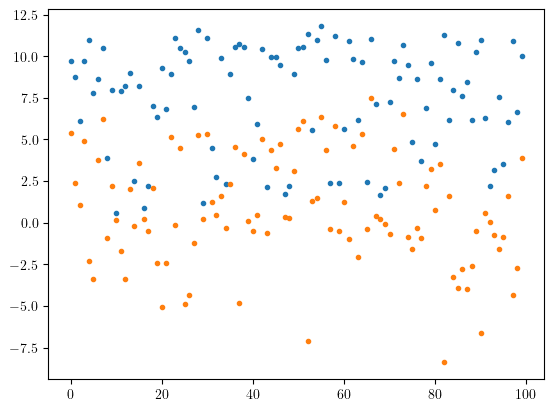

In [ ]:
vval = comparison_df[(comparison_df.n_rv == 3) & (comparison_df.NAME == "alf UMi")]
fig, axs = plt.subplots()
axs.plot(np.arange(len(vval["delta_p2p"])), vval["delta_p2p"], ".")
axs.plot(np.arange(len(vval["delta_vgamma"])), vval["delta_vgamma"], ".")
(
    robust_halfwidth(vval["delta_p2p"].to_numpy()),
    robust_halfwidth(vval["delta_vgamma"].to_numpy()),
)

In [892]:
comparison_df[~comparison_df.has_phase_prior].groupby("NAME").first()

,SET,log_P,n_rv,i_resample,has_phase_prior,delta_vgamma,delta_p2p,rmse,delta_vgamma_norm,delta_p2p_norm,...,real_delta_phi,diff_delta_phi,arc_gaps,max_gap,naive_dvgamma,naive_dp2p,delta_vgamma_naive,delta_p2p_naive,delta_vgamma_naive_norm,delta_p2p_naive_norm
NAME,,,,,,,,,,,,,,,,,,,,,
ASAS J190929+1232.8,train,0.603248,3,0,False,-0.180903,-0.250704,0.165822,-0.013352,-0.018504,...,0.604744,-0.002869,"[0.24425229406404014, 0.479782912247515, 0.275...",0.479783,1.024588,-2.453339,1.024588,-2.453339,0.075622,-0.181074
BB Gem,train,0.363275,3,0,False,-0.634298,-2.120269,0.989387,-0.015426,-0.051565,...,0.163934,0.003258,"[0.06549255115805863, 0.13088996317583224, 0.8...",0.803617,6.850761,-30.250768,6.850761,-30.250768,0.166610,-0.735697
BB Sgr,train,0.821980,3,0,False,-0.689994,6.151222,2.236998,-0.021361,0.190429,...,0.537300,0.016325,"[0.6254817566169493, 0.029331838440384672, 0.3...",0.625482,3.955656,-13.010352,3.955656,-13.010352,0.122459,-0.402772
FM Aql,train,0.786368,3,0,False,0.712640,-0.267982,1.168216,0.018509,-0.006960,...,0.651952,-0.000024,"[0.30253267886610047, 0.010505453480533333, 0....",0.686962,0.670178,-24.015934,0.670178,-24.015934,0.017406,-0.623742
RT Aur,test,0.571526,3,0,False,0.224389,-1.950965,0.970748,0.006641,-0.057740,...,0.076834,-0.003854,"[0.29699236594012746, 0.3707742582762421, 0.33...",0.370774,1.197487,-15.268766,1.197487,-15.268766,0.035440,-0.451886
S Vul,train,1.838346,3,0,False,0.022590,0.814989,0.261808,0.000795,0.028673,...,0.026626,0.003823,"[0.5163004610027099, 0.13600011623598374, 0.34...",0.516300,1.385695,-12.702461,1.385695,-12.702461,0.048752,-0.446899
SZ Aql,train,1.234033,3,0,False,2.318850,-8.846010,3.390099,0.039337,-0.150062,...,0.557297,-0.010862,"[0.18610780000210525, 0.6239608359385045, 0.18...",0.623961,10.656375,-26.719100,10.656375,-26.719100,0.180773,-0.453258
T Mon,train,1.431934,3,0,False,-14.309271,-1.189177,1.496228,-0.307888,-0.025587,...,0.301721,0.186232,"[0.09276677391250487, 0.8622477000621664, 0.04...",0.862248,-11.085451,-36.312492,-11.085451,-36.312492,-0.238522,-0.781325
TT Aql,test,1.138448,3,0,False,-0.011592,2.839282,1.647410,-0.000218,0.053323,...,0.881093,-0.021832,"[0.03698787156429262, 0.5774275091504819, 0.38...",0.577428,-9.058434,-3.300668,-9.058434,-3.300668,-0.170122,-0.061988


#### Test MCMC run

In [ ]:
subsampling_mcmc_dir = subsampling_dir / "mcmc"
subsampling_mcmc_dir.mkdir(exist_ok=True)

mcmc_kwargs = {
    "sigma_model": 0.0,
    "scale_factor_init": 1e-3,
    "nwalkers": 32,
    "max_steps": 20_000,
    "check_tau_every": 200,
    "convergence_ratio": 50.0,
    "convergence_tol": 0.02,
}


def run_mcmc(  # noqa: PLR0913
    compiled_model: vf.model.BaseModel | vf.model.CompiledModel,
    x: list | np.ndarray,
    y: list | np.ndarray,
    yerr: list | np.ndarray | None = None,
    theta_free_init: list | np.ndarray | None = None,
    logprior: Callable[[np.ndarray], float] | None = None,
    sigma_model: float = 0.0,
    scale_factor_init: float | list | np.ndarray = 1e-3,
    nwalkers: int = 32,
    max_steps: int = 20_000,
    check_tau_every: int = 200,
    convergence_ratio: float = 50.0,  # chain must be > ratio * tau
    convergence_tol: float = 0.02,  # tau must change by < 2%
) -> dict:
    """Run MCMC for a model."""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    yerr = np.asarray(yerr, dtype=float) if yerr is not None else None
    if yerr is not None:
        yerr = effective_yerr(
            yerr,
            sigma_model,
        )
    if isinstance(compiled_model, vf.model.BaseModel):
        compiled_model = vf.model.compile_model(compiled_model)

    if logprior is None:
        msg = "No log_prior was given."
        logger.error(msg)
        raise ValueError(msg)

    theta0 = np.asarray(theta_free_init, dtype=float).ravel()
    ndim = len(theta0)

    model_evaluator = vf.fit.ModelObjectiveFunction(
        model=compiled_model,
        x=x,
        y=y,
        yerr=yerr,
        logprior=logprior,
    )

    # Initialize walkers in a small ball around the MAP solution
    p0 = theta0 + scale_factor_init * rng.standard_normal((nwalkers, ndim))
    for k in range(nwalkers):
        attempts = 0
        while not np.isfinite(model_evaluator.logposterior(p0[k])) and attempts < 100:
            p0[k] = theta0 + scale_factor_init * rng.standard_normal(ndim)
            attempts += 1

    with Pool() as pool:
        sampler = emcee.EnsembleSampler(
            nwalkers, ndim, model_evaluator.logposterior, pool=pool
        )

        # Get walkers off bad initial guesses before you start measuring autocorrelation
        sampler.run_mcmc(p0, 300, progress=False)
        p0_prod = sampler.get_last_sample()
        sampler.reset()

        # Production run with autocorrelation convergence check
        old_tau = np.full(ndim, np.inf)
        for _ in range(0, max_steps, check_tau_every):
            sampler.run_mcmc(
                p0_prod if sampler.iteration == 0 else None,
                check_tau_every,
                progress=False,
            )
            if sampler.iteration < 4 * check_tau_every:
                continue  # need enough samples before estimating tau
            try:
                tau = sampler.get_autocorr_time(tol=0)
                converged = np.all(
                    sampler.iteration > convergence_ratio * tau
                ) and np.all(
                    np.abs(old_tau - tau) / tau < convergence_tol,
                )
                old_tau = tau
                if converged:
                    break
            except emcee.autocorr.AutocorrError:
                pass

    tau = sampler.get_autocorr_time(tol=0)
    thin = max(1, int(np.min(tau) / 2))
    burnin = int(2 * np.max(tau))

    flat_samples = sampler.get_chain(discard=burnin, thin=thin, flat=True)
    flat_log_prob = sampler.get_log_prob(discard=burnin, thin=thin, flat=True)

    return {
        "flat_samples": flat_samples,  # shape (n_eff, ndim)
        "flat_log_prob": flat_log_prob,
        "tau": tau,
        "n_steps": sampler.iteration,
        "n_eff": len(flat_samples),
        "n_dim": ndim,
        "p0": p0,
    }

In [ ]:
def _monitored_stats(vgammas: np.ndarray, p2ps: np.ndarray) -> dict[str, float]:
    """Median and normalized MAD for Δvγ and ΔP2P — the only stopping-rule stats."""
    return {
        "vg_med": float(np.median(vgammas)),
        "vg_mad": float(sp.stats.median_abs_deviation(vgammas)),
        "p2p_med": float(np.median(p2ps)),
        "p2p_mad": float(sp.stats.median_abs_deviation(p2ps)),
    }


def _all_pass(curr: dict, prev: dict, tol_vg: float, tol_p2p: float) -> bool:
    """All 4 monitored statistics must change by less than their tolerance."""
    return (
        abs(curr["vg_med"] - prev["vg_med"]) < tol_vg
        and abs(curr["vg_mad"] - prev["vg_mad"]) < tol_vg
        and abs(curr["p2p_med"] - prev["p2p_med"]) < tol_p2p
        and abs(curr["p2p_mad"] - prev["p2p_mad"]) < tol_p2p
    )


def run_mcmc_target_adaptive(  # noqa: PLR0913, PLR0915
    name: str,
    nrv: int,
    *,
    max_resamples: int = 100,
    min_resamples: int = 10,
    window: int = 3,
    n_consecutive: int = 2,  # consecutive passing batches required
    tol_vg: float = 0.05,  # 50 m/s expressed in km/s
    tol_p2p_frac: float = 0.005,  # 0.5% of veloce_p2p
    mcmc_kwargs: dict | None = None,
) -> dict:
    """Run MCMC for target and stop when convergence is reached."""
    n_rv_dir = subsampling_results_dir / f"n_rv{nrv:.0f}"
    filename = next(iter(n_rv_dir.glob(f"*{name.replace(' ', '_')}*.pkl")))
    with Path.open(filename, "rb") as f:
        target_data = pkl.load(f)  # noqa: S301

    subsampling_mcmc_nrv_dir = subsampling_mcmc_dir / f"n_rv{nrv:.0f}"
    subsampling_mcmc_nrv_dir.mkdir(exist_ok=True)
    subsampling_mcmc_nrv_target_dir = (
        subsampling_mcmc_nrv_dir / f"{name.replace(' ', '_')}"
    )
    subsampling_mcmc_nrv_target_dir.mkdir(exist_ok=True)

    log_p = target_data["log_P"]
    header_row = veloce_headers[veloce_headers["NAME"] == name].iloc[0]
    fit_row = veloce_fit[veloce_fit["NAME"] == name].iloc[0]
    veloce_vgamma = float(fit_row["VGAMMA"])
    veloce_p2p = float(header_row["PEAK2PEAK"])
    # veloce_pulsation = dataset[dataset["NAME"] == name].iloc[0]["SAMPLE"]
    # Fix real delta phi (between 0 and 1)
    real_delta_phi = (target_data["real_delta_phi"] + 1) % 1

    # Create Priors
    source_id = int(header_row.GAIA_DR3_SOURCE_ID)
    has_gaia_epoch = True
    if source_id not in df_gaiadr3_selection["source_id"].to_numpy():
        has_gaia_epoch = False

    priors = []
    kde_comps_for_target = kde_comps.conditional(log_P=log_p)
    priors.append(
        vf.prior.ParameterPrior(kde_comps_for_target, mapping_variables_model),
    )
    # One conditional prior on the phase
    has_phase_prior = True
    if (
        log_p < kde_phot_phase.domain["log_P"][1]
        and has_gaia_epoch
        and (name not in outliers_gaia_veloce_delta.NAME.to_numpy())
    ):
        cond_phase = kde_phot_phase.conditional(log_P=log_p)
        fast_phase = vf.prior.SplineDensity(cond_phase)
    else:
        has_phase_prior = False
        fast_phase = vf.prior.UniformDensity("DELTA_PHASE", 0.0, 1.0)

    idx = mapping_variables_model["delta_phi"]
    priors.append(vf.prior.ParameterPrior(fast_phase, {"DELTA_PHASE": idx}))
    log_prior_target = vf.prior.CombinedLogPrior(priors)

    mcmc_kwargs = mcmc_kwargs or {}
    tol_p2p = tol_p2p_frac * veloce_p2p

    vgammas: list[np.ndarray] = []
    p2ps: list[np.ndarray] = []
    phis: list[np.ndarray] = []
    n_consec_pass = 0
    stop_reason = "max_resamples"

    print(name)
    for i_comb in range(min(max_resamples, len(target_data["combinations"]))):
        if target_data["result_map"][i_comb] is None:
            continue

        file_name = f"{name.replace(' ', '_')}" + f"_comb_{i_comb:03.0f}.pkl"
        pickle_file = subsampling_mcmc_nrv_target_dir / file_name
        if pickle_file.exists():
            with Path.open(pickle_file, "rb") as f:
                mcmc_res = pkl.load(f)  # noqa: S301
        else:
            comb = target_data["combinations"][i_comb]
            mcmc_res = run_mcmc(
                phased_pca_model,
                target_data["phase"][comb],
                target_data["rv"][comb],
                target_data["rv_err"][comb],
                target_data["result_map"][i_comb].theta_free,
                log_prior_target,
                **mcmc_kwargs,
            )
            with Path.open(pickle_file, "wb") as f:
                pkl.dump(mcmc_res, f)

        print(
            name,
            i_comb,
            mcmc_res["n_steps"],
            mcmc_res["n_eff"],
            mcmc_kwargs["convergence_ratio"] * np.max(mcmc_res["tau"]),
            flush=True,
        )
        samples = mcmc_res["flat_samples"]
        vgammas.append(np.array(samples[:, 0]))
        curves = np.array([phased_pca_model.evaluate(s, x=phase_grid) for s in samples])
        p2ps.append(np.ptp(curves, axis=1))
        phis.append(np.array(samples[:, -1]))

        n_done = len(vgammas)
        # Only check once we have enough combinations to compare
        if n_done < min_resamples or n_done <= window:
            continue

        pooled_vg = np.concatenate(vgammas)
        pooled_p2p = np.concatenate(p2ps)
        curr = _monitored_stats(pooled_vg, pooled_p2p)

        pooled_vg_prev = np.concatenate(vgammas[:-window])
        pooled_p2p_prev = np.concatenate(p2ps[:-window])
        prev = _monitored_stats(pooled_vg_prev, pooled_p2p_prev)

        if _all_pass(curr, prev, tol_vg, tol_p2p):
            n_consec_pass += 1
            if n_consec_pass >= n_consecutive:
                stop_reason = f"converged_n{n_done}"
                break
        else:
            n_consec_pass = 0

    print(name, stop_reason)
    vg_arr = np.concat(vgammas)
    p2p_arr = np.concat(p2ps)
    phi_arr = np.concat(phis)
    delta_vgamma = vg_arr - veloce_vgamma
    delta_p2p = p2p_arr - veloce_p2p
    delta_phi = (phi_arr - real_delta_phi + 0.5) % 1 - 0.5

    return {
        "target": name,
        "n_rv": nrv,
        "n_resamples_used": len(vgammas),
        "stop_reason": stop_reason,
        "delta_vgamma": delta_vgamma,
        "delta_p2p": delta_p2p,
        "delta_phi": delta_phi,
    }


In [114]:
test_targets_ = ["AO CMa"]  # pick easy / medium / hard
test_n_rv_ = 3
results_mcmc = Parallel(n_jobs=-1, backend="threading")(
    delayed(run_mcmc_target_adaptive)(
        name,
        test_n_rv_,
        mcmc_kwargs=mcmc_kwargs,
    )
    for name in test_targets_
)


AO CMa
AO CMa 0 14600 5376 14599.485342371676
AO CMa 1 18600 6496 18393.18986442852
AO CMa 2 20000 4192 37067.31068527358
AO CMa 3 19000 4768 18954.79449421111
AO CMa 4 20000 3776 30649.66733043703
AO CMa 5 10800 5440 10709.818599926955
AO CMa 6 20000 4928 29462.723100439558
AO CMa 7 20000 4544 29507.644370270606
AO CMa 8 20000 4288 41087.43266291476
AO CMa 9 20000 2624 60732.70905596643
AO CMa 10 20000 8032 22124.616388538856
AO CMa 11 8400 3968 8192.711630410528
AO CMa 12 20000 6496 21516.938907653734
AO CMa 13 20000 4768 25631.409591877593
AO CMa 14 10600 4096 10467.606631133376
AO CMa 15 6000 3904 5948.470187657716
AO CMa 16 20000 5120 35875.55827954668
AO CMa 17 20000 4384 28888.290165234404
AO CMa 18 20000 6368 20556.482756919842
AO CMa 19 20000 2560 52758.857002870354
AO CMa 20 20000 3264 29762.46516120002
AO CMa 21 19200 6848 19071.225423957087
AO CMa 22 9200 3968 9151.670651056016
AO CMa converged_n23


In [105]:
results_mcmc

[{'n_resamples_used': 24,
  'stop_reason': 'converged_n24',
  'delta_vgamma': array([-1.09780952, -0.23305376, -0.09942654, ...,  1.71609312,
          0.27377234,  2.95421318], shape=(111104,)),
  'delta_p2p': array([-0.55347714,  1.11596598,  4.18109782, ..., -4.05059633,
          7.66748245,  0.35455021], shape=(111104,)),
  'delta_phi': array([-0.00375922, -0.00033506, -0.00379342, ..., -0.03964604,
          0.00044266, -0.05508538], shape=(111104,))}]

In [ ]:
(
    np.median(results_mcmc[1]["delta_vgamma"]),
    sp.stats.median_abs_deviation(results_mcmc[1]["delta_vgamma"]),
)

(np.float64(0.2649972123723785), np.float64(0.9305110016432856))

Text(0, 0.5, 'density')

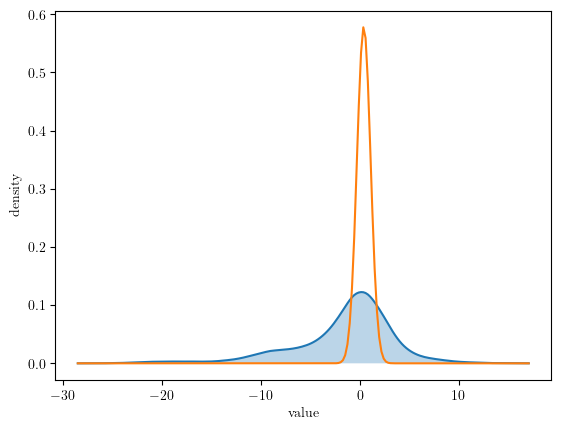

In [ ]:
fig, axs = plt.subplots()
kde_ss = gaussian_kde(results_mcmc[0]["delta_p2p"])
x = np.linspace(
    results_mcmc[0]["delta_p2p"].min(), results_mcmc[0]["delta_p2p"].max(), 200
)
axs.plot(x, kde_ss(x))
axs.plot(
    x,
    sp.stats.norm.pdf(
        x,
        summ_nrv[summ_nrv.NAME == "AO CMa"].vgamma_mean,
        summ_nrv[summ_nrv.NAME == "AO CMa"].vgamma_std,
    ),
)
axs.fill_between(x, kde_ss(x), alpha=0.3)
axs.set_xlabel("value")
axs.set_ylabel("density")

In [ ]:
(
    np.mean(results_mcmc[0]["delta_phi"]),
    sp.stats.median_abs_deviation(results_mcmc[0]["delta_vgamma"]),
    np.std(results_mcmc[0]["delta_vgamma"]),
)

(np.float64(-0.012477064231301831),
 np.float64(0.9705834086594294),
 np.float64(1.6738487297811222))

In [108]:
summ_nrv[summ_nrv.NAME == "AO CMa"]

,NAME,log_P,SET,has_phase_prior,vgamma_mean,vgamma_std,p2p_mean,p2p_std,rmse_mean,rmse_std,delta_phi,delta_phi_std,SET_color
7,AO CMa,0.764599,train,True,0.382004,0.688988,0.102855,0.549025,0.506925,0.120683,-0.009845,0.011973,#0072B2


In [ ]:
def mcmc_one_target(name, nrv, ith_iteration):
    rng = np.random.default_rng(ith_iteration)
    n_rv_dir = subsampling_results_dir / f"n_rv{nrv:.0f}"
    filename = next(iter(n_rv_dir.glob(f"*{name.replace(' ', '_')}*.pkl")))
    with Path.open(filename, "rb") as f:
        data = pkl.load(f)  # noqa: S301

    phase = data["phase"]
    rv = data["rv"]
    rv_err = data["rv_err"]
    log_p = data["log_P"]

    header_row = veloce_headers[veloce_headers["NAME"] == name].iloc[0]
    fit_row = veloce_fit[veloce_fit["NAME"] == name].iloc[0]
    veloce_vgamma = float(fit_row["VGAMMA"])
    veloce_p2p = float(header_row["PEAK2PEAK"])
    veloce_pulsation = dataset[dataset["NAME"] == name].iloc[0]["SAMPLE"]

    # Create Priors
    source_id = int(header_row.GAIA_DR3_SOURCE_ID)
    has_gaia_epoch = True
    if source_id not in df_gaiadr3_selection["source_id"].to_numpy():
        has_gaia_epoch = False

    priors = []
    kde_comps_for_target = kde_comps.conditional(log_P=log_p)
    priors.append(
        vf.prior.ParameterPrior(kde_comps_for_target, mapping_variables_model)
    )
    # One conditional prior on the phase
    has_phase_prior = True
    if (
        log_p < kde_phot_phase.domain["log_P"][1]
        and has_gaia_epoch
        and (name not in outliers_gaia_veloce_delta.NAME.to_numpy())
    ):
        cond_phase = kde_phot_phase.conditional(log_P=log_p)
        fast_phase = vf.prior.SplineDensity(cond_phase)
    else:
        has_phase_prior = False
        fast_phase = vf.prior.UniformDensity("DELTA_PHASE", 0.0, 1.0)

    idx = mapping_variables_model["delta_phi"]
    priors.append(vf.prior.ParameterPrior(fast_phase, {"DELTA_PHASE": idx}))
    log_prior_target = vf.prior.CombinedLogPrior(priors)

    for i, i_comb in enumerate(data["combinations"]):
        t0 = time.perf_counter()
        combination = data["combinations"][i_comb]
        map_result = data["result_map"][i_comb]

        elapsed = time.perf_counter() - t0

In [197]:
f"{10:03.0f}"

'010'

In [ ]:
import emcee


def run_mcmc_one(
    combination: list[int],
    phase: np.ndarray,
    rv: np.ndarray,
    rv_err: np.ndarray,
    model: vf.model.BaseModel,
    log_prior_target: vf.prior.CombinedLogPrior,
    map_init: vf.fit.SuccessfulFitResult,  # warm-start from MAP
    sigma_model: float = 0.4,
    nwalkers: int = 32,
    max_steps: int = 20_000,
    check_tau_every: int = 200,
    convergence_ratio: float = 50.0,  # chain must be > ratio * tau
    convergence_tol: float = 0.02,  # tau must change by < 2%
) -> dict:

    temp_phase = phase[combination]
    temp_rv = rv[combination]
    temp_rv_err_eff = effective_yerr(rv_err[combination], sigma_model)

    ndim = len(map_init.theta_free)

    def log_prob(theta):
        lp = log_prior_target(theta)
        if not np.isfinite(lp):
            return -np.inf
        y_pred = model.evaluate(theta, x=temp_phase)
        resid = (temp_rv - y_pred) / temp_rv_err_eff
        return lp - 0.5 * float(np.sum(resid**2))

    # Initialize walkers in a small ball around the MAP solution
    p0 = map_init.theta_free + 1e-3 * rng.standard_normal((nwalkers, ndim))
    # Make sure all walkers have finite log-prob (displace any that don't)
    for k in range(nwalkers):
        attempts = 0
        while not np.isfinite(log_prob(p0[k])) and attempts < 100:
            p0[k] = map_init.theta_free + 1e-2 * rng.standard_normal(ndim)
            attempts += 1

    sampler = emcee.EnsembleSampler(nwalkers, ndim, log_prob)

    # Short burn-in
    sampler.run_mcmc(p0, 300, progress=False)
    p0_prod = sampler.get_last_sample()
    sampler.reset()

    # Production run with autocorrelation convergence check
    old_tau = np.full(ndim, np.inf)
    for _ in range(0, max_steps, check_tau_every):
        sampler.run_mcmc(
            p0_prod if sampler.iteration == 0 else None, check_tau_every, progress=False
        )
        if sampler.iteration < 4 * check_tau_every:
            continue  # need enough samples before estimating tau
        try:
            tau = sampler.get_autocorr_time(tol=0)
            converged = np.all(sampler.iteration > convergence_ratio * tau) and np.all(
                np.abs(old_tau - tau) / tau < convergence_tol
            )
            old_tau = tau
            if converged:
                break
        except emcee.autocorr.AutocorrError:
            pass

    tau = sampler.get_autocorr_time(tol=0)
    thin = max(1, int(np.min(tau) / 2))
    burnin = int(2 * np.max(tau))

    flat_samples = sampler.get_chain(discard=burnin, thin=thin, flat=True)
    flat_log_prob = sampler.get_log_prob(discard=burnin, thin=thin, flat=True)

    return {
        "flat_samples": flat_samples,  # shape (n_eff, ndim)
        "flat_log_prob": flat_log_prob,
        "tau": tau,
        "n_steps": sampler.iteration,
        "n_eff": len(flat_samples),
        "param_names": model.param_names,
    }


def posterior_summary(mcmc_result, model, phase_grid):
    samples = mcmc_result["flat_samples"]  # (n_eff, ndim)

    # Compute full curves for all samples (vectorized)
    curves = np.array([model.evaluate(s, x=phase_grid) for s in samples])

    # Posterior distribution of vgamma and P2P
    vgammas = samples[:, 0]  # direct parameter
    vgammas_median = np.median(vgammas)
    vgamma_16, vgamma_84 = np.percentile(vgammas, [16, 84])
    p2ps = np.ptp(curves, axis=1)  # one P2P per sample
    p2p_median = float(np.median(p2ps))
    p2p_16, p2p_84 = np.percentile(p2ps, [16, 84])

    return {
        "vgammas": vgammas,
        "vgamma_median": vgammas_median,
        "vgamma_16": vgamma_16,
        "vgamma_84": vgamma_84,
        "p2ps": p2ps,
        "p2p_median": p2p_median,
        "p2p_16": p2p_16,
        "p2p_84": p2p_84,
    }

In [ ]:
def resamples_converged(vgammas, p2ps, old_stats, tol=0.05):
    if old_stats is None or len(vgammas) < 10:
        return False, {}
    new = {
        "vg_med": np.median(vgammas),
        "p2p_med": np.median(p2ps),
        "vg_iqr": np.subtract(*np.percentile(vgammas, [75, 25])) + 1e-6,
        "p2p_iqr": np.subtract(*np.percentile(p2ps, [75, 25])) + 1e-6,
    }
    delta_vg = abs(new["vg_med"] - old_stats["vg_med"]) / new["vg_iqr"]
    delta_p2p = abs(new["p2p_med"] - old_stats["p2p_med"]) / new["p2p_iqr"]
    return max(delta_vg, delta_p2p) < tol, new


def run_mcmc_target_adaptive(
    target_data,
    model,
    log_prior_target,
    max_resamples=100,
    min_resamples=15,
    check_every=5,
    mcmc_kwargs=None,
):
    mcmc_kwargs = mcmc_kwargs or {}
    vgammas, p2ps, all_samples = [], [], []
    old_stats = None

    for i_comb, (combination, map_result) in enumerate(
        zip(target_data["combinations"], target_data["result_map"])
    ):
        if i_comb >= max_resamples:
            break
        if map_result is None:
            continue

        mcmc = run_mcmc_one(
            combination,
            target_data["phase"],
            target_data["rv"],
            target_data["rv_err"],
            model,
            log_prior_target,
            map_result,
            **mcmc_kwargs,
        )
        summary = posterior_summary(mcmc, model, phase_grid)
        vgammas.append(summary["vgammas"])
        p2ps.append(summary["p2ps"])
        all_samples.append(mcmc)

        n_done = len(vgammas)
        if n_done >= min_resamples and n_done % check_every == 0:
            converged, new_stats = resamples_converged(vgammas, p2ps, old_stats)
            if converged:
                break
            old_stats = new_stats or old_stats

    return {
        "vgammas": vgammas,
        "p2ps": p2ps,
        "n_resamples_used": len(vgammas),
        "all_samples": all_samples,
    }

In [ ]:
import time


def run_mcmc_on_target(name, nrv):
    n_rv_dir = subsampling_results_dir / f"n_rv{nrv:.0f}"
    filename = next(iter(n_rv_dir.glob(f"*{name.replace(' ', '_')}*.pkl")))
    with Path.open(filename, "rb") as f:
        data = pkl.load(f)  # noqa: S301

    phase = data["phase"]
    rv = data["rv"]
    rv_err = data["rv_err"]

    header_row = veloce_headers[veloce_headers["NAME"] == name].iloc[0]
    fit_row = veloce_fit[veloce_fit["NAME"] == name].iloc[0]
    veloce_vgamma = float(fit_row["VGAMMA"])
    veloce_p2p = float(header_row["PEAK2PEAK"])
    veloce_pulsation = dataset[dataset["NAME"] == name].iloc[0]["SAMPLE"]

    # Create Priors
    source_id = int(header_row.GAIA_DR3_SOURCE_ID)
    has_gaia_epoch = True
    if source_id in df_gaiadr3_selection["source_id"].to_numpy():
        gaia_data = df_gaiadr3_selection[df_gaiadr3_selection["source_id"] == source_id]
        epoch_g = gaia_data["epoch_g"].to_numpy()[0] + epoch_offset_gaiadr3
    else:
        has_gaia_epoch = False
    log_p = data["log_P"]
    priors = []
    kde_comps_for_target = kde_comps.conditional(log_P=log_p)
    priors.append(
        vf.prior.ParameterPrior(kde_comps_for_target, mapping_variables_model)
    )
    # One conditional prior on the phase
    has_phase_prior = True
    if (
        log_p < kde_phot_phase.domain["log_P"][1]
        and has_gaia_epoch
        and (name not in outliers_gaia_veloce_delta.NAME.to_numpy())
    ):
        cond_phase = kde_phot_phase.conditional(log_P=log_p)
        fast_phase = vf.prior.SplineDensity(cond_phase)
    else:
        has_phase_prior = False
        fast_phase = vf.prior.UniformDensity("DELTA_PHASE", 0.0, 1.0)

    idx = mapping_variables_model["delta_phi"]
    priors.append(vf.prior.ParameterPrior(fast_phase, {"DELTA_PHASE": idx}))
    log_prior_target = vf.prior.CombinedLogPrior(priors)

    # Determine bounds
    bounds = []
    for param_name in phased_pca_model.param_names:
        if param_name in kde_comps.var_names:
            bounds += [[*kde_comps.domain[param_name]]]
    if has_phase_prior:
        bounds += [[*kde_phot_phase.domain["DELTA_PHASE"]]]
    else:
        bounds += [[0, 1]]

    # Test on first 3 combinations only
    for i_comb in range(3):
        combination = data["combinations"][i_comb]
        map_result = data["result_map"][i_comb]

        t0 = time.perf_counter()
        mcmc = run_mcmc_one(
            combination,
            data["phase"],
            data["rv"],
            data["rv_err"],
            phased_pca_model,
            log_prior_target,
            map_result,
        )
        elapsed = time.perf_counter() - t0

        summary = posterior_summary(mcmc, phased_pca_model, phase_grid)
        print(
            f"{name} | comb {i_comb} | "
            f"steps={mcmc['n_steps']} tau_max={mcmc['tau'].max():.0f} "
            f"n_eff={mcmc['n_eff']} | {elapsed:.1f}s"
        )
        print(
            f"  MAP  vgamma={map_result.theta_free[0]:.2f}  "
            f"p2p={np.ptp(phased_pca_model.evaluate(map_result.theta_free, x=phase_grid)):.2f}"
        )
        print(
            f"  MCMC vgamma={summary['vgamma_median']:.2f}±{summary['vgamma_16']:.2f}/{summary['vgamma_84']:.2f}  "
            f"p2p={summary['p2p_median']:.2f}±{summary['p2p_16']:.2f}/{summary['p2p_84']:.2f}"
        )

In [ ]:
test_targets_ = ["X Sgr", "AC Mon", "MY Pup"]  # pick easy / medium / hard
test_n_rv_ = 3

for t in test_targets_:
    run_mcmc_on_target(t, test_n_rv_)

X Sgr | comb 0 | steps=12400 tau_max=247 n_eff=4512 | 23.4s
  MAP  vgamma=-15.12  p2p=26.66
  MCMC vgamma=-14.49±-16.15/-12.47  p2p=30.94±26.88/37.33
X Sgr | comb 1 | steps=18600 tau_max=369 n_eff=5312 | 37.5s
  MAP  vgamma=-13.90  p2p=38.33
  MCMC vgamma=-14.34±-16.75/-13.28  p2p=35.87±22.57/40.73
X Sgr | comb 2 | steps=13600 tau_max=270 n_eff=4352 | 24.8s
  MAP  vgamma=-14.60  p2p=29.60
  MCMC vgamma=-15.27±-16.46/-14.21  p2p=30.60±27.57/36.11
AC Mon | comb 0 | steps=20000 tau_max=398 n_eff=6592 | 42.0s
  MAP  vgamma=59.60  p2p=35.78
  MCMC vgamma=58.76±56.85/59.98  p2p=34.09±27.90/37.74
AC Mon | comb 1 | steps=15400 tau_max=307 n_eff=6208 | 28.6s
  MAP  vgamma=60.16  p2p=38.28
  MCMC vgamma=60.67±59.99/61.35  p2p=38.49±37.55/39.96
AC Mon | comb 2 | steps=8200 tau_max=162 n_eff=3584 | 13.4s
  MAP  vgamma=61.79  p2p=34.71
  MCMC vgamma=61.69±60.41/62.91  p2p=34.94±29.17/38.48
MY Pup | comb 0 | steps=8800 tau_max=163 n_eff=4928 | 15.3s
  MAP  vgamma=15.11  p2p=9.41
  MCMC vgamma=15.35±

In [ ]:
30 * 100 * 218 / 60 / 60

181.66666666666666

In [884]:
summ_nrv.sort_values(by="log_P", ascending=False)

,NAME,log_P,SET,has_phase_prior,vgamma_mean,vgamma_std,p2p_mean,p2p_std,rmse_mean,rmse_std,delta_phi,delta_phi_std,percentile_err_dphi,percentile_err_dvgamma,percentile_err_dp2p,percentile_err_rmse,SET_color
115,S Vul,1.838346,train,False,-0.541046,3.899367,0.413873,0.593355,0.302560,0.141512,0.007406,0.090552,"[0.012185453013110857, 0.021779052677951258]","[1.4456566537413567, 0.47682662297019907]","[0.5687192273347434, 0.5713966691284866]","[0.04915922396862174, 0.1508440673486245]",#0072B2
74,GS Lup,1.690158,test,True,0.542920,2.937867,1.048477,2.950940,1.271261,0.650665,-0.014614,0.019863,"[0.028111131204809896, 0.011447311445418197]","[1.6511761844349213, 1.164377224282807]","[1.2347585850518428, 1.3186525826811732]","[0.27548678303008944, 0.40233131693461655]",#D55E00
122,SV Vul,1.651596,train,True,-1.189296,1.567272,-0.080065,2.842513,0.841858,0.887861,0.021720,0.017776,"[0.024592366849073937, 0.014865856253281101]","[1.6965875049863381, 1.3687642790017123]","[1.0808575768742341, 0.8479380112064716]","[0.1324821664592798, 0.2181849411536113]",#0072B2
28,ASAS J180342-2211.0,1.629913,test,True,0.271356,3.594736,1.983810,5.042971,1.535447,1.123570,-0.025384,0.020979,"[0.013681023975912365, 0.02867651822721572]","[2.3275217120203577, 1.1762612437332542]","[1.2058615696420154, 10.128558147584895]","[0.21577888342508544, 2.2882042135135743]",#D55E00
139,U Car,1.589301,train,True,0.771705,1.677234,-0.459722,4.263167,1.208060,1.103059,-0.007701,0.018758,"[0.02062166631883375, 0.013233694816438091]","[0.9800949162288057, 1.6875904121871284]","[2.0604755851540153, 0.8290673969984002]","[0.062409138826499566, 0.36081284476461817]",#0072B2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
37,BB Gem,0.363275,train,False,-0.690918,3.256729,-3.069711,4.634055,1.288175,1.402085,0.003221,0.050326,"[0.006946649281502713, 0.006310566853076]","[0.4784281754728752, 0.44764180033751555]","[0.20942123252389377, 0.17732434209630643]","[0.020861615934688715, 0.019358380336288228]",#0072B2
151,V0371 Gem,0.329902,train,True,-0.181398,0.512347,-0.557061,0.766984,0.483124,0.154405,0.008410,0.009327,"[0.007502065385906598, 0.013785351631504295]","[0.6746917108643163, 0.32982085069432665]","[0.9651981059229553, 0.7041992662839678]","[0.10167469737695661, 0.20850393741072992]",#0072B2
80,IR Cep,0.325094,train,True,-0.084642,0.630687,-0.796914,1.020503,0.845144,0.160502,0.015511,0.009768,"[0.013208398851517148, 0.008552962152379839]","[0.5984469286384181, 0.5436696810616948]","[1.355729406437879, 0.9214778447900438]","[0.07720455158894246, 0.24772077532955006]",#0072B2
62,EU Tau,0.322684,train,True,-0.053192,0.244410,0.115601,0.489455,0.251357,0.090612,0.004623,0.004465,"[0.004067118117186306, 0.003488272062413981]","[0.24510948528567117, 0.22622755393909047]","[0.3697607222413869, 0.6577190909182049]","[0.07258676135161143, 0.09303340031090696]",#0072B2


(np.float64(5.667209858613456), np.float64(1.751891477876806))

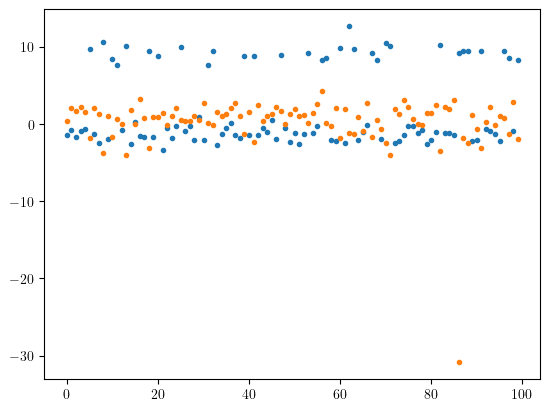

0.007405912347056701


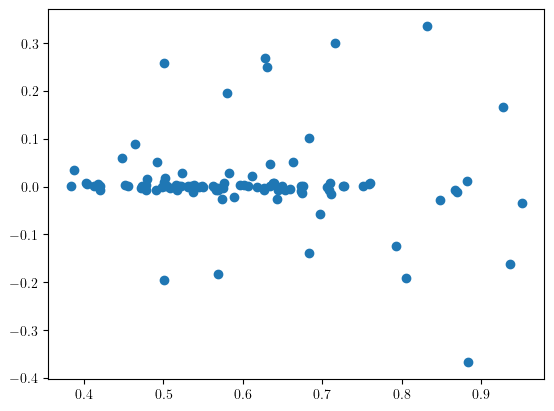

In [142]:
vval = comparison_df[(comparison_df.n_rv == 3) & (comparison_df.NAME == "S Vul")]
fig, axs = plt.subplots()
axs.scatter(vval.max_gap, (vval.diff_delta_phi + 0.5) % 1 - 0.5)

print(np.mean((vval.diff_delta_phi + 0.5) % 1 - 0.5))

In [ ]:
def plot_results_subsampling(subsample_nrv, show_min_max=False):
    """Plot the results of the subsampling analysis."""
    fit_rv_n_str = f"fit_rv_n_{subsample_nrv}"
    columns_to_get = [
        "logp",
        "set",
        "n_rv",
        "all_measures",
        fit_rv_n_str,
    ]
    res_subsample_nrv = results_map[columns_to_get].copy()
    res_subsample_nrv = res_subsample_nrv.dropna()
    # Calculate delta vgamma and delta p2p
    res_subsample_nrv["delta_vgamma"] = res_subsample_nrv.apply(
        lambda x: np.array(x[fit_rv_n_str]["delta_vgamma"]),
        axis=1,
    )
    res_subsample_nrv["delta_p2p"] = res_subsample_nrv.apply(
        lambda x: np.array(x[fit_rv_n_str]["delta_p2p"]),
        axis=1,
    )
    # Set colors for train and test sets
    res_subsample_nrv["set_color"] = res_subsample_nrv["set"].apply(
        lambda x: color_safe["blue"] if x == "train" else color_safe["dark_orange"]
    )

    # Calulate RMSE for each fit between the fit and the VELOCE fit
    res_subsample_nrv["subsample_coeffs"] = res_subsample_nrv.apply(
        lambda x: np.array(x[fit_rv_n_str]["coeffs"]),
        axis=1,
    )
    subsample_pca_model = deepcopy(pca_components_model)
    res_subsample_nrv["rmse"] = np.nan
    res_subsample_nrv["rmse"] = res_subsample_nrv["rmse"].astype(object)
    res_subsample_nrv["rmse_ratio"] = np.nan
    res_subsample_nrv["rmse_ratio"] = res_subsample_nrv["rmse_ratio"].astype(object)
    for tt, row in res_subsample_nrv.iterrows():
        dataset_fit_row = dataset_fit[dataset_fit.target == tt].iloc[0]
        veloce_curve = dataset_fit_row["sample"] + dataset_fit_row["veloce_vgamma"]
        rmse = []
        for co in row["subsample_coeffs"]:
            subsample_pca_model.update_parameters_values(co)
            values = subsample_pca_model.evaluate(phase_grid)
            rmse.append(
                np.sqrt(np.sum((values - veloce_curve) ** 2) / (len(phase_grid)))
            )
        res_subsample_nrv.at[tt, "rmse"] = rmse
        res_subsample_nrv.at[tt, "rmse_ratio"] = (
            np.array(rmse) / dataset_fit_row["peak2peak"]
        )

    # Plot the results
    width = 3.46 * 1.5
    height = width * 2 / 1.618  # / 2
    fig, axs = plt.subplots(
        3,
        1,
        figsize=(width, height),
        sharex=True,
        gridspec_kw={"hspace": 0},
    )
    axs[0].set_title(
        r"Subsampling analysis for $N_{\rm RV} = "
        + f"{subsample_nrv}$ ({len(res_subsample_nrv)} targets)",
        fontsize=font_size + 2,
        fontweight="bold",
    )

    quantity_names = ["delta_vgamma", "delta_p2p", "rmse"]
    quantity_labels = [r"$\Delta v_\gamma$", r"$\Delta P2P$", r"$\mathrm{RMSE}$"]
    quantity_labels_nomath = [r"\Delta v_\gamma", r"\Delta P2P", r"\mathrm{RMSE}"]
    unit = ["km/s", "km/s", "km/s"]
    pos_text_x = [0.03, 0.03, 0.03]
    pos_text_y = [0.05, 0.05, 0.95]
    verticalalignment_text = ["bottom", "bottom", "top"]

    for i, ax in enumerate(axs):
        mean_val = res_subsample_nrv[quantity_names[i]].apply(np.mean)
        std_val = res_subsample_nrv[quantity_names[i]].apply(np.std)
        res_subsample_nrv[f"{quantity_names[i]}_mean"] = mean_val
        res_subsample_nrv[f"{quantity_names[i]}_std"] = std_val
        ax.errorbar(
            res_subsample_nrv["logp"],
            mean_val,
            yerr=std_val,
            fmt=",",
            lw=0.5,
            color=color_safe["black"],
            zorder=3,
        )
        ax.scatter(
            res_subsample_nrv["logp"],
            mean_val,
            c=res_subsample_nrv["set_color"],
            s=25,
            alpha=1,
            marker="o",
            edgecolors="k",
            linewidths=0.5,
            zorder=5,
        )
        ax.axhline(0, color="black", lw=0.5, ls="--", zorder=6)

        if show_min_max:
            min_val = res_subsample_nrv[quantity_names[i]].apply(np.min)
            max_val = res_subsample_nrv[quantity_names[i]].apply(np.max)
            min_max_values = np.array(
                [
                    np.abs(min_val.to_numpy() - mean_val),
                    np.abs(max_val.to_numpy() - mean_val),
                ],
            )
            ax.errorbar(
                res_subsample_nrv["logp"],
                mean_val,
                yerr=min_max_values,
                fmt=",",
                lw=0.5,
                color=color_safe["light_green"],
                zorder=2,
            )
        ax.set_ylabel(quantity_labels[i] + f" [{unit[i]}]", fontsize=font_size + 3)

        x_ticks = np.arange(0.2, 2, 0.2)
        x_ticks_minor = np.arange(0.2, 2, 0.05)
        format_xticks(ax, x_ticks, x_ticks_minor)
        ax.set_xlim(0.22, 1.9)

        # Get the y-axis limits
        ylim = ax.get_ylim()
        y_steps = [1, 0.5]
        if subsample_nrv == 20:
            y_steps = [0.5, 0.25]
        if (ylim[1] - ylim[0]) > 10:
            y_steps = [2, 1]
        if (ylim[1] - ylim[0]) > 20:
            y_steps = [5, 1]

        y_ticks = np.arange(-30, 30, y_steps[0])
        y_ticks_minor = np.arange(-30, 30, y_steps[1])
        format_yticks(ax, y_ticks, y_ticks_minor)
        ax.set_ylim(*ylim)
        # Add text with the mean and std
        text = (
            r"$\overline{"
            + quantity_labels_nomath[i]
            + "} "
            + f"= {np.mean(mean_val.to_numpy()):.3f}"
            " [km/s]$\n"
        )
        if quantity_labels[i] != r"$\mathrm{RMSE}$":
            text += (
                r"$\sigma(" + quantity_labels_nomath[i] + f") = {np.std(mean_val):.3f}"
                "[km/s]$"
            )

        ax.text(
            pos_text_x[i],
            pos_text_y[i],
            s=text,
            fontsize=font_size,
            verticalalignment=verticalalignment_text[i],
            horizontalalignment="left",
            transform=ax.transAxes,
        )

    axs[-1].set_xlabel(r"$\log P$ [days]", fontsize=font_size + 3)

    fig.tight_layout()
    results_saving_directory = saving_directory / f"results_subsampling"
    results_saving_directory.mkdir(parents=True, exist_ok=True)
    name = f"subsampling_analysis_{subsample_nrv}"
    if show_min_max:
        name += "_min_max"
    fig.savefig(
        results_saving_directory / (name + ".pdf"),
        format="pdf",
        bbox_inches="tight",
    )
    return res_subsample_nrv

In [78]:
kde_comps.domain

{'log_P': (0.1622223686372001, 1.9907206025129691),
 'pc1': (-329.8660014521853, 360.530326080534),
 'pc2': (-130.74436957363193, 215.796088851239),
 'pc3': (-143.2556272956076, 151.24340123323634),
 'pc4': (-83.82667639023121, 78.97793501289725),
 'pc5': (-68.64464245869652, 74.65281829608094),
 'pc6': (-32.977333877579866, 32.7069340997721)}

In [79]:
g = comparison_df[(comparison_df["n_rv"] == 3)].groupby("NAME")
summary = g.agg(
    log_P=("log_P", "first"),
    vgamma_mean=("delta_vgamma", "mean"),
    vgamma_std=("delta_vgamma", "std"),
    p2p_mean=("delta_p2p", "mean"),
    p2p_std=("delta_p2p", "std"),
    rmse_mean=("rmse", "mean"),
    rmse_std=("rmse", "std"),
    delta_phi=("diff_delta_phi", "mean"),
    delta_phi_std=("diff_delta_phi", "std"),
).reset_index()
summary[summary["vgamma_std"] == max(summary["vgamma_std"])]

,NAME,log_P,vgamma_mean,vgamma_std,p2p_mean,p2p_std,rmse_mean,rmse_std,delta_phi,delta_phi_std
133,TT Aql,1.138448,-1.090062,5.710156,-4.907265,8.173708,5.413235,2.837359,-0.070042,0.258403


In [81]:
comparison_df_3.sort_values(by="delta_vgamma_norm", key=abs, ascending=False).head(20)

,NAME,SET,log_P,n_rv,i_resample,delta_vgamma,delta_p2p,rmse,delta_vgamma_norm,delta_p2p_norm,...,real_delta_phi,diff_delta_phi,arc_gaps,max_gap,naive_dvgamma,naive_dp2p,delta_vgamma_naive,delta_p2p_naive,delta_vgamma_naive_norm,delta_p2p_naive_norm
1463,alf UMi,test,0.599011,3,63,6.269807,10.685928,3.687700,1.778329,3.030890,...,0.827910,-0.378940,"[0.1857729366143417, 0.06890445028346903, 0.74...",0.745323,1.104516,-1.465006,1.104516,-1.465006,0.313278,-0.415525
1482,alf UMi,test,0.599011,3,82,6.254254,11.895857,4.232697,1.773917,3.374067,...,0.827910,-0.578875,"[0.734418936808197, 0.008670557413154256, 0.25...",0.734419,1.175610,-2.344481,1.175610,-2.344481,0.333443,-0.664974
1472,alf UMi,test,0.599011,3,72,5.433023,7.998493,3.069931,1.540989,2.268643,...,0.827910,-0.596043,"[0.10946320585139802, 0.7117683911402537, 0.17...",0.711768,1.132299,-2.570600,1.132299,-2.570600,0.321158,-0.729109
17675,V0440 Per,train,0.879256,3,99,6.663674,26.940327,9.374263,1.408544,5.694553,...,0.158480,0.031039,"[0.001642564235453392, 0.6532039242337646, 0.3...",0.653204,-0.679749,-2.822263,-0.679749,-2.822263,-0.143683,-0.596560
1433,alf UMi,test,0.599011,3,33,4.936374,10.847824,4.070950,1.400122,3.076809,...,0.827910,-0.802162,"[0.20907563726348144, 0.042218627893930716, 0....",0.748706,-0.177846,-1.074877,-0.177846,-1.074877,-0.050443,-0.304871
1431,alf UMi,test,0.599011,3,31,4.335394,9.482055,3.267002,1.229664,2.689431,...,0.827910,-0.205503,"[0.21163762569537425, 0.06995472212653908, 0.7...",0.718408,-0.179878,-1.089742,-0.179878,-1.089742,-0.051019,-0.309088
10639,MY Pup,train,0.755426,3,39,9.927489,24.738407,8.659622,1.112227,2.771570,...,0.121279,0.262959,"[0.6438920943028847, 0.2057795420649029, 0.150...",0.643892,-0.051975,-0.604892,-0.051975,-0.604892,-0.005823,-0.067769
1436,alf UMi,test,0.599011,3,36,3.862064,10.252635,3.948778,1.095412,2.907993,...,0.827910,0.004218,"[0.0665891252826043, 0.2617840316157469, 0.671...",0.671627,-1.015123,-3.155457,-1.015123,-3.155457,-0.287923,-0.894994
1404,alf UMi,test,0.599011,3,4,3.823725,8.875815,3.363159,1.084538,2.517481,...,0.827910,0.146431,"[0.17528124164141445, 0.13235131553096835, 0.6...",0.692367,-0.385787,-0.617588,-0.385787,-0.617588,-0.109422,-0.175169
1426,alf UMi,test,0.599011,3,26,3.397862,9.122053,3.412876,0.963748,2.587322,...,0.827910,-0.112206,"[0.01777287199473676, 0.2878859352012455, 0.69...",0.694341,-0.812659,-0.808206,-0.812659,-0.808206,-0.230497,-0.229234


In [105]:
comparison_df["diff_p2p"] = comparison_df["delta_p2p"] - comparison_df["naive_dp2p"]

In [ ]:
comparison_df[comparison_df["naive_dp2p"] > comparison_df["delta_p2p"]].sort_values(
    by="diff_p2p"
)

,NAME,SET,log_P,n_rv,i_resample,delta_vgamma,delta_p2p,rmse,delta_vgamma_norm,delta_p2p_norm,rmse_norm,veloce_p2p,delta_phi,real_delta_phi,diff_delta_phi,arc_gaps,max_gap,naive_dvgamma,naive_dp2p,diff_p2p
150873,S Sge,train,0.923352,20,4,0.520235,-5.275377,1.904755,0.014318,-0.145190,0.052423,36.334249,0.131811,0.119480,0.012331,"[0.12164495249555252, 0.00849132730630231, 0.0...",0.150901,4.040379,-0.658122,-4.617254
119910,W Sgr,train,0.880532,10,43,-3.105155,-6.113056,4.672941,-0.079554,-0.156616,0.119721,39.032070,0.213670,0.213760,-0.000090,"[0.14032910304018742, 0.31931818322766503, 0.0...",0.319318,-5.255860,-1.734633,-4.378423
137887,X Sgr,train,0.845892,15,91,-0.913784,-4.619819,1.332007,-0.030921,-0.156327,0.045073,29.552196,0.159516,0.153236,0.006280,"[0.10198040407701114, 0.024535909148141855, 0....",0.163966,-2.120864,-0.811788,-3.808031
122134,TT Aql,test,1.138448,15,47,0.810972,-5.065700,4.851872,0.015231,-0.095137,0.091121,53.246588,0.916687,0.881093,0.035594,"[0.018416994628438488, 0.051943168494716474, 0...",0.166288,3.212481,-1.378948,-3.686752
137874,X Sgr,train,0.845892,15,72,-0.249190,-2.677052,1.189877,-0.008432,-0.090587,0.040264,29.552196,0.151670,0.153236,-0.001566,"[0.13645884116183282, 0.12412561703341396, 0.1...",0.192023,1.612317,0.915251,-3.592303
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
146304,HW Car,train,0.963752,20,20,0.047979,0.066535,0.132872,0.002483,0.003443,0.006876,19.324804,0.291505,0.290830,0.000675,"[0.027087359524053056, 0.029036378032975207, 0...",0.155196,1.845268,0.066716,-0.000180
134655,V0381 Cen,train,0.705764,15,91,-0.043572,-0.335699,0.294609,-0.001265,-0.009744,0.008552,34.450386,0.137793,0.138933,-0.001139,"[0.0193567598614095, 0.11491396746259852, 0.00...",0.145364,-0.210767,-0.335566,-0.000133
144078,BP Cir,train,0.379872,20,6,-0.004086,-0.022417,0.082911,-0.000242,-0.001326,0.004903,16.911598,0.131932,0.134896,-0.002964,"[0.04964772840259002, 0.030350186909544163, 0....",0.128611,-1.464920,-0.022311,-0.000106
63903,AK Cep,test,0.859295,6,13,1.668956,-3.858196,3.521591,0.046260,-0.106942,0.097612,36.077361,0.111399,0.131480,-0.020081,"[0.04745386688635733, 0.13124933507734227, 0.0...",0.389444,-4.706984,-3.858176,-0.000020


In [90]:
comparison_df.sort_values("log_P")

,NAME,SET,log_P,n_rv,i_resample,delta_vgamma,delta_p2p,rmse,delta_vgamma_norm,delta_p2p_norm,...,real_delta_phi,diff_delta_phi,arc_gaps,max_gap,naive_dvgamma,naive_dp2p,delta_vgamma_naive,delta_p2p_naive,delta_vgamma_naive_norm,delta_p2p_naive_norm
38924,V0397 Car,train,0.314597,4,48,-0.001874,0.247420,0.436650,-0.000111,0.014608,...,0.179362,0.000667,"[0.029920662024323974, 0.48674786855315233, 0....",0.486748,-4.153913,-0.939270,-4.153913,-0.939270,-0.245255,-0.055456
38957,V0397 Car,train,0.314597,4,81,-0.453928,-1.264695,1.005040,-0.026801,-0.074670,...,0.179362,0.003084,"[0.3390812345264749, 0.3536048762207429, 0.108...",0.353605,-2.719935,-1.831860,-2.719935,-1.831860,-0.160590,-0.108156
38958,V0397 Car,train,0.314597,4,82,-0.264771,1.251907,0.462770,-0.015633,0.073915,...,0.179362,0.000788,"[0.2503224207007406, 0.046719154345680636, 0.2...",0.476855,3.342480,-6.178180,3.342480,-6.178180,0.197346,-0.364771
38959,V0397 Car,train,0.314597,4,83,0.158904,0.324280,0.207081,0.009382,0.019146,...,0.179362,-0.012043,"[0.30342967117690023, 0.07759998377446209, 0.3...",0.355778,0.909995,-0.524130,0.909995,-0.524130,0.053728,-0.030946
38960,V0397 Car,train,0.314597,4,84,-1.218918,-2.291885,0.779637,-0.071967,-0.135317,...,0.179362,-0.015275,"[0.04986532408202038, 0.6865017065470056, 0.21...",0.686502,-5.010885,-3.386760,-5.010885,-3.386760,-0.295852,-0.199960
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12039,S Vul,train,1.838346,3,39,-1.000415,-0.068895,1.249200,-0.035197,-0.002424,...,0.026626,-0.008784,"[0.6343718385473478, 0.0704222014557736, 0.295...",0.634372,4.872474,-0.842543,4.872474,-0.842543,0.171424,-0.029642
12040,S Vul,train,1.838346,3,40,-0.905641,0.418607,0.391452,-0.031862,0.014727,...,0.026626,0.018252,"[0.31727772154356404, 0.295299330434313, 0.387...",0.387423,0.941538,-3.096711,0.941538,-3.096711,0.033125,-0.108949
12041,S Vul,train,1.838346,3,41,0.552245,1.237940,0.656663,0.019429,0.043553,...,0.026626,-0.017303,"[0.4510367084972948, 0.28623288229541544, 0.26...",0.451037,1.541696,-1.133983,1.541696,-1.133983,0.054240,-0.039896
12028,S Vul,train,1.838346,3,28,5.050755,-0.949479,0.908941,0.177696,-0.033405,...,0.026626,0.854788,"[0.043497151485361485, 0.31821167872180567, 0....",0.638291,5.216588,-13.933401,5.216588,-13.933401,0.183531,-0.490207


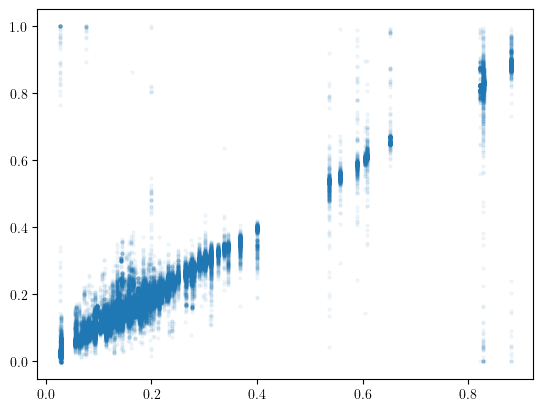

In [78]:
fig, axs = plt.subplots()
axs.scatter(
    comparison_df["real_delta_phi"],
    comparison_df["delta_phi"],
    s=5,
    alpha=0.05,
)

In [80]:
comparison_df_3 = comparison_df[comparison_df["n_rv"] == 3]

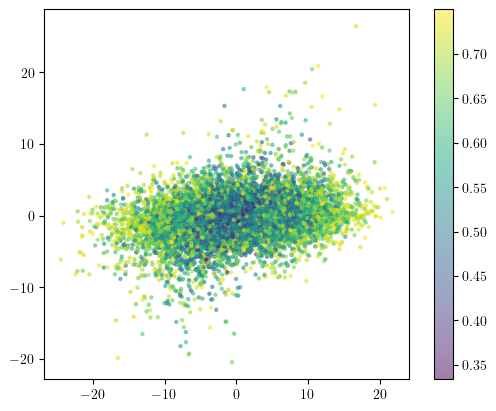

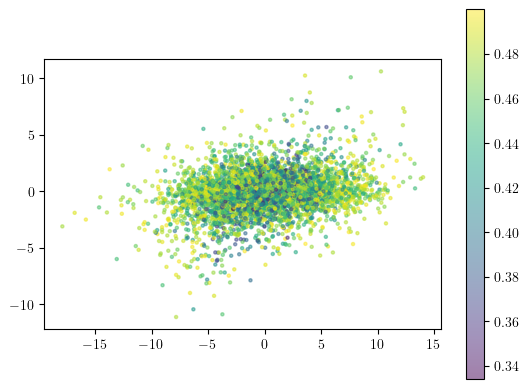

In [83]:
fig, axs = plt.subplots()
s = axs.scatter(
    comparison_df_3["naive_dvgamma"],
    comparison_df_3["delta_vgamma"],
    c=comparison_df_3["max_gap"],
    s=5,
    alpha=0.5,
    cmap="viridis",
)
fig.colorbar(s)
axs.set_aspect(1)

fig, axs = plt.subplots()
sub_comparison_df_3 = comparison_df_3[comparison_df_3["max_gap"] < 0.5]
s = axs.scatter(
    sub_comparison_df_3["naive_dvgamma"],
    sub_comparison_df_3["delta_vgamma"],
    c=sub_comparison_df_3["max_gap"],
    s=5,
    alpha=0.5,
    cmap="viridis",
)
fig.colorbar(s)
axs.set_aspect(1)


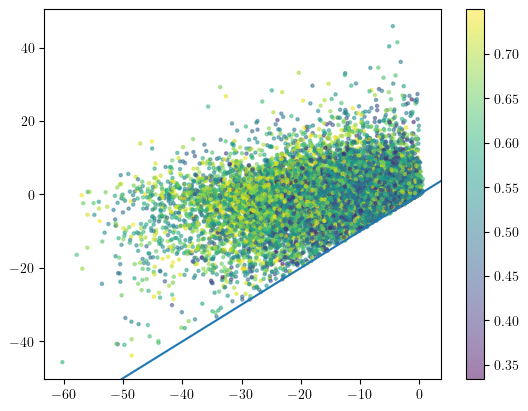

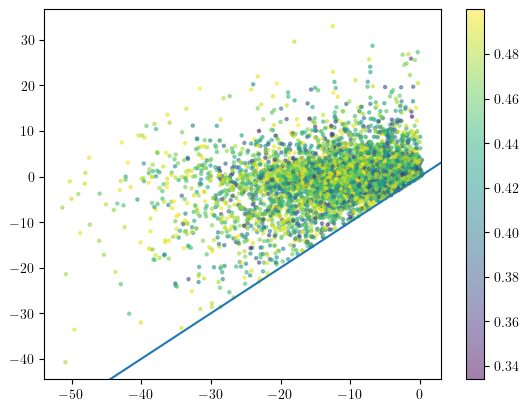

In [84]:
fig, axs = plt.subplots()
s = axs.scatter(
    comparison_df_3["naive_dp2p"],
    comparison_df_3["delta_p2p"],
    c=comparison_df_3["max_gap"],
    s=5,
    alpha=0.5,
    cmap="viridis",
)
axs.axline((0, 0), slope=1)
# axs.set_aspect(1)
fig.colorbar(s)

fig, axs = plt.subplots()
s = axs.scatter(
    sub_comparison_df_3["naive_dp2p"],
    sub_comparison_df_3["delta_p2p"],
    c=sub_comparison_df_3["max_gap"],
    s=5,
    alpha=0.5,
    cmap="viridis",
)
axs.axline((0, 0), slope=1)
# axs.set_aspect(1)
fig.colorbar(s)


<ErrorbarContainer object of 3 artists>

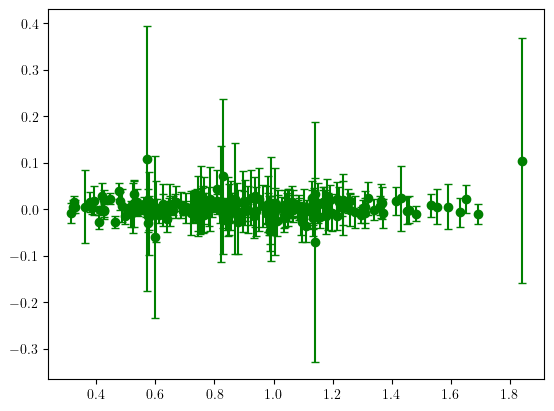

In [85]:
fig, axs = plt.subplots()
axs.errorbar(
    summary["log_P"],
    summary["delta_phi"],
    yerr=summary["delta_phi_std"],
    fmt="o",
    capsize=3,
    color="green",
)

In [ ]:
data_dv = [
    comparison_df.loc[
        (comparison_df["n_rv"] == 3) & (comparison_df.NAME == name), "delta_vgamma"
    ]
    .dropna()
    .to_numpy()
    for name in comparison_df.NAME.unique()
]

3 -> 0.640934974283615
3 vgamma -0.013412905525647768 0.48405096036236966
3 vgamma -0.011850807566227774 0.4715244893119198
3 P2P -0.14918049555991655 2.3444205798093227
3 RMSE 1.388675879903137 1.0240494383999323
4 -> 0.7964678899082569
4 vgamma -0.011712350088771403 0.3562087837951284
4 vgamma -0.020281722320295622 0.32098551135978154
4 P2P -0.19798889659621424 1.6255990914392053
4 RMSE 1.1451830418541635 0.8233250351410927
5 -> 0.8926146788990825
5 vgamma -0.029148019533608214 0.25510329984866037
5 vgamma -0.02766300991855441 0.23058004170067883
5 P2P -0.2690328884950455 1.2402135379404047
5 RMSE 1.07315953184259 0.7498188053445315
6 -> 0.9467958134410577
6 vgamma -0.005970776490609685 0.2058840078345477
6 vgamma -0.007632232393259041 0.19587998857082378
6 P2P -0.2668024218265552 1.1421595700303493
6 RMSE 0.9621166860169418 0.6652861694638574
7 -> 0.9741474654377881
7 vgamma -0.0196786656052903 0.16051817346719824
7 vgamma -0.01782768363475276 0.15340350297165137
7 P2P -0.2995020860

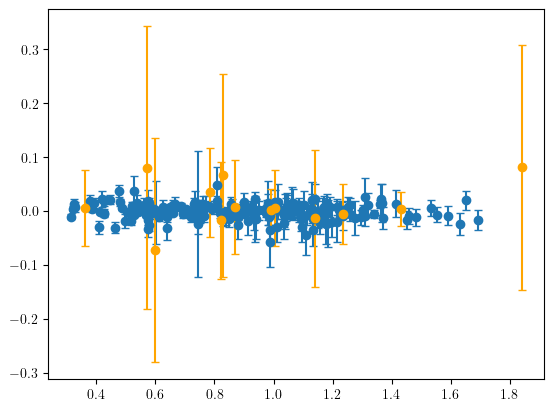

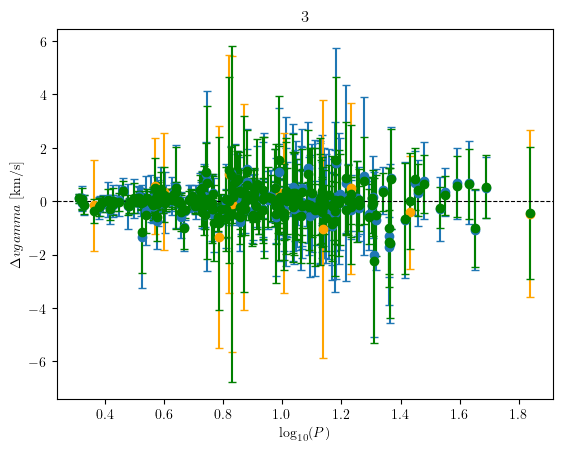

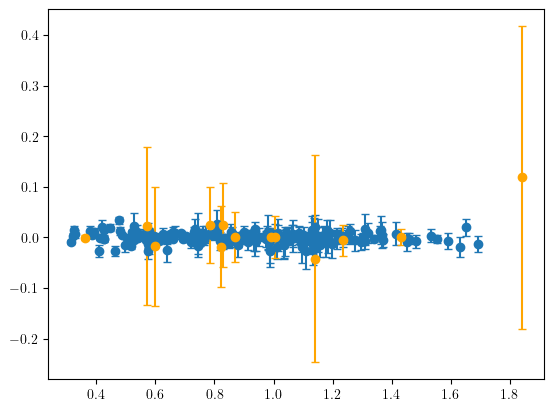

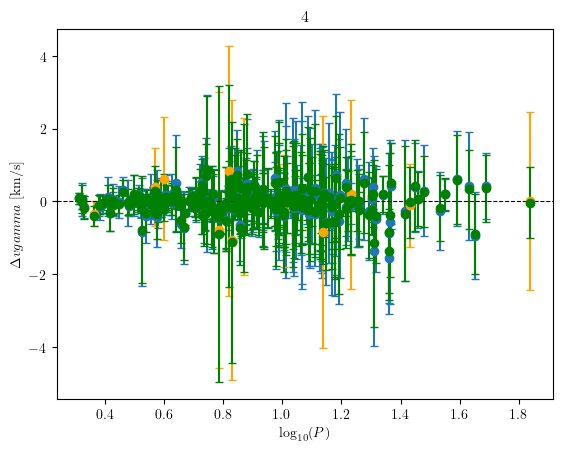

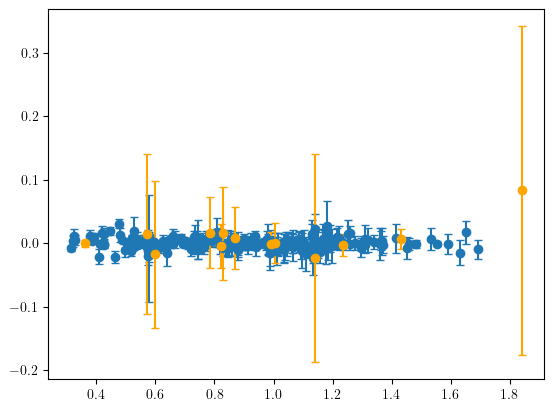

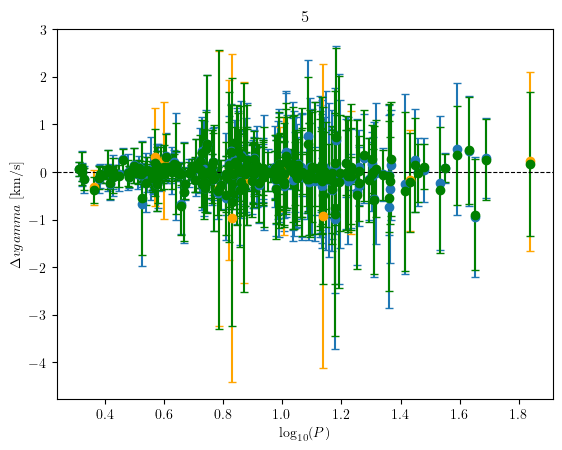

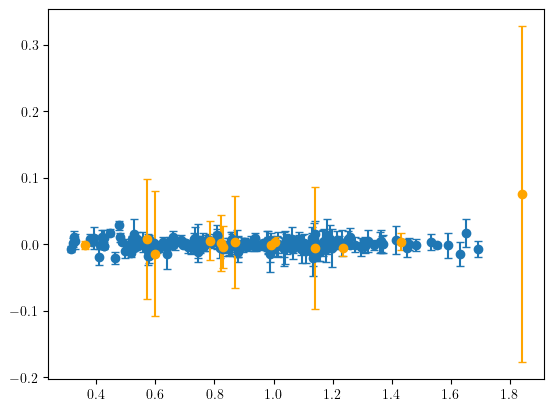

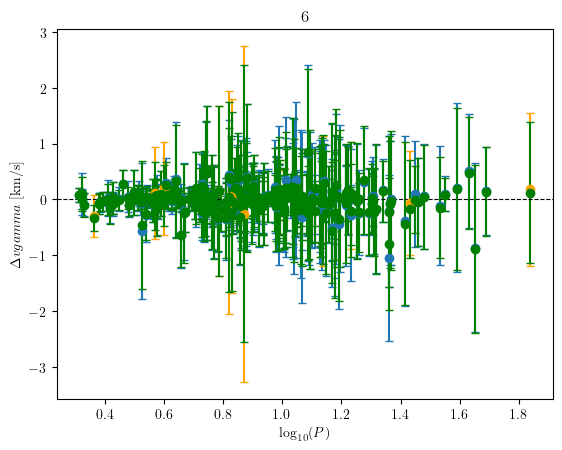

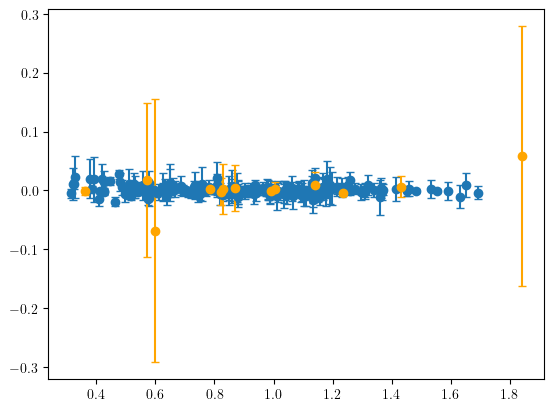

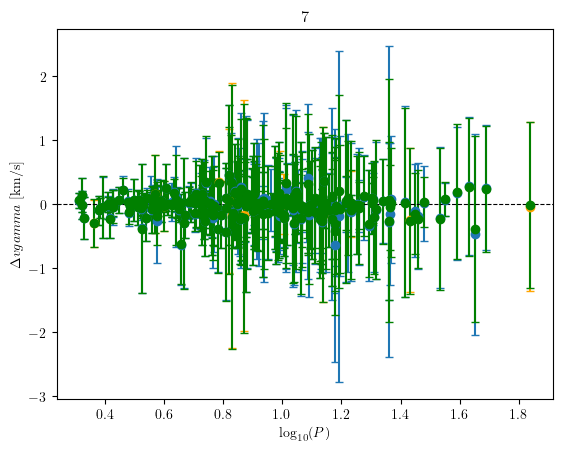

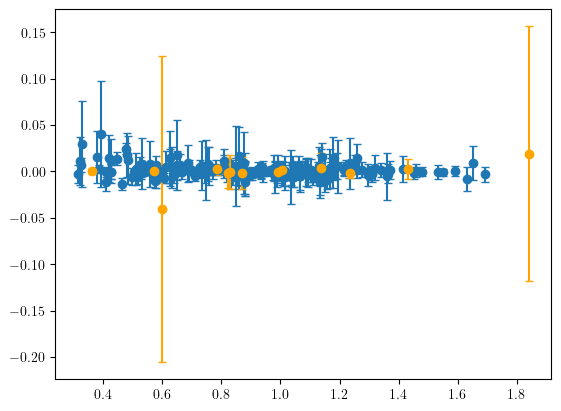

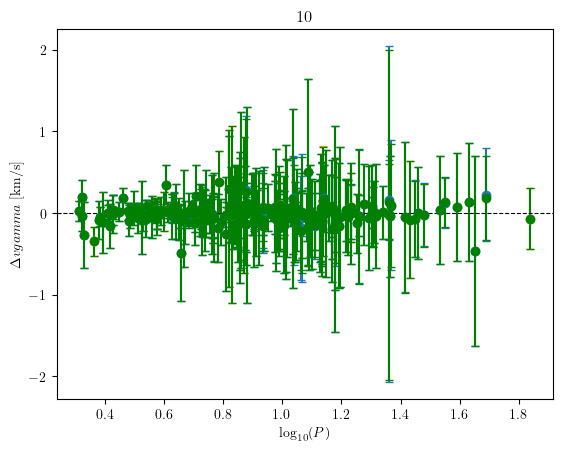

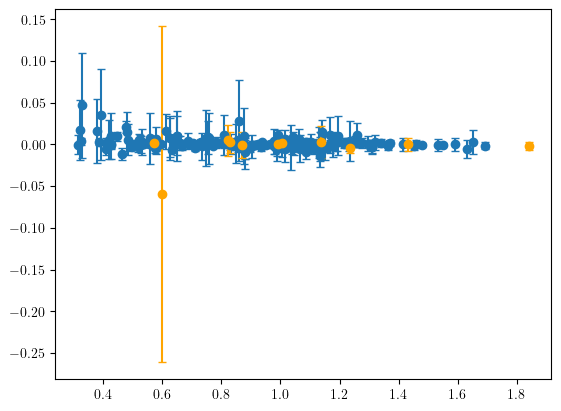

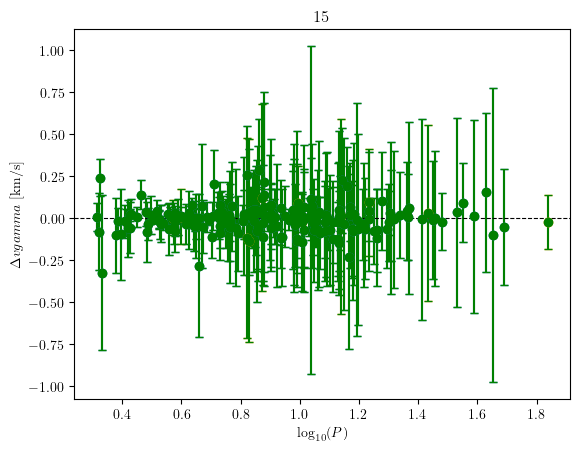

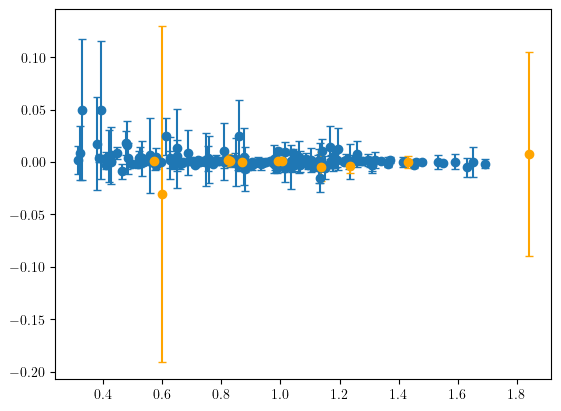

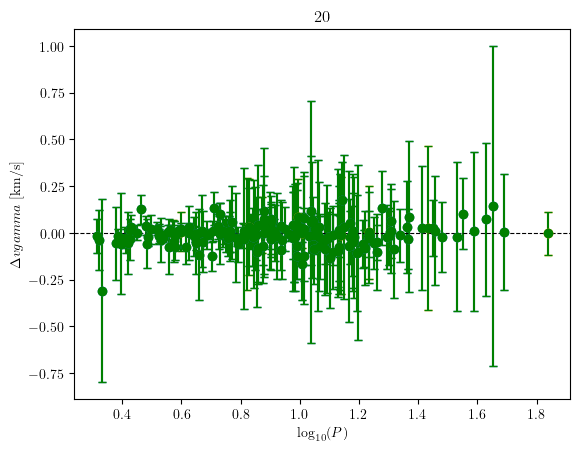

In [66]:
for nrv in n_subsample:
    nmaxgap = len(
        comparison_df[(comparison_df["n_rv"] == nrv) & (comparison_df["max_gap"] < 0.6)]
    )
    nall = len(comparison_df[comparison_df["n_rv"] == nrv])
    print(f"{nrv} -> {nmaxgap / nall}")
    g = comparison_df[comparison_df["n_rv"] == nrv].groupby("NAME")

    summary = g.agg(
        log_P=("log_P", "first"),
        vgamma_mean=("delta_vgamma", "mean"),
        vgamma_std=("delta_vgamma", "std"),
        p2p_mean=("delta_p2p", "mean"),
        p2p_std=("delta_p2p", "std"),
        rmse_mean=("rmse", "mean"),
        rmse_std=("rmse", "std"),
        delta_phi=("diff_delta_phi", "mean"),
        delta_phi_std=("diff_delta_phi", "std"),
    ).reset_index()

    gg = comparison_df[
        (comparison_df["n_rv"] == nrv) & (comparison_df["max_gap"] < 0.6)
    ].groupby("NAME")

    summary_g = gg.agg(
        log_P=("log_P", "first"),
        vgamma_mean=("delta_vgamma", "mean"),
        vgamma_std=("delta_vgamma", "std"),
        p2p_mean=("delta_p2p", "mean"),
        p2p_std=("delta_p2p", "std"),
        rmse_mean=("rmse", "mean"),
        rmse_std=("rmse", "std"),
        delta_phi=("diff_delta_phi", "mean"),
        delta_phi_std=("diff_delta_phi", "std"),
    ).reset_index()
    summary["no_phi_prior"] = False

    for i, row in summary.iterrows():
        name = row.NAME
        header = veloce_headers[veloce_headers["NAME"] == name].iloc[0]
        source_id = int(header.GAIA_DR3_SOURCE_ID)
        if source_id not in df_gaiadr3_selection["source_id"].to_numpy():
            summary.loc[i, "no_phi_prior"] = True
        if row.log_P > kde_phot_phase.domain["log_P"][1]:
            summary.loc[i, "no_phi_prior"] = True

    fig, ax = plt.subplots()
    ax.errorbar(
        summary["log_P"][~summary.no_phi_prior],
        summary["delta_phi"][~summary.no_phi_prior],
        yerr=summary["delta_phi_std"][~summary.no_phi_prior],
        fmt="o",
        capsize=3,
    )
    ax.errorbar(
        summary["log_P"][summary.no_phi_prior],
        summary["delta_phi"][summary.no_phi_prior],
        yerr=summary["delta_phi_std"][summary.no_phi_prior],
        fmt="o",
        capsize=3,
        color="orange",
    )

    # if nrv == 3:
    #     fig, axs = plt.subplots()
    #     axs.boxplot(data_dv, positions=summary.log_P)
    # # Plot
    fig, ax = plt.subplots()
    ax.errorbar(
        summary["log_P"][~summary.no_phi_prior],
        summary["vgamma_mean"][~summary.no_phi_prior],
        yerr=summary["vgamma_std"][~summary.no_phi_prior],
        fmt="o",
        capsize=3,
    )
    ax.errorbar(
        summary["log_P"][summary.no_phi_prior],
        summary["vgamma_mean"][summary.no_phi_prior],
        yerr=summary["vgamma_std"][summary.no_phi_prior],
        fmt="o",
        capsize=3,
        color="orange",
    )
    ax.errorbar(
        summary_g["log_P"],
        summary_g["vgamma_mean"],
        yerr=summary_g["vgamma_std"],
        fmt="o",
        capsize=3,
        color="green",
    )
    ax.axhline(0, color="k", lw=0.8, ls="--")
    ax.set_xlabel(r"$\log_{10}(P)$")
    ax.set_ylabel(r"$\Delta vgamma$ [km/s]")
    ax.set_title(nrv)
    print(nrv, "vgamma", summary["vgamma_mean"].mean(), summary["vgamma_mean"].std())
    print(
        nrv, "vgamma", summary_g["vgamma_mean"].mean(), summary_g["vgamma_mean"].std()
    )
    print(nrv, "P2P", summary["p2p_mean"].mean(), summary["p2p_mean"].std())
    print(nrv, "RMSE", summary["rmse_mean"].mean(), summary["rmse_mean"].std())

In [64]:
summary

,NAME,log_P,vgamma_mean,vgamma_std,p2p_mean,p2p_std,rmse_mean,rmse_std,no_phi_prior
0,AA Gem,1.053221,0.004224,0.093713,-0.910938,0.330656,0.528414,0.196154,False
1,AB Cam,0.762497,-0.044266,0.329754,0.002729,1.700334,0.788187,0.442924,False
2,AC Mon,0.903903,0.009985,0.482615,0.203022,1.929348,1.156018,1.752204,False
3,AD Pup,1.133462,-0.071815,0.354338,0.617868,1.364708,2.477738,2.532013,False
4,AH Vel,0.626049,-0.004031,0.440752,0.309844,1.369977,0.964820,1.623816,False
...,...,...,...,...,...,...,...,...,...
186,bet Dor,0.993116,0.050088,0.365894,-1.205760,1.250895,1.199453,1.301495,True
187,del Cep,0.729672,0.006028,0.216151,-0.034449,0.707656,0.369428,0.275312,False
188,eta Aql,0.855933,-0.262890,1.133605,2.656390,5.445172,3.565127,3.937420,False
189,l Car,1.550966,-0.016574,0.459468,0.304509,0.977215,0.857577,1.044160,False


In [80]:
header_row = veloce_headers[veloce_headers["NAME"] == "WW Mon"].iloc[0]
fit_row = veloce_fit[veloce_fit["NAME"] == "WW Mon"].iloc[0]
tveloce_vgamma = float(fit_row["VGAMMA"])
tveloce_p2p = float(header_row["PEAK2PEAK"])

In [ ]:
delta_tv = []
delta_tphase = []
delta_tp2p = []
print()
for res in result_map_list:
    delta_tv.append((res.theta_free[0] - tveloce_vgamma))
    delta_tphase.append(res.theta_free[-1] - real_delta_phase)
    delta_tp2p.append(
        np.ptp(phased_pca_model.evaluate(res.theta_free, x=phase_grid)) - tveloce_p2p
    )

In [91]:
tveloce_vgamma

53.05501321504116

In [92]:
np.std(delta_tv)

np.float64(1.4514407293793485)

In [95]:
np.std(delta_tp2p)

np.float64(5.733081762393111)

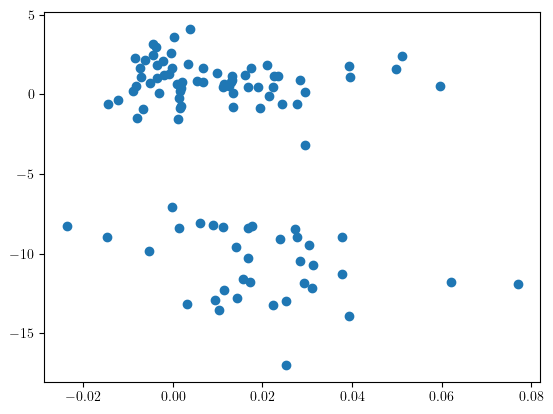

In [96]:
fig, axs = plt.subplots()
axs.scatter(delta_tphase, delta_tp2p)

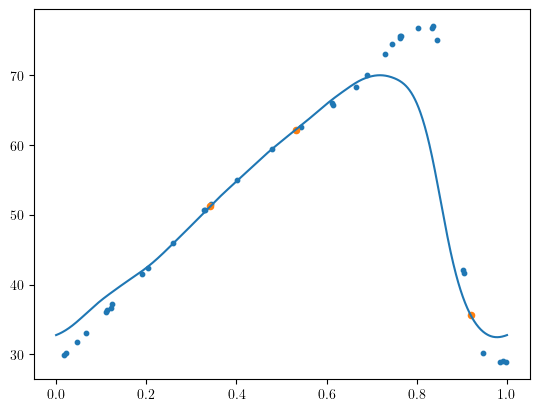

In [94]:
selected_comb = 3
comb = _combinations[selected_comb]
temp_phase = phase[comb]
temp_rv = rv[comb]
temp_rv_err = rv_err[comb]
solu = result_map_list[selected_comb]

fig, axs = plt.subplots()
axs.scatter(phase, rv, s=10)
axs.scatter(temp_phase, temp_rv, s=20)
axs.plot(phase_grid, phased_pca_model.evaluate(solu.theta_free, x=phase_grid))

In [98]:
example_coeff = []
for res in result_map_list:
    example_coeff.append(
        {
            "log_P": subsample_results["log_P"],
            "c": res.theta_free[0],
            "pc1": res.theta_free[1],
            "pc2": res.theta_free[2],
            "pc3": res.theta_free[3],
            "pc4": res.theta_free[4],
            "pc5": res.theta_free[5],
            "pc6": res.theta_free[6],
            "DELTA_PHASE": res.theta_free[-1],
        }
    )
example_coeff = pd.DataFrame(example_coeff)

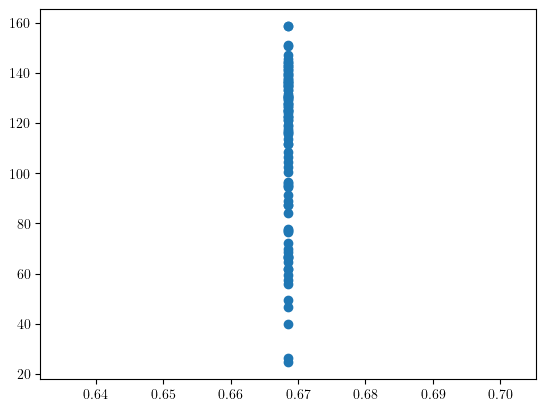

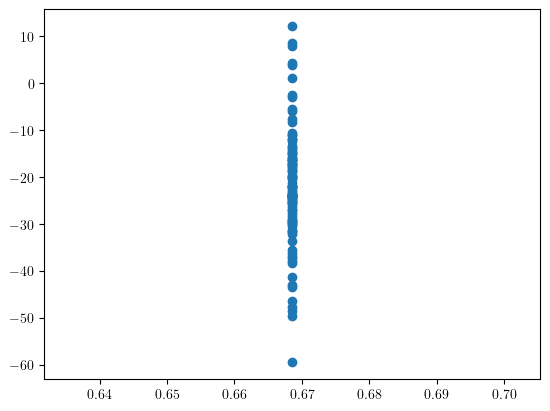

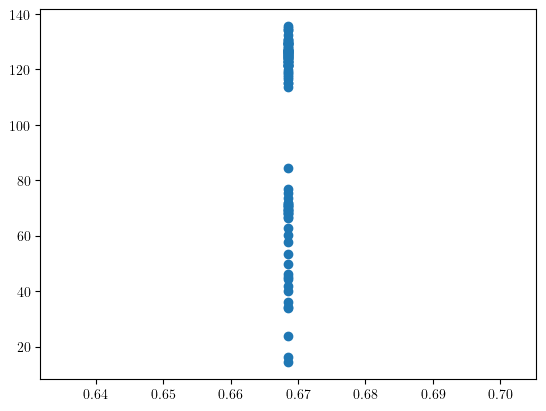

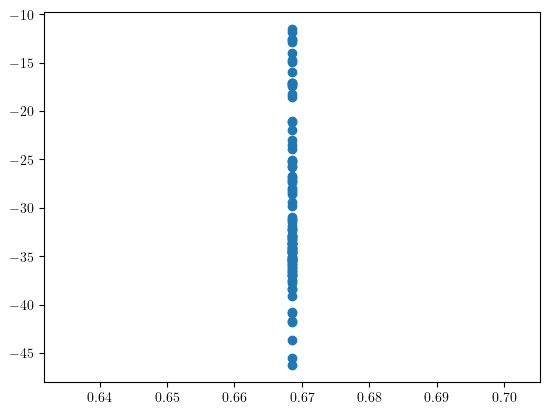

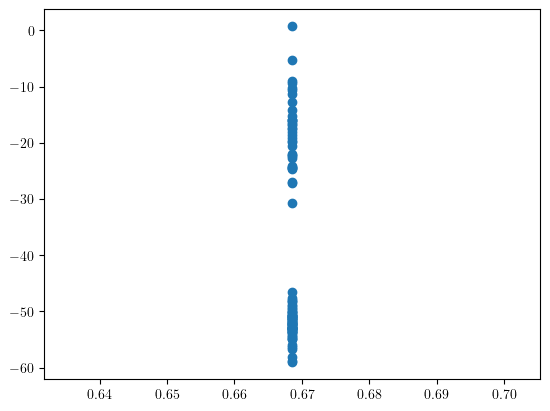

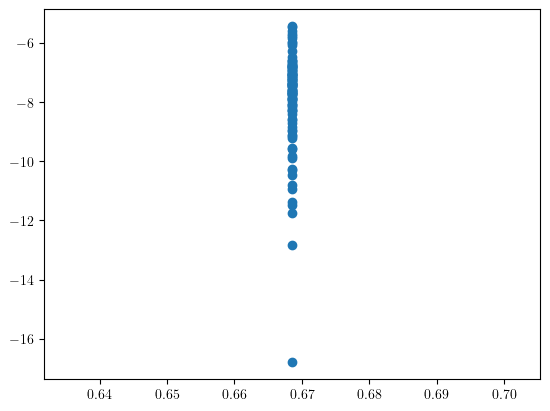

In [99]:
for i in range(1, 7):
    fig, axs = plt.subplots()
    axs.scatter(example_coeff["log_P"], example_coeff[f"pc{i}"])

In [86]:
bounds

[[-329.8660014521853, 360.530326080534],
 [-130.74436957363193, 215.796088851239],
 [-143.2556272956076, 151.24340123323634],
 [-83.82667639023121, 78.97793501289725],
 [-68.64464245869652, 74.65281829608094],
 [-32.977333877579866, 32.7069340997721],
 [-0.002799820504393667, 0.43292409108118146]]

In [87]:
pc_delta_starts[4]

array([   0.        , -274.98936491,   82.16656613,   42.52931833,
        -49.62007611,   35.80687074,  -17.07527325,    0.3320256 ])

In [88]:
lprior_starts[4]

np.float64(-106.37908391263392)

In [ ]:
rng_init = np.random.default_rng(54)
mapping_variables_model = phased_pca_model.layout.name_to_index
n_subsample = [3]
n_resamples_default = 100
kwargs_map = {
    "method": "Powell",
    "tol": 1e-3,
    "options": {"maxiter": 5000},
}
kwargs_de = {
    "strategy": "rand1bin",
    "maxiter": 3000,  # DE just needs to find the basin
    "popsize": 10,  # population = 10 * 8 = 80 individuals
    "tol": 0.01,  # looser: stop when population has 1% relative spread
    "polish": True,  # skip DE's internal L-BFGS-B step — fit_map does this
}

# for i, header in veloce_headers.iterrows():
for i, row in fit_rv_no_outliers.iterrows():
    header = veloce_headers[veloce_headers.NAME == row.NAME].iloc[0]
    # ----------------------------------------------------------------------------------
    # Get header info and photometric epoch
    # Using Gaia period is much more complicated since the
    name = header.NAME
    if name != "WW Mon":
        continue
        save_name = name.replace(" ", "_")
    print(f"{i}/ {len(veloce_headers)} - {name}")

    source_id = int(header.GAIA_DR3_SOURCE_ID)
    period = header.P
    log_p = np.log10(period)
    group = header.SET
    prefix = group + "_"
    has_gaia_epoch = True
    if source_id in df_gaiadr3_selection["source_id"].to_numpy():
        gaia_data = df_gaiadr3_selection[df_gaiadr3_selection["source_id"] == source_id]
        epoch_g = gaia_data["epoch_g"].to_numpy()[0] + epoch_offset_gaiadr3
    else:
        has_gaia_epoch = False
        epoch_g = epoch_offset_gaiadr3
        prefix += "NoGaia_"

    real_delta_phase = (
        (epoch_g - (header.E + epoch_offset_veloce)) / period + 0.5
    ) % 1 - 0.5

    # ----------------------------------------------------------------------------------
    # Get VELOCE observations and model
    target_data = veloce_data[(veloce_data["NAME"] == name) & (veloce_data["MASK"])]
    bjd, rv, rv_err = (
        target_data["BJD"].to_numpy().copy(),
        target_data["RV"].to_numpy().copy(),
        target_data["RV_ERR"].to_numpy().copy(),
    )
    # Remove trend
    target_veloce_fit = veloce_fit[veloce_fit["NAME"] == name].iloc[0]
    if isinstance(target_veloce_fit["POLY_COEFFS"], np.ndarray):
        trend_model = vf.model.PolynomialBasis(int(header["POLYDEG"]))
        trend = trend_model.evaluate(
            target_veloce_fit["POLY_COEFFS"],
            bjd - header["E"],
        )
        rv -= trend

    # Calculate phase use Gaia period and epoch (photometric data)
    phase = vf.model.calculate_phase(bjd, period, epoch_g - epoch_offset_veloce)

    # ----------------------------------------------------------------------------------
    # Create Priors
    priors = []
    kde_comps_for_target = kde_comps.conditional(log_P=log_p)
    priors.append(
        vf.prior.ParameterPrior(kde_comps_for_target, mapping_variables_model)
    )
    # One conditional prior on the phase
    has_phase_prior = True
    if log_p < kde_phot_phase.domain["log_P"][1] and has_gaia_epoch:
        cond_phase = kde_phot_phase.conditional(log_P=log_p)
        fast_phase = vf.prior.SplineDensity(cond_phase)
    else:
        has_phase_prior = False
        fast_phase = vf.prior.UniformDensity("DELTA_PHASE", 0.0, 1.0)
        print(f"{name}: No Phase prior")  # noqa: T201
        prefix += "NoPhiPrior_"

    idx = mapping_variables_model["delta_phi"]
    priors.append(vf.prior.ParameterPrior(fast_phase, {"DELTA_PHASE": idx}))
    log_prior_target = vf.prior.CombinedLogPrior(priors)

    specific_combinations = {}
    # Subsample
    for n_rv in n_subsample:
        # K = n_points_to_map.get(n_rv, 5)
        print(f"\t - n_rv = {n_rv} (K = NO) ->", end="")
        if len(rv) <= n_rv + 2:
            msg = f"{name}: Not enough data points to subsample {n_rv} points."
            msg += f" Only {len(rv)} points available. Skipping."
            logger.info(msg)
            continue

        n_combinations = math.comb(len(rv), n_rv)
        if n_combinations < 10000:  # noqa: PLR2004
            # Get all combinations
            _combinations = np.array(list(itertools.combinations(range(len(rv)), n_rv)))
        else:
            # Get random combinations
            _combinations = np.array(
                [
                    rng_init.choice(len(rv), n_rv, replace=False)
                    for _ in range(n_resamples_default)
                ],
            )

        if len(_combinations) > n_resamples_default:
            # Get random combinations but sure they are unique
            _combinations = _combinations[
                rng_init.choice(len(_combinations), n_resamples_default, replace=False)
            ]
        if len(_combinations) < n_resamples_default:
            # Save the combinations
            msg = f"{name}: {n_combinations} combinations for {n_rv} points."
            logger.info(msg)
            if name in specific_combinations:
                specific_combinations[name].update({f"nrv_{n_rv}": n_combinations})
            else:
                specific_combinations[name] = {}
                specific_combinations[name][f"nrv_{n_rv}"] = n_combinations

        n_resamples = len(_combinations)

        result_list = []

        for i, comb in enumerate(_combinations):
            if i % 5 == 0:
                print(i)

            temp_phase = phase[comb]
            temp_rv = rv[comb]
            temp_rv_err = rv_err[comb]

            temp_mean_rv = np.mean(temp_rv)
            bounds = [[temp_mean_rv - 35, temp_mean_rv + 35]]
            for param_name in phased_pca_model.param_names:
                if param_name in kde_comps.var_names:
                    bounds += [[*kde_comps.domain[param_name]]]
            if has_phase_prior:
                bounds += [[*kde_phot_phase.domain["DELTA_PHASE"]]]
            else:
                bounds += [[0, 1]]

            result_de = vf.fit.differential_evolution_posterior(
                compiled_model=phased_pca_model,
                bounds=bounds,
                x=temp_phase,
                y=temp_rv,
                yerr=temp_rv_err,
                logprior=log_prior_target,
                **kwargs_de,
            )
            result_list.append(result_de)

        subsample_results = {
            "target": name,
            "P": period,
            "log_P": log_p,
            "epoch_g": epoch_g,
            "n_rv": n_rv,
            "n_resamples": n_resamples,
            "selections": _combinations,
            "rv": rv,
            "rv_err": rv_err,
            "bjd": bjd,
            "phase": phase,
            "real_delta_phi": real_delta_phase,
            "result_de": result_list,
        }


193/ 219 - WW Mon
	 - n_rv = 3 (K = NO) ->0
5
10
15
20
25
30


KeyboardInterrupt: 

In [70]:
header_row = veloce_headers[veloce_headers["NAME"] == "WW Mon"].iloc[0]
fit_row = veloce_fit[veloce_fit["NAME"] == name].iloc[0]
tveloce_vgamma = float(fit_row["VGAMMA"])
tveloce_p2p = float(header_row["PEAK2PEAK"])

In [71]:
delta_tv = []
delta_tp2p = []
print()
for res in result_list:
    delta_tv.append((res.theta_free[0] - tveloce_vgamma))
    delta_tp2p.append(res.theta_free[-1] - real_delta_phase)


In [75]:
delta_tv

[np.float64(0.15045572207782243),
 np.float64(-0.16161647064475204),
 np.float64(-0.18965452201759092),
 np.float64(-1.7128775111537422),
 np.float64(-0.9563755008542572),
 np.float64(0.6971771785730709),
 np.float64(3.3917228998496967),
 np.float64(-1.888671422823009),
 np.float64(2.968202322439197),
 np.float64(-2.088116403768332),
 np.float64(-0.2426205481372108),
 np.float64(-2.785144138389782),
 np.float64(-0.24123103244762234),
 np.float64(-3.335210361077671),
 np.float64(-0.7544538733611219),
 np.float64(-3.359491190449745),
 np.float64(0.1596011031779696),
 np.float64(-0.13681364616147107),
 np.float64(-0.8229253937427572),
 np.float64(-0.988721837892804),
 np.float64(-0.9206901889250716),
 np.float64(0.13697021774928686),
 np.float64(-1.6852260417032738),
 np.float64(0.5483269406273905),
 np.float64(-1.9372640763171844),
 np.float64(-1.2551506609389165),
 np.float64(-1.8260911495806411),
 np.float64(-0.4406111737387448),
 np.float64(2.3329960590718244),
 np.float64(-1.83449170

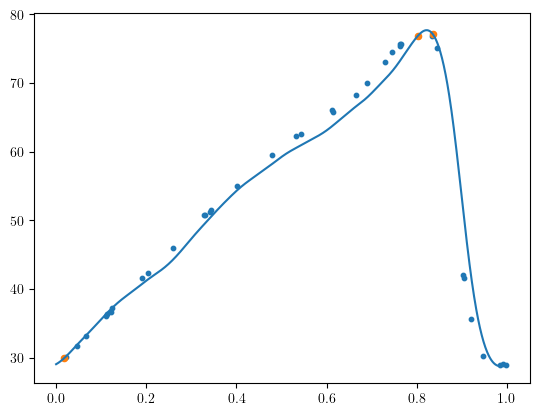

In [ ]:
selected_comb = 10
comb = _combinations[selected_comb]
temp_phase = phase[comb]
temp_rv = rv[comb]
temp_rv_err = rv_err[comb]
solu = result_list[selected_comb]

fig, axs = plt.subplots()
axs.scatter(phase, rv, s=10)
axs.scatter(temp_phase, temp_rv, s=20)
axs.plot(phase_grid, phased_pca_model.evaluate(solu.theta_free, x=phase_grid))


In [51]:
phased_pca_model.param_names

['c', 'pc1', 'pc2', 'pc3', 'pc4', 'pc5', 'pc6', 'delta_phi']

In [54]:
kde_comps.var_names

['log_P', 'pc1', 'pc2', 'pc3', 'pc4', 'pc5', 'pc6']

In [ ]:
# result_list = []

# for i, comb in enumerate(_combinations):
#     if i%5==0:
#         print(i)
#     temp_phase = phase[comb]
#     temp_rv = rv[comb]
#     temp_rv_err = rv_err[comb]

#     temp_mean_rv = np.mean(temp_rv)
#     bounds = [[temp_mean_rv - 35, temp_mean_rv + 35]]
#     for param_name in phased_pca_model.param_names:
#         if param_name in kde_comps.var_names:
#             bounds += [[*kde_comps.domain[param_name]]]
#     if has_phase_prior:
#         bounds += [[*kde_phot_phase.domain["DELTA_PHASE"]]]
#     else:
#         bounds += [[0, 1]]

#     result_de = vf.fit.differential_evolution_posterior(
#         compiled_model=phased_pca_model,
#         bounds=bounds,
#         x=temp_phase,
#         y=temp_rv,
#         yerr=temp_rv_err,
#         logprior=log_prior_target,
#         **kwargs_de,
#     )
#     result_list.append(result_de)

{'log_P': (0.19096037124893628, 1.6746025737838712),
 'DELTA_PHASE': (-0.002799820504393667, 0.43292409108118146)}

In [48]:
kde_comps.domain

{'log_P': (0.1622223686372001, 1.9907206025129691),
 'pc1': (-329.8660014521853, 360.530326080534),
 'pc2': (-130.74436957363193, 215.796088851239),
 'pc3': (-143.2556272956076, 151.24340123323634),
 'pc4': (-83.82667639023121, 78.97793501289725),
 'pc5': (-68.64464245869652, 74.65281829608094),
 'pc6': (-32.977333877579866, 32.7069340997721)}

In [ ]:
kde_components = {
    pc: vf.prior.KDEDensity(["log_P", pc], bw="cv_ml").fit(components_train_df)
    for pc in pc_names
}

# Photometric delta phase: 1D KDE over all bands and all training stars
train_names = set(components_train_df["NAME"])
phot_phase_train = photometric_delta_phase[
    photometric_delta_phase["NAME"].isin(train_names)
]
kde_phot_phase = vf.prior.KDEDensity(["log_P", "DELTA_PHASE"], bw="cv_ml").fit(
    phot_phase_train[phot_phase_train["BAND"] == "G"],
)

/Users/odysseus/projects/veloce-framework/.venv/lib/python3.14/site-packages/statsmodels/nonparametric/kernel_density.py:158: RuntimeWarning: invalid value encountered in log
  L += func(f_i)


In [46]:
def plot_2d_kde(  # noqa: PLR0913
    kde: vf.prior.KDEDensity,
    data: pd.DataFrame,
    ax: Axes | None = None,
    n_grid: int = 80,
    cmap: str = "Greys",
    scatter_kw: dict | None = None,
    test_data: pd.DataFrame | None = None,
    test_scatter_kw: dict | None = None,
) -> Axes:
    """Plot 2-D KDE density.

    Parameters
    ----------
    kde :
        A fitted 2-D ``KDEDensity``.
    data :
        Training data (must contain the KDE's variable columns).
    ax :
        Existing axes to draw on. A new figure is created if ``None``.
    n_grid :
        Grid resolution for the contour plot.
    cmap :
        Matplotlib colormap for the density contours.
    scatter_kw :
        Extra keyword arguments forwarded to the training-data scatter call.
    test_data :
        Optional held-out data to overlay with a different marker.
    test_scatter_kw :
        Extra keyword arguments for the test-data scatter call.

    Returns
    -------
    Axes

    Raises
    ------
    ValueError
        If the KDE does not have exactly 2 variables.

    """
    if len(kde.var_names) != 2:  # noqa: PLR2004
        msg = f"plot_2d_kde requires a 2-D kde, got {len(kde.var_names)} variables"
        logger.error(msg)
        raise ValueError(msg)

    x_var, y_var = kde.var_names

    if ax is None:
        _, ax = plt.subplots()

    _scatter_kw = {"s": 18, "marker": "o", "edgecolors": "k", "lw": 0.8, "zorder": 1}
    if scatter_kw:
        _scatter_kw.update(scatter_kw)
    x_train = data[x_var].to_numpy(dtype=float)
    y_train = data[y_var].to_numpy(dtype=float)
    valid = ~(np.isnan(x_train) | np.isnan(y_train))
    ax.scatter(x_train[valid], y_train[valid], **_scatter_kw)

    # ── Density contour ───────────────────────────────────────────────────────
    x_grid = np.linspace(*kde.domain[x_var], n_grid)
    y_grid = np.linspace(*kde.domain[y_var], n_grid)
    xg, yg = np.meshgrid(x_grid, y_grid, indexing="ij")
    rows = np.column_stack([xg.ravel(), yg.ravel()])
    pdf = kde._pdf_batch(rows).reshape(xg.shape)  # noqa: SLF001
    # pdf_norm = np.array([p / np.max(p) for p in pdf])  # noqa: ERA001
    pdf_norm = np.array([p / sp.integrate.simpson(p, y_grid) for p in pdf])
    pdf_norm = np.array([p - min(p) for p in pdf_norm])
    ax.contourf(
        xg,
        yg,
        pdf_norm,
        levels=25,
        cmap=cmap,
        zorder=0,
        alpha=1,
        vmin=0,
        norm=mpl.colors.PowerNorm(gamma=0.6),
    )
    # ── Test scatter (optional) ───────────────────────────────────────────────
    if test_data is not None:
        _test_kw = {"s": 25, "marker": "^", "edgecolors": "k", "lw": 0.8, "zorder": 3}
        if test_scatter_kw:
            _test_kw.update(test_scatter_kw)
        x_test = test_data[x_var].to_numpy(dtype=float)
        y_test = test_data[y_var].to_numpy(dtype=float)
        valid_test = ~(np.isnan(x_test) | np.isnan(y_test))
        ax.scatter(x_test[valid_test], y_test[valid_test], **_test_kw)

    return ax

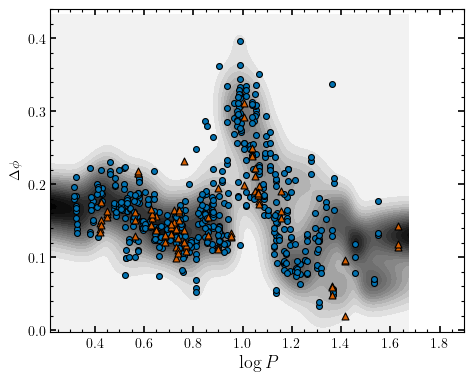

In [47]:
fig, axs = plt.subplots()
width = 3.46 * 1.4
height = width * 1.618 / 2
fig.set_size_inches(width, height)


axs = plot_2d_kde(
    kde_phot_phase,
    phot_phase_train,
    ax=axs,
    n_grid=300,
    cmap="Greys",
    scatter_kw={"c": color_safe["blue"]},
    test_data=photometric_delta_phase[
        photometric_delta_phase["NAME"].isin(set(components_test_df["NAME"]))
    ],
    test_scatter_kw={"c": color_safe["dark_orange"]},
)

# Set x-axis ticks and label
x_ticks = np.arange(0.2, 2, 0.2)
x_ticks_minor = np.arange(0.2, 2, 0.05)
xlims = [0.22, 1.9]
vf.plots_utils.format_xticks(axs, x_ticks, x_ticks_minor)
axs.set_xlim(*xlims)
axs.set_xlabel(r"$\log P$", fontsize=13)

# Set y-axis ticks and labels
y_ticks = np.arange(0, 0.5, 0.1)
y_ticks_minor = np.arange(0, 0.45, 0.02)
ylims = axs.get_ylim()
vf.plots_utils.format_yticks(axs, y_ticks, y_ticks_minor)
axs.set_ylabel(r"$\Delta\phi$", fontsize=10)

fig.tight_layout()

In [48]:
kde_phot_phase._kde.bw

array([0.04244245, 0.02220628])

In [49]:
kde_components["pc1"]._kde.bw

array([ 0.08660763, 31.90151529])

Plot KDE densities

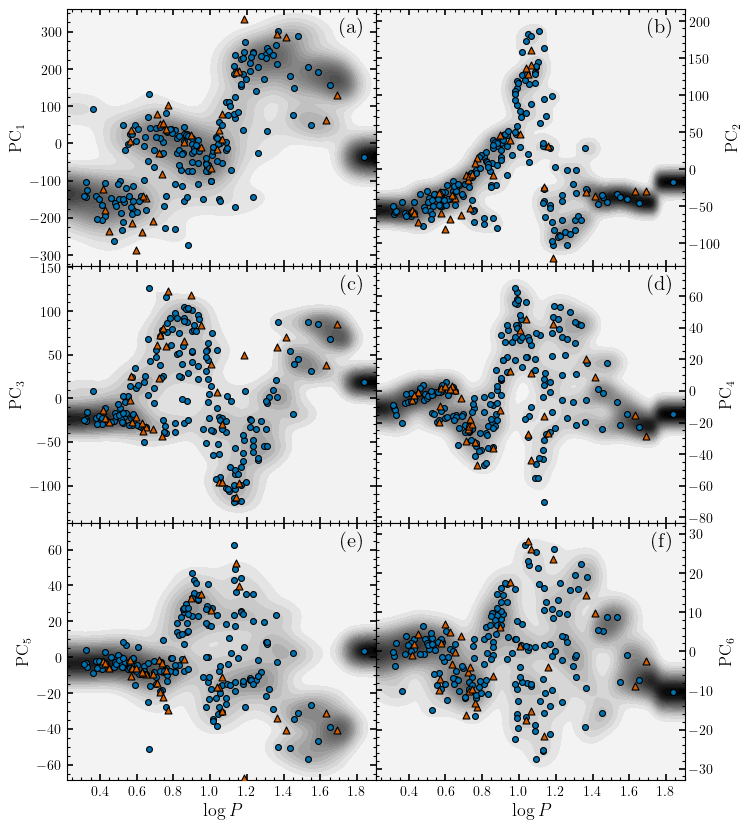

In [50]:
# Set the number of figures
n_rows = len(kde_components) // 2
n_rows += 1 if len(kde_components) % 2 == 1 else 0
fig, axs = plt.subplots(
    n_rows,
    2,
    sharex=True,
    gridspec_kw={"hspace": 0, "wspace": 0},
)
width = 3.46 * 2.2
height = width * 1.618 / 2 * n_rows / 2.2  # / 2
fig.set_size_inches(width, height)
x_ticks = np.arange(0.2, 2, 0.2)
x_ticks_minor = np.arange(0.2, 2, 0.05)
xlims = [0.22, 1.9]

# Color
panels = ["a", "b", "c", "d", "e", "f"]
kde_names = [f"pc{i}" for i in range(1, len(kde_components) + 1)]
scatter_kw = {"c": color_safe["blue"]}
test_scatter_kw = {"c": color_safe["dark_orange"]}

for i, kde_name in enumerate(kde_names):
    ax = axs.flat[i]
    ax.text(
        0.97,
        0.97,
        f"({panels[i]})",
        transform=ax.transAxes,
        fontsize=label_size + 4,
        ha="right",
        va="top",
    )

    kde = kde_components[kde_name]

    ax = plot_2d_kde(
        kde,
        components_train_df,
        ax=ax,
        n_grid=300,
        cmap="Greys",
        scatter_kw=scatter_kw,
        test_data=components_test_df,
        test_scatter_kw=test_scatter_kw,
    )

    # Set x-axis ticks and label
    vf.plots_utils.format_xticks(ax, x_ticks, x_ticks_minor)
    ax.set_xlim(*xlims)

    # Set y-axis ticks and labels
    if i % 2 == 1:
        ax.yaxis.set_label_position("right")
        ax.yaxis.tick_right()

    ylims = ax.get_ylim()
    if i == 0:
        y_ticks = np.arange(-500, 500, 100)
        y_ticks_minor = np.arange(-500, 500, 25)
    elif i in {1, 2}:
        y_ticks = np.arange(-200, 400, 50)
        y_ticks_minor = np.arange(-200, 400, 10)
    elif i in {3, 4}:
        y_ticks = np.arange(-200, 200, 20)
        y_ticks_minor = np.arange(-200, 200, 5)
    elif i == 5:  # noqa: PLR2004
        y_ticks = np.arange(-100, 100, 10)
        y_ticks_minor = np.arange(-100, 100, 2)
        ylim = (ylim[0], ylim[1] + 3)
    else:
        pass

    vf.plots_utils.format_yticks(ax, y_ticks, y_ticks_minor)
    ax.set_ylim(*ylims)
    ax.set_ylabel(r"$\rm{PC_" + str(i + 1) + "}$", fontsize=12)

if len(kde_components) % 2 == 1:
    fig.delaxes(axs[-1, -1])

axs[-1, -1].set_xlabel(r"$\log P$", fontsize=13)
axs[2, 0].set_xlabel(r"$\log P$", fontsize=13)
fig.tight_layout()
# fig.savefig(saving_directory / "kde_components.pdf", format="pdf")

## Fit Subsamples

In [ ]:
subsampling_dir = saving_dir / "subsampling_all"
subsampling_dir.mkdir(exist_ok=True)
subsampling_plots_dir = subsampling_dir / "plots"
subsampling_plots_dir.mkdir(exist_ok=True)
subsampling_results_dir = subsampling_dir / "results"
subsampling_results_dir.mkdir(exist_ok=True)

Define a model of the PCA components that allows also for a shift in phase of the input values.

In [52]:
phased_model = PhaseShiftLCPC(
    pca=pca,
    mean_training_sample=mean_training_sample.to_numpy(),
    name="shifted_puls",
)
phased_pca_model = vgamma_model + phased_model

In [53]:
# Functionalities to help find the best initial guess
def sample_from_spline(spline_density, n_samples, rng_):
    """Draw samples from a SplineDensity via inverse CDF."""
    grid = spline_density._grid
    log_pdf = spline_density._spline(grid)
    pdf = np.exp(log_pdf - log_pdf.max())  # shift for numerical stability
    # Trapezoidal CDF
    cdf = np.concatenate([[0.0], np.cumsum(np.diff(grid) * (pdf[:-1] + pdf[1:]) / 2)])
    cdf /= cdf[-1]
    u = rng_.uniform(0.0, 1.0, n_samples)
    return np.interp(u, cdf, grid)


def build_icdf(spline_density):
    """Pre-compute the CDF arrays once for fast inverse-CDF sampling."""
    grid = spline_density._grid
    pdf = np.exp(spline_density._spline(grid))
    pdf = np.clip(pdf, 0, None)
    cdf = np.concatenate([[0.0], np.cumsum(np.diff(grid) * (pdf[:-1] + pdf[1:]) / 2)])
    cdf /= cdf[-1]
    return cdf, grid  # store these, not the spline


def icdf_sample(cdf, grid, u):
    """Map u in [0,1] → sample value via inverse CDF."""
    return np.interp(u, cdf, grid)


def optimal_c(pc_delta, phase, rv, rv_err, model):
    """Exact MLE for c given fixed (pc, delta_phi) and data."""
    pulsation = model.evaluate(pc_delta, x=phase)
    w = 1.0 / rv_err**2
    return float(np.dot(w, rv - pulsation) / w.sum())

In [54]:
import warnings
from joblib import Parallel, delayed


def _fit_one(
    combination,
    phase,
    rv,
    rv_err,
    pc_delta_starts_ro,
    lprior_starts,
    K,
    model,
    log_prior_target,
    kwargs_map,
):
    temp_phase = phase[combination]
    temp_rv = rv[combination]
    temp_rv_err = rv_err[combination]

    starts = pc_delta_starts_ro.copy()  # local copy — safe to mutate
    starts[:, 0] = 0.0

    y_pred_pulsation = np.array([model.evaluate(pc, x=temp_phase) for pc in starts])
    w = 1.0 / temp_rv_err**2
    c_opts = np.array(
        [float(np.dot(w, temp_rv - yp) / w.sum()) for yp in y_pred_pulsation]
    )
    starts[:, 0] = c_opts

    y_pred_full = y_pred_pulsation + c_opts[:, np.newaxis]
    llike = -0.5 * np.sum(((temp_rv - y_pred_full) / temp_rv_err) ** 2, axis=1)
    lp_vals = lprior_starts + llike
    top_starts = starts[np.argsort(lp_vals)[-K:]]

    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", category=RuntimeWarning, module="scipy")
        map_results = [
            vf.fit.fit_map(
                model,
                x=temp_phase,
                y=temp_rv,
                yerr=temp_rv_err,
                theta_free_init=s,
                logprior=log_prior_target,
                **kwargs_map,
            )
            for s in top_starts
        ]

    successful = [r for r in map_results if r.success]
    if not successful:
        return None
    return max(successful, key=lambda r: r.extra["logposterior"])

In [55]:
def plot_resampling_result(
    name,
    real_delta_phase,
    result_map_list,
    phase,
    rv,
    rv_err,
    combinations,
    indices,
    prefix,
):
    temp_fit_rv = fit_rv_df[fit_rv_df["NAME"] == name]["LS_RESULT"].iloc[0]
    temp_fit_curve = fit_curve_df[fit_curve_df["NAME"] == name]["LS_RESULT"].iloc[0]
    width = 3.46 * 1.4
    height = width * 1.618 / 2

    fig, axs = plt.subplots(figsize=(width, height))
    shift_idx = np.argsort((temp_fit_curve.x - real_delta_phase) % 1)
    shift_idx_grid = np.argsort((phase_grid - real_delta_phase) % 1)

    axs.plot(
        temp_fit_curve.x,
        temp_fit_curve.y[shift_idx],
        "-",
        label="Veloce Model",
        color=color_safe["blue"],
    )
    axs.plot(
        phase_grid,
        temp_fit_rv.evaluate(phase_grid)[shift_idx_grid],
        label="PCA Fit All measures",
        color=color_safe["dark_orange"],
    )

    for idx in indices:
        result_map = result_map_list[idx]
        temp_phase = phase[combinations[idx]]
        temp_rv = rv[combinations[idx]]
        (plot_fit,) = axs.plot(
            phase_grid,
            result_map.evaluate(phase_grid),
            c=color_safe["light_green"],
            zorder=6,
            label="MAP fit",
        )
        errorbar_data = axs.errorbar(
            phase,
            rv,
            yerr=rv_err,
            fmt="o",
            markersize=2,
            c="k",
            zorder=5,
        )
        scatter_data = axs.scatter(
            temp_phase,
            temp_rv,
            edgecolors="k",
            s=25,
            c=color_safe["light_green"],
            zorder=7,
            label="Subsample",
        )
        axs.legend()
        axs.set_xlabel("Phase")
        axs.set_ylabel("RV [km/s]")
        axs.set_title(
            f"{name}: Resample {idx}/{len(combinations)} (n_rv = {len(temp_rv)})",
        )
        fig.tight_layout()
        name_file = subsampling_plots_dir / f"n_rv{len(temp_rv):.0f}"
        name_file.mkdir(exist_ok=True)
        name_file /= (
            prefix
            + name.replace(" ", "_")
            + f"_n_rv{len(temp_rv):.0f}_subsample{idx:.0f}.pdf"
        )
        fig.savefig(name_file, format="pdf")
        plot_fit.remove()
        errorbar_data.remove()
        scatter_data.remove()
    plt.close(fig)

In [ ]:
rng_init = np.random.default_rng(54)
mapping_variables_model = phased_pca_model.layout.name_to_index
# Subsamples
n_subsample = [3]  # , 4, 5, 6, 7, 10, 15, 20]  # [3, 4, 5, 6, 7, 10, 15, 20]
n_points_to_map = {
    3: 30,
    4: 20,
    5: 10,
    6: 10,
    7: 5,
    10: 5,
}
n_resamples_default = 100  # 100
read_from_saved_subsampling = True


kwargs_map = {
    "method": "Powell",
    "tol": 1e-3,
    "options": {"maxiter": 5000},
}
kwargs_de = {
    "strategy": "rand1bin",
    "maxiter": 3000,  # DE just needs to find the basin
    "popsize": 10,  # population = 10 * 8 = 80 individuals
    "tol": 0.01,  # looser: stop when population has 1% relative spread
    "polish": False,  # skip DE's internal L-BFGS-B step — fit_map does this
}


specific_combinations = {}
break_cases = []
if (subsampling_dir / "specific_combinations.pkl").exists():
    with Path.open(subsampling_dir / "specific_combinations.pkl", "rb") as f:
        specific_combinations.update(pkl.load(f))  # noqa: S301
if (subsampling_dir / "break_cases.pkl").exists():
    with Path.open(subsampling_dir / "break_cases.pkl", "rb") as f:
        break_cases = pkl.load(f)  # noqa: S301


# for i, header in veloce_headers.iterrows():
for i, row in fit_rv_no_outliers.iterrows():
    header = veloce_headers[veloce_headers.NAME == row.NAME].iloc[0]
    # ----------------------------------------------------------------------------------
    # Get header info and photometric epoch
    # Using Gaia period is much more complicated since the
    name = header.NAME
    if i > 10 and name != "WW Mon":
        continue

    save_name = name.replace(" ", "_")
    print(f"{i}/ {len(veloce_headers)} - {name}")

    source_id = int(header.GAIA_DR3_SOURCE_ID)
    period = header.P
    log_p = np.log10(period)
    group = header.SET
    prefix = group + "_"
    has_gaia_epoch = True
    if source_id in df_gaiadr3_selection["source_id"].to_numpy():
        gaia_data = df_gaiadr3_selection[df_gaiadr3_selection["source_id"] == source_id]
        epoch_g = gaia_data["epoch_g"].to_numpy()[0] + epoch_offset_gaiadr3
    else:
        has_gaia_epoch = False
        epoch_g = epoch_offset_gaiadr3
        prefix += "NoGaia_"

    real_delta_phase = (
        (epoch_g - (header.E + epoch_offset_veloce)) / period + 0.5
    ) % 1 - 0.5

    # ----------------------------------------------------------------------------------
    # Get VELOCE observations and model
    target_data = veloce_data[(veloce_data["NAME"] == name) & (veloce_data["MASK"])]
    bjd, rv, rv_err = (
        target_data["BJD"].to_numpy().copy(),
        target_data["RV"].to_numpy().copy(),
        target_data["RV_ERR"].to_numpy().copy(),
    )
    # Remove trend
    target_veloce_fit = veloce_fit[veloce_fit["NAME"] == name].iloc[0]
    if isinstance(target_veloce_fit["POLY_COEFFS"], np.ndarray):
        trend_model = vf.model.PolynomialBasis(int(header["POLYDEG"]))
        trend = trend_model.evaluate(
            target_veloce_fit["POLY_COEFFS"],
            bjd - header["E"],
        )
        rv -= trend

    # ----------------------------------------------------------------------------------
    # Calculate phase use Gaia period and epoch (photometric data)
    phase = vf.model.calculate_phase(bjd, period, epoch_g - epoch_offset_veloce)

    # ----------------------------------------------------------------------------------
    # Create Priors
    priors = []
    # One conditional prior per PC, conditioned on this star's log_P
    for pc in phased_pca_model.param_names:
        if pc not in kde_components:
            continue
        cond = kde_components[pc].conditional(log_P=log_p)
        fast = vf.prior.SplineDensity(cond)
        priors.append(vf.prior.ParameterPrior(fast, mapping_variables_model))

    # One conditional prior on the phase
    has_phase_prior = True
    if log_p < kde_phot_phase.domain["log_P"][1] and has_gaia_epoch:
        cond_phase = kde_phot_phase.conditional(log_P=log_p)
        fast_phase = vf.prior.SplineDensity(cond_phase)
    else:
        has_phase_prior = False
        fast_phase = vf.prior.UniformDensity("DELTA_PHASE", 0.0, 1.0)
        print(f"{name}: No Phase prior")  # noqa: T201
        prefix += "NoPhiPrior_"

    idx = mapping_variables_model["delta_phi"]
    priors.append(vf.prior.ParameterPrior(fast_phase, {"DELTA_PHASE": idx}))
    log_prior_target = vf.prior.CombinedLogPrior(priors)

    # Determine a grid of tentative PC components coefficients based on priors
    n_prior_grid = 300
    n_prior_dims = len(priors)
    pc_priors = priors[:-1]
    icdf_pc = [build_icdf(p._density) for p in pc_priors]  # noqa: SLF001
    #  Latin Hypercube Sampling (LHS) (N, n_prior_dims)
    lhs_u = sp.stats.qmc.LatinHypercube(d=n_prior_dims, seed=42).random(n_prior_grid)
    # Map each LHS column through its prior's inverse CDF
    pc_cols = [icdf_sample(cdf, g, lhs_u[:, k]) for k, (cdf, g) in enumerate(icdf_pc)]

    # Add prior due to phase
    if has_phase_prior:
        dphi_col = icdf_sample(*build_icdf(priors[-1]._density), lhs_u[:, -1])  # noqa: SLF001
    else:
        dphi_col = lhs_u[:, -1]

    pc_delta_starts = np.column_stack([*pc_cols, dphi_col])  # (N, n_pcs+1)

    # insert zeros for vgamma and calculate log_prior
    pc_delta_starts = np.column_stack((np.zeros(len(pc_delta_starts)), pc_delta_starts))
    lprior_starts = np.array([log_prior_target(theta) for theta in pc_delta_starts])
    # ----------------------------------------------------------------------------------
    # Subsample
    for n_rv in n_subsample:
        K = n_points_to_map.get(n_rv, 5)
        print(f"\t - n_rv = {n_rv} (K = {K}) ->", end="")
        if len(rv) <= n_rv + 2:
            msg = f"{name}: Not enough data points to subsample {n_rv} points."
            msg += f" Only {len(rv)} points available. Skipping."
            logger.info(msg)
            continue

        n_combinations = math.comb(len(rv), n_rv)
        if n_combinations < 10000:  # noqa: PLR2004
            # Get all combinations
            _combinations = np.array(list(itertools.combinations(range(len(rv)), n_rv)))
        else:
            # Get random combinations
            _combinations = np.array(
                [
                    rng_init.choice(len(rv), n_rv, replace=False)
                    for _ in range(n_resamples_default)
                ],
            )

        if len(_combinations) > n_resamples_default:
            # Get random combinations but sure they are unique
            _combinations = _combinations[
                rng_init.choice(len(_combinations), n_resamples_default, replace=False)
            ]
        if len(_combinations) < n_resamples_default:
            # Save the combinations
            msg = f"{name}: {n_combinations} combinations for {n_rv} points."
            logger.info(msg)
            if name in specific_combinations:
                specific_combinations[name].update({f"nrv_{n_rv}": n_combinations})
            else:
                specific_combinations[name] = {}
                specific_combinations[name][f"nrv_{n_rv}"] = n_combinations

        n_resamples = len(_combinations)

        # Check if already exists
        subsampling_nrv_dir = subsampling_results_dir / f"n_rv{n_rv:.0f}"
        subsampling_nrv_dir.mkdir(exist_ok=True)
        name_file = prefix + save_name
        name_file += f"_n_rv{n_rv:.0f}_times{n_resamples:.0f}"

        if read_from_saved_subsampling:
            pickle_file = subsampling_nrv_dir / (name_file + ".pkl")
            if pickle_file.exists():
                with Path.open(pickle_file, "rb") as f:
                    subsample_results = pkl.load(f)  # noqa: S301
                if len(subsample_results["selections"]) == n_resamples:
                    print(" loaded from file-ok")
                    msg = f"Subsample {n_rv} loaded for {name}."
                    logger.debug(msg)
                    continue
                else:
                    print(" different number of resamples - recalculating ->", end="")

        # ***************** PARALLEL MAGIC *********************************************
        pc_delta_starts_ro = pc_delta_starts.copy()  # snapshot before the loop

        result_map_list = Parallel(n_jobs=-1, backend="loky")(
            delayed(_fit_one)(
                comb,
                phase,
                rv,
                rv_err,
                pc_delta_starts_ro,
                lprior_starts,
                K,
                phased_pca_model,
                log_prior_target,
                kwargs_map,
            )
            for comb in _combinations
        )
        result_map_list = [r for r in result_map_list if r is not None]

        print(f" calculations({len(_combinations)})-ok", end="")

        plot_resampling_result(
            name,
            real_delta_phase=real_delta_phase,
            result_map_list=result_map_list,
            phase=phase,
            rv=rv,
            rv_err=rv_err,
            combinations=_combinations,
            indices=np.arange(len(_combinations))[::10],
            prefix=prefix,
        )
        print(" plots-ok")

        subsample_results = {
            "target": name,
            "P": period,
            "log_P": log_p,
            "epoch_g": epoch_g,
            "n_rv": n_rv,
            "n_resamples": n_resamples,
            "selections": _combinations,
            "rv": rv,
            "rv_err": rv_err,
            "bjd": bjd,
            "phase": phase,
            "real_delta_phi": real_delta_phase,
            "result_map": result_map_list,
        }

        subsampling_nrv_dir = subsampling_results_dir / f"n_rv{n_rv:.0f}"
        subsampling_nrv_dir.mkdir(exist_ok=True)
        name_file = prefix + save_name
        name_file += f"_n_rv{n_rv:.0f}_times{n_resamples:.0f}"

        pickle_file = subsampling_nrv_dir / (name_file + ".pkl")
        # Save the results
        with Path.open(pickle_file, "wb") as f:
            pkl.dump(subsample_results, f)

with Path.open(subsampling_dir / "specific_combinations.pkl", "wb") as f:
    pkl.dump(specific_combinations, f)
with Path.open(subsampling_dir / "break_cases.pkl", "wb") as f:
    pkl.dump(break_cases, f)

0/ 219 - AA Gem
	 - n_rv = 3 (K = 30) ->

 calculations(100)-ok plots-ok
1/ 219 - AB Cam
	 - n_rv = 3 (K = 30) -> calculations(100)-ok plots-ok
2/ 219 - AC Mon
	 - n_rv = 3 (K = 30) -> calculations(100)-ok plots-ok
3/ 219 - AD Pup
	 - n_rv = 3 (K = 30) -> calculations(100)-ok plots-ok
4/ 219 - AH Vel
	 - n_rv = 3 (K = 30) -> calculations(100)-ok plots-ok
5/ 219 - AK Cep
	 - n_rv = 3 (K = 30) -> calculations(100)-ok plots-ok
6/ 219 - AN Aur
	 - n_rv = 3 (K = 30) -> calculations(100)-ok plots-ok
7/ 219 - AO CMa
	 - n_rv = 3 (K = 30) -> calculations(100)-ok plots-ok
8/ 219 - AQ Car
	 - n_rv = 3 (K = 30) -> calculations(100)-ok plots-ok
9/ 219 - AQ Pup
	 - n_rv = 3 (K = 30) -> calculations(100)-ok plots-ok
10/ 219 - AS Vul
	 - n_rv = 3 (K = 30) -> calculations(100)-ok plots-ok
193/ 219 - WW Mon
	 - n_rv = 3 (K = 30) -> calculations(100)-ok plots-ok


### Fit from a fixed phase

  WW Mon n_rv=3 (100 resamples) ...0 post- -18.14 -> -17.88
0 - -2.0072 --> -1.9677
1 post- -23.01 -> -23.16
1 - 1.0820 --> 1.1295
2 post- -22.22 -> -22.31
2 - -0.7718 --> -0.9040
3 post- -22.95 -> -22.67
3 - -3.0587 --> -2.1230
4 post- -22.78 -> -22.78
4 - -0.7585 --> -1.0590
5 post- -17.60 -> -17.66
5 - 1.1125 --> 0.4457
6 post- -22.18 -> -22.42
6 - 1.0318 --> 1.1519
7 post- -20.33 -> -20.42
7 - -0.8254 --> -0.9472
8 post- -21.83 -> -21.86
8 - 0.7956 --> 0.8617
9 post- -21.28 -> -20.95
9 - 1.0657 --> 1.0821
10 post- -19.92 -> -19.92
10 - -1.8514 --> -2.0649
11 post- -22.90 -> -22.21
11 - -1.6396 --> -1.5589
12 post- -22.87 -> -23.07
12 - -0.9876 --> -1.0409
13 post- -20.98 -> -21.00
13 - -0.8091 --> -0.8532
14 post- -18.56 -> -18.57
14 - -2.0819 --> -2.1342
15 post- -19.56 -> -19.65
15 - -0.1855 --> -0.1954
16 post- -18.46 -> -18.45
16 - -2.6181 --> -2.4282
17 post- -23.03 -> -23.17
17 - 0.2117 --> 0.1894
18 post- -18.49 -> -17.81
18 - -1.7397 --> -2.0081
19 post- -22.82 -> -22.54
19

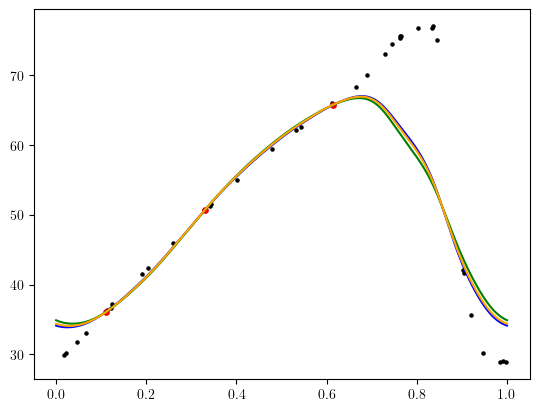

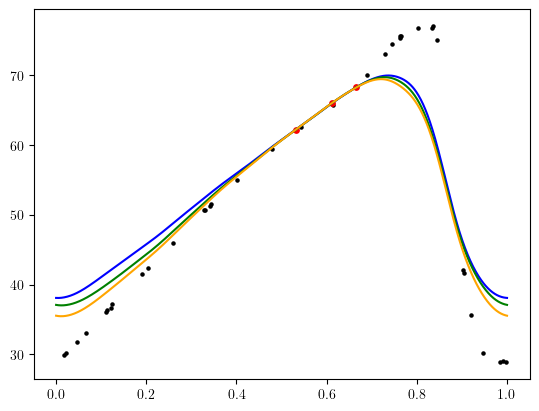

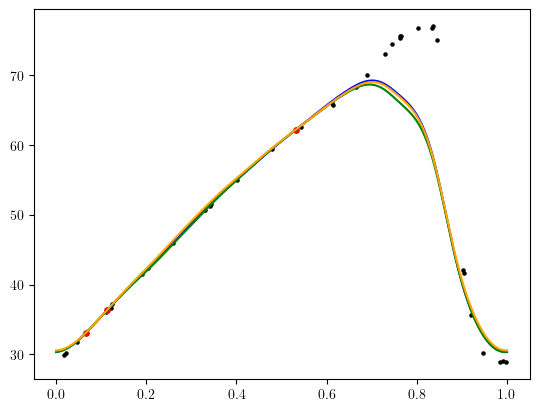

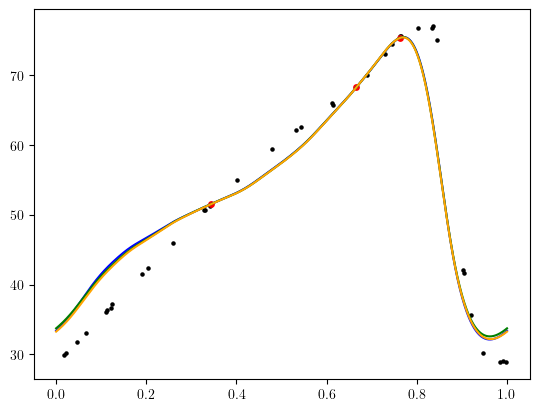

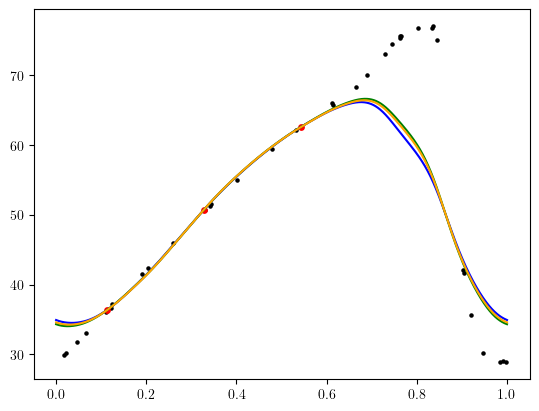

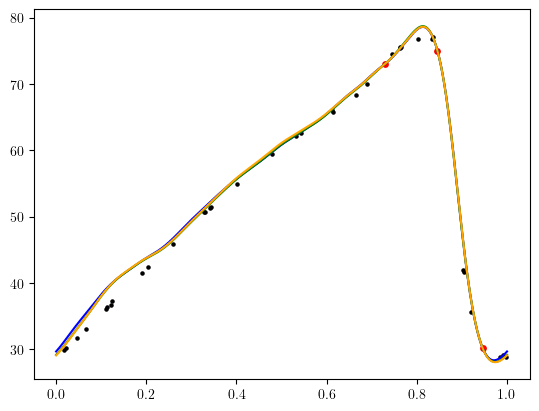

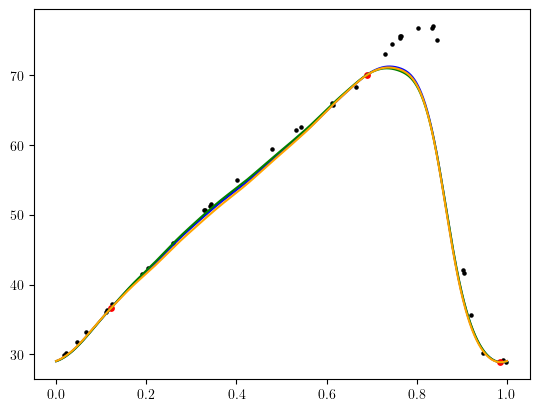

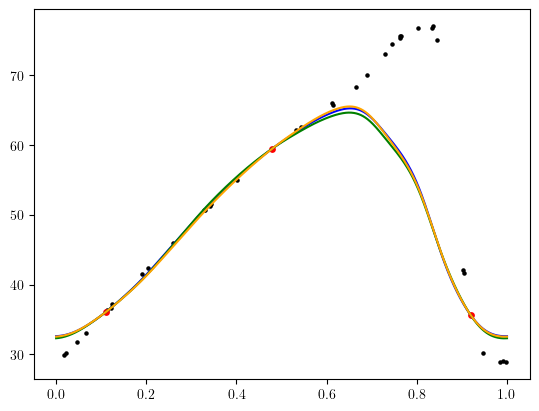

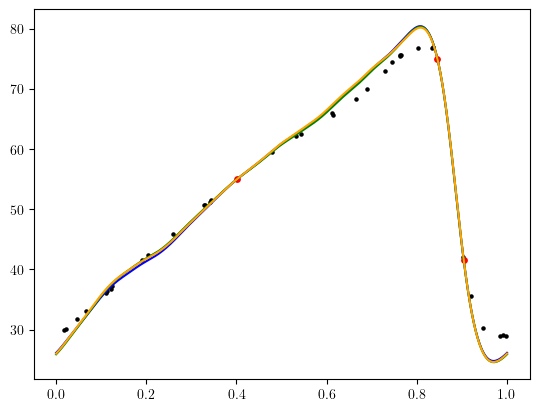

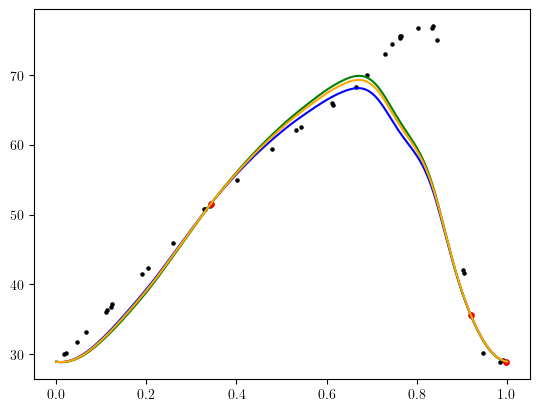

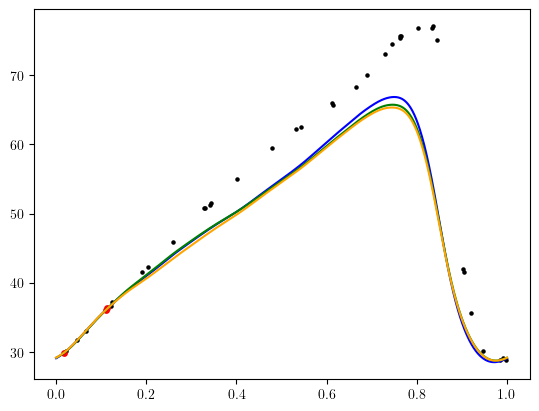

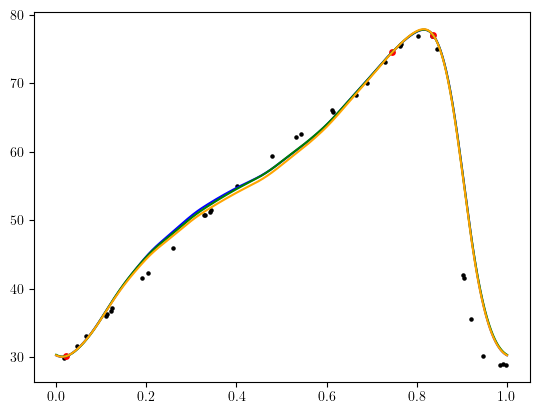

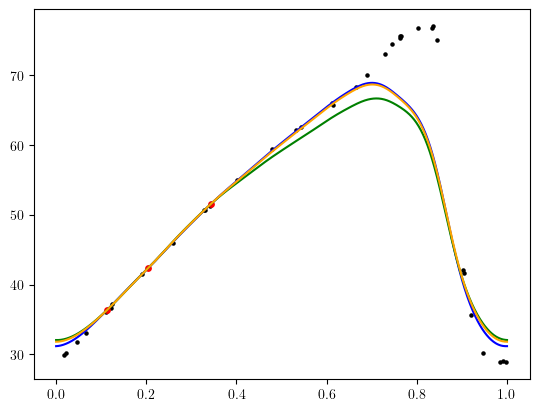

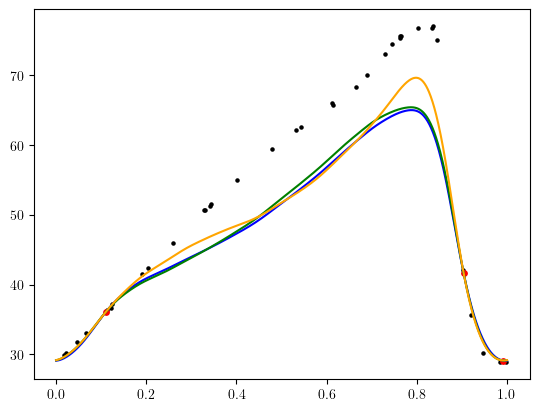

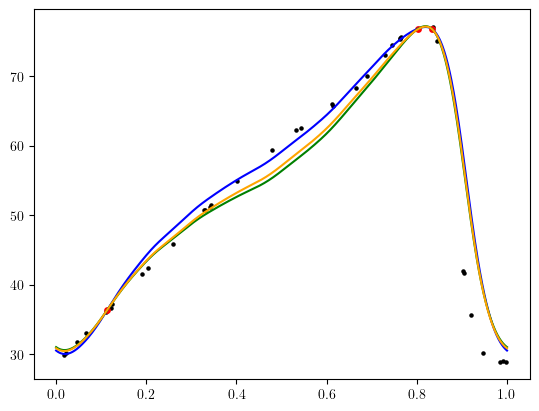

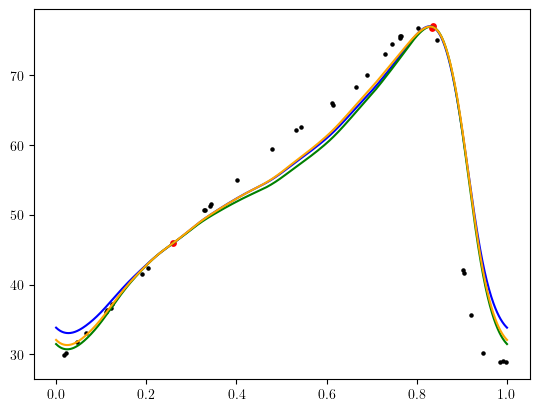

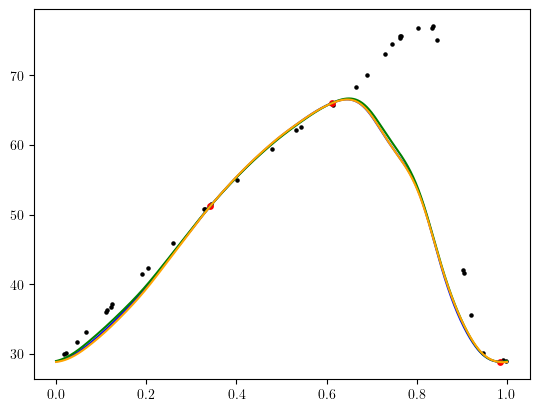

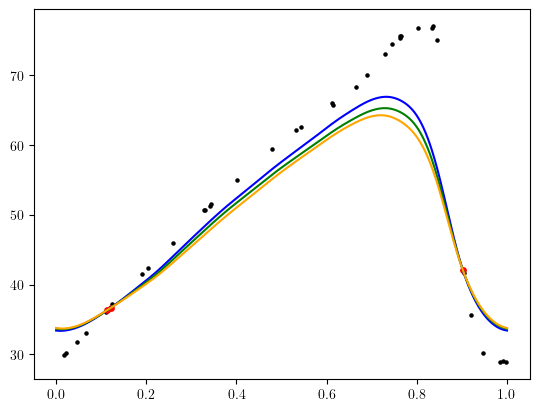

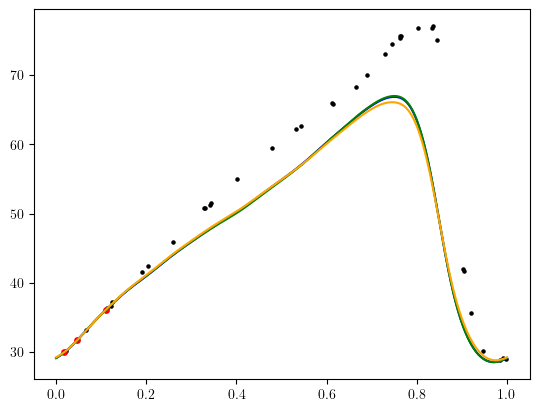

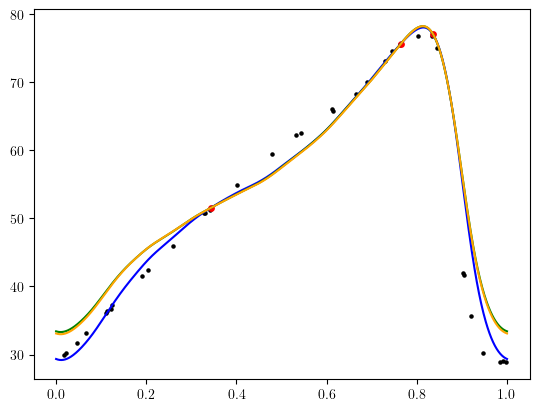

In [ ]:
phi_index = mapping_variables_model["delta_phi"]

subsampling_results_s2_dir = subsampling_dir / "results_stage2"
subsampling_results_s2_dir.mkdir(exist_ok=True)

warnings.filterwarnings("ignore", category=RuntimeWarning, module="scipy")

for n_rv in [3]:  # n_subsample:
    n_rv_dir = subsampling_results_dir / f"n_rv{n_rv:.0f}"
    n_rv_dir_s2 = subsampling_results_s2_dir / f"n_rv{n_rv:.0f}"
    n_rv_dir_s2.mkdir(exist_ok=True)
    for filepath in sorted(n_rv_dir.glob("*.pkl")):
        out_path = n_rv_dir_s2 / filepath.name
        if out_path.exists():
            print(f"  {filepath.stem} n_rv={n_rv} — skipped")
            continue

        with Path.open(filepath, "rb") as f:
            data = pkl.load(f)

        name = data["target"]
        if name != "WW Mon":
            continue
        log_p = data["log_P"]
        phase = data["phase"]
        rv = data["rv"]
        rv_err = data["rv_err"]
        print(f"  {name} n_rv={n_rv} ({len(data['result_map'])} resamples) ...", end="")

        # Re-build per-star PC priors (same as main loop, no phase prior)
        pc_priors = []
        for pc in phased_pca_model.param_names:
            if pc not in kde_components:
                continue
            cond = kde_components[pc].conditional(log_P=log_p)
            pc_priors.append(
                vf.prior.ParameterPrior(
                    vf.prior.SplineDensity(cond),
                    mapping_variables_model,
                ),
            )
        log_prior_fixed = vf.prior.CombinedLogPrior(pc_priors)

        # Determine a grid of tentative PC components coefficients based on priors
        n_prior_grid = 300
        n_prior_dims = len(priors)
        icdf_pc = [build_icdf(p._density) for p in pc_priors]  # noqa: SLF001
        #  Latin Hypercube Sampling (LHS) (N, n_prior_dims)
        lhs_u = sp.stats.qmc.LatinHypercube(d=n_prior_dims, seed=42).random(
            n_prior_grid,
        )
        # Map each LHS column through its prior's inverse CDF
        pc_delta_starts = np.column_stack(
            [icdf_sample(cdf, g, lhs_u[:, k]) for k, (cdf, g) in enumerate(icdf_pc)],
        )

        # insert zeros for vgamma and calculate log_prior
        pc_delta_starts = np.column_stack(
            (np.zeros(len(pc_delta_starts)), pc_delta_starts),
        )
        lprior_starts = np.array([log_prior_fixed(theta) for theta in pc_delta_starts])

        header_row = veloce_headers[veloce_headers["NAME"] == name].iloc[0]
        fit_row = veloce_fit[veloce_fit["NAME"] == name].iloc[0]
        veloce_vgamma = float(fit_row["VGAMMA"])
        veloce_p2p = float(header_row["PEAK2PEAK"])

        result_map_s2 = []
        result_de_list = []
        K = 10
        for i, (combination, result_s1) in enumerate(
            zip(
                data["selections"],
                data["result_map"],
                strict=True,
            )
        ):
            temp_phase = phase[combination]
            temp_rv = rv[combination]
            temp_rv_err = rv_err[combination]

            delta_phi = float(result_s1.theta_free[phi_index])

            fixed_param = vf.model.Parametrization.with_fixed(
                full_ndim=phased_pca_model.n_params,
                fixed_index=phi_index,
                fixed_value=delta_phi,
            )
            model_fixed = vf.model.compile_model(phased_pca_model, fixed_param)

            starts = pc_delta_starts.copy()
            starts[:, 0] = 0.0

            y_pred_pulsation = np.array(
                [model_fixed(pc, x=temp_phase) for pc in starts],
            )
            w = 1.0 / temp_rv_err**2
            c_opts = np.array(
                [float(np.dot(w, temp_rv - yp) / w.sum()) for yp in y_pred_pulsation]
            )
            starts[:, 0] = c_opts

            y_pred_full = y_pred_pulsation + c_opts[:, np.newaxis]
            llike = -0.5 * np.sum(((temp_rv - y_pred_full) / temp_rv_err) ** 2, axis=1)
            lp_vals = lprior_starts + llike
            top_starts = starts[np.argsort(lp_vals)[-K:]]

            with warnings.catch_warnings():
                warnings.filterwarnings(
                    "ignore", category=RuntimeWarning, module="scipy"
                )
                map_results_2 = [
                    vf.fit.fit_map(
                        model_fixed,
                        x=temp_phase,
                        y=temp_rv,
                        yerr=temp_rv_err,
                        theta_free_init=s,
                        logprior=log_prior_fixed,
                        **kwargs_map,
                    )
                    for s in top_starts
                ]

            successful = [r for r in map_results_2 if r.success]
            result_s2 = max(successful, key=lambda r: r.extra["logposterior"])
            result_map_s2.append(result_s2)

            static_bounds_suffix = []
            for jj in range(1, n_components + 1):
                static_bounds_suffix.append(
                    [*kde_components[f"pc{jj}"].domain[f"pc{jj}"]]
                )
            temp_mean_rv = np.mean(temp_rv)
            bounds = [[temp_mean_rv - 35, temp_mean_rv + 35]] + static_bounds_suffix

            result_de = vf.fit.differential_evolution_posterior(
                compiled_model=model_fixed,
                bounds=bounds,
                x=temp_phase,
                y=temp_rv,
                yerr=temp_rv_err,
                logprior=log_prior_fixed,
                **kwargs_de,
            )
            print(
                f"{i} post- {result_s2.extra['logposterior']:.2f} -> {result_de.extra['logposterior']:.2f}"
            )
            print(
                f"{i} - {result_s1.theta_free[0] - veloce_vgamma:.4f} --> {result_s2.theta_free[0] - veloce_vgamma:.4f}"
            )

            if i % 5 == 0:
                fig, axs = plt.subplots()
                axs.scatter(phase, rv, s=5, c="k")
                axs.scatter(temp_phase, temp_rv, s=15, c="red")
                axs.plot(
                    phase_grid,
                    phased_pca_model.evaluate(result_s1.theta_free, x=phase_grid),
                    c="blue",
                )
                axs.plot(
                    phase_grid,
                    model_fixed(result_s2.theta_free, x=phase_grid),
                    c="green",
                )
                axs.plot(
                    phase_grid,
                    model_fixed(result_de.theta_free, x=phase_grid),
                    c="orange",
                )

            # result_s2 = vf.fit.fit_map(
            #     compiled_model=model_fixed,
            #     x=temp_phase,
            #     y=temp_rv,
            #     yerr=temp_rv_err,
            #     theta_free_init=np.delete(result_s1.theta_free, phi_index),
            #     logprior=log_prior_fixed,
            #     **kwargs_map,
            # )
            # result_map_s2.append(result_s2 if result_s2.success else result_s1)

        with Path.open(out_path, "wb") as f:
            pkl.dump({**data, "result_map_s2": result_map_s2}, f)
        print(" ok")


In [103]:
for n_rv in [3]:  # n_subsample:
    n_rv_dir = subsampling_results_dir / f"n_rv{n_rv:.0f}"
    n_rv_dir_s2 = subsampling_results_s2_dir / f"n_rv{n_rv:.0f}"
    n_rv_dir_s2.mkdir(exist_ok=True)
    for filepath in sorted(n_rv_dir.glob("*.pkl")):
        out_path = n_rv_dir_s2 / filepath.name
        # if out_path.exists():
        #     print(f"  {filepath.stem} n_rv={n_rv} — skipped")
        #     continue

        with Path.open(filepath, "rb") as f:
            data = pkl.load(f)

        name = data["target"]
        if name != "WW Mon":
            continue

        example_coeff = []
        for res in data["result_map"]:
            example_coeff.append(
                {
                    "log_P": data["log_P"],
                    "c": res.theta_free[0],
                    "pc1": res.theta_free[1],
                    "pc2": res.theta_free[2],
                    "pc3": res.theta_free[3],
                    "pc4": res.theta_free[4],
                    "pc5": res.theta_free[5],
                    "pc6": res.theta_free[6],
                    "DELTA_PHASE": res.theta_free[-1],
                }
            )
        example_coeff = pd.DataFrame(example_coeff)
        print(data)

{'target': 'WW Mon', 'P': np.float64(4.662160162984286), 'log_P': np.float64(0.6685871891128027), 'epoch_g': np.float64(2456902.8943508123), 'n_rv': 3, 'n_resamples': 100, 'selections': array([[11, 17, 28],
       [ 8, 19, 32],
       [27, 28, 30],
       [ 0,  5, 28],
       [10, 30, 36],
       [ 1, 11, 27],
       [15, 32, 36],
       [ 0,  7, 35],
       [ 7, 18, 23],
       [ 4, 23, 38],
       [13, 16, 37],
       [ 1, 20, 26],
       [ 8, 10, 38],
       [ 2, 13, 27],
       [ 0, 13, 31],
       [ 1,  5, 37],
       [13, 19, 32],
       [14, 30, 34],
       [ 5, 17, 18],
       [ 3, 12, 13],
       [17, 29, 31],
       [ 9, 14, 38],
       [21, 26, 29],
       [ 9, 13, 15],
       [ 7, 13, 25],
       [22, 32, 34],
       [ 4,  8, 36],
       [12, 20, 23],
       [ 8, 21, 24],
       [ 1, 21, 31],
       [16, 18, 26],
       [ 5, 25, 29],
       [ 7,  8, 15],
       [18, 23, 24],
       [14, 29, 37],
       [ 1, 12, 31],
       [ 1, 14, 26],
       [14, 16, 31],
       [ 1,  3, 

In [96]:
veloce_headers[veloce_headers.NAME == "WW Mon"].P

193    4.66216
Name: P, dtype: float64

In [ ]:
example_target = "WW Mon"
example_coeff

,log_P,c,pc1,pc2,pc3,pc4,pc5,pc6,DELTA_PHASE
0,0.668587,60.002858,-62.477272,-27.658590,100.347084,-10.308883,-5.943684,-6.682617,0.100582
1,0.668587,49.222858,67.690077,-43.952220,-27.558189,-14.621451,-2.820430,-7.231220,0.157088
2,0.668587,56.812582,-42.303781,-8.944047,89.638363,-18.989609,-10.177160,-6.364735,0.135780
3,0.668587,50.465109,97.657438,-23.486203,19.763800,-9.142191,-1.753234,-4.375878,0.135839
4,0.668587,53.947529,94.719500,-6.631841,110.530981,-31.965564,-5.291508,-0.494592,0.090480
...,...,...,...,...,...,...,...,...,...
95,0.668587,47.032313,-16.226625,-47.993231,91.893009,0.315135,-10.834324,1.328765,0.110789
96,0.668587,51.619557,11.521616,-22.188058,-10.158096,-9.763221,-6.623825,-1.934037,0.149307
97,0.668587,56.014286,69.437079,-67.919470,151.243401,-19.401839,-61.457235,-2.734390,0.120333
98,0.668587,49.667933,76.613896,-44.209510,-5.884463,-18.978267,-3.422141,-4.514516,0.153527


In [86]:
components_df[components_df["NAME"] == example_target]

,NAME,SET,log_P,v_gamma,pc1,pc2,pc3,pc4,pc5,pc6
193,WW Mon,train,0.668587,53.000685,133.176169,-20.283773,126.701816,-34.488045,-51.302917,-7.313447


In [58]:
def _prep(phases: np.ndarray) -> np.ndarray:
    """Wrap to [0, 1), sort, and return as float array."""
    phi = np.mod(np.asarray(phases, dtype=float), 1.0)
    return np.sort(phi)


def mean_resultant_length(phases: np.ndarray) -> float:
    """Mean resultant length R in [0, 1].

    R ~ 1  -> phases tightly clustered (poor coverage)
    R ~ 0  -> phases balanced around the circle (good coverage)

    Circular variance is simply 1 - R.
    """
    theta = 2.0 * np.pi * np.mod(np.asarray(phases, dtype=float), 1.0)
    C = np.mean(np.cos(theta))
    S = np.mean(np.sin(theta))
    return np.hypot(C, S)


def circular_variance(phases: np.ndarray) -> float:
    """Circular variance V = 1 - R, in [0, 1]. Larger = better coverage."""
    return 1.0 - mean_resultant_length(phases)


def arc_gaps(phases: np.ndarray) -> np.ndarray:
    """Calculate gaps between phases.

    Sorted arc gaps between consecutive phases on the circle (wrapping).
    Returns an array of N gaps that sum to 1. For N uniform points each
    gap is 1/N.
    """
    phi = _prep(phases)
    n = phi.size
    if n == 0:
        return np.array([])
    if n == 1:
        return np.array([1.0])
    gaps = np.diff(phi)
    wrap = (phi[0] + 1.0) - phi[-1]  # gap across phi = 1 / phi = 0 boundary
    return np.concatenate([gaps, [wrap]])


def max_gap(phases: np.ndarray) -> float:
    """Largest unsampled arc, in units of the full cycle (0 to 1).

    Directly measures the worst hole in phase coverage. A sample confined
    to e.g. the ascending branch yields max_gap close to 1. Small max_gap
    guarantees no part of the curve is left unconstrained.
    """
    g = arc_gaps(phases)
    return float(np.max(g)) if g.size else 1.0

In [59]:
records = []
for n_rv in n_subsample:
    n_rv_dir = subsampling_results_s2_dir / f"n_rv{n_rv:.0f}"
    if not n_rv_dir.exists():
        continue
    for filepath in sorted(n_rv_dir.glob("*.pkl")):
        with Path.open(filepath, "rb") as f:
            data = pkl.load(f)

        name = data["target"]
        header_row = veloce_headers[veloce_headers["NAME"] == name].iloc[0]
        fit_row = veloce_fit[veloce_fit["NAME"] == name].iloc[0]
        veloce_vgamma = float(fit_row["VGAMMA"])
        veloce_p2p = float(header_row["PEAK2PEAK"])
        veloce_pulsation = dataset[dataset["NAME"] == name].iloc[0]["SAMPLE"]

        for i_resample, result in enumerate(data["result_map"]):
            # pulsation in VELOCE phase convention (no phase shift) — fastest formula
            map_pulsation = (
                phased_model.removed_mean
                + np.dot(
                    phased_model._components_T,  # noqa: SLF001
                    result.theta_free[1:-1],
                )
            )
            delta_vgamma = float(result.theta_free[0]) - veloce_vgamma
            delta_p2p = np.ptp(map_pulsation) - veloce_p2p
            rmse = float(np.sqrt(np.mean((map_pulsation - veloce_pulsation) ** 2)))

            # Calculate the phase coverage
            phases = data["phase"][data["selections"][i_resample]]
            R = mean_resultant_length(phases)
            arc_gaps_val = arc_gaps(phases)
            max_gap_val = max_gap(phases)

            # result S2
            result_s2 = data["result_map_s2"][i_resample]
            map_pulsation_s2 = (
                phased_model.removed_mean
                + np.dot(
                    phased_model._components_T,  # noqa: SLF001
                    result_s2.theta_full[1:-1],
                )
            )
            delta_vgamma_s2 = float(result_s2.theta_full[0]) - veloce_vgamma
            delta_p2p_s2 = np.ptp(map_pulsation_s2) - veloce_p2p
            rmse_s2 = float(
                np.sqrt(np.mean((map_pulsation_s2 - veloce_pulsation) ** 2))
            )

            records.append(
                {
                    "NAME": name,
                    "SET": header_row["SET"],
                    "log_P": np.log10(float(header_row["P"])),
                    "n_rv": n_rv,
                    "i_resample": i_resample,
                    "delta_vgamma": delta_vgamma,
                    "delta_p2p": delta_p2p,
                    "rmse": rmse,
                    "delta_vgamma_norm": delta_vgamma / veloce_p2p,
                    "delta_p2p_norm": delta_p2p / veloce_p2p,
                    "rmse_norm": rmse / veloce_p2p,
                    "delta_vgamma_s2": delta_vgamma_s2,
                    "delta_p2p_s2": delta_p2p_s2,
                    "rmse_s2": rmse_s2,
                    "delta_vgamma_norm_s2": delta_vgamma_s2 / veloce_p2p,
                    "delta_p2p_norm_s2": delta_p2p_s2 / veloce_p2p,
                    "rmse_norm_s2": rmse_s2 / veloce_p2p,
                    "R": R,
                    "arc_gaps": arc_gaps_val,
                    "max_gap": max_gap_val,
                    "veloce_p2p": veloce_p2p,
                    "delta_phi": result.theta_free[-1],
                    "real_delta_phi": data["real_delta_phi"],
                },
            )

comparison_df = pd.DataFrame(records)

In [75]:
filepath1 = subsampling_results_dir / "../../subsampling_no_bw/results/n_rv3/"
filepath2 = subsampling_results_dir / "n_rv3/"
name4file = "WW Mon".replace(" ", "_")
picklefile = "train_" + name4file + "_n_rv3_times100.pkl"

with Path.open(filepath1 / picklefile, "rb") as f:
    data1 = pkl.load(f)

with Path.open(filepath2 / picklefile, "rb") as f:
    data2 = pkl.load(f)

name = data1["target"]
header_row = veloce_headers[veloce_headers["NAME"] == name].iloc[0]
fit_row = veloce_fit[veloce_fit["NAME"] == name].iloc[0]
veloce_vgamma = float(fit_row["VGAMMA"])
veloce_p2p = float(header_row["PEAK2PEAK"])
veloce_pulsation = dataset[dataset["NAME"] == name].iloc[0]["SAMPLE"]

delta_vgamma_1 = []
delta_vgamma_2 = []
for i_resample, result in enumerate(data1["result_map"]):
    # pulsation in VELOCE phase convention (no phase shift) — fastest formula
    map_pulsation = (
        phased_model.removed_mean
        + np.dot(
            phased_model._components_T,  # noqa: SLF001
            result.theta_free[1:-1],
        )
    )
    delta_vgamma1 = float(result.theta_free[0]) - veloce_vgamma
    delta_vgamma_1.append(delta_vgamma1)
    delta_p2p1 = np.ptp(map_pulsation) - veloce_p2p
for i_resample, result in enumerate(data2["result_map"]):
    # pulsation in VELOCE phase convention (no phase shift) — fastest formula
    map_pulsation = (
        phased_model.removed_mean
        + np.dot(
            phased_model._components_T,  # noqa: SLF001
            result.theta_free[1:-1],
        )
    )
    delta_vgamma2 = float(result.theta_free[0]) - veloce_vgamma
    delta_vgamma_2.append(delta_vgamma2)
    delta_p2p2 = np.ptp(map_pulsation) - veloce_p2p

print(np.std(delta_vgamma_1), np.std(delta_vgamma_2))
print(np.mean(delta_vgamma_1), np.mean(delta_vgamma_2))


3.2412819853273804 3.050922558940134
-0.4710250832711021 -0.4195880358081378


In [71]:
filepath1 / picklefile

PosixPath('/Users/odysseus/projects/results/veloce_III/subsampling_cv_ml/results/../../subsampling_no_bw/results/n_rv3/train_WW_Mon_n_rv3_times100.pkl')

In [60]:
comparison_df["delta_vgamma"] - comparison_df["delta_vgamma_s2"]

0    -0.039550
1    -0.047486
2     0.132188
3    -0.935673
4     0.300491
        ...   
95   -1.037893
96   -0.804962
97   -0.241000
98    0.016661
99    0.217464
Length: 100, dtype: float64

In [61]:
covered_df = comparison_df[comparison_df.max_gap < 0.6]
covered_df.groupby("n_rv")["rmse"].count() / comparison_df.groupby("n_rv")[
    "rmse"
].count()

n_rv
3    0.52
Name: rmse, dtype: float64

In [114]:
covered_df.groupby("n_rv")["rmse"].count()

n_rv
3      5526
4     11033
5     15152
6     17935
7     19603
10    21086
15    20574
20    19099
Name: rmse, dtype: int64

In [88]:
comparison_df[comparison_df["NAME"] == "S Vul"]["delta_vgamma"]

12000    -4.039782
12001     0.066304
12002     3.474708
12003     0.912142
12004    -0.847958
            ...   
161163    0.095801
161164    0.313497
161165   -0.433955
161166   -0.135565
161167    0.040745
Name: delta_vgamma, Length: 800, dtype: float64

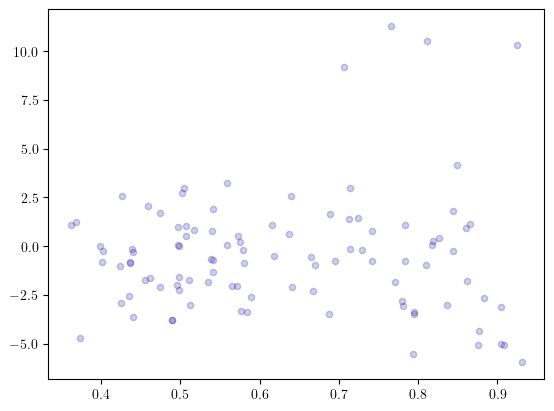

In [62]:
temp_nrv = 3
temp_df = comparison_df[comparison_df["n_rv"] == temp_nrv]
temp_df["mean_dvg"] = temp_df.groupby("NAME")["delta_vgamma"].transform("mean")
fig, ax = plt.subplots()
ax.scatter(
    temp_df["max_gap"],
    temp_df["delta_vgamma"],  # - temp_df["mean_dvg"],
    s=20,
    edgecolor="k",
    color="blue",
    zorder=2,
    alpha=0.2,
)

# ax.axhline(0, color="k", lw=0.8, ls="--")
# ax.set_xlabel(r"$\log_{10}(P)$")
# ax.set_ylabel(r"$\Delta v_\gamma$ [km/s]")
# print(temp_nrv, summary["mean"].mean(), summary["mean"].std())

In [ ]:
comparison_df[(comparison_df["n_rv"] == temp_nrv) & (comparison_df["max_gap"] < 0.5)]

,NAME,SET,log_P,n_rv,i_resample,delta_vgamma,delta_p2p,rmse,delta_vgamma_norm,delta_p2p_norm,rmse_norm,R,arc_gaps,max_gap,veloce_p2p
4,AK Cep,test,0.859295,3,4,-0.489688,-4.486694,1.167375,-0.013573,-0.124363,0.032358,0.269019,"[0.21379203238163313, 0.31921309010925825, 0.4...",0.466995,36.077361
6,AK Cep,test,0.859295,3,6,-0.113505,-1.337749,1.137777,-0.003146,-0.037080,0.031537,0.165286,"[0.2329989075182226, 0.371805020583011, 0.3951...",0.395196,36.077361
14,AK Cep,test,0.859295,3,14,-0.135654,1.964524,1.640780,-0.003760,0.054453,0.045479,0.308132,"[0.0907419250097945, 0.44347223575722694, 0.46...",0.465786,36.077361
15,AK Cep,test,0.859295,3,15,-0.544145,1.697786,1.981931,-0.015083,0.047060,0.054936,0.316142,"[0.48737837637770554, 0.38873311884808004, 0.1...",0.487378,36.077361
22,AK Cep,test,0.859295,3,22,-0.196753,-1.256880,1.000424,-0.005454,-0.034838,0.027730,0.329386,"[0.03875179164097631, 0.4719869980592364, 0.48...",0.489261,36.077361
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21765,l Car,train,1.550966,3,81,0.386876,-0.343505,1.408160,0.011354,-0.010081,0.041326,0.263479,"[0.35810190454034085, 0.1832970505801237, 0.45...",0.458601,34.074459
21767,l Car,train,1.550966,3,83,0.734809,-0.068194,0.827826,0.021565,-0.002001,0.024295,0.324016,"[0.13610125910578308, 0.4939324639520315, 0.36...",0.493932,34.074459
21772,l Car,train,1.550966,3,88,0.936802,3.687808,1.370873,0.027493,0.108228,0.040232,0.230009,"[0.41539097881031406, 0.40459824623203566, 0.1...",0.415391,34.074459
21777,l Car,train,1.550966,3,93,-0.252679,2.607896,2.011889,-0.007416,0.076535,0.059044,0.277812,"[0.29395246301678846, 0.2331818657682323, 0.47...",0.472866,34.074459


Nrv = 3: -0.420 +/- 3.066
	 -> cut 0.6 (52 / 100 = 0.52)  -> -0.689 +/- 1.912


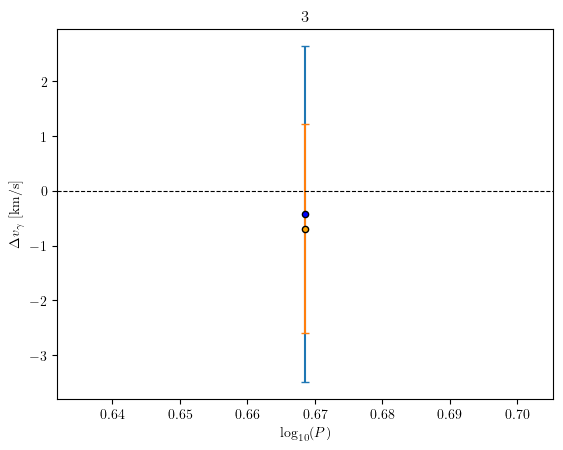

In [ ]:
# Mean and std of delta_vgamma per target (across all resamples), for a given n_rv
max_gap_allowed = 0.6
for temp_nrv in [3]:  # , 4, 5, 6, 7, 10, 15]:
    summary = (
        comparison_df[comparison_df["n_rv"] == temp_nrv]
        .groupby("NAME")["delta_vgamma"]
        .agg(mean="mean", std="std")
        .reset_index()
    )

    # Add log_P (one value per target, same across resamples)
    log_p_map = comparison_df.groupby("NAME")["log_P"].first()
    summary["log_P"] = summary["NAME"].map(log_p_map)

    summary_cut = (
        comparison_df[
            (comparison_df["n_rv"] == temp_nrv)
            & (comparison_df["max_gap"] < max_gap_allowed)
        ]
        .groupby("NAME")["delta_vgamma"]
        .agg(mean="mean", std="std")
        .reset_index()
    )
    summary_cut["log_P"] = summary_cut["NAME"].map(log_p_map)

    # Plot
    fig, ax = plt.subplots()
    ax.errorbar(
        summary["log_P"],
        summary["mean"],
        yerr=summary["std"],
        fmt=",",
        capsize=3,
        zorder=1,
    )
    ax.scatter(
        summary["log_P"],
        summary["mean"],
        s=20,
        edgecolor="k",
        color="blue",
        zorder=2,
    )

    ax.errorbar(
        summary_cut["log_P"],
        summary_cut["mean"],
        yerr=summary_cut["std"],
        fmt=",",
        capsize=3,
        zorder=1,
    )
    ax.scatter(
        summary_cut["log_P"],
        summary_cut["mean"],
        s=20,
        edgecolor="k",
        color="orange",
        zorder=2,
    )

    cut_len = len(
        comparison_df[
            (comparison_df["n_rv"] == temp_nrv)
            & (comparison_df["max_gap"] < max_gap_allowed)
        ]
    )
    uncut_len = len(comparison_df[comparison_df["n_rv"] == temp_nrv])

    ax.axhline(0, color="k", lw=0.8, ls="--")
    ax.set_xlabel(r"$\log_{10}(P)$")
    ax.set_ylabel(r"$\Delta v_\gamma$ [km/s]")
    ax.set_title(f"{temp_nrv}")
    print(
        f"Nrv = {temp_nrv}: {summary['mean'].mean():.3f} +/- {summary['std'].mean():.3f}"
    )
    print(
        f"\t -> cut {max_gap_allowed} ({cut_len} / {uncut_len} = {cut_len / uncut_len:.2f})  -> {summary_cut['mean'].mean():.3f} +/- {summary_cut['std'].mean():.3f}"
    )

3 -0.7797432119799821 4.92675589919891
4 -0.5377671371890894 3.561744298151957
5 -0.2644711022600284 2.7836230727695654
6 -0.08270658289015496 2.0890409240203494
7 0.1834420743546524 1.6613169995729162
10 0.35322980202220877 1.226804532656796
15 0.1472241468031524 0.9682528534112427


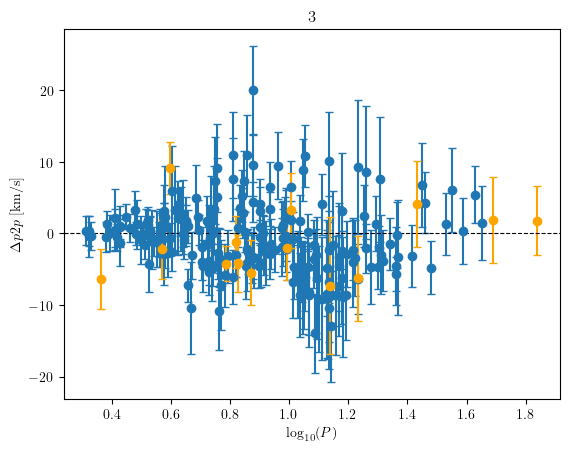

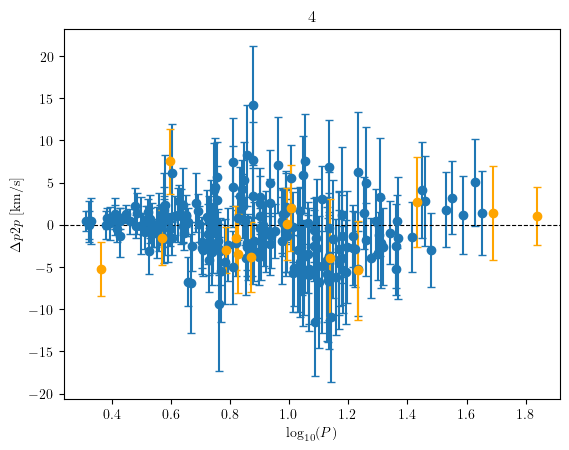

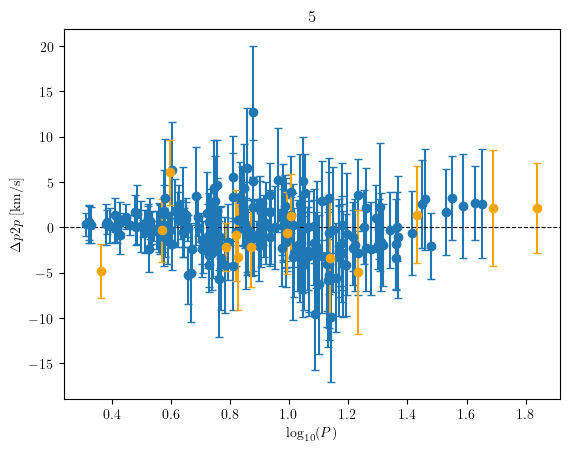

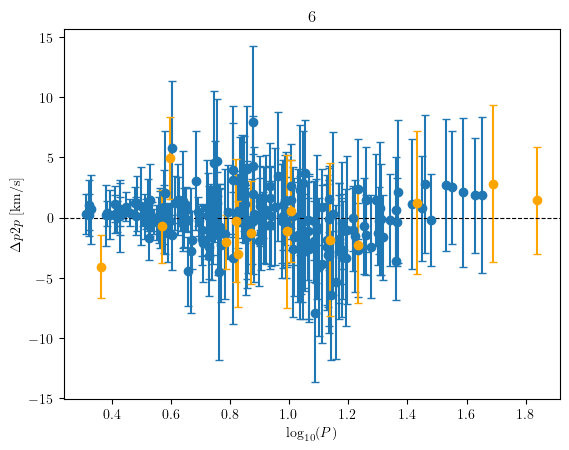

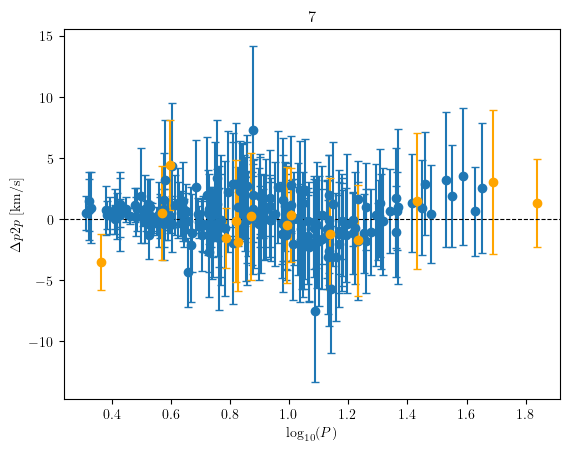

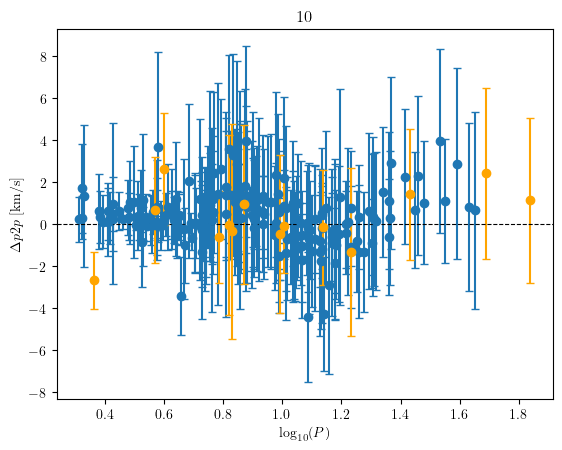

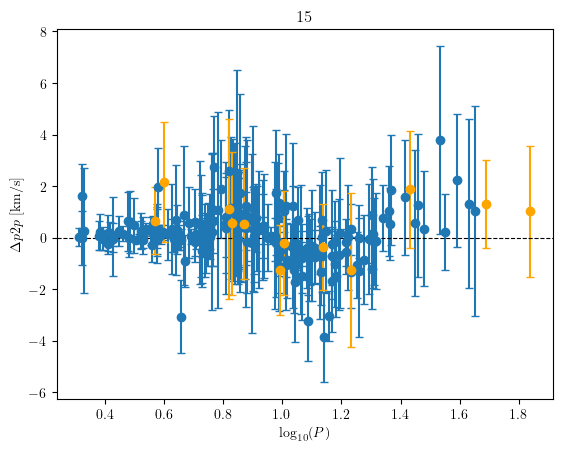

In [72]:
# Mean and std of delta_vgamma per target (across all resamples), for a given n_rv
for temp_nrv in [3, 4, 5, 6, 7, 10, 15]:
    summary = (
        comparison_df[comparison_df["n_rv"] == temp_nrv]
        .groupby("NAME")["delta_p2p"]
        .agg(mean="mean", std="std")
        .reset_index()
    )

    # Add log_P (one value per target, same across resamples)
    log_p_map = comparison_df.groupby("NAME")["log_P"].first()
    summary["log_P"] = summary["NAME"].map(log_p_map)
    summary["no_phi_prior"] = False

    for i, row in summary.iterrows():
        name = row.NAME
        header = veloce_headers[veloce_headers["NAME"] == name].iloc[0]
        source_id = int(header.GAIA_DR3_SOURCE_ID)
        if source_id not in df_gaiadr3_selection["source_id"].to_numpy():
            summary.loc[i, "no_phi_prior"] = True
        if row.log_P > kde_phot_phase.domain["log_P"][1]:
            summary.loc[i, "no_phi_prior"] = True

    # Plot
    fig, ax = plt.subplots()
    ax.errorbar(
        summary["log_P"][~summary.no_phi_prior],
        summary["mean"][~summary.no_phi_prior],
        yerr=summary["std"][~summary.no_phi_prior],
        fmt="o",
        capsize=3,
    )
    ax.errorbar(
        summary["log_P"][summary.no_phi_prior],
        summary["mean"][summary.no_phi_prior],
        yerr=summary["std"][summary.no_phi_prior],
        fmt="o",
        capsize=3,
        color="orange",
    )
    ax.axhline(0, color="k", lw=0.8, ls="--")
    ax.set_xlabel(r"$\log_{10}(P)$")
    ax.set_ylabel(r"$\Delta p2p$ [km/s]")
    ax.set_title(temp_nrv)
    print(temp_nrv, summary["mean"].mean(), summary["mean"].std())

testing


In [68]:
reading_n_rv = 3
example_target = "WW Mon"
n_rv_dir = subsampling_results_dir / f"n_rv{reading_n_rv:.0f}"

filename = list(n_rv_dir.glob(f"*{example_target.replace(' ', '_')}*.pkl"))[0]
with Path.open(filename, "rb") as f:
    example_subsample_target = pkl.load(f)


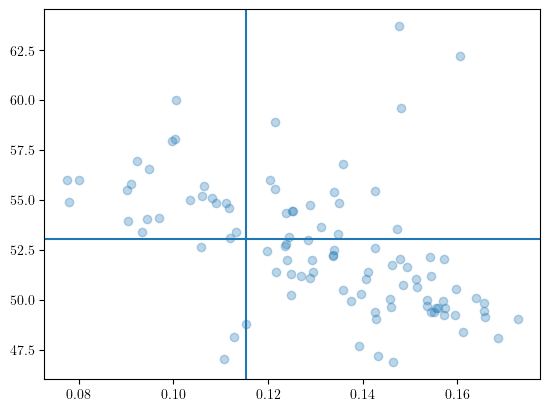

In [69]:
fig, axs = plt.subplots()
axs.scatter(
    [res.theta_free[-1] for res in example_subsample_target["result_map"]],
    [res.theta_free[0] for res in example_subsample_target["result_map"]],
    alpha=0.3,
)
example_veloce_vgamma = veloce_fit[veloce_fit["NAME"] == example_target]["VGAMMA"].iloc[
    0
]
axs.axhline(example_veloce_vgamma)
axs.axvline(example_subsample_target["real_delta_phi"])

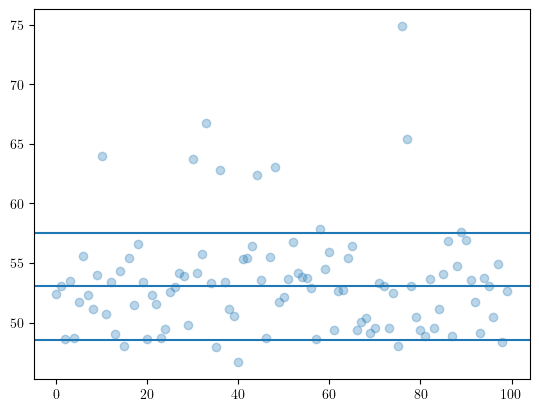

In [147]:
fig, axs = plt.subplots()
axs.scatter(
    np.arange(100),
    [res.theta_free[0] for res in example_subsample_target["result_map"]],
    alpha=0.3,
)
example_veloce_vgamma = veloce_fit[veloce_fit["NAME"] == example_target]["VGAMMA"].iloc[
    0
]
axs.axhline(example_veloce_vgamma)
axs.axhline(
    example_veloce_vgamma
    + np.std([res.theta_free[0] for res in example_subsample_target["result_map"]])
)
axs.axhline(
    example_veloce_vgamma
    - np.std([res.theta_free[0] for res in example_subsample_target["result_map"]])
)
# axs.axvline(example_subsample_target["real_delta_phi"])

In [148]:
[res.theta_free[0] for res in example_subsample_target["result_map"]][1]

np.float64(53.04815126089715)

real 0.12 -> 0.10


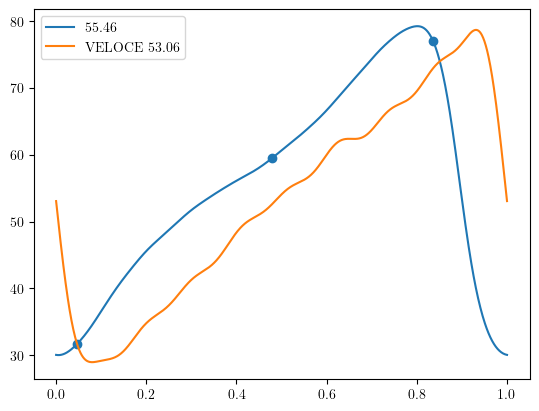

In [149]:
example_idx = 16
example_comb = example_subsample_target["selections"][example_idx]
example_rv = example_subsample_target["rv"][example_comb]
example_phase = example_subsample_target["phase"][example_comb]
# example_subsample_target["result_map"][]
example_map = example_subsample_target["result_map"][example_idx]
fig, axs = plt.subplots()
axs.scatter(example_phase, example_rv)
axs.plot(
    phase_grid,
    example_map.model(example_map.theta_free, x=phase_grid),
    label=f"{example_map.theta_free[0]:.2f}",
)

# Reconstruct the VELOCE fit curve for the current target.
example_veloce_puls = dataset[dataset["NAME"] == example_target].iloc[0]["SAMPLE"]
example_veloce_vgamma = veloce_fit[veloce_fit["NAME"] == example_target]["VGAMMA"].iloc[
    0
]
example_veloce_rv_curve = example_veloce_puls + example_veloce_vgamma

axs.plot(
    phase_grid, example_veloce_rv_curve, label=f"VELOCE {example_veloce_vgamma:.2f}"
)
axs.legend()
print(
    f"real {example_subsample_target['real_delta_phi']:.2f} -> {example_map.theta_free[-1]:.2f}"
)

real 0.12 -> 0.10


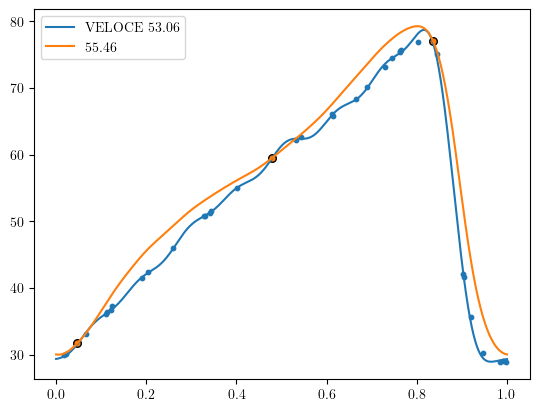

In [150]:
example_idx = 16
example_comb = example_subsample_target["selections"][example_idx]
example_rv = example_subsample_target["rv"]  # [example_comb]
example_phase = example_subsample_target["phase"]  # [example_comb]
# example_subsample_target["result_map"][]
example_map = example_subsample_target["result_map"][example_idx]
fig, axs = plt.subplots()
axs.scatter(example_phase, example_rv, marker="o", s=10)
axs.scatter(
    example_phase[example_comb],
    example_rv[example_comb],
    marker="o",
    s=30,
    edgecolors="k",
)


# Reconstruct the VELOCE fit curve for the current target.
example_veloce_puls = dataset[dataset["NAME"] == example_target].iloc[0]["SAMPLE"]
example_veloce_vgamma = veloce_fit[veloce_fit["NAME"] == example_target]["VGAMMA"].iloc[
    0
]
example_veloce_rv_curve = example_veloce_puls + example_veloce_vgamma


real_phases_grid = (phase_grid - (example_subsample_target["real_delta_phi"])) % 1
sortidx_phase = np.argsort(real_phases_grid)
sort_vel_model = example_veloce_rv_curve[sortidx_phase]
phased_veloce_model = np.interp(
    phase_grid, real_phases_grid[sortidx_phase], sort_vel_model
)
axs.plot(
    phase_grid,
    phased_veloce_model,
    label=f"VELOCE {example_veloce_vgamma:.2f}",
)
axs.plot(
    phase_grid,
    example_map.model(example_map.theta_free, x=phase_grid),
    label=f"{example_map.theta_free[0]:.2f}",
)


# axs.plot(
#     phase_grid, example_veloce_rv_curve, "
# )
# phase_sorted_idx = np.argsort((phase_grid + (example_subsample_target["real_delta_phi"]))%1)
# phase_sorted = ((phase_grid + (example_subsample_target["real_delta_phi"]))%1)[phase_sorted_idx]
# exvel_model = np.interp(phase_grid, phase_sorted, example_veloce_rv_curve[phase_sorted_idx])
# axs.plot(
#     ((phase_grid + (example_subsample_target["real_delta_phi"]))%1)[phase_sorted_idx],
#     exvel_model,
# )
# axs.plot(
#     phase_grid, example_veloce_rv_curve[phase_sorted_idx], label=f"VELOCE {example_veloce_vgamma:.2f}"
# )
axs.legend()
print(
    f"real {example_subsample_target['real_delta_phi']:.2f} -> {example_map.theta_free[-1]:.2f}"
)

In [152]:
phased_pca_model.param_names

['c', 'pc1', 'pc2', 'pc3', 'pc4', 'pc5', 'pc6', 'delta_phi']

In [154]:
kde_components

{'pc1': <velocefw.prior.density.KDEDensity at 0x1298e6900>,
 'pc2': <velocefw.prior.density.KDEDensity at 0x1298dfd90>,
 'pc3': <velocefw.prior.density.KDEDensity at 0x129928050>,
 'pc4': <velocefw.prior.density.KDEDensity at 0x1275d6650>,
 'pc5': <velocefw.prior.density.KDEDensity at 0x1275d6520>,
 'pc6': <velocefw.prior.density.KDEDensity at 0x1261727b0>}

In [ ]:
example_coeff = []
for res in example_subsample_target["result_map"]:
    example_coeff.append(
        {
            "log_P": example_subsample_target["log_P"],
            "c": res.theta_free[0],
            "pc1": res.theta_free[1],
            "pc2": res.theta_free[2],
            "pc3": res.theta_free[3],
            "pc4": res.theta_free[4],
            "pc5": res.theta_free[5],
            "pc6": res.theta_free[6],
            "DELTA_PHASE": res.theta_free[-1],
        }
    )
example_coeff = pd.DataFrame(example_coeff)

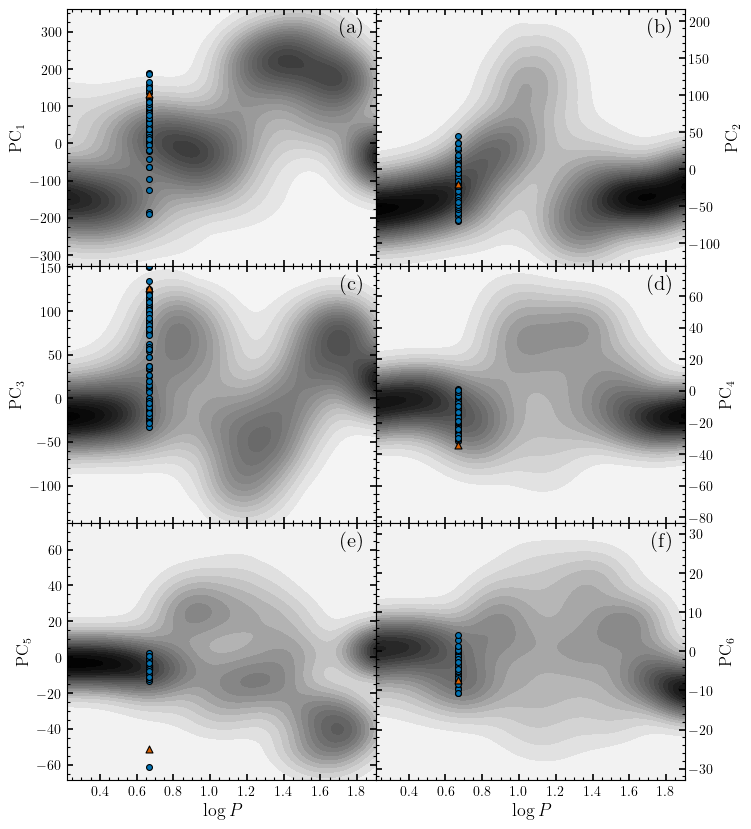

In [98]:
# Set the number of figures
n_rows = len(kde_components) // 2
n_rows += 1 if len(kde_components) % 2 == 1 else 0
fig, axs = plt.subplots(
    n_rows,
    2,
    sharex=True,
    gridspec_kw={"hspace": 0, "wspace": 0},
)
width = 3.46 * 2.2
height = width * 1.618 / 2 * n_rows / 2.2  # / 2
fig.set_size_inches(width, height)
x_ticks = np.arange(0.2, 2, 0.2)
x_ticks_minor = np.arange(0.2, 2, 0.05)
xlims = [0.22, 1.9]

# Color
panels = ["a", "b", "c", "d", "e", "f"]
kde_names = [f"pc{i}" for i in range(1, len(kde_components) + 1)]
scatter_kw = {"c": color_safe["blue"]}
test_scatter_kw = {"c": color_safe["dark_orange"]}

for i, kde_name in enumerate(kde_names):
    ax = axs.flat[i]
    ax.text(
        0.97,
        0.97,
        f"({panels[i]})",
        transform=ax.transAxes,
        fontsize=label_size + 4,
        ha="right",
        va="top",
    )

    kde = kde_components[kde_name]

    ax = plot_2d_kde(
        kde,
        example_coeff,
        ax=ax,
        n_grid=300,
        cmap="Greys",
        scatter_kw=scatter_kw,
        test_data=components_df[components_df["NAME"] == example_target],
        test_scatter_kw=test_scatter_kw,
    )

    # Set x-axis ticks and label
    vf.plots_utils.format_xticks(ax, x_ticks, x_ticks_minor)
    ax.set_xlim(*xlims)

    # Set y-axis ticks and labels
    if i % 2 == 1:
        ax.yaxis.set_label_position("right")
        ax.yaxis.tick_right()

    ylims = ax.get_ylim()
    if i == 0:
        y_ticks = np.arange(-500, 500, 100)
        y_ticks_minor = np.arange(-500, 500, 25)
    elif i in {1, 2}:
        y_ticks = np.arange(-200, 400, 50)
        y_ticks_minor = np.arange(-200, 400, 10)
    elif i in {3, 4}:
        y_ticks = np.arange(-200, 200, 20)
        y_ticks_minor = np.arange(-200, 200, 5)
    elif i == 5:  # noqa: PLR2004
        y_ticks = np.arange(-100, 100, 10)
        y_ticks_minor = np.arange(-100, 100, 2)
        ylim = (ylim[0], ylim[1] + 3)
    else:
        pass

    vf.plots_utils.format_yticks(ax, y_ticks, y_ticks_minor)
    ax.set_ylim(*ylims)
    ax.set_ylabel(r"$\rm{PC_" + str(i + 1) + "}$", fontsize=12)

if len(kde_components) % 2 == 1:
    fig.delaxes(axs[-1, -1])

axs[-1, -1].set_xlabel(r"$\log P$", fontsize=13)
axs[2, 0].set_xlabel(r"$\log P$", fontsize=13)
fig.tight_layout()
# fig.savefig(saving_directory / "kde_components.pdf", format="pdf")

In [71]:
alfumi_phases = []
for r in subsample_n_rv["GS Lup"]["result_map"]:
    alfumi_phases.append(r.theta_free[-1])

In [ ]:
fig, axs = plt.subplots()
axs.scatter(np.arange(100), alfumi)

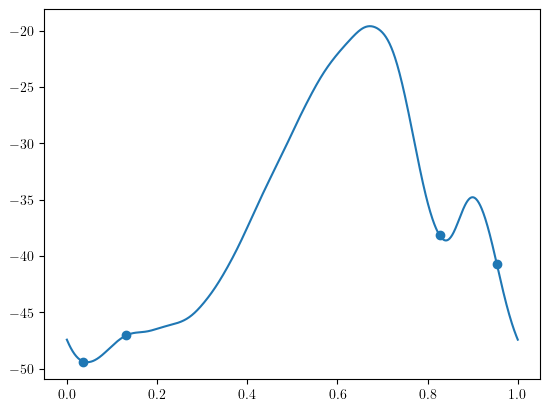

In [130]:
yyy = phased_pca_model.evaluate(
    subsample_results["result_map"][1].theta_free, phase_grid
)
fig, axs = plt.subplots()
axs.plot(phase_grid, yyy)
combb = subsample_results["selections"][1]
axs.scatter(subsample_results["phase"][combb], subsample_results["rv"][combb])

In [65]:
pc_delta_starts.shape

(300, 8)

In [ ]:
N_STARTS = 500

# Sample starting points from the prior
starts = np.empty((N_STARTS, phased_pca_model.n_params))
# starts[:, 0] = rng_init.uniform(temp_mean_rv - 35, temp_mean_rv + 35, N_STARTS)  # c
starts[:, 0] = np.zeros(N_STARTS)
for col_idx, prior in enumerate(priors):
    spline = prior._density  # the SplineDensity  # noqa: SLF001
    param_idx = col_idx + 1  # offset by 1 for c
    starts[:, param_idx] = sample_from_spline(spline, N_STARTS, rng_init)
if log_p > kde_phot_phase.domain["log_P"][1]:
    starts[:, -1] = rng_init.uniform(0, 1, N_STARTS)

lp_vals = np.array([log_prior_target(s) for s in starts])
starts[:, 0] = rng_init.uniform(temp_mean_rv - 35, temp_mean_rv + 35, N_STARTS)  # c
lp_vals2 = np.array([log_prior_target(s) for s in starts])

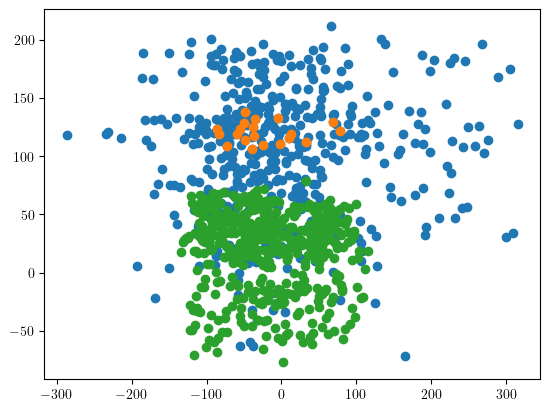

In [93]:
fig, axs = plt.subplots()
axs.scatter(starts[:, 1], starts[:, 2])
top_k = starts[np.argsort(lp_vals)[-20:]]
axs.scatter(top_k[:, 1], top_k[:, 2])
axs.scatter(pc_delta_starts[:, 2], pc_delta_starts[:, 3])

In [ ]:
# Compute once per star (outside the resample loop):

has_phase_prior = True  # bool you already track
pc_priors = priors[:-1] if has_phase_prior else priors
icdf_pc = [build_icdf(p._density) for p in pc_priors]
icdf_phase = build_icdf(priors[-1]._density) if has_phase_prior else None

N = 100
n_prior_dims = len(icdf_pc) + (1 if has_phase_prior else 0)
lhs_u = sp.stats.qmc.LatinHypercube(d=n_prior_dims, seed=42).random(
    N
)  # (N, n_prior_dims)

# Map each LHS column through its prior's inverse CDF
pc_cols = [icdf_sample(cdf, g, lhs_u[:, k]) for k, (cdf, g) in enumerate(icdf_pc)]

if has_phase_prior:
    dphi_col = icdf_sample(*icdf_phase, lhs_u[:, -1])
    pc_delta_starts = np.column_stack(pc_cols + [dphi_col])  # (N, n_pcs+1)
else:
    # delta_phi is flat: use a separate grid crossed with the PC starts
    phi_grid = np.linspace(0.0, 1.0, 8, endpoint=False)
    pc_starts = np.column_stack(pc_cols)  # (N, n_pcs)
    pc_rep = np.repeat(pc_starts, len(phi_grid), axis=0)  # (N*8, n_pcs)
    phi_rep = np.tile(phi_grid, N)  # (N*8,)
    pc_delta_starts = np.column_stack([pc_rep, phi_rep])  # (N*8, n_pcs+1)


bounds = [[temp_mean_rv - 35, temp_mean_rv + 35]] + static_bounds_suffix
t0 = time.perf_counter()
result_de = vf.fit.differential_evolution_posterior(
    compiled_model=phased_pca_model,
    bounds=bounds,
    x=temp_phase,
    y=temp_rv,
    yerr=temp_rv_err,
    logprior=log_prior_target,
    **kwargs_de,
)


components_df[components_df["NAME"] == example_target]
t1 = time.perf_counter()
if not result_de.success:
    break_cases.append([name, n_rv, i_resample, combination])
    break

result_map = vf.fit.fit_map(
    compiled_model=phased_pca_model,
    x=temp_phase,
    y=temp_rv,
    yerr=temp_rv_err,
    theta_free_init=result_de.theta_free,
    logprior=log_prior_target,
    **kwargs_map,
)
t2 = time.perf_counter()

if not result_map.success:
    break_cases.append([name, n_rv, i_resample, combination])
    break

print(
    f"[{i_resample}] DE: {t1 - t0:.1f}s  nfev={result_de.optimizer_result.nfev}"
    f"  MAP: {t2 - t1:.1f}s  success={result_map.success}"
    f" log_post = {result_map.extra["logposterior"]:.2f}"
    f" chi2 = {result_map.chi2:.2f}",
)

results_de.append(result_de)

In [97]:
np.zeros(500)

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0.

In [101]:
np.column_stack((np.zeros(500), pc_delta_starts))[:, 0]

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0.

Z Lac 0 [16 54 12] 5
[0] DE: 7.1s  nfev=159520  MAP: 0.0s  success=True log_post = -19.39 chi2 = 0.02
[0]  MAP with grid: 2.3s  success=True log_post = -21.24 chi2 = 0.00
Z Lac 1 [46  4 31] 5
[1] DE: 5.0s  nfev=114800  MAP: 0.0s  success=True log_post = -21.67 chi2 = 0.04
[1]  MAP with grid: 0.9s  success=True log_post = -20.72 chi2 = 0.00
Z Lac 2 [24 32 16] 5
[2] DE: 7.2s  nfev=164640  MAP: 0.0s  success=True log_post = -22.83 chi2 = 0.00
[2]  MAP with grid: 1.1s  success=True log_post = -20.59 chi2 = 0.01
Z Lac 3 [ 6 40 50] 5
[3] DE: 6.6s  nfev=153920  MAP: 0.0s  success=True log_post = -20.88 chi2 = 0.01

In [74]:
fit_rv_df[fit_rv_df["NAME"] == name]["LS_RESULT"].iloc[0].model

CompiledModel(model=<velocefw.model.base.BinaryOp object at 0x12850c1a0>, layout=Layout(ndim=7, params_meta=[ParamMeta(node=0, model_name='v_gamma', model_counter=0, local_name='c', local_index=0, index=0, global_name='c'), ParamMeta(node=1, model_name='pca_puls', model_counter=0, local_name='pc1', local_index=0, index=1, global_name='pc1'), ParamMeta(node=1, model_name='pca_puls', model_counter=0, local_name='pc2', local_index=1, index=2, global_name='pc2'), ParamMeta(node=1, model_name='pca_puls', model_counter=0, local_name='pc3', local_index=2, index=3, global_name='pc3'), ParamMeta(node=1, model_name='pca_puls', model_counter=0, local_name='pc4', local_index=3, index=4, global_name='pc4'), ParamMeta(node=1, model_name='pca_puls', model_counter=0, local_name='pc5', local_index=4, index=5, global_name='pc5'), ParamMeta(node=1, model_name='pca_puls', model_counter=0, local_name='pc6', local_index=5, index=6, global_name='pc6')], name_to_index={'c': 0, 'pc1': 1, 'pc2': 2, 'pc3': 3, 'p

In [66]:
priors

In [67]:
fit_rv_df

,NAME,SET,LS_RESULT,CHI2,NORM_CHI2,RMSE,VGAMMA,VGAMMA_ERR,P2P,P2P_ERR,...,P2P_DELTA_RATIO,P2P_DELTA_RATIO_ERR,VGAMMA_DELTA,VGAMMA_DELTA_ERR,VGAMMA_DELTA_RATIO,VGAMMA_DELTA_RATIO_ERR,P,RMSE_SCALED,RMSE_VELOCE_SCALED,OUTLIER
0,AA Gem,train,"SuccessfulFitResult(method='least_squares', mo...",1.526470e+03,25.024105,0.253456,19.631759,0.005970,38.853518,0.023986,...,-0.025740,0.000601,0.023631,0.005970,0.000593,0.000150,11.303705,0.006355,0.008296,False
1,AB Cam,train,"SuccessfulFitResult(method='least_squares', mo...",1.805714e+03,85.986400,0.707429,-43.930020,0.020098,46.071180,0.118192,...,-0.024002,0.002504,0.050447,0.020098,0.001069,0.000426,5.787585,0.014987,0.012066,False
2,AC Mon,train,"SuccessfulFitResult(method='least_squares', mo...",1.247152e+04,230.954133,0.626494,60.514022,0.005638,38.853489,0.026887,...,0.001011,0.000693,0.019783,0.005638,0.000510,0.000145,8.014995,0.016141,0.013375,False
3,AD Pup,train,"SuccessfulFitResult(method='least_squares', mo...",3.439389e+04,291.473682,0.790436,72.886533,0.003971,53.364994,0.016263,...,0.017846,0.000310,-0.021938,0.003971,-0.000418,0.000076,13.597599,0.015076,0.013148,False
4,AH Vel,train,"SuccessfulFitResult(method='least_squares', mo...",2.563221e+04,406.860504,0.206364,26.821018,0.001412,16.802237,0.005520,...,-0.002967,0.000328,0.006427,0.001412,0.000381,0.000084,4.227158,0.012245,0.006877,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
214,bet Dor,train,"SuccessfulFitResult(method='least_squares', mo...",3.617771e+06,12140.170108,0.478872,8.372870,0.000280,32.217576,0.001057,...,-0.037009,0.000032,0.004098,0.000280,0.000122,0.000008,9.842732,0.014314,0.013559,False
215,del Cep,train,"SuccessfulFitResult(method='least_squares', mo...",4.850282e+03,17.138805,0.201146,-16.984034,0.003289,38.056723,0.022949,...,-0.001230,0.000602,-0.017970,0.003289,-0.000472,0.000086,5.366267,0.005279,0.004670,False
216,eta Aql,train,"SuccessfulFitResult(method='least_squares', mo...",2.817213e+05,5869.193738,0.962999,-14.484932,0.001027,40.009956,0.003863,...,-0.000057,0.000097,0.301985,0.001027,0.007547,0.000026,7.176834,0.024068,0.023592,False
217,l Car,train,"SuccessfulFitResult(method='least_squares', mo...",1.222754e+07,13261.971524,0.503493,3.435148,0.000128,34.412566,0.000501,...,0.009923,0.000015,0.011877,0.000128,0.000349,0.000004,35.560325,0.014776,0.011636,False


In [73]:
fit_rv_df[fit_rv_df.NAME == "Z Lac"]["LS_RESULT"].iloc[0].chi2

5661.742659442348

In [68]:
result_map

NameError: name 'result_map' is not defined

In [69]:
result_de.chi2

5478.067507965644

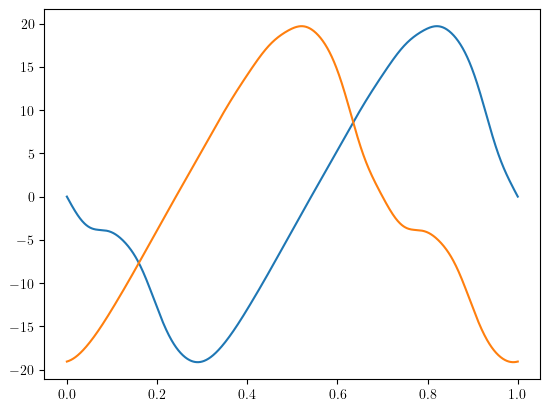

In [70]:
pexample = fit_rv_train_df.iloc[0].LS_RESULT.theta_free
ex1 = phased_model.evaluate_local(pexample.tolist()[1:] + [0], phase_grid)
ex2 = phased_model.evaluate_local(pexample.tolist()[1:] + [0.3], phase_grid)
fig, axs = plt.subplots()
axs.plot(phase_grid, ex1)
axs.plot(phase_grid, ex2)

In [58]:
pca_model.param_names

['c', 'pc1', 'pc2', 'pc3', 'pc4', 'pc5', 'pc6']

In [55]:
pca_model.layout.name_to_index

{'c': 0, 'pc1': 1, 'pc2': 2, 'pc3': 3, 'pc4': 4, 'pc5': 5, 'pc6': 6}

In [43]:
photometric_delta_phase

,NAME,P,DELTA_PHASE,BAND
0,AA Gem,11.303705,0.301142,G
1,AA Gem,11.303705,0.296561,BP
2,AA Gem,11.303705,0.336461,RP
3,AB Cam,5.787585,0.106349,G
4,AB Cam,5.787585,0.101536,BP
...,...,...,...,...
487,eta Aql,7.176834,0.153145,BP
488,eta Aql,7.176834,0.279598,RP
489,l Car,35.560325,0.130209,G
490,l Car,35.560325,0.132678,BP


# REST OF THE ANALYSIS TO BE DONE

In [42]:
fit_curve_df

,NAME,SET,LS_RESULT,CHI2,NORM_CHI2,RMSE,VGAMMA,VGAMMA_ERR,VGAMMA_ERR_RESCALED,P2P,P2P_ERR
0,AA Gem,train,"SuccessfulFitResult(method='least_squares', mo...",83.277293,0.083864,0.288578,19.608128,0.031623,0.009158,39.149962,0.124958
1,AB Cam,train,"SuccessfulFitResult(method='least_squares', mo...",262.289773,0.264139,0.512142,-43.980467,0.031623,0.016252,46.165398,0.128667
2,AC Mon,train,"SuccessfulFitResult(method='least_squares', mo...",198.071473,0.199468,0.445052,60.494239,0.031623,0.014123,38.680997,0.126628
3,AD Pup,train,"SuccessfulFitResult(method='least_squares', mo...",396.181088,0.398974,0.629429,72.908471,0.031623,0.019974,52.895839,0.141290
4,AH Vel,train,"SuccessfulFitResult(method='least_squares', mo...",12.370216,0.012457,0.111221,26.814592,0.031623,0.003530,16.784559,0.112568
...,...,...,...,...,...,...,...,...,...,...,...
214,bet Dor,train,"SuccessfulFitResult(method='least_squares', mo...",203.121501,0.204553,0.450690,8.368772,0.031623,0.014302,32.259667,0.093511
215,del Cep,train,"SuccessfulFitResult(method='least_squares', mo...",28.690659,0.028893,0.169383,-16.966065,0.031623,0.005375,38.160194,0.147726
216,eta Aql,train,"SuccessfulFitResult(method='least_squares', mo...",452.500567,0.455690,0.672682,-14.786917,0.031623,0.021347,40.374737,0.150454
217,l Car,train,"SuccessfulFitResult(method='least_squares', mo...",151.749698,0.152819,0.389551,3.423271,0.031623,0.012362,34.321439,0.125685


In [43]:
fit_rv_df

,NAME,SET,LS_RESULT,CHI2,NORM_CHI2,RMSE,VGAMMA,VGAMMA_ERR,P2P,P2P_ERR,...,P2P_DELTA_RATIO,P2P_DELTA_RATIO_ERR,VGAMMA_DELTA,VGAMMA_DELTA_ERR,VGAMMA_DELTA_RATIO,VGAMMA_DELTA_RATIO_ERR,P,RMSE_SCALED,RMSE_VELOCE_SCALED,OUTLIER
0,AA Gem,train,"SuccessfulFitResult(method='least_squares', mo...",1.526470e+03,25.024105,0.253456,19.631759,0.005970,38.853518,0.023986,...,-0.025740,0.000601,0.023631,0.005970,0.000593,0.000150,11.303705,0.006355,0.008296,False
1,AB Cam,train,"SuccessfulFitResult(method='least_squares', mo...",1.805714e+03,85.986400,0.707429,-43.930020,0.020098,46.071180,0.118192,...,-0.024002,0.002504,0.050447,0.020098,0.001069,0.000426,5.787585,0.014987,0.012066,False
2,AC Mon,train,"SuccessfulFitResult(method='least_squares', mo...",1.247152e+04,230.954133,0.626494,60.514022,0.005638,38.853489,0.026887,...,0.001011,0.000693,0.019783,0.005638,0.000510,0.000145,8.014995,0.016141,0.013375,False
3,AD Pup,train,"SuccessfulFitResult(method='least_squares', mo...",3.439389e+04,291.473682,0.790436,72.886533,0.003971,53.364994,0.016263,...,0.017846,0.000310,-0.021938,0.003971,-0.000418,0.000076,13.597599,0.015076,0.013148,False
4,AH Vel,train,"SuccessfulFitResult(method='least_squares', mo...",2.563221e+04,406.860504,0.206364,26.821018,0.001412,16.802237,0.005520,...,-0.002967,0.000328,0.006427,0.001412,0.000381,0.000084,4.227158,0.012245,0.006877,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
214,bet Dor,train,"SuccessfulFitResult(method='least_squares', mo...",3.617771e+06,12140.170108,0.478872,8.372870,0.000280,32.217576,0.001057,...,-0.037009,0.000032,0.004098,0.000280,0.000122,0.000008,9.842732,0.014314,0.013559,False
215,del Cep,train,"SuccessfulFitResult(method='least_squares', mo...",4.850282e+03,17.138805,0.201146,-16.984034,0.003289,38.056723,0.022949,...,-0.001230,0.000602,-0.017970,0.003289,-0.000472,0.000086,5.366267,0.005279,0.004670,False
216,eta Aql,train,"SuccessfulFitResult(method='least_squares', mo...",2.817213e+05,5869.193738,0.962999,-14.484932,0.001027,40.009956,0.003863,...,-0.000057,0.000097,0.301985,0.001027,0.007547,0.000026,7.176834,0.024068,0.023592,False
217,l Car,train,"SuccessfulFitResult(method='least_squares', mo...",1.222754e+07,13261.971524,0.503493,3.435148,0.000128,34.412566,0.000501,...,0.009923,0.000015,0.011877,0.000128,0.000349,0.000004,35.560325,0.014776,0.011636,False
